# Audits des sources — Compagnon Immobilier

**Projet :** Compagnon Immobilier · 

Ce notebook rassemble les audits de toutes les sources de données de l'équipe : une partie par source, dans l'ordre de la préparation. Chaque audit décrit la source telle qu'elle est livrée (origine, structure, variables, qualité) et justifie les choix faits ensuite dans `01_preparation`.

1. DVF+
2. Bassins de vie et table de passage des communes
3. Filosofi
4. Ménages (recensement 2022)
5. Parc de logement (recensement 2022)
6. Délinquance enregistrée
7. LOVAC
8. Équipements et sources complémentaires
9. Taux des crédits immobiliers
10. Annonces de vente (Haut-Rhin)
11. Annonces de location (Haut-Rhin)
12. Emploi salarié privé (Urssaf)

### Avant de lancer

- **Sources brutes** (`00_telechargement`) : `bassins_vie`, `passage_geo`, `menages`, `logement`, `delinquance`, `lovac`, `taux`, `bpe`, `bpe_evolution`, `emploi`. Pour DVF+, l'échantillon d'audit se construit à partir de DVF+ brut (`dvf`), sauf s'il est déjà présent.
- **Fichiers préparés** (`01_preparation`) : l'audit de Filosofi porte sur la base assemblée par le bloc 5 ; deux contrôles utilisent la population DVF+ filtrée (bloc 2) et la table de liaison (bloc 1).
- **Millésimes du recensement 2016 à 2021** (partie 5) : bases IRIS « Logement » de l'Insee, dans `data/raw/logement_millesimes/`.
- **Annonces** : les fichiers `ech_annonces_ventes_68.csv` et `ech_annonces_locations_68.csv` doivent être dans `data/raw/`.



In [18]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# config.py se trouve à la racine du projet, dossier parent de ce notebook
sys.path.insert(0, str(Path.cwd().parent))
from config import DATA_RAW, DATA_OUT

pd.set_option("display.max_columns", None)

# 1. DVF+

**Contributeurs :** Cécile NAUDET · **Date :** octobre 2026

## Chargement par échantillonnage

DVF+ est livré en 97 fichiers départementaux (16,5 millions de mutations). L'audit porte sur un échantillon de 100 000 mutations, tiré proportionnellement au poids de chaque département.

Deux façons d'obtenir l'échantillon :
- **le parcours rapide** : le télécharger depuis le Drive (`python 00_telechargement/telechargement.py dvf_audit`) ;
- **le parcours complet** : le tirer à partir de DVF+ brut avec les deux cellules suivantes.

Comme pour le filtrage de la préparation, les deux cellules vérifient d'abord si le fichier existe déjà dans `data/processed/` : si oui, le tirage n'est pas refait.

In [19]:
chemin_audit = DATA_OUT / "dvf_plus_echantillon_100k.csv"
deja_present = chemin_audit.exists()
if deja_present:
    print("Échantillon d'audit déjà présent :", chemin_audit.name, "-> le tirage n'est pas refait")

Échantillon d'audit déjà présent : dvf_plus_echantillon_100k.csv -> le tirage n'est pas refait


In [20]:
if not deja_present:
    #Effectis et quotas proportionnels pour les fichiers DVF+ (sans charger les CSV en mémoire)
    from pathlib import Path
    import pandas as pd
    import numpy as np

    dossier = DATA_RAW / "DVF+"
    fichiers = sorted(dossier.glob("dvf_plus_d*.csv"))

    # Compter les lignes sans charger les CSV en mémoire
    effectifs = {}

    for fichier in fichiers:
        with open(fichier, "rb") as f:
            effectifs[fichier.name] = sum(1 for _ in f) - 1

    repartition = pd.DataFrame.from_dict(
        effectifs,
        orient="index",
        columns=["Effectif"]
    )

    total = repartition["Effectif"].sum()
    objectif = 100_000

    # Calculer les proportions
    repartition["Proportion (%)"] = (
        repartition["Effectif"] / total * 100
    ).round(3)

    # Calculer les quotas et ajuster les arrondis
    quotas_exacts = repartition["Effectif"] / total * objectif

    repartition["Quota"] = np.floor(quotas_exacts).astype(int)

    reste = objectif - repartition["Quota"].sum()

    indices = (
        (quotas_exacts - repartition["Quota"])
        .sort_values(ascending=False)
        .head(reste)
        .index
    )

    repartition.loc[indices, "Quota"] += 1

    display(repartition.sort_values("Effectif", ascending=False))

    print("Total des lignes sources :", total)
    print("Total des quotas :", repartition["Quota"].sum())

In [21]:
if not deja_present:
    sortie = chemin_audit
    rng = np.random.default_rng(42)

    premier_bloc = True
    total_extrait = 0
    colonnes_reference = None

    for fichier in fichiers:
        n_total = int(repartition.loc[fichier.name, "Effectif"])
        quota = int(repartition.loc[fichier.name, "Quota"])

        # Tirer les positions aléatoires sans remise
        positions = np.sort(
            rng.choice(n_total, size=quota, replace=False)
        )

        debut = 0

        for bloc in pd.read_csv(
            fichier,
            sep="|",
            chunksize=10_000,
            low_memory=False
        ):
            # Vérifier que les colonnes sont identiques
            if colonnes_reference is None:
                colonnes_reference = bloc.columns.tolist()
            elif bloc.columns.tolist() != colonnes_reference:
                raise ValueError(
                    f"Colonnes différentes dans {fichier.name}"
                )

            fin = debut + len(bloc)

            indices = positions[
                (positions >= debut) & (positions < fin)
            ] - debut

            if len(indices) > 0:
                extrait = bloc.iloc[indices].copy()

                extrait["departement_source"] = (
                    fichier.stem.removeprefix("dvf_plus_d")
                )

                extrait.to_csv(
                    sortie,
                    mode="w" if premier_bloc else "a",
                    header=premier_bloc,
                    index=False,
                    sep="|"
                )

                premier_bloc = False
                total_extrait += len(extrait)

            debut = fin

        if debut != n_total:
            raise ValueError(
                f"Nombre de lignes incohérent dans {fichier.name}"
            )

        print(f"{fichier.name} : {quota} lignes extraites")

    print("\nTotal extrait :", total_extrait)
    print("Fichier créé :", sortie)

In [22]:
df = pd.read_csv(DATA_OUT / "dvf_plus_echantillon_100k.csv", sep="|", low_memory=False)

## A. Identité

### 1. Source et origine

**Objectif :** savoir d'où vient la donnée et comment elle est produite, pour juger sa fiabilité.

**Constat :**

Les données DVF (Demandes de valeurs foncières) sont produites par la Direction générale des Finances publiques (DGFiP) à partir de sources fiscales, notamment FIDJI et MAJIC.
Le modèle DVF+, développé par le Cerema, restructure ces données en plusieurs tables et ajoute des variables calculées ou agrégées pour faciliter leur exploitation. La table mutation correspond aux mutations immobilières.
Les données DVF sont d'origine administrative, et non issues d'annonces immobilières ou de scraping. 

**Documentation** : guide Cerema De DVF à DV3F, dont la dernière mise à jour de fond est indiquée comme juin 2021. Le PDF a été généré le 10 octobre 2026. Une documentation technique en ligne existe et peut évoluer indépendamment de ce PDF. 
 

**Impact projet :**
DVF+ constitue une source pertinente pour étudier les transactions immobilières effectivement enregistrées. Elle ne décrit cependant pas l'intégralité du marché : certaines mutations sont exclues, et les caractéristiques des biens restent limitées, notamment si nous utilisons uniquement la table mutation. 

**Points de vigiliances :**
Le document distingue trois modèles : DVF brut, DVF+ et DV3F. Nous travaillons sur DVF+ et non sur DV3F qui n'est pas en opensource.

### 2. Dimensions, unité d'observations

**Objectif :** connaître le volume (effectifs, mémoire, temps de calcul), savoir ce que représente une ligne.

In [23]:
print(df.shape)
print(df.info())
display(df.head())

(100000, 64)
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 64 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   idmutation          100000 non-null  int64  
 1   idmutinvar          100000 non-null  str    
 2   idopendata          100000 non-null  str    
 3   idnatmut            100000 non-null  int64  
 4   codservch           0 non-null       float64
 5   refdoc              0 non-null       float64
 6   datemut             100000 non-null  str    
 7   anneemut            100000 non-null  int64  
 8   moismut             100000 non-null  int64  
 9   coddep              100000 non-null  str    
 10  libnatmut           100000 non-null  str    
 11  nbartcgi            100000 non-null  int64  
 12  l_artcgi            0 non-null       float64
 13  vefa                100000 non-null  bool   
 14  valeurfonc          99810 non-null   float64
 15  nbdispo             100000 non-nu

,idmutation,idmutinvar,idopendata,idnatmut,codservch,refdoc,datemut,anneemut,moismut,coddep,libnatmut,nbartcgi,l_artcgi,vefa,valeurfonc,nbdispo,nblot,nbcomm,l_codinsee,nbsection,l_section,nbpar,l_idpar,nbparmut,l_idparmut,nbsuf,sterr,l_dcnt,nbvolmut,nblocmut,l_idlocmut,nblocmai,nblocapt,nblocdep,nblocact,nbapt1pp,nbapt2pp,nbapt3pp,nbapt4pp,nbapt5pp,nbmai1pp,nbmai2pp,nbmai3pp,nbmai4pp,nbmai5pp,sbati,sbatmai,sbatapt,sbatact,sapt1pp,sapt2pp,sapt3pp,sapt4pp,sapt5pp,smai1pp,smai2pp,smai3pp,smai4pp,smai5pp,codtypbien,libtypbien,geompar_x,geompar_y,departement_source
0,64165,4a4f7722c4faa20d42bdbcb4eecfbd09,4a4f7722c4faa20d42bdbcb4eecfbd09,1,NaN,NaN,2014-08-13,2014,8,1,Vente,0,NaN,False,70000.0,1,3.0,1,01093,1,0C,1,010930000C1713,0,NaN,0,0.0,"0,0,0,0,0,0,0,0,0,0,0,0,0",0,2,"010930000025060_0,010930000025061_0",0,1,1,0,0,1,0,0,0,0,0,0,0,0,57.0,0.0,57.0,0.0,0.0,57.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,121,UN APPARTEMENT,851462.366122,6.559607e+06,01
1,80412,46e7aad1fdf644f37c2c4fdca2db2099,46e7aad1fdf644f37c2c4fdca2db2099,1,NaN,NaN,2014-07-24,2014,7,1,Vente,0,NaN,False,175833.0,1,3.0,1,01053,1,AC,1,01053000AC0528,0,NaN,0,0.0,"0,0,0,0,0,0,0,0,0,0,0,0,0",0,2,"010530000003995_0,010530000003996_0",0,1,1,0,0,0,1,0,0,0,0,0,0,0,68.0,0.0,68.0,0.0,0.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,121,UN APPARTEMENT,871670.083169,6.570332e+06,01
2,85035,4c577daa8d735d583c62b975f4a5aab9,4c577daa8d735d583c62b975f4a5aab9,1,NaN,NaN,2014-12-17,2014,12,1,Vente,0,NaN,False,170000.0,1,0.0,1,01202,1,0I,2,"012020000I0090,012020000I0091",2,"012020000I0090,012020000I0091",4,1813.0,"583.0000000000000000,0.0000000000000000,0.0000...",0,1,012020000020539_0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,88.0,88.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,88.0,111,UNE MAISON,881714.192722,6.537775e+06,01
3,93068,3a368a3c7a63b6a8b390e1923c72d4e9,3a368a3c7a63b6a8b390e1923c72d4e9,1,NaN,NaN,2014-10-17,2014,10,1,Vente,0,NaN,False,156000.0,1,0.0,1,01351,1,0A,5,"013510000A0799,013510000A0800,013510000A0801,0...",5,"013510000A0799,013510000A0800,013510000A0801,0...",5,25860.0,"3458.0000000000000000,19962.0000000000000000,0...",0,2,"013510000026163_0,013510000026164_0",2,0,0,0,0,0,0,0,0,2,0,0,0,0,120.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,120.0,0.0,0.0,0.0,0.0,112,DES MAISONS,843659.837524,6.563588e+06,01
4,87405,3f6174680abd4a87de18944ab1952f05,3f6174680abd4a87de18944ab1952f05,6,NaN,NaN,2014-11-04,2014,11,1,Echange,0,NaN,False,3240.0,1,0.0,1,01248,1,ZL,1,01248000ZL0012,1,01248000ZL0012,1,8310.0,"8310.0000000000000000,0.0000000000000000,0.000...",0,0,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2313,TERRAIN DE TYPE TERRE ET PRE,846505.392457,6.535030e+06,01


In [24]:
#Vérification de l'unicité des identifiants de mutation
df["idmutation"].nunique()

100000

### 3. Temporalité

In [25]:
# Bornes temporelles observées
print("Première date :", df["datemut"].min())
print("Dernière date :", df["datemut"].max())

# Répartition des mutations par année
print("\nMutations par année :")
print(df["anneemut"].value_counts().sort_index())

Première date : 2014-01-02
Dernière date : 2025-12-31

Mutations par année :
anneemut
2014     6460
2015     7079
2016     7479
2017     8661
2018     8627
2019     9325
2020     8636
2021    10329
2022    10281
2023     8041
2024     7290
2025     7792
Name: count, dtype: int64


**Constat :** 

Le dataset analysé est un **échantillon de 100 000 observations et 64 colonnes**, occupant environ **48,2 Mo en mémoire**.

Il a été constitué à partir de 97 fichiers départementaux DVF+, couvrant la période 2014–2025. L'échantillonnage a été réalisé de manière **aléatoire stratifiée proportionnelle par département**, avec une graine fixée à 42 pour assurer la reproductibilité du tirage.

Les 64 colonnes comprennent 63 variables issues de la table `mutation` de DVF+ et une variable ajoutée lors de l'échantillonnage, `departement_source`, permettant de conserver l'origine départementale des observations.

Les variables présentent différents types (`int64`, `float64`, `str`, `bool`) et certaines comportent des valeurs manquantes.

**Unité d'observation :** une ligne correspond à une mutation immobilière, c'est-à-dire une opération de transfert de propriété pouvant concerner un ou plusieurs biens.

Contrairement aux fichiers DVF bruts, où une mutation peut apparaître sur plusieurs lignes, la table mutation de DVF+ présente un enregistrement par mutation.

La vérification de idmutation confirme la présence de 100 000 identifiants uniques pour 100 000 observations. Chaque ligne représente donc une mutation distincte dans l'échantillon.

**Limite :** les 100 000 observations ne constituent pas la base nationale exhaustive. La stratification proportionnelle vise à préserver le poids relatif des départements dans les fichiers sources, mais ne garantit pas à elle seule la représentativité de toutes les caractéristiques des transactions.
Par ailleurs, les informations agrégées à l'échelle d'une mutation ne permettent pas nécessairement de caractériser individuellement chaque bien vendu. 
Toutefois, les données DVF brutes présentent également une limite importante : bien qu'elles permettent d'identifier les différents locaux et parcelles concernés par une mutation, la valeur foncière est renseignée pour l'ensemble de la transaction et non pour chaque bien. Ainsi, lorsqu'une mutation comprend plusieurs biens, il est possible de les dénombrer et de décrire certaines de leurs caractéristiques, mais pas d'attribuer un prix de vente individuel à chacun.

Le choix entre DVF brut et la table mutation de DVF+ implique donc un compromis entre le niveau de détail des biens et la facilité d'analyse des transactions.

## B. Variables

### 3. Dictionnaire des variables

**Objectif :** inventaire complet : nom, signification, type, unité.

**Variables de type str (selon la documentation)**

| Variable | Libellé / Signification | Type Pandas | Type statistique |
|---|---|---|---|
| `idmutinvar` | Identifiant invariant de la mutation | `str` | Identifiant |
| `idopendata` | Identifiant de la mutation dans les données ouvertes | `str` | Identifiant |
| `datemut` | Date de la mutation | `str` | Temporelle |
| `coddep` | Code du département | `str` | Qualitative nominale |
| `libnatmut` | Libellé de la nature de la mutation (vente, échange, VEFA, etc.) | `str` | Qualitative nominale |
| `l_codinsee` | Liste des codes INSEE des communes concernées | `str` | Liste de codes géographiques |
| `l_section` | Liste des sections cadastrales concernées | `str` | Liste de références cadastrales |
| `l_idpar` | Liste des identifiants des parcelles concernées | `str` | Liste d'identifiants |
| `l_idparmut` | Liste des identifiants des parcelles ayant muté | `str` | Liste d'identifiants |
| `l_dcnt` | Liste des surfaces de terrain ayant muté, par catégorie d'occupation du sol | `str` | Liste de valeurs quantitatives |
| `l_idlocmut` | Liste des identifiants des locaux ayant muté | `str` | Liste d'identifiants |
| `libtypbien` | Libellé du type de biens concernés par la mutation | `str` | Qualitative nominale |
| `departement_source` | Département du fichier source utilisé pour l'échantillonnage | `str` | Qualitative nominale |

In [26]:
#Vérification des variables de type str selon indications de la documentation DVF+
for col in ['coddep', 'libnatmut', 'libtypbien', 'departement_source']:
    print(f"\nVariable : {col}")
    print(df[col].value_counts())


Variable : coddep
coddep
59     3223
75     3007
13     2839
33     2810
69     2627
       ... 
971     248
972     209
90      174
48      150
973     123
Name: count, Length: 97, dtype: int64

Variable : libnatmut
libnatmut
Vente                                 92043
Vente en l'état futur d'achèvement     6522
Echange                                 736
Vente terrain à bâtir                   415
Adjudication                            281
Expropriation                             3
Name: count, dtype: int64

Variable : libtypbien
libtypbien
UNE MAISON                                   34244
UN APPARTEMENT                               27853
TERRAIN DE TYPE TERRE ET PRE                  7213
TERRAIN DE TYPE TAB                           4558
ACTIVITE                                      3703
BATI - INDETERMINE : Vefa sans descriptif     3538
UNE DEPENDANCE                                3276
TERRAIN ARTIFICIALISE MIXTE                   2817
TERRAIN FORESTIER                       

**Variable de type bolléenne (selon la documentation)**

| Variable | Libellé / Signification | Type Pandas | Type statistique |
|---|---|---|---|
| `vefa` | Vente en l'état futur d'achèvement (vente sur plan). Indique si la mutation concerne une VEFA (`True`) ou non (`False`). | `bool` | Qualitative nominale binaire |

In [27]:
df['vefa'].value_counts()

vefa
False    93478
True      6522
Name: count, dtype: int64

**Variables numériques (selon la documentation)**

| Variable | Libellé / Signification | Type Pandas | Nature statistique |
|---|---|---|---|
| `idmutation` | Identifiant unique de la mutation | `int64` | Identifiant |
| `idnatmut` | Code de la nature de mutation | `int64` | Qualitative nominale codée |
| `codservch` | Code du service chargé de l'enregistrement | `float64` | Qualitative nominale codée |
| `refdoc` | Référence du document fiscal | `float64` | Identifiant / référence |
| `anneemut` | Année de la mutation | `int64` | Temporelle discrète |
| `moismut` | Mois de la mutation (1 à 12) | `int64` | Temporelle discrète |
| `nbartcgi` | Nombre d'articles du Code général des impôts associés à la mutation | `int64` | Quantitative discrète |
| `l_artcgi` | Liste des articles du Code général des impôts associés à la mutation | `float64` | Liste de codes (non numérique au sens statistique) |
| `valeurfonc` | Valeur foncière totale de la mutation, en euros | `float64` | Quantitative continue |
| `nbdispo` | Nombre de dispositions associées à la mutation | `int64` | Quantitative discrète |
| `nblot` | Nombre de lots concernés par la mutation | `float64` | Quantitative discrète |
| `nbcomm` | Nombre de communes concernées | `int64` | Quantitative discrète |
| `nbsection` | Nombre de sections cadastrales concernées | `int64` | Quantitative discrète |
| `nbpar` | Nombre de parcelles concernées | `int64` | Quantitative discrète |
| `nbparmut` | Nombre de parcelles ayant effectivement muté | `int64` | Quantitative discrète |
| `nbsuf` | Nombre de subdivisions fiscales concernées | `int64` | Quantitative discrète |
| `sterr` | Surface totale de terrain associée à la mutation, en m² | `float64` | Quantitative continue |
| `nbvolmut` | Nombre de volumes immobiliers ayant muté | `int64` | Quantitative discrète |
| `nblocmut` | Nombre de locaux ayant muté | `int64` | Quantitative discrète |
| `nblocmai` | Nombre de maisons concernées | `int64` | Quantitative discrète |
| `nblocapt` | Nombre d'appartements concernés | `int64` | Quantitative discrète |
| `nblocdep` | Nombre de dépendances concernées | `int64` | Quantitative discrète |
| `nblocact` | Nombre de locaux d'activité concernés | `int64` | Quantitative discrète |
| `nbapt1pp` | Nombre d'appartements de 1 pièce principale | `int64` | Quantitative discrète |
| `nbapt2pp` | Nombre d'appartements de 2 pièces principales | `int64` | Quantitative discrète |
| `nbapt3pp` | Nombre d'appartements de 3 pièces principales | `int64` | Quantitative discrète |
| `nbapt4pp` | Nombre d'appartements de 4 pièces principales | `int64` | Quantitative discrète |
| `nbapt5pp` | Nombre d'appartements de 5 pièces principales ou plus | `int64` | Quantitative discrète |
| `nbmai1pp` | Nombre de maisons de 1 pièce principale | `int64` | Quantitative discrète |
| `nbmai2pp` | Nombre de maisons de 2 pièces principales | `int64` | Quantitative discrète |
| `nbmai3pp` | Nombre de maisons de 3 pièces principales | `int64` | Quantitative discrète |
| `nbmai4pp` | Nombre de maisons de 4 pièces principales | `int64` | Quantitative discrète |
| `nbmai5pp` | Nombre de maisons de 5 pièces principales ou plus | `int64` | Quantitative discrète |
| `sbati` | Surface bâtie totale associée à la mutation, en m² | `float64` | Quantitative continue |
| `sbatmai` | Surface bâtie totale des maisons, en m² | `float64` | Quantitative continue |
| `sbatapt` | Surface bâtie totale des appartements, en m² | `float64` | Quantitative continue |
| `sbatact` | Surface bâtie totale des locaux d'activité, en m² | `float64` | Quantitative continue |
| `sapt1pp` | Surface totale des appartements de 1 pièce principale, en m² | `float64` | Quantitative continue |
| `sapt2pp` | Surface totale des appartements de 2 pièces principales, en m² | `float64` | Quantitative continue |
| `sapt3pp` | Surface totale des appartements de 3 pièces principales, en m² | `float64` | Quantitative continue |
| `sapt4pp` | Surface totale des appartements de 4 pièces principales, en m² | `float64` | Quantitative continue |
| `sapt5pp` | Surface totale des appartements de 5 pièces principales ou plus, en m² | `float64` | Quantitative continue |
| `smai1pp` | Surface totale des maisons de 1 pièce principale, en m² | `float64` | Quantitative continue |
| `smai2pp` | Surface totale des maisons de 2 pièces principales, en m² | `float64` | Quantitative continue |
| `smai3pp` | Surface totale des maisons de 3 pièces principales, en m² | `float64` | Quantitative continue |
| `smai4pp` | Surface totale des maisons de 4 pièces principales, en m² | `float64` | Quantitative continue |
| `smai5pp` | Surface totale des maisons de 5 pièces principales ou plus, en m² | `float64` | Quantitative continue |
| `codtypbien` | Code de la typologie des biens concernés par la mutation | `int64` | Qualitative nominale codée |
| `geompar_x` | Coordonnée X de localisation géographique de la mutation | `float64` | Coordonnée géographique |
| `geompar_y` | Coordonnée Y de localisation géographique de la mutation | `float64` | Coordonnée géographique |

In [28]:
# 1. Variables qualitatives textuelles
df_str_cat = df[['coddep', 'libnatmut', 'libtypbien']].copy()

# 2. Variable qualitative booléenne
df_cat = df[['vefa']].copy()

# 3. Variables quantitatives discrètes (dénombrements)
df_num_discrete = df[[
    'nbartcgi', 'nbdispo', 'nblot', 'nbcomm',
    'nbsection', 'nbpar', 'nbparmut', 'nbsuf',
    'nbvolmut', 'nblocmut', 'nblocmai', 'nblocapt',
    'nblocdep', 'nblocact',
    'nbapt1pp', 'nbapt2pp', 'nbapt3pp', 'nbapt4pp', 'nbapt5pp',
    'nbmai1pp', 'nbmai2pp', 'nbmai3pp', 'nbmai4pp', 'nbmai5pp'
]].copy()

# 4. Variables quantitatives continues (valeurs et surfaces)
df_num_quanti = df[[
    'valeurfonc', 'sterr', 'sbati', 'sbatmai', 'sbatapt', 'sbatact',
    'sapt1pp', 'sapt2pp', 'sapt3pp', 'sapt4pp', 'sapt5pp',
    'smai1pp', 'smai2pp', 'smai3pp', 'smai4pp', 'smai5pp'
]].copy()


print("Qualitatives textuelles :", df_str_cat.shape)
print("Qualitative booléenne   :", df_cat.shape)
print("Quantitatives discrètes :", df_num_discrete.shape)
print("Quantitatives continues :", df_num_quanti.shape)

Qualitatives textuelles : (100000, 3)
Qualitative booléenne   : (100000, 1)
Quantitatives discrètes : (100000, 24)
Quantitatives continues : (100000, 16)


In [29]:
for col in df_num_discrete :
    print(f"\nVariable : {col}")
    print(df[col].value_counts())


Variable : nbartcgi
nbartcgi
0    100000
Name: count, dtype: int64

Variable : nbdispo
nbdispo
1     98470
2      1409
3        83
4        16
5        12
6         5
8         2
21        1
37        1
10        1
Name: count, dtype: int64

Variable : nblot
nblot
0.0      60578
2.0      16445
1.0      11606
3.0       8463
4.0       1786
         ...  
61.0         1
45.0         1
130.0        1
138.0        1
75.0         1
Name: count, Length: 66, dtype: int64

Variable : nbcomm
nbcomm
1     98823
2      1052
3        94
4        19
5         6
6         3
9         1
7         1
10        1
Name: count, dtype: int64

Variable : nbsection
nbsection
1     96559
2      2646
3       475
4       159
5        74
6        30
7        21
8        14
10        7
9         5
11        3
12        2
13        2
19        1
14        1
15        1
Name: count, dtype: int64

Variable : nbpar
nbpar
1      74854
2      12804
3       5006
4       2549
5       1409
       ...  
57         1
226   

In [30]:
df_num_quanti.describe().T

,count,mean,std,min,25%,50%,75%,max
valeurfonc,99810.0,231662.523061,2.354898e+06,0.0,58000.0,140000.0,240000.0,606210300.0
sterr,100000.0,4551.320560,5.848486e+04,0.0,0.0,268.0,1079.0,10786128.0
sbati,100000.0,96.182800,7.425770e+02,0.0,0.0,60.0,95.0,91435.0
sbatmai,100000.0,38.853640,6.692633e+01,0.0,0.0,0.0,81.0,7699.0
sbatapt,100000.0,23.579210,3.112282e+02,0.0,0.0,0.0,36.0,77643.0
sbatact,100000.0,33.748830,6.704959e+02,0.0,0.0,0.0,0.0,91435.0
sapt1pp,100000.0,2.300280,2.365603e+01,0.0,0.0,0.0,0.0,3819.0
sapt2pp,100000.0,5.352210,5.098174e+01,0.0,0.0,0.0,0.0,12547.0
sapt3pp,100000.0,8.136470,1.377568e+02,0.0,0.0,0.0,0.0,38620.0
sapt4pp,100000.0,5.545910,1.066654e+02,0.0,0.0,0.0,0.0,23899.0


#### 3.1. Variables qualitatives et booléennes

**Constats**

L'échantillon couvre **97 départements**, avec des effectifs variables selon les territoires. Cette répartition résulte de l'échantillonnage aléatoire stratifié proportionnel réalisé sur les fichiers départementaux.

Les mutations sont très majoritairement des **ventes classiques (92,04 %)**, suivies des ventes en l'état futur d'achèvement (**VEFA : 6,52 %**). Les échanges, adjudications, ventes de terrains à bâtir et expropriations représentent ensemble environ 1,44 % des observations.

La variable booléenne `vefa` présente 6 522 valeurs `True`, soit exactement le nombre de mutations de catégorie « Vente en l'état futur d'achèvement ».

La typologie des biens est plus diversifiée :

- `UNE MAISON` : 34 244 mutations (34,24 %).
- `UN APPARTEMENT` : 27 853 mutations (27,85 %).
- Les autres catégories regroupent notamment les terrains, locaux d'activité, dépendances, mutations portant sur plusieurs biens et biens indéterminés.

Les catégories `UNE MAISON` et `UN APPARTEMENT` totalisent **62 097 observations, soit 62,10 % de l'échantillon**.

**Limites**

La base regroupe des opérations immobilières de natures très différentes, qui ne correspondent pas toutes au marché résidentiel ciblé par Compagnon Immo.

Par ailleurs, 3 538 mutations sont classées `BATI - INDETERMINE : Vefa sans descriptif`. Ces observations soulèvent la question de la disponibilité des caractéristiques nécessaires à une estimation immobilière.

**Décisions envisagées**

Le futur modèle pourrait être centré sur les ventes d'une maison ou d'un appartement individuel, à destination des particuliers et professionnels d'agence immobilière.

Les VEFA restent à étudier séparément avant de décider de leur inclusion, compte tenu des différences entre les marchés du neuf et de l'ancien et des descriptions parfois insuffisantes.

Cette orientation constitue une **hypothèse de périmètre métier**, pas encore une règle de sélection définitive.

#### 3.2. Variables quantitatives discrètes

**Constats**

La plupart des mutations présentent une structure relativement simple :

- 98,47 % concernent une seule disposition (`nbdispo = 1`).
- 98,82 % concernent une seule commune (`nbcomm = 1`).
- 96,56 % concernent une seule section cadastrale (`nbsection = 1`).
- 74,85 % concernent une seule parcelle (`nbpar = 1`).

Le nombre de locaux varie davantage :

- 24,82 % des mutations ne comportent aucun local ayant muté.
- 43,77 % comportent un seul local.
- 20,15 % comportent deux locaux.
- Les autres mutations concernent trois locaux ou davantage.

Les dénombrements par catégorie montrent également des opérations immobilières de grande ampleur, avec des valeurs maximales observées de **71 maisons, 1 630 appartements et 619 dépendances** dans certaines mutations.

Les variables décrivant les logements selon leur nombre de pièces présentent une forte concentration sur zéro, ce qui est attendu puisqu'elles concernent des types de biens particuliers.

Enfin, `nbartcgi` vaut systématiquement zéro dans l'échantillon. Cette variable n'apporte donc aucune variabilité descriptive.

**Limites**

Une mutation comprenant plusieurs locaux ne correspond pas nécessairement à une vente de plusieurs logements : les locaux peuvent notamment inclure des dépendances.

De même, plusieurs parcelles ou plusieurs lots ne signifient pas nécessairement plusieurs logements vendus.

Les valeurs extrêmes des dénombrements témoignent de la présence d'opérations complexes, très différentes des transactions résidentielles individuelles recherchées.

Enfin, certains zéros peuvent correspondre à l'absence réelle d'un type de bien plutôt qu'à une information manquante.

**Décisions envisagées**

Pour le futur modèle, privilégier les mutations portant sur **un seul logement identifiable**, tout en examinant la présence éventuelle de dépendances.

Les critères de sélection devront s'appuyer conjointement sur `libtypbien`, `nblocmai`, `nblocapt`, `nblocmut` et éventuellement `nblocdep`, plutôt que sur le seul nombre de lots ou de parcelles.

`nbartcgi` pourra être considéré comme non informatif dans cet échantillon, sans qu'aucune suppression soit effectuée pendant l'audit.

#### 3.3. Variables quantitatives continues

**Constats**

La variable `valeurfonc` est renseignée pour 99 810 mutations sur 100 000, soit **99,81 % de complétude**.

Sa distribution est fortement asymétrique :

| Indicateur | Valeur foncière |
|---|---:|
| Moyenne | 231 663 € |
| Médiane | 140 000 € |
| Premier quartile | 58 000 € |
| Troisième quartile | 240 000 € |
| Minimum | 0 € |
| Maximum | 606 210 300 € |

La moyenne dépasse nettement la médiane et l'écart-type atteint environ 2,35 millions d'euros, indiquant une forte dispersion et l'influence de transactions de très grande valeur.

Les variables de surface présentent également des distributions très asymétriques.

La surface bâtie totale `sbati` possède une médiane de 60 m², une moyenne de 96,18 m² et un maximum de 91 435 m².

La surface de terrain `sterr` présente une médiane de 268 m², une moyenne de 4 551 m² et un maximum de 10 786 128 m².

Les surfaces détaillées par type de logement et nombre de pièces ont généralement une médiane nulle. Cela reflète notamment le fait qu'une mutation ne concerne pas simultanément toutes les catégories de biens.

**Limites**

Les moyennes calculées sur l'ensemble des mutations sont peu représentatives d'une transaction résidentielle individuelle, puisqu'elles mélangent logements, terrains, activités et opérations complexes.

Les valeurs extrêmes ne constituent pas nécessairement des erreurs : elles peuvent correspondre à des ventes portant sur de nombreux biens ou sur des surfaces importantes.

Les valeurs foncières nulles devront être examinées pour déterminer leur signification. De même, une surface égale à zéro ne doit pas être systématiquement interprétée comme une anomalie ou une absence de renseignement.

La valeur foncière correspond à la mutation entière, ce qui rend son interprétation délicate lorsqu'elle porte sur plusieurs biens.

**Décisions envisagées**

Ne pas définir de seuil de suppression des valeurs extrêmes à partir de ces seules statistiques descriptives.

Approfondir ultérieurement l'étude de `valeurfonc` et des surfaces sur la population résidentielle retenue, afin de distinguer les valeurs plausibles, les situations particulières et les éventuelles anomalies.

La pertinence des indicateurs statistiques devra être réévaluée après définition du périmètre métier.

#### 3.4. Synthèse et implications pour Compagnon Immo

L'audit descriptif révèle une forte hétérogénéité des mutations immobilières. La base regroupe des ventes résidentielles individuelles, des terrains, des locaux professionnels et des transactions complexes pouvant porter sur plusieurs dizaines, voire centaines de biens.

Ces situations extrêmes influencent fortement les distributions et rendent les statistiques globales peu pertinentes pour évaluer la qualité des données destinées au futur modèle.

Décision : procéder dès maintenant à un sous-échantillonnage métier, afin de poursuivre l'audit sur une population plus homogène et cohérente avec les utilisateurs ciblés : particuliers et professionnels d'agence immobilière.

Le périmètre envisagé est le suivant :

Mutations de nature Vente ou Vente en l'état futur d'achèvement.

Typologie UNE MAISON ou UN APPARTEMENT.

Transaction portant sur un seul logement, avec possibilité de dépendances associées.

Les VEFA dépourvues de descriptif exploitable ne seront pas intégrées à ce premier périmètre.

La base initiale de 100 000 mutations sera conservée intacte. Le sous-échantillon constituera une nouvelle population d'étude, sur laquelle seront poursuivies les vérifications de qualité : valeurs manquantes, cohérence des surfaces, valeurs foncières atypiques et distributions géographiques et temporelles.

La constitution éventuelle d'un nouvel échantillon de 200 000 mutations sera réévaluée après mesure du nombre d'observations conservées.

Cette démarche permet de distinguer les caractéristiques normales de transactions complexes des véritables problèmes de qualité des données dans le périmètre métier retenu.

In [31]:
#Réalisation d'un sous échantillon résidentiel à partir de l'échantillon initial de 100 000 lignes
# Nature des transactions retenues
nature_ok = df["libnatmut"].isin([
    "Vente",
    "Vente en l'état futur d'achèvement"
])

# Une seule maison, aucun appartement ni local d'activité
maison_ok = (
    (df["libtypbien"] == "UNE MAISON")
    & (df["nblocmai"] == 1)
    & (df["nblocapt"] == 0)
    & (df["nblocact"] == 0)
)

# Un seul appartement, aucune maison ni local d'activité
appartement_ok = (
    (df["libtypbien"] == "UN APPARTEMENT")
    & (df["nblocapt"] == 1)
    & (df["nblocmai"] == 0)
    & (df["nblocact"] == 0)
)

# Sous-échantillon résidentiel
df_residentiel = df.loc[
    nature_ok & (maison_ok | appartement_ok)
].copy()

print("Dimensions :", df_residentiel.shape)
print("Part de l'échantillon initial :",
      round(len(df_residentiel) / len(df) * 100, 2), "%")



# 1. Variables qualitatives textuelles
df_str_cat = df_residentiel[[
    'coddep', 'libnatmut', 'libtypbien'
]].copy()

# 2. Variable qualitative booléenne
df_cat = df_residentiel[['vefa']].copy()

# 3. Variables quantitatives discrètes (dénombrements)
df_num_discrete = df_residentiel[[
    'nbartcgi', 'nbdispo', 'nblot', 'nbcomm',
    'nbsection', 'nbpar', 'nbparmut', 'nbsuf',
    'nbvolmut', 'nblocmut', 'nblocmai', 'nblocapt',
    'nblocdep', 'nblocact',
    'nbapt1pp', 'nbapt2pp', 'nbapt3pp', 'nbapt4pp', 'nbapt5pp',
    'nbmai1pp', 'nbmai2pp', 'nbmai3pp', 'nbmai4pp', 'nbmai5pp'
]].copy()

# 4. Variables quantitatives continues (valeurs et surfaces)
df_num_quanti = df_residentiel[[
    'valeurfonc', 'sterr', 'sbati', 'sbatmai', 'sbatapt', 'sbatact',
    'sapt1pp', 'sapt2pp', 'sapt3pp', 'sapt4pp', 'sapt5pp',
    'smai1pp', 'smai2pp', 'smai3pp', 'smai4pp', 'smai5pp'
]].copy()

# Vérification
print("Qualitatives textuelles :", df_str_cat.shape)
print("Qualitative booléenne   :", df_cat.shape)
print("Quantitatives discrètes :", df_num_discrete.shape)
print("Quantitatives continues :", df_num_quanti.shape)

Dimensions : (61834, 64)
Part de l'échantillon initial : 61.83 %
Qualitatives textuelles : (61834, 3)
Qualitative booléenne   : (61834, 1)
Quantitatives discrètes : (61834, 24)
Quantitatives continues : (61834, 16)


## C. Qualité

### 4. Doublons

**Objectif :** repérer les lignes copiées, qui gonflent les effectifs.

In [32]:
# Nombre de lignes strictement identiques
df_residentiel.duplicated().sum()

np.int64(0)

In [33]:
# Nombre de répétitions de l'identifiant
df_residentiel.duplicated(subset=["idmutation"]).sum()

np.int64(0)

In [34]:
print("Doublons exacts :", df_residentiel.duplicated().sum())
print("Doublons idmutation :", df_residentiel.duplicated(subset=["idmutation"]).sum())

Doublons exacts : 0
Doublons idmutation : 0


### 5. Valeurs manquantes

**Objectif :** mesurer l'ampleur des manquants par variable.

In [35]:
#Vérification des quantité de valeur manquante dans le dataset
missing = (df_residentiel.isna().mean() * 100).round(2)
missing = missing[missing > 0].sort_values(ascending=False)

display(missing)

codservch     100.00
refdoc        100.00
l_artcgi      100.00
l_idparmut     46.43
geompar_x       0.35
geompar_y       0.35
valeurfonc      0.03
dtype: float64

In [36]:
display(pd.crosstab(
    df_residentiel["nbparmut"] == 0,
    df_residentiel["l_idparmut"].isna(),
    margins=True
)
)
print("Les 46,43 % de valeurs manquantes de l_idparmut correspondent exclusivement aux mutations pour lesquelles nbparmut = 0.")

l_idparmut,False,True,All
nbparmut,,,
False,33122,0,33122
True,0,28712,28712
All,33122,28712,61834


Les 46,43 % de valeurs manquantes de l_idparmut correspondent exclusivement aux mutations pour lesquelles nbparmut = 0.


### 6 Distributions et valeurs extrêmes

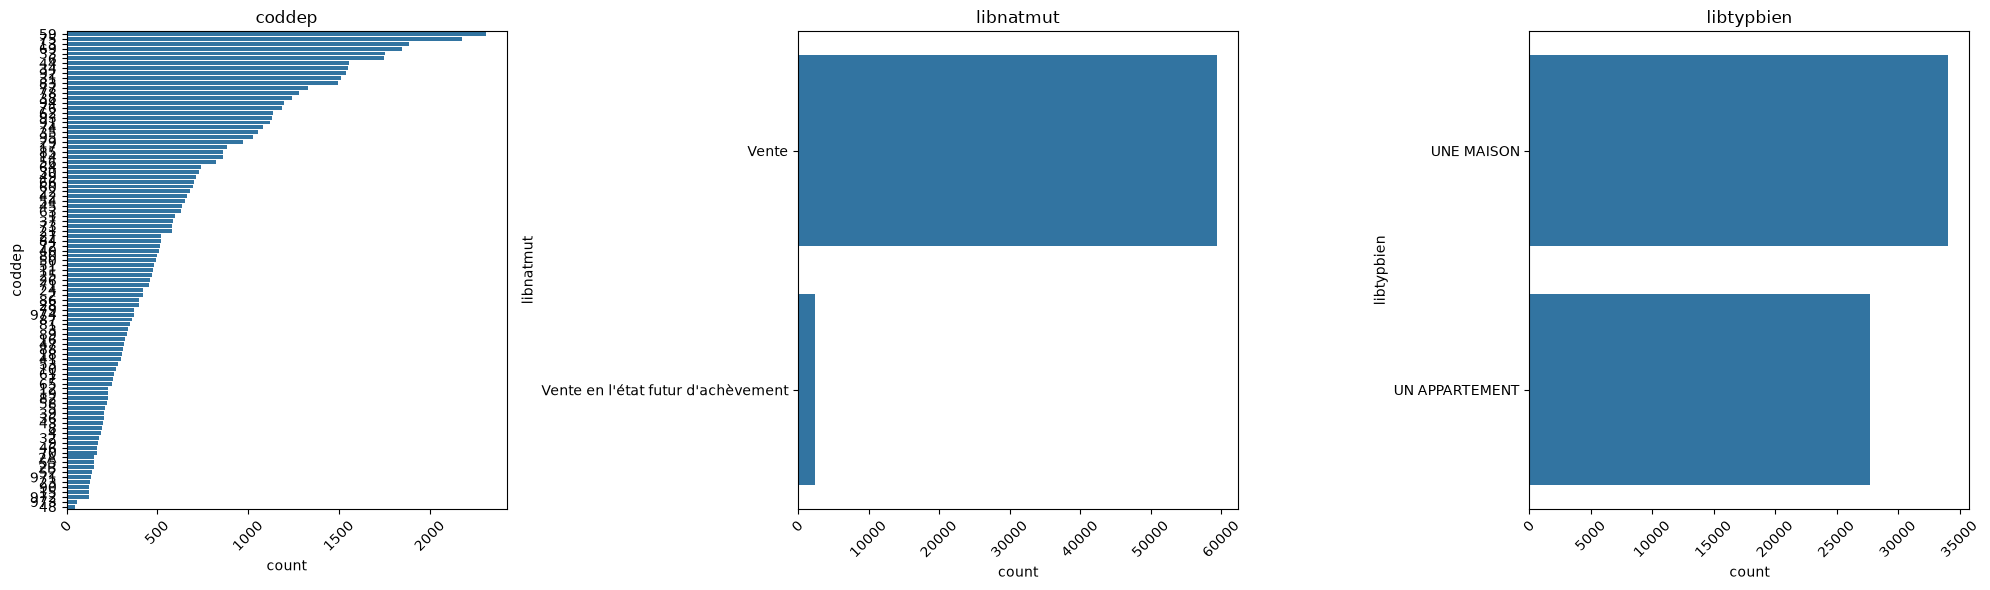

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
#Visualisation des variables catégorielles
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes = axes.flatten()

for i, col in enumerate(df_str_cat.columns[:3]):
    sns.countplot(
        data=df_str_cat,
        y=col,
        order=df_str_cat[col].value_counts().index,
        ax=axes[i]
    )
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

# Masquer les emplacements inutilisés
for ax in axes[len(df_str_cat.columns[:3]):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

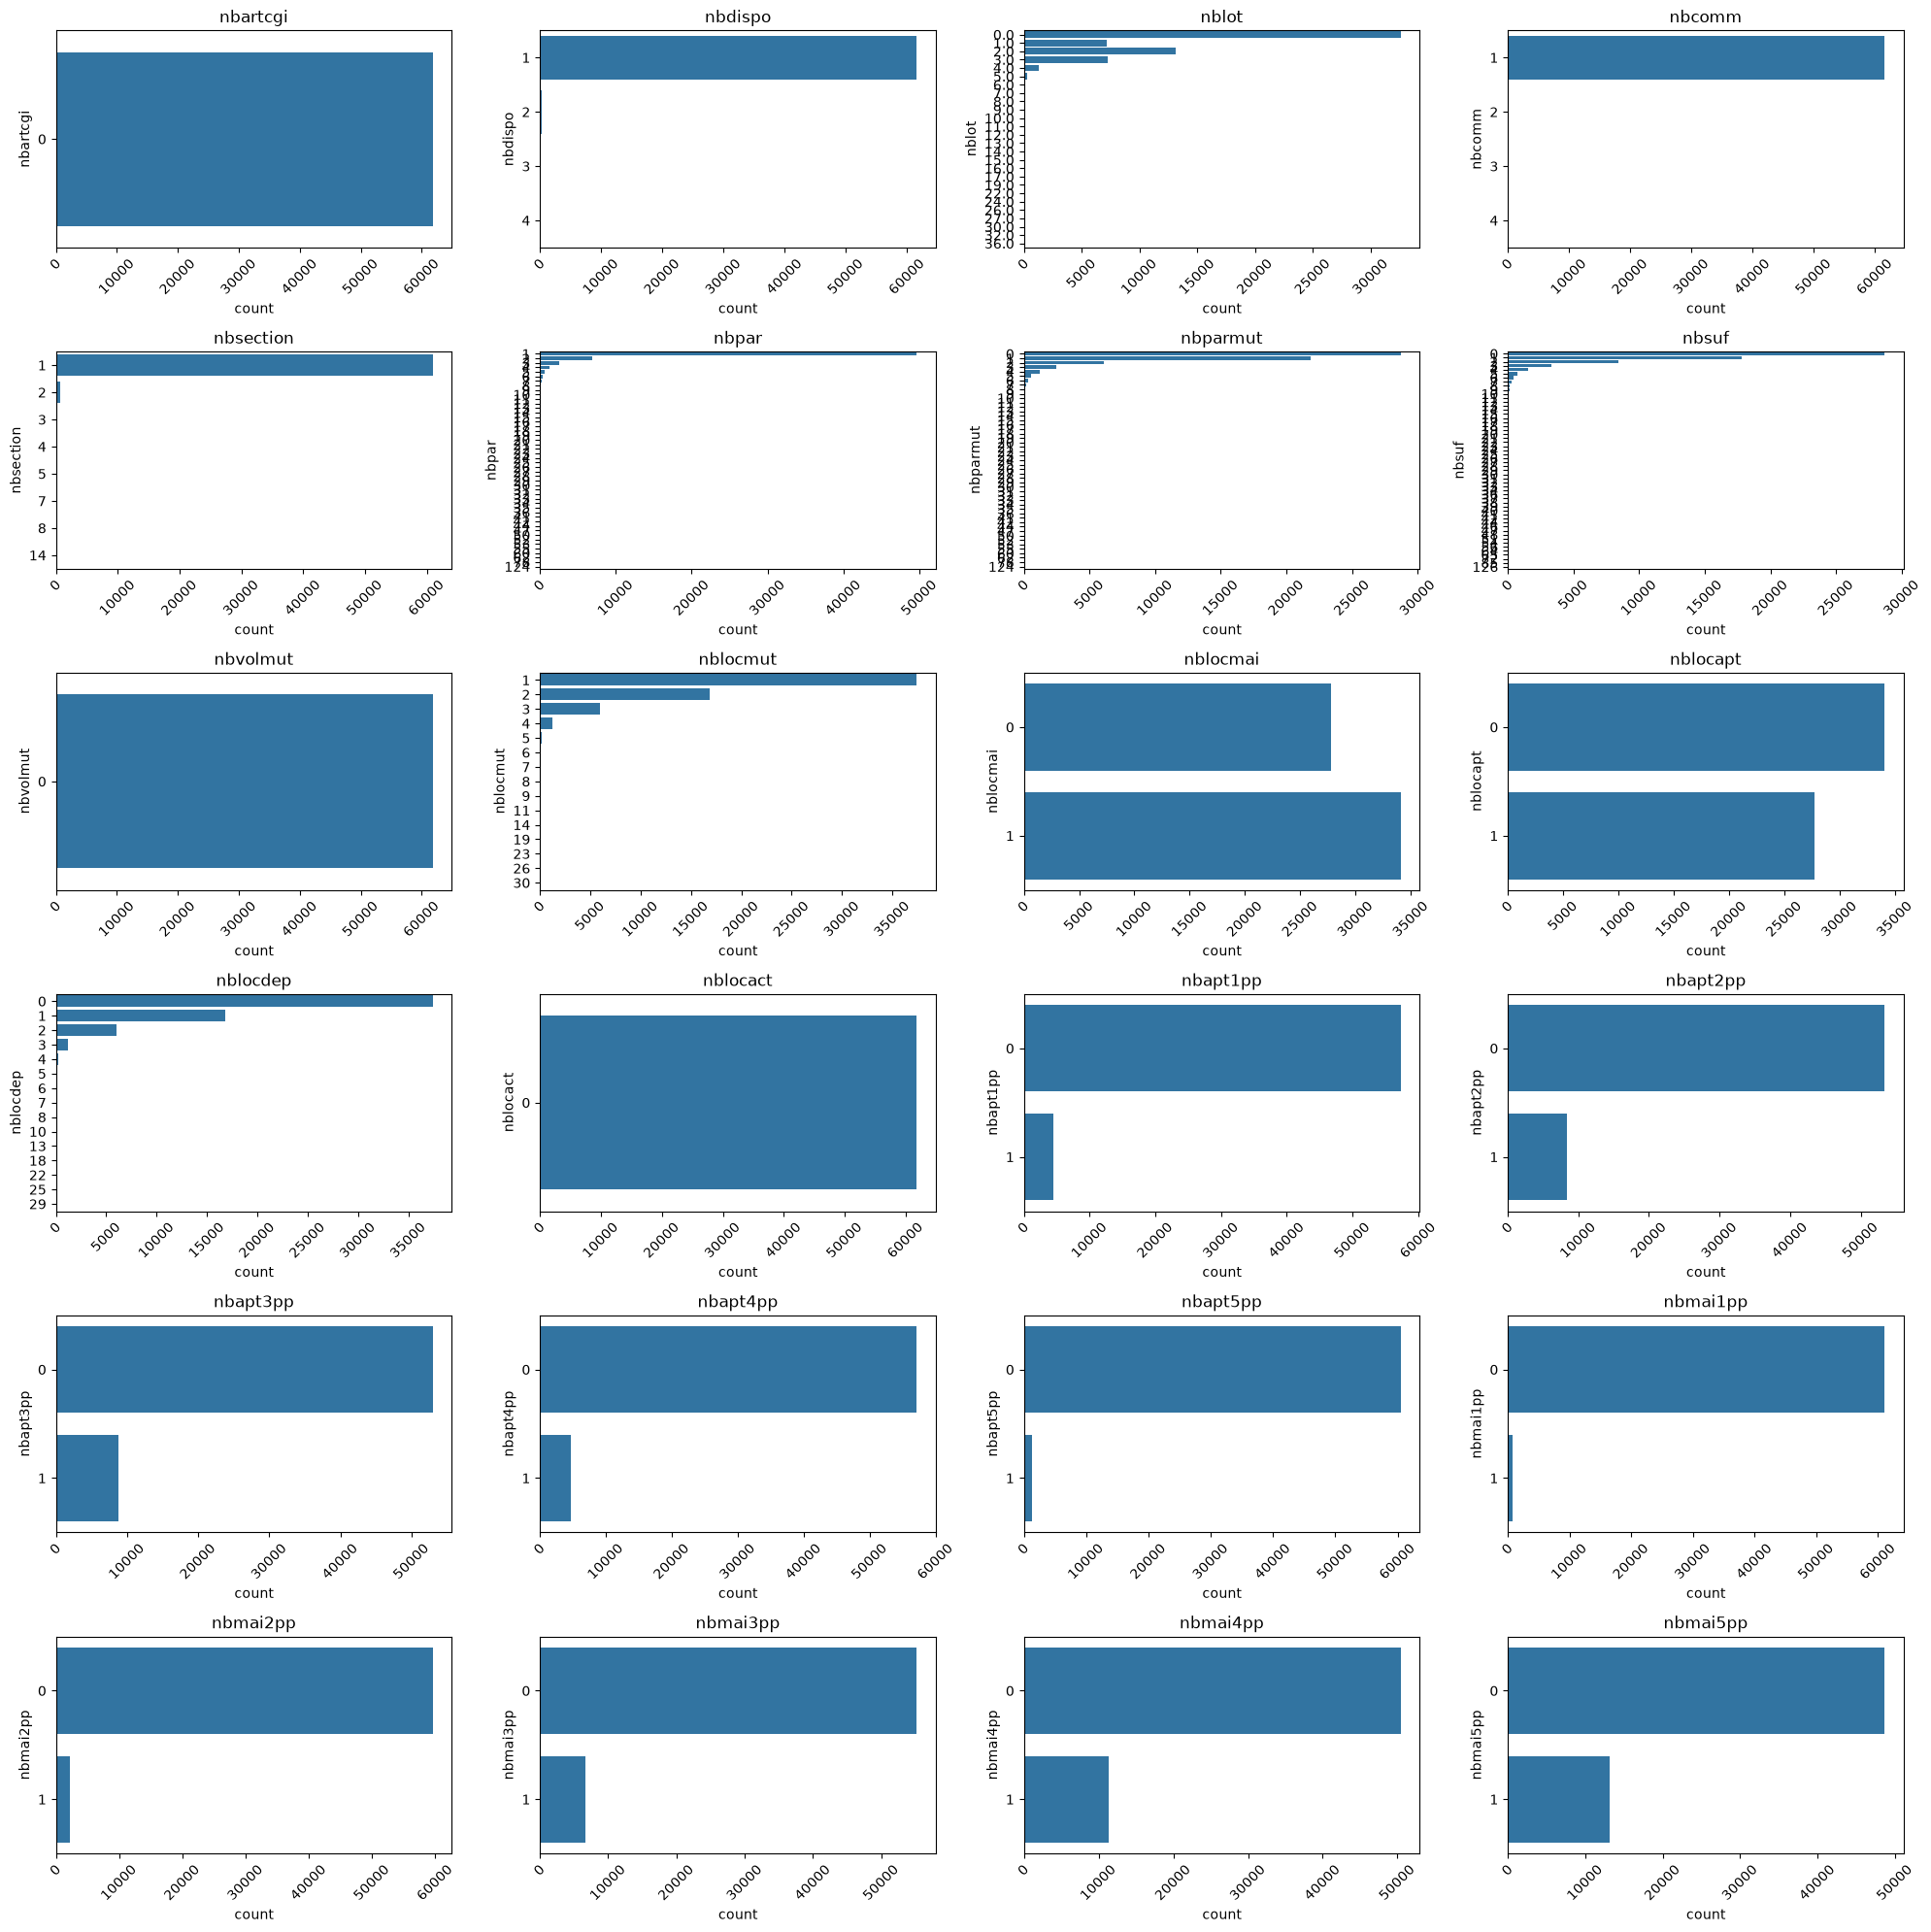

In [38]:
#Visualisation des variables quantitatives discrètes
# Visualisation des variables quantitatives discrètes
fig, axes = plt.subplots(6, 4, figsize=(20, 20))
axes = axes.flatten()

for i, col in enumerate(df_num_discrete.columns):
    sns.countplot(
        data=df_num_discrete,
        y=col,
        order=df_num_discrete[col].value_counts().sort_index().index,
        ax=axes[i]
    )
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

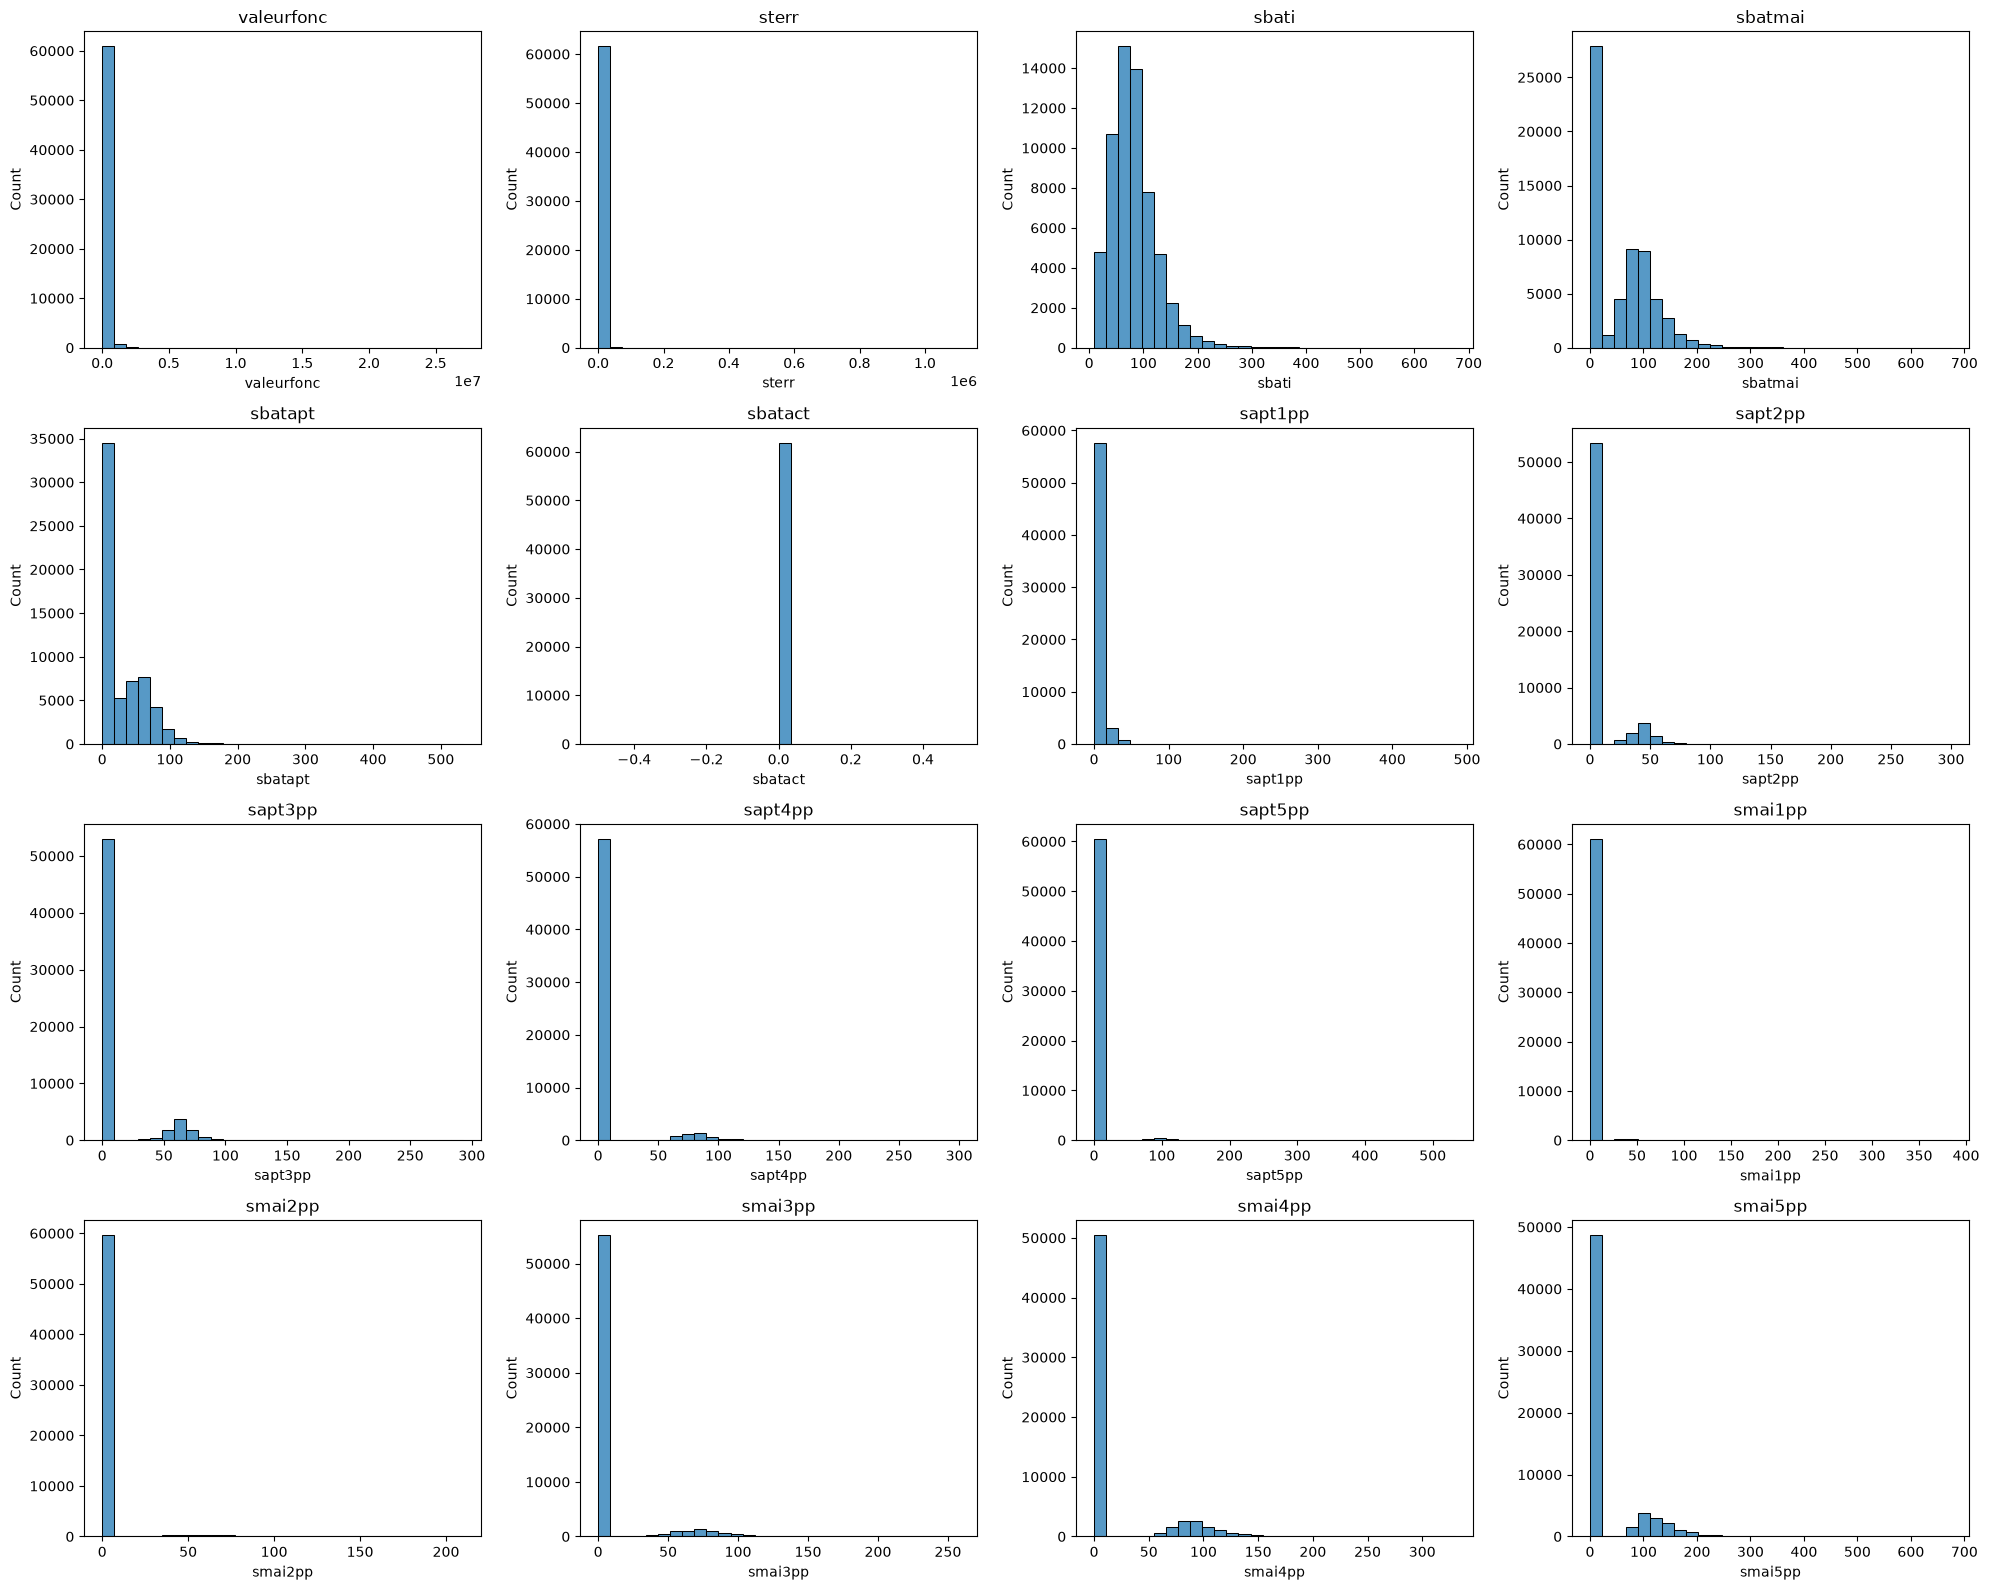

In [39]:
# Visualisation des variables quantitatives continues
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(df_num_quanti.columns):
    sns.histplot(
        data=df_num_quanti,
        x=col,
        bins=30,
        ax=axes[i]
    )
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

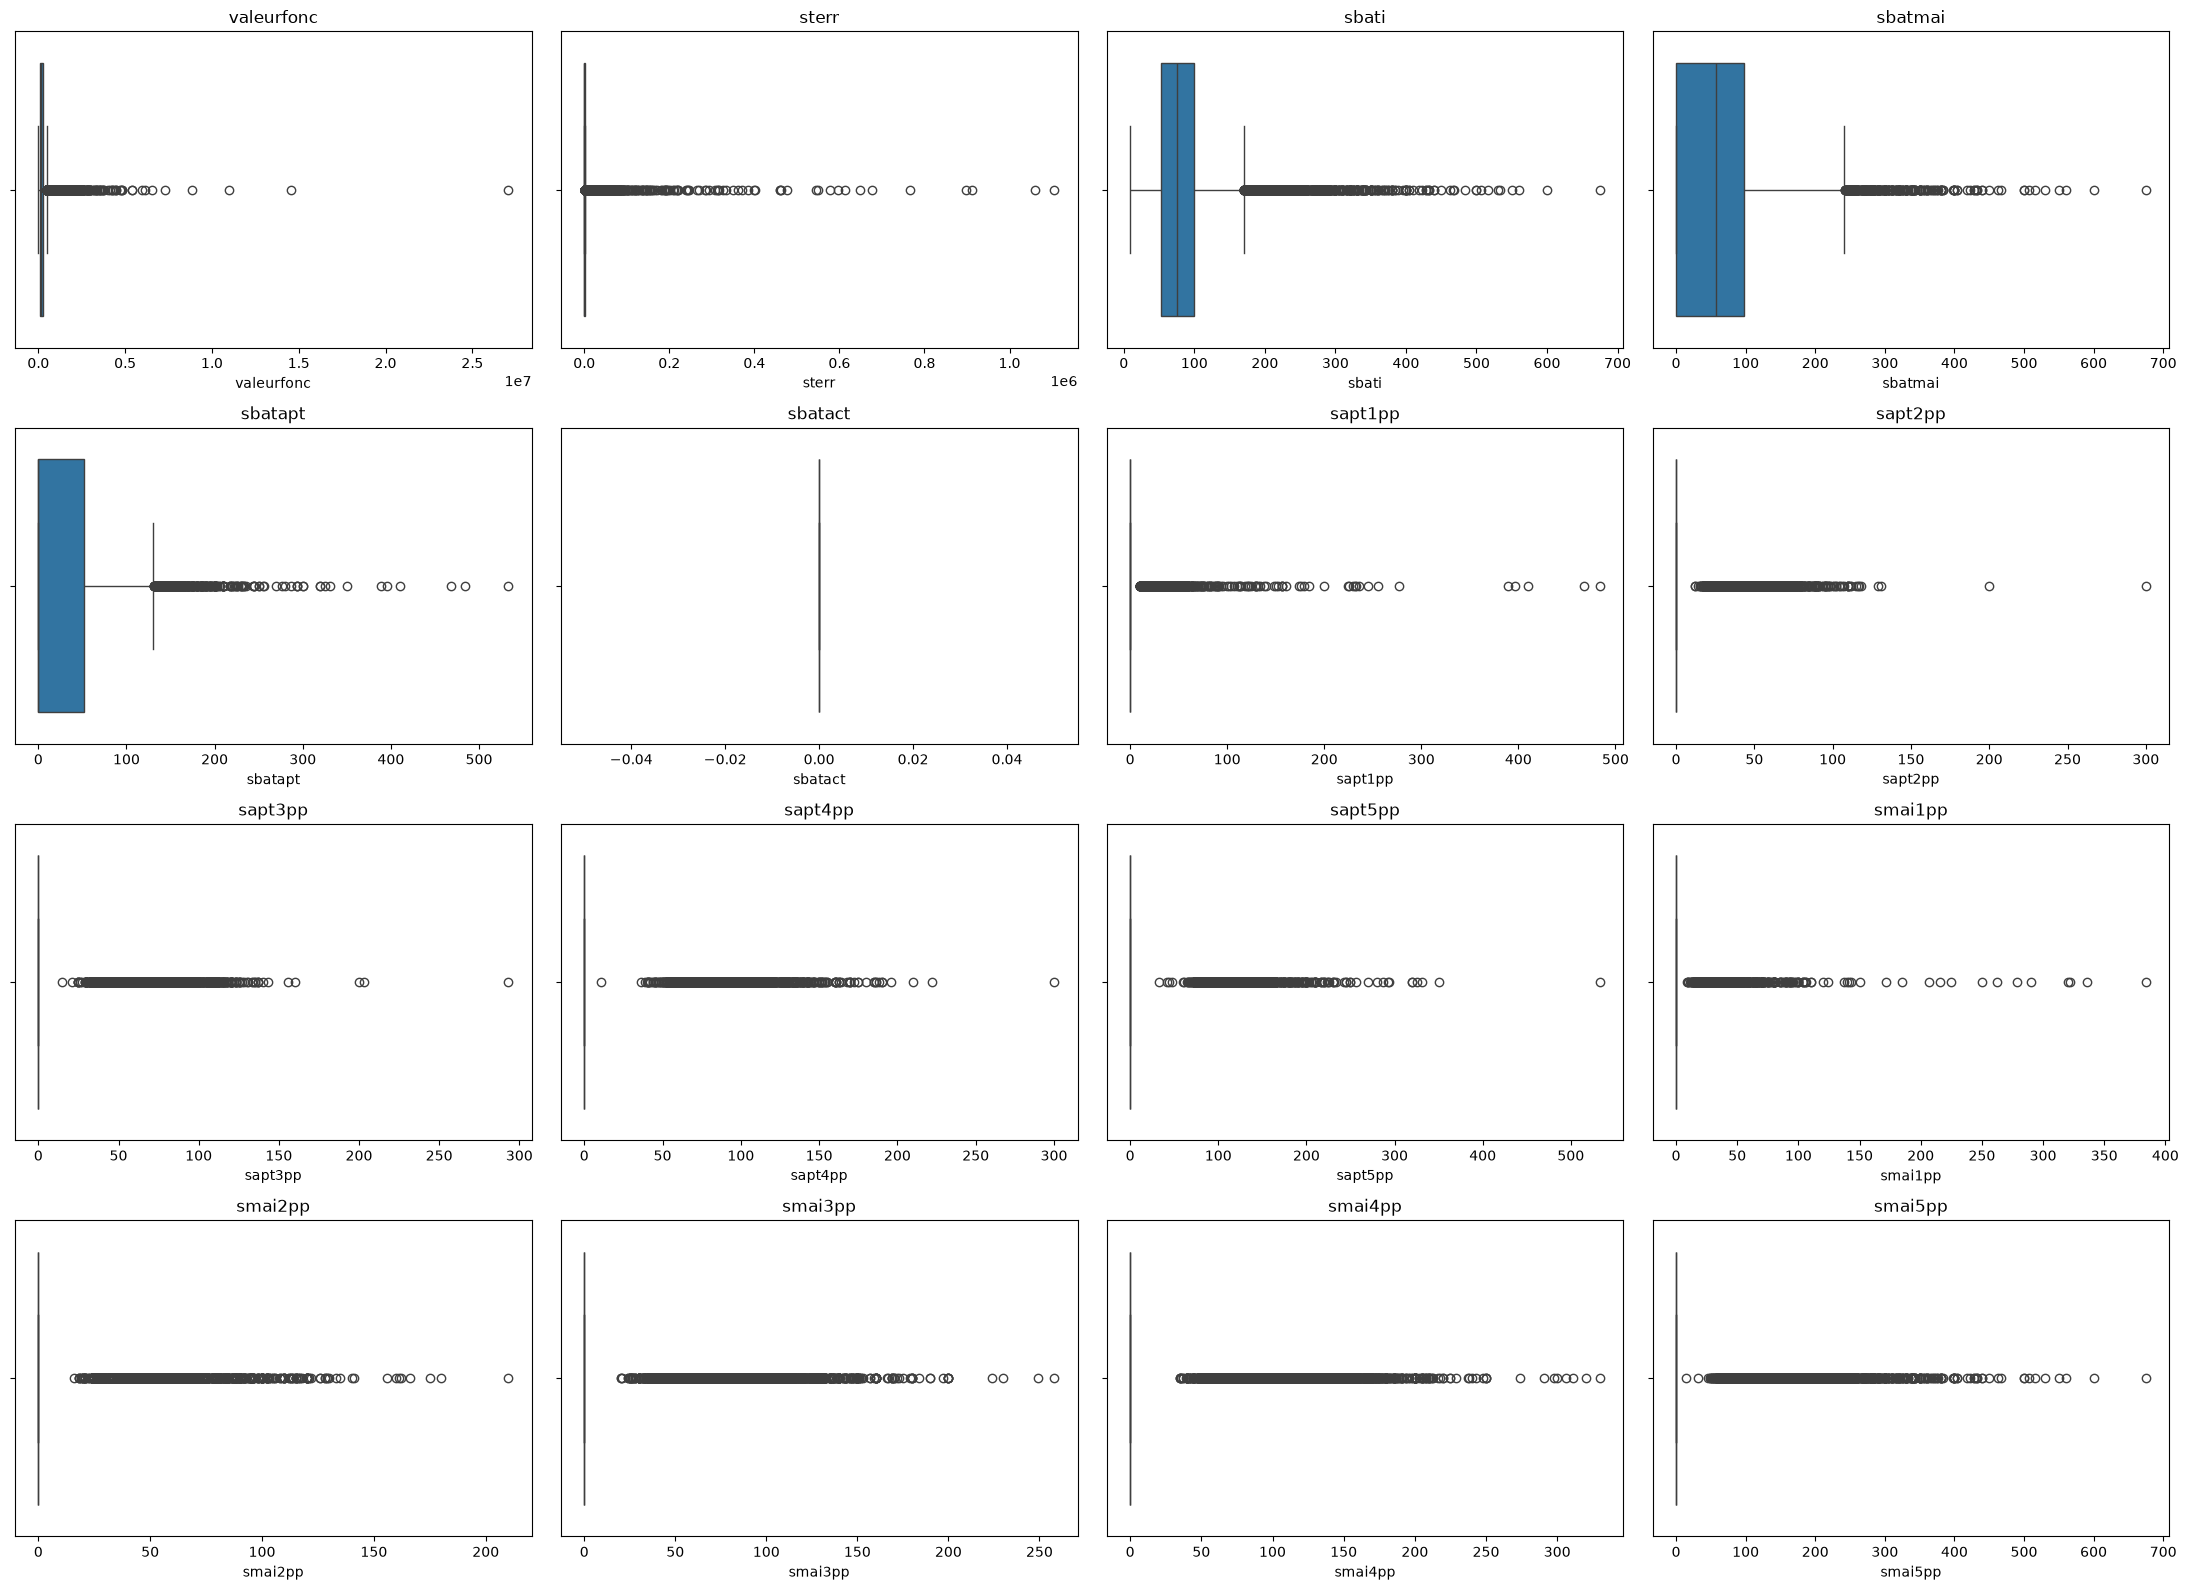

In [40]:
fig, axes = plt.subplots(4, 4, figsize=(22, 16))
axes = axes.flatten()

for i, col in enumerate(df_num_quanti.columns):
    sns.boxplot(
        data=df_num_quanti,
        x=col,
        ax=axes[i]
    )
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

In [41]:
# Vérification des valeurs nulles et des valeurs extrêmes
colonnes = ["valeurfonc", "sbati", "sterr"]

for col in colonnes:
    print(f"\nVariable : {col}")
    print("Valeurs nulles :", (df_residentiel[col] == 0).sum())
    print("Minimum :", df_residentiel[col].min())
    print("Quantile 95 % :", df_residentiel[col].quantile(0.95))
    print("Quantile 99 % :", df_residentiel[col].quantile(0.99))
    print("Maximum :", df_residentiel[col].max())


Variable : valeurfonc
Valeurs nulles : 4
Minimum : 0.0
Quantile 95 % : 550014.9999999998
Quantile 99 % : 1077292.2000000007
Maximum : 27060860.0

Variable : sbati
Valeurs nulles : 0
Minimum : 9.0
Quantile 95 % : 158.0
Quantile 99 % : 222.0
Maximum : 675.0

Variable : sterr
Valeurs nulles : 28715
Minimum : 0.0
Quantile 95 % : 3392.0
Quantile 99 % : 16027.029999999984
Maximum : 1104582.0


In [42]:
pd.crosstab(
    df_residentiel["libtypbien"],
    df_residentiel["sterr"] == 0,
    normalize="index"
).mul(100).round(2)

sterr,False,True
libtypbien,,
UN APPARTEMENT,1.97,98.03
UNE MAISON,95.53,4.47


In [43]:
df_residentiel.groupby("libtypbien")["sterr"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
).round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max
libtypbien,,,,,,,,,,
UN APPARTEMENT,27738.0,14.07,438.75,0.0,0.0,0.0,0.0,0.0,108.00,45371.0
UNE MAISON,34096.0,2471.67,18908.85,0.0,304.0,634.0,1315.0,5929.5,28584.65,1104582.0


**Constat :**

L'audit porte sur un sous-échantillon de **61 834 mutations résidentielles**, correspondant à des ventes d'une maison ou d'un appartement individuel.

Dans l'ensemble, les données paraissent de bonne qualité. Aucun doublon n'a été détecté et les variables sont globalement bien renseignées. La valeur foncière ne présente que 0,03 % de valeurs manquantes et les coordonnées géographiques 0,35 %.

Trois colonnes sont entièrement vides (`codservch`, `refdoc`, `l_artcgi`) et ne présentent donc aucun intérêt pour l'analyse. La variable `l_idparmut` comporte 46,43 % de valeurs manquantes, mais celles-ci correspondent exactement aux mutations pour lesquelles `nbparmut = 0`. Il ne s'agit donc pas d'une incohérence entre ces deux variables.

Les distributions numériques sont assez asymétriques, en particulier pour les valeurs foncières et les surfaces de terrain.

**Concernant les valeurs foncières**, 99 % des mutations renseignées ne dépassent pas 1,08 million d'euros, mais le maximum atteint 27,06 millions d'euros. Quatre mutations présentent également une valeur foncière nulle. Ces observations sont atypiques et mériteront d'être examinées pour déterminer s'il s'agit de transactions particulières ou d'anomalies.

**Les surfaces bâties présentent une distribution plus homogène.** Aucune valeur nulle n'a été relevée, 95 % des surfaces ne dépassent pas 158 m² et 99 % restent inférieures ou égales à 222 m². La surface maximale est de 675 m², ce qui reste plausible pour une grande propriété. Aucune anomalie manifeste ne ressort de cette première analyse.

**Pour les surfaces de terrain, l'analyse par type de logement a permis de clarifier les résultats.** Initialement, 46,44 % des mutations présentaient une surface nulle, ce qui pouvait laisser penser à un problème de qualité. En distinguant les maisons des appartements, on constate que :

- 98,03 % des appartements ont une surface de terrain nulle, ce qui est cohérent avec les ventes en copropriété, où le terrain n'est généralement pas individualisé.
- Seulement 4,47 % des maisons ont une surface de terrain nulle. Pour les autres, la surface médiane est de 634 m² et le 95e percentile atteint 5 930 m².

Les valeurs nulles de `sterr` s'expliquent donc principalement par la typologie des biens et ne constituent pas un problème généralisé de qualité. En revanche, certaines superficies restent très importantes, avec un maximum dépassant 110 hectares pour les maisons. Ces transactions devront être examinées pour vérifier leur cohérence avec le périmètre du projet.

#### Conclusion et décisions

Le sous-échantillon présente une **bonne complétude, aucun doublon détecté et des distributions globalement cohérentes avec la nature des biens étudiés**. Les vérifications croisées ont notamment permis de montrer que certaines valeurs initialement suspectes, comme les surfaces de terrain nulles, s'expliquent par les caractéristiques des transactions.

Les principales réserves concernent les valeurs foncières extrêmes, les quatre transactions à valeur nulle et quelques surfaces de terrain particulièrement élevées. Il reste également à comprendre les surfaces nulles observées pour une minorité de maisons.

À ce stade, rien ne justifie un nettoyage systématique des données. Les valeurs extrêmes ne sont pas nécessairement des erreurs : elles peuvent correspondre à des transactions rares mais réelles.

**Pour la suite**, les vérifications seront concentrées sur ces quelques situations particulières. Les éventuelles décisions de traitement devront être justifiées par leur cohérence métier et leur pertinence pour le modèle de prédiction, plutôt que par leur seul caractère statistiquement atypique.

## Synthèse du premier niveau d'audit — DVF+

#### Constat
La base DVF+ constitue une source pertinente pour le projet Compagnon Immo. Issue des données fiscales de la DGFiP et structurée par le Cerema, elle permet d'étudier les transactions immobilières réellement enregistrées, sur une période de 12 ans (2014–2025) et à l'échelle de 97 départements.

L'échantillon initial de 100 000 mutations a permis de mettre en évidence une forte diversité des transactions : logements individuels, terrains, locaux d'activité et opérations portant parfois sur plusieurs centaines de biens. Cette hétérogénéité rendait difficile l'évaluation de la qualité des données au regard de notre objectif métier.

Nous avons donc choisi de restreindre le périmètre aux ventes classiques et aux VEFA portant sur **une seule maison ou un seul appartement**, avec d'éventuelles dépendances. Ce premier sous-échantillonnage a permis de conserver **61 834 mutations**, soit près de 62 % de la base initiale.

L'examen de cette population montre une qualité globalement satisfaisante. Aucun doublon n'a été détecté, les variables essentielles sont très largement renseignées et les surfaces bâties présentent des distributions cohérentes avec le marché résidentiel. Les vérifications croisées ont également permis d'expliquer certaines particularités, notamment les surfaces de terrain nulles, qui concernent principalement les appartements.

Les principales réserves portent sur les valeurs foncières extrêmes, quelques transactions à valeur nulle et certaines superficies de terrain particulièrement importantes. Ces observations ne constituent pas nécessairement des erreurs, mais devront être examinées avant la modélisation.

**Ce premier audit permet donc de retenir DVF+ comme source de travail pour Compagnon Immo**, avec une limite importante : la valeur foncière est associée à une mutation et non à chaque bien pris individuellement. Le choix de travailler sur des transactions portant sur un seul logement répond notamment à cette contrainte.

#### Ouverture vers d'autres sources de données

La base contient également les codes INSEE des communes concernées par chaque mutation (l_codinsee). Cette information constitue un point d'entrée intéressant pour enrichir ultérieurement les données immobilières avec des indicateurs territoriaux : population, évolution démographique, niveau de vie, services et équipements de proximité.

Ces rapprochements pourraient notamment être réalisés avec les données de l'INSEE et la Base permanente des équipements (BPE), afin d'intégrer des caractéristiques de l'environnement local dans le futur modèle de prédiction.

Il faudra toutefois tenir compte du fait que l_codinsee est une liste de codes communaux : sa structure devra être vérifiée avant toute jointure, notamment pour les mutations concernant plusieurs communes. La cohérence temporelle entre les différentes sources devra également être assurée.

#### Décisions pour la suite

**Périmètre.** Le périmètre résidentiel est retenu : ventes d'une seule maison ou d'un seul appartement, avec d'éventuelles dépendances, portant sur une seule commune. Les VEFA sont exclues, car elles relèvent du marché du neuf (TVA incluse dans le prix, frais d'acquisition réduits).

**Couverture temporelle et géographique.** La période 2014-2025 est conservée ; l'année 2025 est réservée au test du modèle. La couverture géographique est limitée à la France métropolitaine : les DOM sont exclus, et l'Alsace-Moselle est absente de DVF+.

**Variables non conservées.** Les variables suivantes ne seront pas utilisées pour la suite. Elles restent disponibles dans les fichiers sources et peuvent être rattachées par `idmutation` si besoin.

- Colonnes vides : `codservch`, `refdoc`, `l_artcgi`.
- Colonne constante : `nbartcgi` (toujours égale à 0).
- Identifiants redondants avec `idmutation` : `idmutinvar`, `idopendata`.
- Listes de références cadastrales et de locaux : `l_section`, `l_idpar`, `l_idparmut`, `l_idlocmut`.
- Surfaces de terrain par type d'occupation du sol : `l_dcnt`.

Aucune de ces variables n'intervient dans les jointures prévues qui pourront être : `anneemut` et `moismut` pour les taux mensuels, `l_codinsee` pour la commune, `geompar_x` et `geompar_y` pour un éventuel rattachement à l'IRIS.

**Contrôles à venir.** Les contrôles complémentaires porteront principalement sur la cohérence des prix et des surfaces, et sur les différences entre maisons et appartements.

À ce stade, aucun nettoyage systématique n'est engagé. Les résultats de l'audit fournissent une première connaissance de la structure, du contenu et des limites de la base, suffisante pour passer à une EDA davantage orientée vers les questions métier et la préparation du modèle de prédiction.

# 2. Bassins de vie et table de passage des communes

**Contributeurs :** Gabrielle RICHERT · **Date :** 14/10/2026

Sources : `BV2022_2022_2026.xlsx` (bassins de vie 2022, géographie 2026) et `table_passage_geo2003_geo2026.xlsx` (Insee).

L'inspection portait d'abord sur les bassins de vie 2012 (`BV2012_2014_2022.xlsx`), abandonnés au profit des bassins 2022 : cette partie et la comparaison 2012 / 2022 ne sont pas reprises, faute de fichier conservé. La construction de la table de liaison qui concluait l'inspection est désormais faite par le bloc 1 de `01_preparation`.

## Définitions par l'INSEE (mise à jour 06.08.2026)

**Bassin de vie** : Le bassin de vie est le plus petit territoire sur lequel les habitants ont accès aux équipements et services les plus courants. Les services et équipements de la vie courante servant à définir les bassins de vie sont classés en 6 grands domaines: services aux particuliers, commerce, enseignement, santé, sports, loisirs et culture,transports.

## Bassins de vie 2022

### 1. Situer la source et ouvrir les données

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine |INSEE | aucun fichier de métadonnées associé mais 2 feuilles descriptives dans l'excel|
| Finalité initiale | | |
| Mode de collecte | INSEE, code officiel géographique| |
| Extraction / mise à jour | 2022 à 2026 | |
| Documentation / licence | aucune information| |
| Population / objets annoncés | 1e feuille : nom de chaque bassin de vie, intitulé, type et nombre de communes présentes ; 2e feuilles : par code géographique officiel des communes on trouve son libellé, le bassin de vie auquel elle appartient, le type de commune, son département et sa région | |
| Période / territoire, si pertinents | France avec ses DOM-TOM| |

In [44]:
bv2022=pd.read_excel(DATA_RAW / 'BV2022_2022_2026.xlsx', sheet_name='BV2022', skiprows=5)
compo_communale2022=pd.read_excel(DATA_RAW / 'BV2022_2022_2026.xlsx', sheet_name='Composition_communale', skiprows=5)

In [45]:
bv2022.head()

,BV2022,LIBBV2022,TYPE_BV2022,NB_COM
0,01004,Ambérieu-en-Bugey,2,34
1,01033,Valserhône,2,20
2,01034,Belley,2,35
3,01053,Bourg-en-Bresse,3,23
4,01072,Ceyzériat,2,16


In [46]:
compo_communale2022.head()

,CODGEO,LIBGEO,BV2022,LIBBV2022,TYPE_COMMUNE_BV2022,DEP,REG
0,01001,L'Abergement-Clémenciat,01093,Châtillon-sur-Chalaronne,0,01,84
1,01002,L'Abergement-de-Varey,01004,Ambérieu-en-Bugey,0,01,84
2,01004,Ambérieu-en-Bugey,01004,Ambérieu-en-Bugey,20,01,84
3,01005,Ambérieux-en-Dombes,01333,Saint-André-de-Corcy,0,01,84
4,01006,Ambléon,01034,Belley,0,01,84


In [47]:
#Nombre de valeurs uniques par variable
print('valeurs uniques dans les compositions communales 2022 :\n', compo_communale2022.nunique())
print('valeurs uniques dans les bassins de vie 2022 :\n', bv2022.nunique())

valeurs uniques dans les compositions communales 2022 :
 CODGEO                 34875
LIBGEO                 32645
BV2022                  1707
LIBBV2022               1699
TYPE_COMMUNE_BV2022        4
DEP                      101
REG                       18
dtype: int64
valeurs uniques dans les bassins de vie 2022 :
 BV2022         1707
LIBBV2022      1699
TYPE_BV2022       3
NB_COM           99
dtype: int64


In [48]:
# Nombre d'annonces par département 
print(compo_communale2022["DEP"].value_counts())

print('nombre de communes totales de 2022 à 2026')
print(compo_communale2022["DEP"].value_counts().sum())

DEP
62     887
02     797
80     771
57     725
76     707
      ... 
971     32
974     24
973     22
976     17
75       1
Name: count, Length: 101, dtype: int64
nombre de communes totales de 2022 à 2026
34875


In [49]:
codgeo_bv2022=compo_communale2022.merge(bv2022, on=["BV2022", 'LIBBV2022'],how="left")

**Constat :**

Les codes géographiques officiels de chaque commune sont uniques, ils serviront d'index.
On retrouve le détail pour chacun des bassins de vie dans une autre feuille du tableur excel avec les informations le décrivant.

**Impact projet :**

Un fichier unique pour les codes géographique et les bases de vie est possible et essentiel pour la simplification de son utilisation.

**Action envisagée :**

Fusion des informations contenues dans les deux feuilles excel dans un unique DataFrame.

**Incertitudes / limites, si nécessaire :**

Un code géographique peut aussi être un code de bassin de vie. Viligance.

DONNEES DE 2022 A 2026

### 2. Comprendre la structure et une ligne

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 34 935 lignes × 8 colonnes |
| Contenu général, en une phrase | Pour chaque commune on a comme information son libellé et son type, le bassin de vie auquel elle appartient, son intitulé et son type, le nombre de communes qui se trouvent dans le bassin de vie ainsi que son département et sa région|
| Unité d’observation | Une commune identifiée par son code géographique |
| Identifiants / clés possibles | le code géographique |
| Une ou plusieurs lignes par objet ? Pourquoi ? |Une ligne par commune. |
| Doublons exacts : nombre / proportion | 0 (0 %) : aucune annonce identique sous deux identifiants différents|
| Répétitions métier : règle examinée / résultat | non applicable |

In [50]:
codgeo_bv2022.head()

,CODGEO,LIBGEO,BV2022,LIBBV2022,TYPE_COMMUNE_BV2022,DEP,REG,TYPE_BV2022,NB_COM
0,01001,L'Abergement-Clémenciat,01093,Châtillon-sur-Chalaronne,0,01,84,2,17
1,01002,L'Abergement-de-Varey,01004,Ambérieu-en-Bugey,0,01,84,2,34
2,01004,Ambérieu-en-Bugey,01004,Ambérieu-en-Bugey,20,01,84,2,34
3,01005,Ambérieux-en-Dombes,01333,Saint-André-de-Corcy,0,01,84,2,7
4,01006,Ambléon,01034,Belley,0,01,84,2,35


In [51]:
print(codgeo_bv2022.shape) 
display(codgeo_bv2022.head())
codgeo_bv2022.info() 


# La clé semble être le code géographique et on vérifie si elle est bien unique et jamais vide
print("code géographique unique :", codgeo_bv2022["CODGEO"].is_unique)
print("code géographique vide   :", codgeo_bv2022["CODGEO"].isna().sum())

# On regarde s'il y a des doublons exacts dans le dataset sans prendre en compte l'Index
codgeo_bv2022.duplicated().sum() 

(34875, 9)


,CODGEO,LIBGEO,BV2022,LIBBV2022,TYPE_COMMUNE_BV2022,DEP,REG,TYPE_BV2022,NB_COM
0,01001,L'Abergement-Clémenciat,01093,Châtillon-sur-Chalaronne,0,01,84,2,17
1,01002,L'Abergement-de-Varey,01004,Ambérieu-en-Bugey,0,01,84,2,34
2,01004,Ambérieu-en-Bugey,01004,Ambérieu-en-Bugey,20,01,84,2,34
3,01005,Ambérieux-en-Dombes,01333,Saint-André-de-Corcy,0,01,84,2,7
4,01006,Ambléon,01034,Belley,0,01,84,2,35


<class 'pandas.DataFrame'>
RangeIndex: 34875 entries, 0 to 34874
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   CODGEO               34875 non-null  str  
 1   LIBGEO               34875 non-null  str  
 2   BV2022               34875 non-null  str  
 3   LIBBV2022            34875 non-null  str  
 4   TYPE_COMMUNE_BV2022  34875 non-null  int64
 5   DEP                  34875 non-null  str  
 6   REG                  34875 non-null  int64
 7   TYPE_BV2022          34875 non-null  int64
 8   NB_COM               34875 non-null  int64
dtypes: int64(4), str(5)
memory usage: 3.5 MB
code géographique unique : True
code géographique vide   : 0


np.int64(0)

**Constat :**

Le jeu de données compte 34 935 lignes × 8 colonnes. L'index, le code géographique est unique, sans manque ni répétitions.

**Impact projet :**

Ce jeux de données servira de lien entre toutes les autres.



### 3. Comprendre les variables

In [52]:
codgeo_bv2022.info()

<class 'pandas.DataFrame'>
RangeIndex: 34875 entries, 0 to 34874
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   CODGEO               34875 non-null  str  
 1   LIBGEO               34875 non-null  str  
 2   BV2022               34875 non-null  str  
 3   LIBBV2022            34875 non-null  str  
 4   TYPE_COMMUNE_BV2022  34875 non-null  int64
 5   DEP                  34875 non-null  str  
 6   REG                  34875 non-null  int64
 7   TYPE_BV2022          34875 non-null  int64
 8   NB_COM               34875 non-null  int64
dtypes: int64(4), str(5)
memory usage: 3.5 MB


In [53]:
codgeo_bv2022.nunique()

CODGEO                 34875
LIBGEO                 32645
BV2022                  1707
LIBBV2022               1699
TYPE_COMMUNE_BV2022        4
DEP                      101
REG                       18
TYPE_BV2022                3
NB_COM                    99
dtype: int64

| Variable | Signification | Nature statistique | unité | Type de stockage et cohérence | 
|---|---|---|---|---|
| LIBGEO | Libellé géographique | qualitative | N/A | str : cohérent |
| BV2012 | code géographique du bassin de vie 2012 | qualitative | N/A | str : cohérent |
| LIBBV2012 | libellé géographique du bassin de vie | qualitative | N/A | str : cohérent |
| DEP | Code géographique du département | qualitative | N/A| str :  cohérent car ce sont des nombres mais ils devront se comporter comme des modalités|
| REG | Code géographique de la région | qualitative | N/A  | int64 : devront se comporter comme des modalités, passer en str? |
| NB_COM | Nombre de communes contenues dans le bassin de vie | quantitative continue | quantitative | int64 : cohérent |
| TYPE_BV2022 | type de bassin de vie | qualitative |1-bassin issus d'un pôle partiel, dit 'rural', 2-bassin avec une seule commune pôle, dit 'intermédiare', 3- bassin avec plusieurs communes-pôles, dit 'dense' | int64 : modalités donc str? |
| TYPE_COMMUNE_BV2022 | catégorie de la commune vis-à-vis du bassin de vie | qualitative | 00-non pôle, 11- pôle partiel, 12- commune associée à un pôle partiel, 20-pôle | int64 : modalités donc str? |

In [54]:
# Mesurer les NaN par variable 
manquants = pd.DataFrame({"nb_NaN": codgeo_bv2022.isna().sum(),
                          "pct_NaN": (codgeo_bv2022.isna().mean() * 100).round(1)})
manquants = manquants[manquants["nb_NaN"] > 0].sort_values("pct_NaN", ascending=False)
display(manquants)

,nb_NaN,pct_NaN


Il n'y a aucune valeur manquante dans tout le jeux de données des bassins de vie de 2022 à 2026.

### Distribution des variables sur les bassins de vie

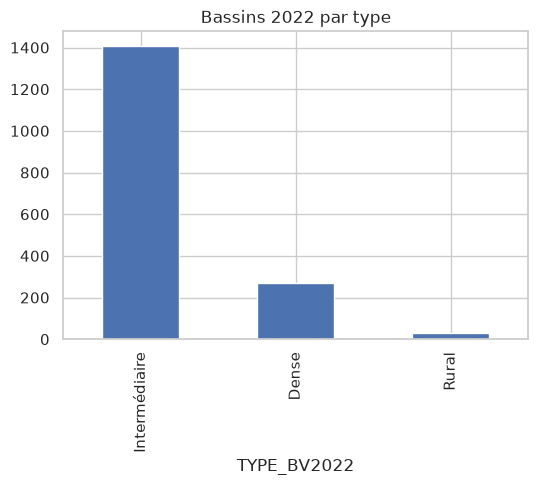

In [55]:
sns.set_theme(style="whitegrid")

bv22 = codgeo_bv2022.copy()
bv22["NB_COM"] = bv22["NB_COM"].astype(int)

# Un bassin = une ligne
b22 = bv22.drop_duplicates("BV2022")

# Répartition des types de bassin 2022
labels = {1: "Rural", 2: "Intermédiaire", 3: "Dense"}
t = b22.TYPE_BV2022.map(labels).value_counts()
t.plot.bar(title="Bassins 2022 par type", figsize=(6, 4))
plt.show()

Graphique : bassins de vie en 2022 classés par type.
Les bassins de type intermédiaire domine largement avec 1408 bassins soit 82% des bassins du fichier.
Le type dense ne regroupe que 271 bassins et le type de bassin rural seulement 28 bassins sont concernés.
Le type 3 urbain, malgré qu'il ne représente que 15.9% des bassins est aussi le plus étendu en terme de surface sur le territoire car chaque bassin possède en moyenne 28.8communes. On se représente plutôt bien ce type de bassins : une ville au centre très importante et sa couronne.

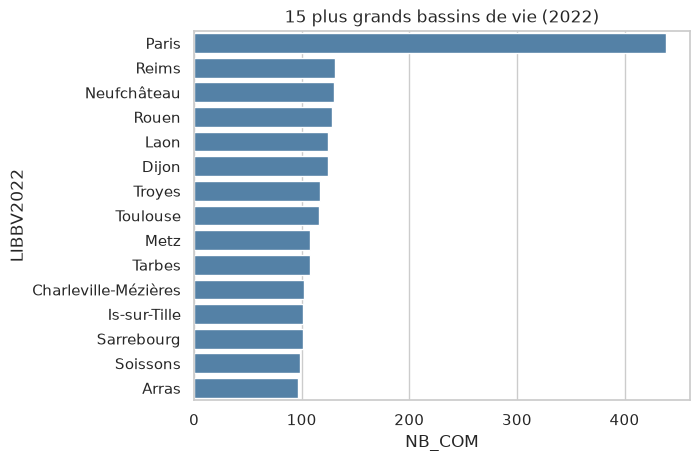

In [56]:
# 3. Top 15 des plus grands bassins (en nb de communes)
top = b22.nlargest(15, "NB_COM")
sns.barplot(data=top, y="LIBBV2022", x="NB_COM", color="steelblue")
plt.title("15 plus grands bassins de vie (2022)")
plt.show()

Graphique : 15 plus grands bassins de vie.
Sans surprise Paris est le plus grand bassin de vie avec 440 communes et devance de loin le second qui est Reims (130 communes).
Le nombre de communes dans un bassin reflète le morcellement des petites communes notamment en zone rurale, qu'il pourra être intéressant d'analyser réellement en tant que bassin, contrairement à Paris où au sein d'un même bassin de vie les prix des biens peuvent énormément varier sur de plus courtes distances.

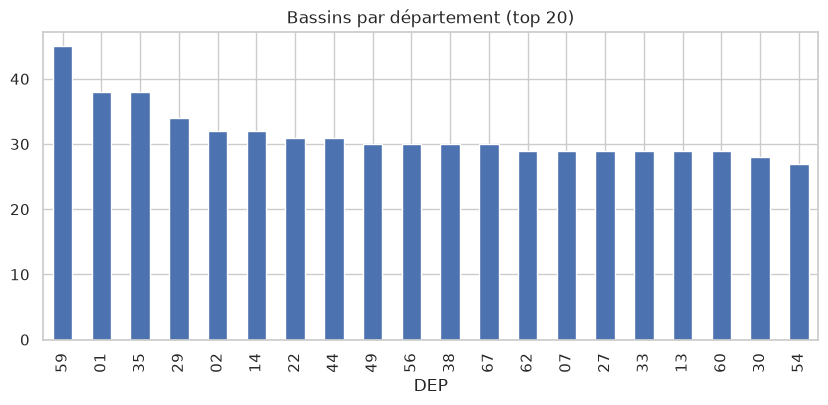

In [57]:
# 4. Nombre de bassins par département / région
bv_dep = b22.groupby("DEP").size().sort_values(ascending=False).head(20)
bv_dep.plot.bar(figsize=(10, 4), title="Bassins par département (top 20)")
plt.show()

Graphique : top20 du nombre de bassins par département
On ne voit pas apparaître les bassins les plus denses car ils peuvent occuper un département voir plus comme c'est le cas de Paris : vigilance donc lors des agrégations.

## Conclusion sur l'usage des BV dans le projet

**Différenciation selon la temporalité**
Il sera nécessaire de découper ou attribuer différemment les codes de bassins de vie en fonction de si la vente a eu lieu avant 2022 (utilisation du codgeo_bv2012.csv) ou pendant/après 2022 (utilisation du codgeo_bv2022.csv).

**Limites :**
- les arrondissements des plus grosses villes ne sont pas précisés.
- évolution des bassins au cours du temps.
- si on cherche à utiliser les deux fichiers ont aura peut être générer un 'saut' suite aux changements sur certaines communes et bassins qui ne sera pas représentatif de la réalité.

**La commune, via son code géographique,** semble ici la clé principale pour permettre une jointure correcte car seulement très peu de mouvements (0.1% ont bougé, il faudra fusionner les anciennes communes avec celles qui les ont remplacées).

Les codes des **bassins de vie** ne changent pas mais leur périmètre peut changer drastiquement entre les deux versions.

**Utilisation des bassins de vie en lien avec le DVF+**
Idée principale : **garder toutes les informations**, merge chacun des jeux de données sur les bassins de vie en se basant sur le code géographique de chaque commune.
La majorité des analyses pourront porter sur **les bassins de vie en 2022** et éventuellement faire des tests comparatifs en les fichiers 2012 et 2022 pour voir si le découpage des bassins de vie a eu un impact sur certaines données.

Idée à discuter en groupe : **supprimer de l'analyse les 0.1% de communes qui changent** ?

## Exploitation du fichier codgeo_bv2022.csv

Méthode choisie : conservation du fichier BV2022 car seulement 0.1% des communes sont impactées.

### Analyse lors du lien avec le fichier DVF+

**Test de la jointure entre la table cible DVF+ et la composition communale** (BV2022_2022_2026.xlsx, géographie 2026) :

• 6,4 % des ventes ne trouvent pas de bassin (613 973 sur 9,66 M)

• dont 582 153 pour les arrondissements de Paris, Lyon et Marseille (75101…, 69381…, 13201…) : le fichier Insee ne connaît que 75056, 69123 et 13055

• et 31 820 pour 1 666 anciens codes de communes fusionnées depuis 2014 (surtout 49, 50, 14)

**Proposition** : construire une table de correspondance unique pour toute l'équipe avec le code commune passé ou actuel et son bassin de vie 2022. Apparemment tu auras besoin de la table de passage de l'INSEE (Lien direct : table_passage_geo2003_geo2026.zip)
 Il reste juste à ajouter les arrondissements à la main (751xx → 75056, 6938x → 69123, 132xx → 13055), puis à joindre le bassin.

### Structure de la table de passage des communes

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 36 743 lignes × 3 colonnes |
| Contenu général, en une phrase | Pour chaque code géographique initial de 2003, correspondance avec le code géographique utilisé en 2026 |
| Unité d’observation | Une commune identifiée par son code géographique |
| Identifiants / clés possibles | le code géographique initial (CODGEO_INI) |
| Une ou plusieurs lignes par objet ? Pourquoi ? |Une ligne par commune, possible multiples lignes pour un code géographique initial car il y a eu des cas de scissions de communes |
| Doublons exacts : nombre / proportion | 0 (0 %) : pas de réel doublon car 2 lignes dans le cas d'une scission auront le même code géographique initial mais deux codes géographiques 'finaux' |
| Répétitions métier : règle examinée / résultat | non applicable |

In [58]:
import pandas as pd
import numpy as np

In [59]:
passage=pd.read_excel(DATA_RAW / 'table_passage_geo2003_geo2026.xlsx', sheet_name='Table de passage', skiprows=5, dtype=str)
scissions=pd.read_excel(DATA_RAW / 'table_passage_geo2003_geo2026.xlsx', sheet_name='Liste des scissions', skiprows=5, dtype=str)
fusions=pd.read_excel(DATA_RAW / 'table_passage_geo2003_geo2026.xlsx', sheet_name='Liste des fusions', skiprows=5, dtype=str)

In [60]:
passage.head()

,CODGEO_INI,CODGEO_2026,LIBGEO_2026
0,01001,01001,L'Abergement-Clémenciat
1,01002,01002,L'Abergement-de-Varey
2,01004,01004,Ambérieu-en-Bugey
3,01005,01005,Ambérieux-en-Dombes
4,01006,01006,Ambléon


In [61]:
print(passage.shape)

(36743, 3)


In [62]:
passage.info()

<class 'pandas.DataFrame'>
RangeIndex: 36743 entries, 0 to 36742
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   CODGEO_INI   36743 non-null  str  
 1   CODGEO_2026  36743 non-null  str  
 2   LIBGEO_2026  36743 non-null  str  
dtypes: str(3)
memory usage: 1.6 MB


### Comprendre les variables

| Variable | Signification | Nature statistique | unité | Type de stockage et cohérence | 
|---|---|---|---|---|
| CODGEO_INI | Code géographique de la commune en 2003 | qualitative | N/A | str : cohérent malgré que ça soit un nombre |
| CODGEO_2026 | code géographique de la commune en 2026 | qualitative | N/A | str : cohérent malgré que ça soit un nombre |
| LIBGEO_2026 | libellé géographique de la commune | qualitative | N/A | str : cohérent |

In [63]:
print('valeurs uniques dans les compositions communales 2022 :\n', passage.nunique())

valeurs uniques dans les compositions communales 2022 :
 CODGEO_INI     36714
CODGEO_2026    34875
LIBGEO_2026    32645
dtype: int64


In [64]:
print('valeurs uniques dans les compositions communales 2022 :\n', compo_communale2022.nunique())

valeurs uniques dans les compositions communales 2022 :
 CODGEO                 34875
LIBGEO                 32645
BV2022                  1707
LIBBV2022               1699
TYPE_COMMUNE_BV2022        4
DEP                      101
REG                       18
dtype: int64


In [65]:
doublons = passage[passage.duplicated(subset=['CODGEO_INI'], keep=False)].sort_values('CODGEO_INI')
print(f"{len(doublons)} lignes en doublon sur 'CODGEO_INI'")
print(doublons)

52 lignes en doublon sur 'CODGEO_INI'
      CODGEO_INI CODGEO_2026              LIBGEO_2026
4657       14149       14149         Cesny-aux-Vignes
4965       14149       14482                    Ouézy
5178       14712       14712                   Troarn
36736      14712       14666              Sannerville
5364       15141       15141      Neussargues-Moissac
36737      15141       15031                   Celles
36738      15141       15035             Chalinargues
36739      15141       15047                Chavagnac
36740      15141       15171         Sainte-Anastasie
7817       22179       22179                   Fréhel
7839       22179       22201                 Plévenon
12352      31483       31300                   Lieoux
12353      31483       31483            Saint-Gaudens
13936      35130       35130            Hédé-Bazouges
14119      35130       35317         Saint-Symphorien
18024      47157       47157                 Marmande
18030      47157       47163       Mauvezin-

La colonne CODGEO_INI pourrait servir de lien avec la table DVF+ car il convient à la fois les codes géographiques avant et après 2022. Il faut donc modifier le fichier codgeo_bv2022.csv qui devait servir de table unique de liaison entre les codes géographiques et les bassins de vie pour introduire la colonne CODEGEO_INI qui concernera les communes qui ont changé de codes.

**Problématique importante sur CODGEO_INI** sont les communes qui ont été scindées : pour un code géographique initial il y a plusieurs codes géographiques de sortie en 2026, quelle règle appliquer ?
Seconde problématique détectée lors du lien avec DVF+ : **absence de code géographique pour les arrondissements**. Il faudra donc les ajouter dans la table de passage.

### Ajout des arrondissements de Paris, Lyon et Marseille

Les arrondissements (75101 à 75120, 69381 à 69389, 13201 à 13216) sont ajoutés à la table de passage dans le bloc 1 de `01_preparation`, rattachés au code de leur ville.

#### Gestion des communes scindées

Le DVF+ comporte les données de 2014 à 2025 donc toutes les modifications ayant eu lieu avant 2014 n'auront pas d'impact sur la lecture du DVF+.
On commence par jointre la table des passages à la table des compositions communales pour observer les cas de scission via le code géographique 2026.

In [66]:
#fusion des tables des passages avec la composition communale 2022
passage_compo_communale2022 = passage.merge(compo_communale2022, left_on="CODGEO_2026", right_on="CODGEO", how="left").drop(columns='CODGEO')

In [67]:
passage_compo_communale2022.head()

,CODGEO_INI,CODGEO_2026,LIBGEO_2026,LIBGEO,BV2022,LIBBV2022,TYPE_COMMUNE_BV2022,DEP,REG
0,01001,01001,L'Abergement-Clémenciat,L'Abergement-Clémenciat,01093,Châtillon-sur-Chalaronne,0,01,84
1,01002,01002,L'Abergement-de-Varey,L'Abergement-de-Varey,01004,Ambérieu-en-Bugey,0,01,84
2,01004,01004,Ambérieu-en-Bugey,Ambérieu-en-Bugey,01004,Ambérieu-en-Bugey,20,01,84
3,01005,01005,Ambérieux-en-Dombes,Ambérieux-en-Dombes,01333,Saint-André-de-Corcy,0,01,84
4,01006,01006,Ambléon,Ambléon,01034,Belley,0,01,84


Nous allons ensuite observer les doublons de codgeo_2026 et codgeo_ini pour voir leurs effets sur le bassins de vie qui découle d'une modification de code géographique.

In [68]:
# 1. Doublons de CODGEO_INI : les communes qui ont été scindées
dbl_ini = passage_compo_communale2022[passage_compo_communale2022.duplicated("CODGEO_INI", keep=False)].sort_values("CODGEO_INI")
dbl_ini_bv_idem = dbl_ini[dbl_ini.duplicated('BV2022', keep=False)]
print(f"{len(dbl_ini_bv_idem)} lignes en doublon sur CODGEO_INI et sur BV2022 ({dbl_ini_bv_idem['CODGEO_INI'].nunique()} codes)")
print(dbl_ini_bv_idem)

48 lignes en doublon sur CODGEO_INI et sur BV2022 (22 codes)
      CODGEO_INI CODGEO_2026              LIBGEO_2026  \
4657       14149       14149         Cesny-aux-Vignes   
4965       14149       14482                    Ouézy   
5178       14712       14712                   Troarn   
36736      14712       14666              Sannerville   
5364       15141       15141      Neussargues-Moissac   
36737      15141       15031                   Celles   
36738      15141       15035             Chalinargues   
36739      15141       15047                Chavagnac   
36740      15141       15171         Sainte-Anastasie   
7817       22179       22179                   Fréhel   
7839       22179       22201                 Plévenon   
12352      31483       31300                   Lieoux   
12353      31483       31483            Saint-Gaudens   
13936      35130       35130            Hédé-Bazouges   
14119      35130       35317         Saint-Symphorien   
18024      47157       4715

In [69]:
differences=dbl_ini[~dbl_ini['CODGEO_2026'].isin(dbl_ini_bv_idem['CODGEO_2026'])]
print(differences)

      CODGEO_INI CODGEO_2026         LIBGEO_2026              LIBGEO BV2022  \
20299      52427       52266   Laneuville-à-Rémy   Laneuville-à-Rémy  52550   
21313      55419       55068  Brabant-en-Argonne  Brabant-en-Argonne  51507   
31472      76676       76601        Saint-Lucien        Saint-Lucien  76312   
31473      76676       76676        Sigy-en-Bray        Sigy-en-Bray  76276   

              LIBBV2022  TYPE_COMMUNE_BV2022 DEP  REG  
20299             Wassy                    0  52   44  
21313  Sainte-Menehould                    0  55   44  
31472   Gournay-en-Bray                    0  76   28  
31473   Forges-les-Eaux                    0  76   28  


Uniquement 4 communes dont le code géographique initial est identique changent de bassins de vie : les communes de codes 2026 52266, 55068, 76601, 76676.
On observe la liste des scissions pour voir les dates de scission et si le DVF+ sera impacté.

In [70]:
scissions.loc[scissions['COM_FIN'].isin(['52266', '55068', '76601', '76676'])]

,ANNEE_MODIF,COM_INI,COM_FIN,LIB_COM_INI,LIB_COM_FIN
12,2017,76676,76601,Sigy-en-Bray,Saint-Lucien
13,2017,76676,76676,Sigy-en-Bray,Sigy-en-Bray
21,2012,52427,52266,Robert-Magny-Laneuville-à-Rémy,Laneuville-à-Rémy
47,2004,55419,55068,Récicourt,Brabant-en-Argonne


2 des 4 scissions qui pourraient poser problèmes ont eu lieu avant les dates contenues dans le DVF+. 2 scissions en 2017 ont fait changé la commune de bassins de vie : le type de bassins de vie est identique mais pas le nombre de communes inclues dans le bassins de vie.

In [71]:
codgeo_bv2022[codgeo_bv2022['CODGEO'].isin(['76676', '76601'])]

,CODGEO,LIBGEO,BV2022,LIBBV2022,TYPE_COMMUNE_BV2022,DEP,REG,TYPE_BV2022,NB_COM
29759,76601,Saint-Lucien,76312,Gournay-en-Bray,0,76,28,2,35
29826,76676,Sigy-en-Bray,76276,Forges-les-Eaux,0,76,28,2,28


In [72]:
# 2. Doublons de CODGEO_2026 : communes qui ont été fusionnées
dbl_2026 = passage_compo_communale2022[passage_compo_communale2022.duplicated("CODGEO_2026", keep=False)].sort_values(["CODGEO_2026", "CODGEO_INI"])
dbl_2026_bv_idem = dbl_2026[dbl_2026.duplicated('BV2022', keep=False)]
print(f"\n{len(dbl_2026_bv_idem)} lignes en doublon sur CODGEO_2026 avec BV2022 identique:")
print(dbl_2026_bv_idem)


2746 lignes en doublon sur CODGEO_2026 avec BV2022 identique:
      CODGEO_INI CODGEO_2026      LIBGEO_2026           LIBGEO BV2022  \
13         01015       01015  Arboys en Bugey  Arboys en Bugey  01034   
307        01340       01015  Arboys en Bugey  Arboys en Bugey  01034   
21         01025       01025   Bâgé-Dommartin   Bâgé-Dommartin  71270   
131        01144       01025   Bâgé-Dommartin   Bâgé-Dommartin  71270   
29         01033       01033       Valserhône       Valserhône  01033   
...          ...         ...              ...              ...    ...   
36343      93066       93066      Saint-Denis      Saint-Denis  75056   
36411      95040       95040          Avernes          Avernes  75056   
36473      95259       95040          Avernes          Avernes  75056   
36447      95169       95169          Commeny          Commeny  95355   
36479      95282       95169          Commeny          Commeny  95355   

            LIBBV2022  TYPE_COMMUNE_BV2022 DEP  REG  
13    

In [73]:
dbl_2026.shape

(2746, 9)

In [74]:
dbl_2026_bv_idem.shape

(2746, 9)

Parmi les fusions de communes (doublons de codes géographiques en 2026 avec des codes initiaux différents), aucune commune ne change de bassins de vie.
Ce seront des cas simples à traiter lorsque nous utiliserons les bassins de vie pour lire le DVF+, que l'on considère les codes géographiques initiaux ou de 2026.

### Règle retenue pour les communes scindées

Pour un code initial scindé en plusieurs communes, on garde la ligne où le code pointe vers lui-même ; le code 52427, seul sans ligne identité, est rattaché à La Porte du Der (52331). La table de liaison est construite par le bloc 1 de `01_preparation`, sur la colonne `CODGEO_INI`.

# 3. Filosofi

**Contributeurs :** Cécile NAUDET · **Date :** 15/10/2026

Base auditée : `filosofi_commune_2014_2021.parquet`, assemblée à partir des huit millésimes par le bloc 5 de `01_preparation`.

### Chargement

In [75]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

filo = pd.read_parquet(DATA_OUT / "filosofi_commune_2014_2021.parquet")

pd.set_option("display.max_columns", None)
print(filo.shape)

(261319, 29)


## A. Identité

### 1. Source et origine

**Constat :**

Filosofi (Fichier localisé social et fiscal) est produit par l'Insee à partir de données administratives : les déclarations de revenus et la taxe d'habitation, transmises par la DGFiP, complétées par les prestations sociales versées par la CAF, la CNAV et la MSA. Ce ne sont ni des enquêtes ni des déclarations volontaires.

La base mesure le **revenu disponible** des ménages : revenus d'activité, retraites, revenus du patrimoine et prestations sociales, moins les impôts directs. Le **niveau de vie** est ce revenu divisé par le nombre d'unités de consommation du ménage (1 pour le premier adulte, 0,5 pour chaque autre personne de 14 ans ou plus, 0,3 pour chaque enfant de moins de 14 ans).

Chaque millésime N est publié dans la géographie communale du 1er janvier N+1.
Le **niveau de vie** est ce revenu divisé par le nombre d'unités de consommation (UC) du ménage : 1 UC pour le premier adulte, 0,5 pour chaque autre personne de 14 ans ou plus, 0,3 pour chaque enfant de moins de 14 ans (échelle de l'OCDE).

**Secret statistique :** l'Insee a l'obligation légale (loi du 7 juin 1951) de ne publier aucun résultat qui permettrait de reconnaître une personne ou un ménage. Dans une petite commune, avec peu de ménages, un indicateur comme le 1er décile ou la part des revenus d'indépendants pourrait révéler le revenu d'un foyer identifiable. L'Insee ne diffuse donc pas ces valeurs : elles apparaissent vides (ou notées `s`) dans les fichiers. Les seuils de diffusion sont les suivants (*Sources et méthodes Filosofi 2021*, § 8.2) :
- moins de 50 ménages et moins de 100 personnes : aucun indicateur ;
- au moins 50 ménages ou 100 personnes : 5 indicateurs, dont la médiane du niveau de vie ;
- au moins 1 000 ménages ou 2 000 personnes : tous les indicateurs (déciles, Gini, composition du revenu…).

**Documentation :** [Filosofi — documentation méthodologique (Insee)](https://www.insee.fr/fr/metadonnees/source/operation/s2146/documentation-methodologique) ; [données par commune, millésime 2021](https://www.insee.fr/fr/statistiques/7756855). Le millésime 2021 est le dernier : l'Insee ne produira pas le millésime 2022.
Insee, Sources et méthodes Filosofi 2021 (PDF)

**Impact projet :** source fiable et exhaustive pour décrire le revenu des habitants d'une commune. Elle décrit les **habitants**, pas les **acheteurs** de l'année.
Pas de revenu après 2021 : il faudra décider comment traiter les années 2022 à 2025 de DVF+.

**Action envisagée :** vérifier dans les étapes suivantes le secret statistique et les changements de codes communes.

### 2. Dimensions, unité d'observations

**Objectif :** connaître le volume (effectifs, mémoire, temps de calcul), savoir ce que représente une ligne.

In [76]:
print(filo.shape)
print(filo.info())
display(filo.head())

(261319, 29)
<class 'pandas.DataFrame'>
RangeIndex: 261319 entries, 0 to 261318
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   code_commune       261319 non-null  str    
 1   annee              261319 non-null  int64  
 2   D1                 42402 non-null   float64
 3   D2                 42402 non-null   float64
 4   D3                 42402 non-null   float64
 5   D4                 42402 non-null   float64
 6   D6                 42402 non-null   float64
 7   D7                 42402 non-null   float64
 8   D8                 42402 non-null   float64
 9   D9                 42402 non-null   float64
 10  GI                 42402 non-null   float64
 11  NBMEN              254112 non-null  float64
 12  NBPERS             254112 non-null  float64
 13  NBUC               254112 non-null  float64
 14  PACT               42402 non-null   float64
 15  PBEN               42402 non-null   float64
 16  

,code_commune,annee,D1,D2,D3,D4,D6,D7,D8,D9,GI,NBMEN,NBPERS,NBUC,PACT,PBEN,PIMPOT,PPAT,PPEN,PPFAM,PPLOGT,PPMINI,PPSOC,Q1,niveau_vie_median,Q3,Q3_Q1,RD,S80S20
0,01001,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,304.0,799.5,522.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21576.666667,NaN,NaN,NaN,NaN
1,01002,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,235.5,158.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21672.857143,NaN,NaN,NaN,NaN
2,01004,2014,10545.666667,13184.666667,15507.333333,17564.0,21840.0,24469.2,27991.333333,33376.5,0.261528,6087.0,13660.5,9361.15,71.8,3.9,-15.7,10.1,27.3,2.8,1.9,1.8,6.5,14340.0,19756.111111,25954.0,11614.0,3.164949,3.792281
3,01005,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,603.0,1661.5,1068.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23204.800000,NaN,NaN,NaN,NaN
4,01006,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,48.0,102.0,72.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22157.500000,NaN,NaN,NaN,NaN


### 3. Temporalité

In [77]:
# Bornes temporelles observées
print("Première date :", filo["annee"].min())
print("Dernière date :", filo["annee"].max())

# Répartition des mutations par année
print("\nMutations par année :")
print(filo["annee"].value_counts().sort_index())

Première date : 2014
Dernière date : 2021

Mutations par année :
annee
2014    32974
2015    32252
2016    31789
2017    31745
2018    31330
2019    31361
2020    34939
2021    34929
Name: count, dtype: int64


**Constat :**

La base compte **261 319 lignes et 29 colonnes** (59 Mo en mémoire). **Une ligne = une commune × une année.** Les 27 indicateurs sont numériques, le code commune est en texte (zéro initial conservé) et l'année en entier.

Elle couvre **8 millésimes, de 2014 à 2021**, avec 31 300 à 33 000 communes par an jusqu'en 2019, puis environ 34 900 en 2020 et 2021. Cette hausse ne correspond pas à de nouvelles communes renseignées : à partir de 2020, les communes soumises au secret statistique sont présentes dans le fichier avec des valeurs vides, alors qu'elles en étaient absentes avant.

Trois niveaux de renseignement apparaissent :
- nombre de ménages, de personnes et d'unités de consommation : 254 112 lignes (toutes sauf les communes ajoutées en 2020-2021) ;
- médiane du niveau de vie : 31 300 à 33 000 communes par an ;
- déciles, Gini et composition du revenu : environ 5 300 communes par an seulement (42 402 lignes au total).

**Impact projet :** la médiane couvre la plupart des communes. Les autres indicateurs ne couvrent qu'une commune sur six environ : ils ne pourront pas servir de variables pour toutes les ventes.

**Action envisagée :** étudier qui sont les communes renseignées (taille, territoire) à l'étape des valeurs manquantes.

## B. Variables

### 4. Dictionnaire des variables

Tous les montants sont en euros par an et par unité de consommation (UC). Les parts sont en % du revenu disponible.

| Variable | Signification | Type pandas | Type statistique |
|---|---|---|---|
| **Identification** | | | |
| `code_commune` | Code Insee de la commune (ou de l'arrondissement pour Paris, Lyon, Marseille) | `str` | Identifiant |
| `annee` | Millésime : année de perception des revenus | `int64` | Temporelle discrète |
| **Taille de la population** | | | |
| `NBMEN` | Nombre de ménages fiscaux | `float64` | Quantitative discrète |
| `NBPERS` | Nombre de personnes dans ces ménages. Non entier : les enfants en garde alternée comptent pour 0,5 dans chacun des deux logements | `float64` | Quantitative continue |
| `NBUC` | Nombre d'unités de consommation | `float64` | Quantitative continue |
| **Niveau de vie : position** | | | |
| `Q1` | 1er quartile : 25 % des habitants ont un niveau de vie inférieur | `float64` | Quantitative continue |
| `niveau_vie_median` | Médiane (ex-`Q2`) : la moitié des habitants a un niveau de vie inférieur | `float64` | Quantitative continue |
| `Q3` | 3e quartile : 75 % des habitants ont un niveau de vie inférieur | `float64` | Quantitative continue |
| `D1` à `D9` (sans D5) | Déciles : 10 %, 20 %… 90 % des habitants ont un niveau de vie inférieur (D5 = médiane) | `float64` | Quantitative continue |
| **Niveau de vie : inégalités** | | | |
| `Q3_Q1` | Écart interquartile Q3 − Q1 (€) : éventail des niveaux de vie de la moitié « du milieu » de la population | `float64` | Quantitative continue |
| `RD` | Rapport interdécile D9 / D1 (à vérifier) | `float64` | Quantitative continue |
| `S80S20` | Revenus cumulés des 20 % les plus aisés divisés par ceux des 20 % les plus modestes | `float64` | Quantitative continue |
| `GI` | Indice de Gini, de 0 à 1 | `float64` | Quantitative continue |
| **Composition du revenu disponible (%)** | | | |
| `PACT` | Revenus d'activité : salaires, chômage, revenus des indépendants (reconstruit pour 2014) | `float64` | Quantitative continue |
| `PBEN` | Revenus des indépendants (bénéfices), inclus dans `PACT` | `float64` | Quantitative continue |
| `PPEN` | Pensions, retraites et rentes | `float64` | Quantitative continue |
| `PPAT` | Revenus du patrimoine et autres revenus | `float64` | Quantitative continue |
| `PPSOC` | Ensemble des prestations sociales | `float64` | Quantitative continue |
| `PPFAM` | Prestations familiales, incluses dans `PPSOC` | `float64` | Quantitative continue |
| `PPMINI` | Minima sociaux, inclus dans `PPSOC` | `float64` | Quantitative continue |
| `PPLOGT` | Aides au logement, incluses dans `PPSOC` | `float64` | Quantitative continue |
| `PIMPOT` | Impôts directs (valeur négative) | `float64` | Quantitative continue |

Les effectifs (`NBMEN`) sont en `float64` et non en entiers : pandas ne sait pas stocker une valeur vide dans une colonne d'entiers classique.

#### Comprendre les indicateurs de position et d'inégalité

On range les habitants d'une commune du plus modeste au plus aisé.

- **Médiane, quartiles, déciles** : ce sont des points de coupure dans ce classement. La médiane coupe la population en deux moitiés égales. D1 est le niveau de vie sous lequel se trouvent les 10 % les plus modestes, et D9 celui au-dessus duquel se trouvent les 10 % les plus aisés.
- **Écart interquartile (Q3 − Q1)** : l'éventail des niveaux de vie de la moitié « du milieu » de la population, en euros. Il dépend du niveau général des revenus : pour comparer des communes riches et pauvres, on peut le diviser par la médiane.
- **Rapport interdécile (D9 / D1)** : combien de fois le seuil des 10 % les plus aisés dépasse celui des 10 % les plus modestes.
- **S80/S20** : la masse des revenus des 20 % les plus aisés divisée par celle des 20 % les plus modestes. Contrairement à D9/D1, qui compare deux seuils, il compare des masses de revenus : il est donc sensible aux très hauts revenus.
- **Indice de Gini** : résume en un seul nombre l'inégalité de toute la distribution. Il vaut 0 si tout le monde a le même revenu, et 1 si une seule personne a tout.

Pour tous ces indicateurs, plus la valeur est élevée, plus les inégalités sont grandes.

**Pourquoi c'est utile pour le projet :** deux communes peuvent avoir la même médiane avec des populations très différentes : l'une homogène, l'autre mêlant ménages très modestes et très aisés. Les prix immobiliers peuvent réagir différemment dans les deux cas.

In [78]:
# 1. Identifiant et variable temporelle
df_ident = filo[['code_commune', 'annee']].copy()

# 2. Variable quantitative discrète (dénombrement)
df_num_discrete = filo[['NBMEN']].copy()

# 3. Variables quantitatives continues
df_num_quanti = filo[[
    # taille de la population
    'NBPERS', 'NBUC',
    # position dans la distribution des niveaux de vie
    'D1', 'D2', 'D3', 'D4', 'Q1', 'niveau_vie_median', 'Q3', 'D6', 'D7', 'D8', 'D9',
    # inégalités
    'Q3_Q1', 'RD', 'S80S20', 'GI',
    # composition du revenu disponible (%)
    'PACT', 'PBEN', 'PPEN', 'PPAT', 'PPSOC', 'PPFAM', 'PPMINI', 'PPLOGT', 'PIMPOT'
]].copy()


print("Identifiant et temporelle :", df_ident.shape)
print("Quantitative discrète     :", df_num_discrete.shape)
print("Quantitatives continues   :", df_num_quanti.shape)

Identifiant et temporelle : (261319, 2)
Quantitative discrète     : (261319, 1)
Quantitatives continues   : (261319, 26)


In [79]:
df_num_discrete['NBMEN'].describe()

count    2.541120e+05
mean     9.303336e+02
std      7.385861e+03
min      3.200000e+01
25%      1.060000e+02
50%      2.180000e+02
75%      5.280000e+02
max      1.037197e+06
Name: NBMEN, dtype: float64

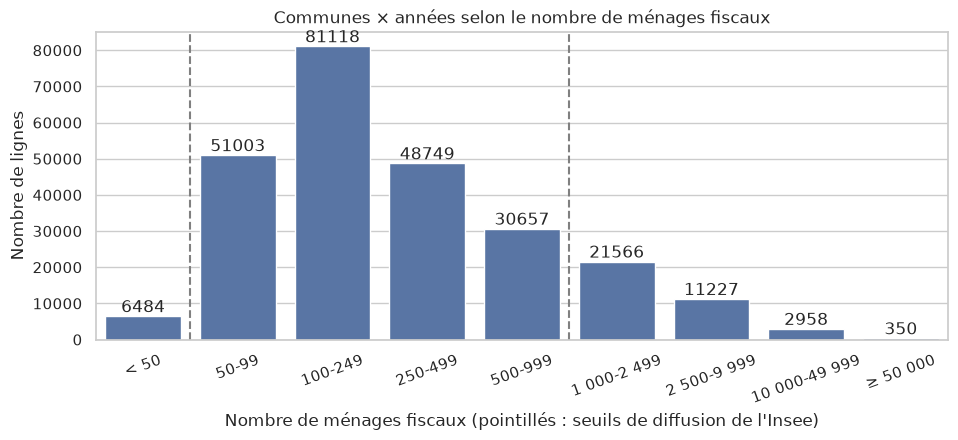

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

# Classes de plus en plus larges (logique logarithmique), en gardant les seuils Insee (50 et 1 000)
bornes = [0, 50, 100, 250, 500, 1000, 2500, 10_000, 50_000, float("inf")]
etiquettes = ["< 50", "50-99", "100-249", "250-499", "500-999",
              "1 000-2 499", "2 500-9 999", "10 000-49 999", "≥ 50 000"]

classes = pd.cut(df_num_discrete["NBMEN"], bins=bornes, labels=etiquettes, right=False)

fig, ax = plt.subplots(figsize=(11, 4))
sns.countplot(x=classes, ax=ax)
ax.bar_label(ax.containers[0])
ax.axvline(0.5, color="grey", ls="--")   # seuil de 50 ménages
ax.axvline(4.5, color="grey", ls="--")   # seuil de 1 000 ménages
ax.set_title("Communes × années selon le nombre de ménages fiscaux")
ax.set_xlabel("Nombre de ménages fiscaux (pointillés : seuils de diffusion de l'Insee)")
ax.set_ylabel("Nombre de lignes")
ax.tick_params(axis="x", rotation=20)
plt.show()

In [81]:
df_num_quanti.describe().T

,count,mean,std,min,25%,50%,75%,max
NBPERS,254112.0,2110.074865,15108.282799,74.000000,249.000000,523.000000,1268.000000,2.113228e+06
NBUC,254112.0,1448.706849,10772.384323,61.100000,169.600000,353.200000,855.400000,1.510801e+06
D1,42402.0,12703.124228,2107.883196,5480.400000,11172.371795,12695.166667,14153.189655,2.227000e+04
D2,42402.0,15677.321280,2549.302979,7207.000000,13900.000000,15590.000000,17340.000000,2.942000e+04
D3,42402.0,18008.365283,2907.058980,8460.400000,16030.000000,17850.000000,19768.048387,3.749000e+04
D4,42402.0,20135.558078,3269.273494,9588.000000,18000.000000,19831.666667,21900.000000,4.519000e+04
Q1,42402.0,16883.981361,2734.516511,7846.250000,14994.850000,16763.458075,18620.000000,3.300000e+04
niveau_vie_median,254112.0,21596.921833,3150.176027,9958.300000,19570.000000,21170.000000,23120.000000,5.534000e+04
Q3,42402.0,28924.599600,5579.870915,15265.714286,25430.000000,27750.000000,31037.821429,8.053000e+04
D6,42402.0,24539.589673,4278.255389,12376.190476,21793.857143,23800.000000,26440.000000,6.206000e+04


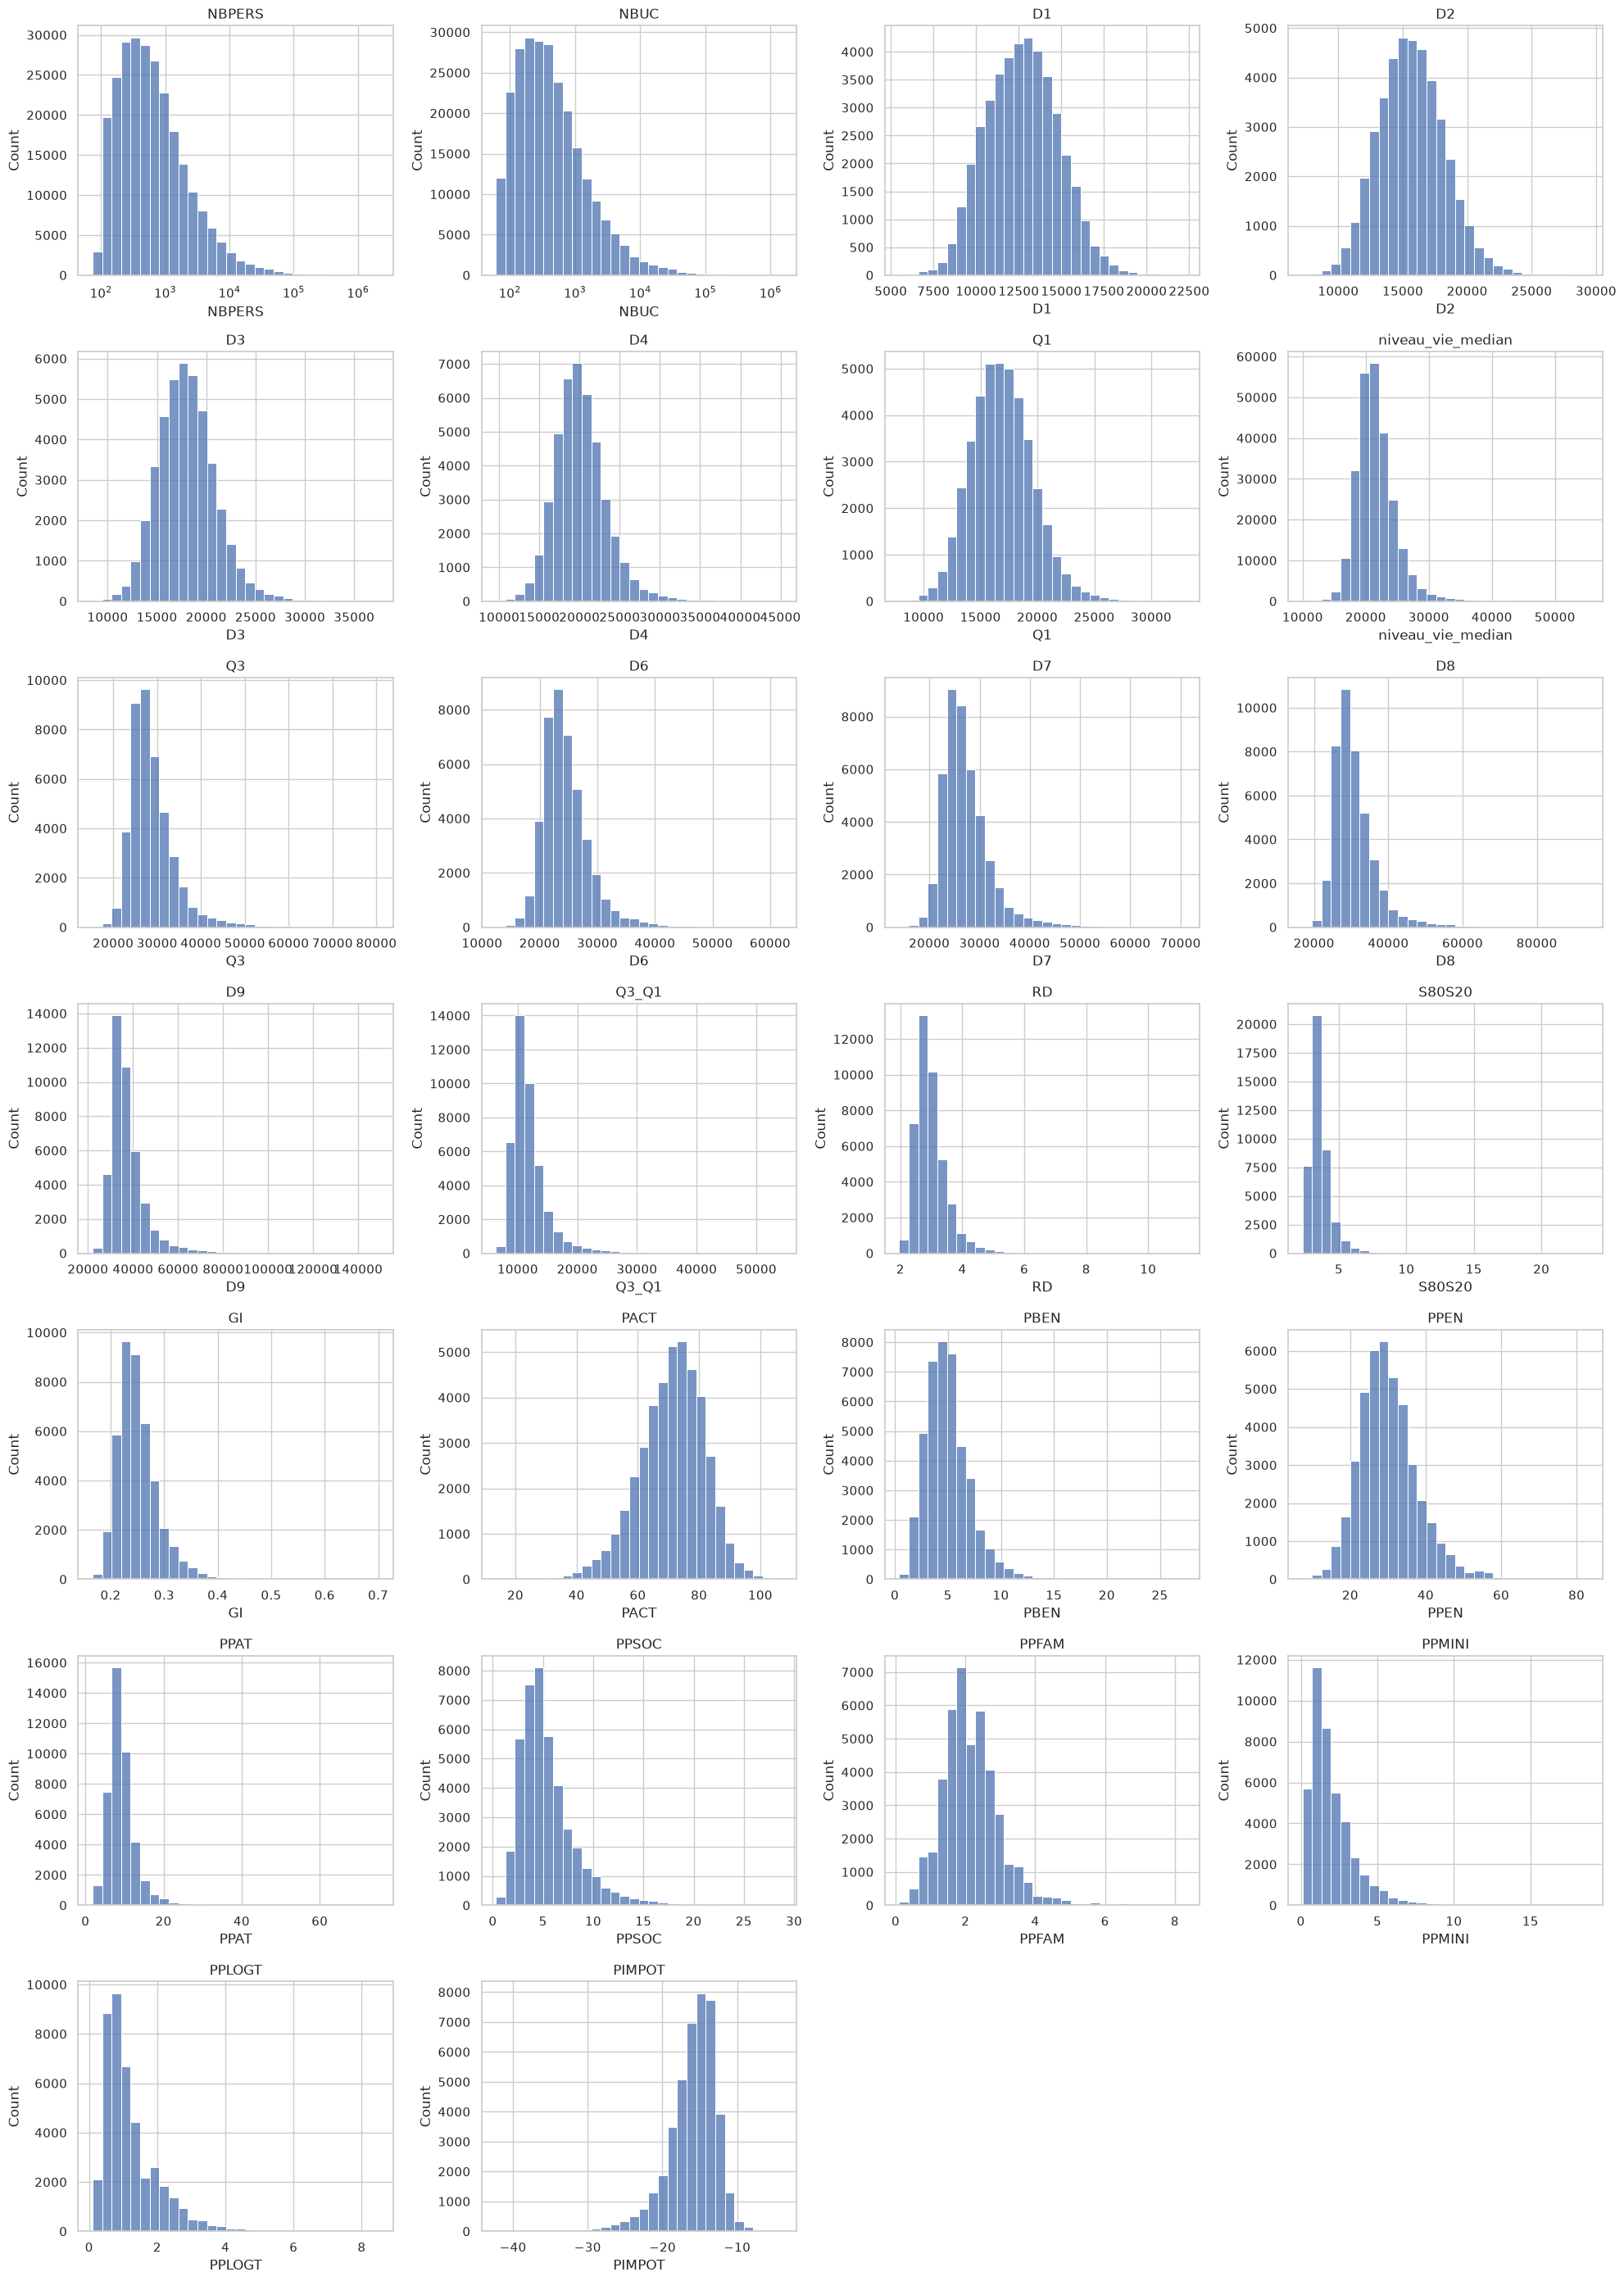

In [82]:
# Histogrammes des 26 variables continues (grille 7 × 4 = 28 cases)
fig, axes = plt.subplots(7, 4, figsize=(20, 28))
axes = axes.flatten()

for i, col in enumerate(df_num_quanti.columns):
    sns.histplot(
        data=df_num_quanti,
        x=col,
        bins=30,
        ax=axes[i],
        log_scale=(col in ["NBPERS", "NBUC"]),   # très asymétriques : échelle logarithmique
    )
    axes[i].set_title(col)

# Les 2 cases en trop restent vides
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

**Constat :**

*Variable discrète.* 

Les communes de 50 à 999 ménages représentent 83 % des lignes (211 527) ; 36 101 lignes comptent au moins 1 000 ménages et 6 484 moins de 50. Le nombre de lignes avec indicateurs détaillés (42 402) dépasse celui des communes d'au moins 1 000 ménages : la règle de diffusion porte sur 1 000 ménages **ou** 2 000 personnes.
La classe la plus fréquente est 100 à 249 ménages (81 118 lignes, environ 32 %) : la France est d'abord un pays de petites communes. Seules 350 lignes dépassent 50 000 ménages, soit une quarantaine de communes par an : les grandes villes, dont Paris, Lyon et Marseille, comptées à la fois en commune entière et par arrondissement

*Variables continues.*
- **Taille** (`NBPERS`, `NBUC`, en échelle logarithmique) : une majorité de petites communes (quelques centaines d'habitants) et quelques très grandes.
- **Niveau de vie** : la médiane se concentre entre 18 000 et 25 000 €, avec une queue vers la droite jusqu'à 55 000 €. D1 est presque symétrique, mais la queue à droite s'allonge à mesure qu'on monte dans les déciles (D9 jusqu'à 149 000 €) : les écarts entre communes se font surtout par le haut de la distribution.
- **Inégalités** (`Q3_Q1`, `RD`, `S80S20`, `GI`) : distributions très asymétriques à droite. La plupart des communes sont proches de la valeur centrale (Gini autour de 0,24), et quelques-unes sont très inégalitaires (Gini jusqu'à 0,70).
- **Composition du revenu** : `PACT` est asymétrique à gauche (des communes où les revenus d'activité pèsent peu) ; `PPEN` (jusqu'à 80 %) et `PPAT` (jusqu'à 75 %) ont des queues à droite, qui signalent des communes de retraités ou de patrimoine ; les prestations sociales (`PPSOC`, `PPMINI`, `PPLOGT`) ont des queues à droite, qui signalent des communes modestes ; `PIMPOT` s'étire vers les valeurs très négatives (communes aisées, plus imposées). L'histogramme de `PPFAM` est irrégulier (« en peigne ») parce que les parts sont arrondies à 0,1 point.

**Impact projet :**
- Les histogrammes des indicateurs détaillés ne portent que sur les communes les plus peuplées (environ 5 300 par an), pas sur la même population que la médiane : on ne peut pas les comparer directement.
- Plusieurs variables très asymétriques pourraient nécessiter une transformation (logarithme) en modélisation.

**Action envisagée :** identifier les communes situées dans les queues de distribution pour distinguer cas réels et erreurs (étape des valeurs extrêmes).

## C. Qualité

### 5.Doublons

**Objectif :** repérer les lignes copiées, qui gonflent les effectifs.

In [83]:
# 1. Doublons sur la clé commune × année
print("Doublons commune × année :", filo.duplicated(subset=["code_commune", "annee"]).sum())

# 2. Paris, Lyon, Marseille : commune entière vs somme des arrondissements
plm = {
    "Paris":     ("75056", "751"),   # code commune, début des codes d'arrondissement
    "Lyon":      ("69123", "6938"),
    "Marseille": ("13055", "132"),
}
f21 = filo[filo["annee"] == 2021]
for ville, (code, prefixe) in plm.items():
    commune = f21.loc[f21["code_commune"] == code, "NBMEN"].sum()
    arrond = f21[f21["code_commune"].str.startswith(prefixe)]
    print(f"{ville} 2021 | commune : {commune:,.0f} ménages | "
          f"{len(arrond)} arrondissements : {arrond['NBMEN'].sum():,.0f} ménages")

Doublons commune × année : 0
Paris 2021 | commune : 1,007,247 ménages | 20 arrondissements : 1,007,247 ménages
Lyon 2021 | commune : 230,041 ménages | 9 arrondissements : 230,041 ménages
Marseille 2021 | commune : 363,023 ménages | 16 arrondissements : 363,023 ménages


In [84]:
# Codes utilisés par DVF+ pour Paris, Lyon et Marseille
for dep in ["75", "69", "13"]:
    codes = pd.read_parquet(DATA_OUT / "dvf_plus_residentiel.parquet", columns=["l_codinsee"],
                            filters=[("coddep", "==", dep)])["l_codinsee"]
    ville = codes[codes.str.match(r"^(751|6938|132|75056|69123|13055)")]
    print(dep, sorted(ville.unique())[:5], "...", ville.nunique(), "codes")

75 ['75101', '75102', '75103', '75104', '75105'] ... 20 codes
69 ['69381', '69382', '69383', '69384', '69385'] ... 9 codes
13 ['13201', '13202', '13203', '13204', '13205'] ... 16 codes


**Constat :**

Aucun doublon exact et aucun doublon sur la clé commune × année.

En revanche, Paris, Lyon et Marseille sont présentes à deux niveaux : la commune entière (75056, 69123, 13055) et ses arrondissements (20, 9 et 16). Le nombre de ménages de la commune est exactement égal à la somme de ses arrondissements (en 2021 : 1 007 247 pour Paris, 230 041 pour Lyon, 363 023 pour Marseille). Les deux niveaux décrivent donc la même population : ce sont des doublons métier.

**Impact projet :** garder les deux niveaux compterait deux fois ces ménages et fausserait toute statistique nationale.

**Action envisagée :** DVF+ utilise les codes d'arrondissement (75101 à 75120, 69381 à 69389, 13201 à 13216). On garde donc les arrondissements et on retire les trois communes entières (75056, 69123, 13055) avant la jointure. À vérifier : le niveau utilisé par la table de passage commune → bassin de vie.

### 6. Valeurs manquantes

**Objectif :** mesurer l'ampleur des manquants par variable.

In [85]:
# Vérification des quantités de valeurs manquantes dans le dataset
missing = (filo.isna().mean() * 100).round(2)
missing = missing[missing > 0].sort_values(ascending=False)

display(missing)

D1                   83.77
D2                   83.77
D3                   83.77
D4                   83.77
D6                   83.77
D7                   83.77
D8                   83.77
D9                   83.77
GI                   83.77
PBEN                 83.77
PACT                 83.77
RD                   83.77
PPSOC                83.77
PIMPOT               83.77
PPAT                 83.77
PPFAM                83.77
PPEN                 83.77
PPLOGT               83.77
PPMINI               83.77
S80S20               83.77
Q3_Q1                83.77
Q1                   83.77
Q3                   83.77
NBPERS                2.76
NBMEN                 2.76
NBUC                  2.76
niveau_vie_median     2.76
dtype: float64

In [86]:
grande = (filo["NBMEN"] >= 1000) | (filo["NBPERS"] >= 2000)

display(pd.crosstab(
    grande.rename("≥ 1 000 ménages ou ≥ 2 000 personnes"),
    filo["D1"].isna().rename("D1 manquant"),
    margins=True
)
)
print("Les indicateurs détaillés manquent pour toutes les communes sous le seuil de 1 000 ménages ou 2 000 personnes, "
      "et sont publiés pour toutes les autres, à une exception près.")

D1 manquant,False,True,All
≥ 1 000 ménages ou ≥ 2 000 personnes,,,
False,0,218916,218916
True,42402,1,42403
All,42402,218917,261319


Les indicateurs détaillés manquent pour toutes les communes sous le seuil de 1 000 ménages ou 2 000 personnes, et sont publiés pour toutes les autres, à une exception près.


In [87]:
# Nombre d'indicateurs détaillés vides par ligne : 0 ou 23 si le masquage se fait en bloc
detail = [c for c in df_num_quanti.columns if c not in ["NBPERS", "NBUC", "niveau_vie_median"]]
display(filo[detail].isna().sum(axis=1).value_counts())
print("Les 23 indicateurs détaillés sont publiés ou masqués ensemble, jamais séparément.")

23    218917
0      42402
Name: count, dtype: int64

Les 23 indicateurs détaillés sont publiés ou masqués ensemble, jamais séparément.


**Constat :**

Les valeurs manquantes s'expliquent entièrement par le secret statistique de l'Insee :
- **médiane et effectifs** (`NBMEN`, `NBPERS`, `NBUC`, `niveau_vie_median`) : 2,76 % de manquants, uniquement sur les communes sous le seuil minimal, présentes vides dans les fichiers 2020 et 2021 ;
- **23 indicateurs détaillés** (déciles, quartiles, inégalités, composition du revenu) : 83,77 % de manquants. Ils sont publiés en bloc (0 ou 23 vides par ligne), pour toutes les communes d'au moins 1 000 ménages ou 2 000 personnes (une seule exception), et pour aucune autre.

Les manquants dépendent donc de la taille de la commune, une variable observée : mécanisme **MAR**.

**Impact projet :** la médiane couvre presque toutes les communes ; les indicateurs détaillés ne décrivent que les grandes communes et ne peuvent pas être imputés de façon fiable pour les autres.

**Action envisagée :** retenir la médiane comme indicateur principal de revenu ; décider en groupe de l'usage des indicateurs détaillés.

### 7 Distributions et valeurs extrêmes

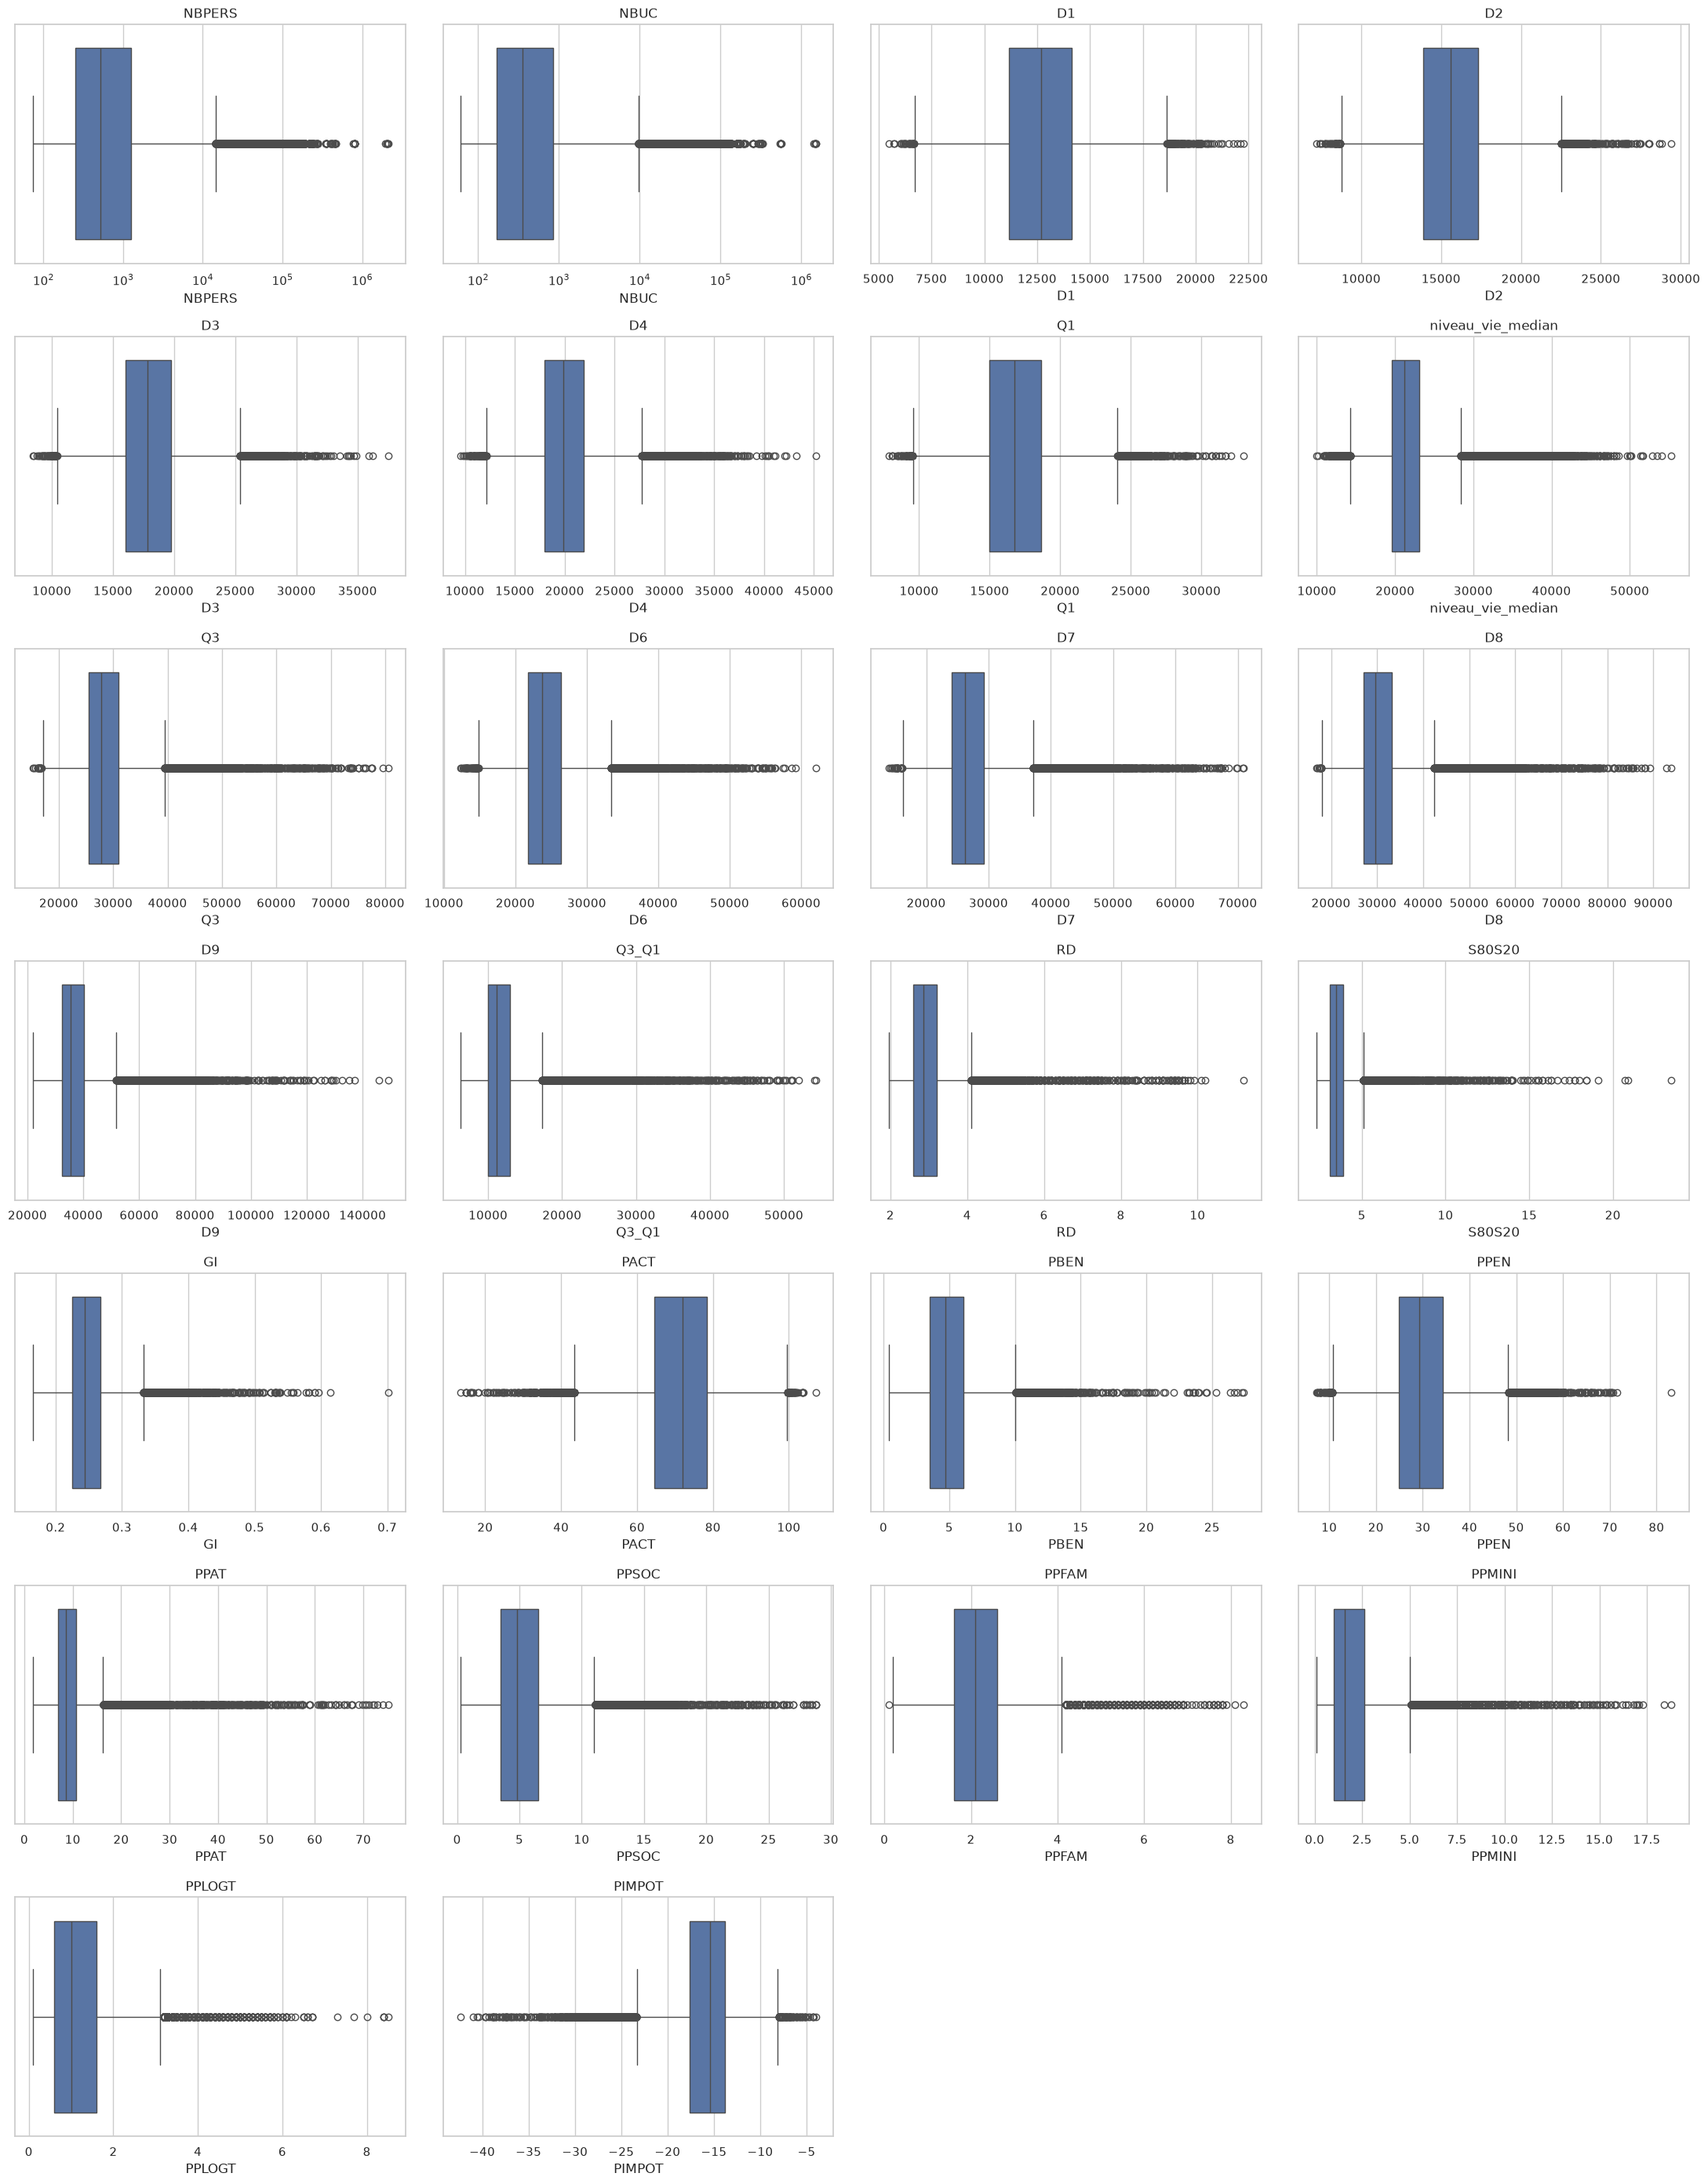

In [88]:
fig, axes = plt.subplots(7, 4, figsize=(22, 28))
axes = axes.flatten()

for i, col in enumerate(df_num_quanti.columns):
    sns.boxplot(
        data=df_num_quanti,
        x=col,
        ax=axes[i],
        log_scale=(col in ["NBPERS", "NBUC"]),
    )
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [89]:
# Position des valeurs extrêmes : comparaison du 99e centile et du maximum
quantiles = df_num_quanti.describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).T.round(2)
quantiles["max / p99"] = (quantiles["max"] / quantiles["99%"]).round(2)

display(quantiles[["min", "1%", "5%", "50%", "95%", "99%", "max", "max / p99"]])

,min,1%,5%,50%,95%,99%,max,max / p99
NBPERS,74.00,104.00,125.00,523.00,6616.45,28877.41,2113228.50,73.18
NBUC,61.10,72.00,86.60,353.20,4500.04,19548.50,1510801.25,77.28
D1,5480.40,8280.00,9360.00,12695.17,16179.73,17700.00,22270.00,1.26
D2,7207.00,10259.45,11710.00,15590.00,19960.00,22110.00,29420.00,1.33
D3,8460.40,11925.62,13610.00,17850.00,22930.00,26089.90,37490.00,1.44
D4,9588.00,13559.21,15460.00,19831.67,25760.00,30350.00,45190.00,1.49
Q1,7846.25,11096.91,12690.00,16763.46,21480.00,24140.00,33000.00,1.37
niveau_vie_median,9958.30,15824.03,17450.00,21170.00,27030.00,32240.00,55340.00,1.72
Q3,15265.71,20708.67,22820.00,27750.00,38563.80,50339.91,80530.00,1.60
D6,12376.19,17210.10,19360.00,23800.00,31960.00,39659.90,62060.00,1.56


In [90]:
# Les communes aux valeurs les plus isolées sont-elles les mêmes ?
cols_vue = ["code_commune", "annee", "NBMEN", "niveau_vie_median", "D9", "GI", "S80S20", "PPAT", "PIMPOT"]
display(filo.sort_values("S80S20", ascending=False)[cols_vue].head(30))

,code_commune,annee,NBMEN,niveau_vie_median,D9,GI,S80S20,PPAT,PIMPOT
226530,01160,2021,3704.0,27220.000000,73920.000000,0.581000,23.500000,5.4,-15.1
255681,75106,2021,16896.0,41750.000000,126350.000000,0.596000,20.900000,44.6,-35.8
255682,75107,2021,23791.0,45380.000000,149080.000000,0.591000,20.700000,43.2,-38.8
154796,75107,2018,24129.0,44490.000000,145730.000000,0.582000,19.100000,44.2,-42.3
123382,75107,2017,24290.0,43270.000000,132690.000000,0.577000,18.408000,33.2,-38.8
220752,75107,2020,24210.0,44110.000000,135220.000000,0.565000,18.400000,41.1,-40.4
255683,75108,2021,17615.0,44100.000000,130390.000000,0.557000,18.000000,35.7,-37.2
255691,75116,2021,74142.0,41550.000000,119190.000000,0.549000,17.700000,38.7,-35.5
224316,85284,2020,2109.0,22600.000000,35440.000000,0.701000,17.700000,4.4,-11.3
186153,75107,2019,24228.0,44400.000000,137020.000000,0.558000,17.400000,42.2,-41.0


In [91]:
# Série complète des deux communes suspectes
for code in ["01160", "85284"]:
    print(f"=== {code} ===")
    display(filo[filo["code_commune"] == code]
            [["annee", "NBMEN", "D1", "niveau_vie_median", "D9", "GI", "S80S20", "PBEN", "PPAT"]])

=== 01160 ===


,annee,NBMEN,D1,niveau_vie_median,D9,GI,S80S20,PBEN,PPAT
143,2014,3192.0,6680.000000,25135.333333,65116.666667,0.429955,12.561307,1.7,10.4
33115,2015,3278.0,6806.111111,25595.555556,67490.666667,0.440434,12.910957,1.6,10.6
65367,2016,3121.0,7311.500000,26579.333333,70676.923077,0.431709,12.536053,1.5,9.5
97156,2017,3158.0,7090.000000,26280.000000,68090.000000,0.431000,12.585000,1.5,9.7
128895,2018,3181.0,7530.000000,27650.000000,68910.000000,0.429000,12.000000,1.6,10.5
160225,2019,3535.0,7560.000000,26770.000000,70080.000000,0.444000,13.400000,1.6,9.0
191591,2020,3676.0,7060.000000,26970.000000,71260.000000,0.438000,13.200000,2.3,8.3
226530,2021,3704.0,6580.000000,27220.000000,73920.000000,0.581000,23.500000,1.2,5.4


=== 85284 ===


,annee,NBMEN,D1,niveau_vie_median,D9,GI,S80S20,PBEN,PPAT
30991,2014,1883.0,12208.0,20142.000000,33380.0,0.247484,3.431583,5.8,14.4
63272,2015,1915.0,12578.4,20566.833333,34986.0,0.250438,3.471669,6.9,14.6
95081,2016,1929.0,13068.0,21173.333333,34699.0,0.243418,3.336099,6.3,13.8
126824,2017,1961.0,12920.0,21420.000000,35980.0,0.245000,3.395000,6.2,12.9
158176,2018,2002.0,13290.0,21820.000000,36520.0,0.247000,3.400000,6.0,13.6
189538,2019,2033.0,13690.0,21970.000000,36120.0,0.249000,3.400000,5.8,13.7
224316,2020,2109.0,14290.0,22600.000000,35440.0,0.701000,17.700000,2.0,4.4
259246,2021,2139.0,14560.0,23260.000000,36640.0,0.259000,3.500000,5.3,14.1


**Constat :**

Les boîtes à moustaches signalent beaucoup de points au-delà des moustaches, ce qui est attendu sur 260 000 lignes et des distributions asymétriques. Le rapport entre le maximum et le 99e centile montre que la plupart des variables n'ont pas de valeur isolée (rapport de 1,1 à 1,7).

Les valeurs vraiment isolées sont de deux types :
- **des communes très aisées, cohérentes sur tous leurs indicateurs** : Paris 6e, 7e, 8e et 16e (D9 jusqu'à 149 000 €, revenus du patrimoine à 35-45 %, impôts jusqu'à −42 %), stables d'une année sur l'autre. Ce sont des cas réels ;
- **des pics ponctuels sur une seule année** : en 85284 (2020), le Gini passe de 0,25 à 0,70 et le S80/S20 de 3,4 à 17,7, puis reviennent à la normale l'année suivante, alors que D1, la médiane et D9 ne bougent pas. Un revenu exceptionnel perçu par un seul ménage suffit à faire exploser les indicateurs calculés sur des masses de revenus (Gini, S80/S20), sans modifier les déciles. Le même phénomène apparaît en 01160 en 2021, commune déjà très inégalitaire les autres années.

**Impact projet :** la médiane et les déciles sont robustes ; le Gini et le S80/S20 sont sensibles à un seul revenu exceptionnel dans les communes moyennes.

**Action envisagée :** aucune suppression à ce stade (données administratives, cas réels) ; privilégier la médiane et les déciles ; si le Gini ou le S80/S20 sont retenus, envisager un lissage sur plusieurs années.

## Synthèse du premier niveau d'audit — Filosofi

#### Constat

La base Filosofi constitue une source pertinente pour décrire le revenu des habitants des communes. Produite par l'Insee à partir des déclarations fiscales et des prestations sociales, elle est administrative et exhaustive : elle ne repose ni sur une enquête ni sur des déclarations volontaires.

Les huit fichiers annuels (2014 à 2021) ont été assemblés en une seule base de **261 319 lignes (une commune × une année) et 29 variables**, en ne gardant que les variables présentes toutes les années. La part des revenus d'activité (`PACT`), absente en 2014, a été reconstruite à partir de deux autres variables, après vérification sur 2015.

L'examen de la base montre une qualité satisfaisante. Aucun doublon exact ni sur la clé commune × année n'a été détecté, et les valeurs sont cohérentes entre elles : les déciles sont bien ordonnés, les sous-parts des prestations sociales s'additionnent correctement et les impôts sont toujours négatifs.

Les valeurs manquantes s'expliquent entièrement par le **secret statistique** :
- la **médiane du niveau de vie** est disponible pour 31 300 à 33 000 communes par an, soit presque toutes ;
- les **23 indicateurs détaillés** (déciles, inégalités, composition du revenu) ne sont publiés que pour les communes d'au moins 1 000 ménages ou 2 000 personnes, soit environ 5 300 communes par an (16 % des lignes).

Les valeurs extrêmes correspondent surtout à des cas réels, comme les arrondissements les plus aisés de Paris. Quelques pics ponctuels du Gini et du S80/S20 montrent que ces deux indicateurs peuvent être perturbés par un seul revenu exceptionnel dans une commune moyenne, alors que la médiane et les déciles restent stables.

**Ce premier audit permet donc de retenir Filosofi comme source de variables explicatives**, avec trois limites :
- elle décrit les **habitants** d'une commune, pas les acheteurs de l'année ;
- les indicateurs détaillés ne couvrent que les grandes communes ;
- 2021 est le dernier millésime : l'Insee ne produira pas le millésime 2022.

#### Rapprochement avec DVF+

La jointure avec DVF+ se fera par le code commune (`code_commune` dans Filosofi, `l_codinsee` dans DVF+) et l'année. Trois points devront être réglés auparavant :
- **Paris, Lyon et Marseille** sont présents à la fois en commune entière et par arrondissement, avec exactement les mêmes ménages. DVF+ utilisant les codes d'arrondissement, ce sont eux qui seront conservés.
- **Les codes communes changent entre millésimes** : chaque millésime est publié dans la géographie du 1er janvier de l'année suivante, et les fusions de communes modifient les codes. Une géographie de référence commune à toute l'équipe devra être fixée.
- **Le passage au bassin de vie** : les médianes communales ne s'additionnent pas. L'Insee publie directement Filosofi par bassin de vie (bassins 2022 à partir du millésime 2020), ce qui pourrait être une alternative à explorer.

Les années 2022 à 2025 de DVF+ n'auront pas de revenu correspondant : la manière de les traiter sera décidée en modélisation, seulement si l'EDA montre un lien entre revenu et prix.

#### Décisions pour la suite

**Base retenue.** La base `filosofi_commune_2014_2021.parquet` (29 variables) est conservée telle quelle pour l'EDA. Aucune valeur n'est supprimée ni imputée.

**Paris, Lyon, Marseille.** Les arrondissements sont conservés ; les communes entières (75056, 69123, 13055) seront retirées avant la jointure.

**Variables : pistes à discuter en groupe.**
- La **médiane du niveau de vie** est l'indicateur principal : elle couvre presque toutes les communes et reste stable.
- Les **indicateurs détaillés** ne couvrent que les grandes communes. Ils ne pourront servir que sur ce sous-ensemble, ou à la maille bassin de vie. Ils ne doivent pas être imputés pour les autres communes, puisque leur absence est voulue par l'Insee.
- Le **Gini et le S80/S20** sont sensibles aux revenus exceptionnels : à privilégier, si besoin, sous forme lissée sur plusieurs années.
- Les trois effectifs (`NBMEN`, `NBPERS`, `NBUC`) portent probablement la même information : leur redondance sera vérifiée en EDA.

**Contrôles à venir.** L'EDA portera sur le lien entre le revenu des communes et le prix au m², sur les années communes aux deux sources (2014-2021).

À ce stade, aucun nettoyage n'est engagé. L'audit fournit une connaissance suffisante de la structure, du contenu et des limites de la base pour passer à l'EDA.

# 4. Ménages (recensement 2022)

**Contributeurs :** Gabrielle RICHERT · **Date :** 16/10/2026

Source : `base-ic-couples-familles-menages-2022.CSV` (Insee, base infracommunale à l'IRIS) et son dictionnaire des variables.

### Définition IRIS

**IRIS (Îlots Regroupés pour l'Information Statistique)** est l'unité territoriale fondamentale utilisée par l'Insee pour diffuser des données statistiques à une échelle infra-communale.

Ce découpage concerne principalement les communes de plus de 10 000 habitants et la plupart de celles de 5 000 à 10 000 habitants. L'objectif principal est de fournir des zones géographiques homogènes d'environ 2 000 habitants (généralement entre 1 800 et 5 000).

**Types d'IRIS** :

- d'habitat /H, représente environ 92 % des IRIS. Il regroupe une population résidente (entre 1 800 et 5 000 habitants) dans un quartier présentant une homogénéité en matière de logements et de cadre de vie.
- d'activité/A, zone à vocation économique ou industrielle. Il rassemble au moins 1 000 salariés et compte au moins deux fois plus d'emplois salariés que de résidents.
- divers /D, zones spécifiques de grande superficie mais très peu habitées. Il s'agit généralement de forêts, parcs de loisirs, zones portuaires, emprises militaires ou grands espaces naturels (ex. le Parc de la Tête d'Or à Lyon).
- commune non découpée/Z, s'applique aux communes de taille plus modeste dont le territoire n'a pas été divisé en sous-quartiers. La commune entière est alors assimilée à un seul IRIS.

### 1. Situer la source et ouvrir les données

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | INSEE 2022 via l'IRIS | Recensement de la population, base infracommunale 2022 |
| Finalité initiale | Recensement |
| Mode de collecte | Recensement de la population | |
| Extraction / mise à jour | données de 2022 diffusées selon la géographie en vigueur au 1er janvier 2024 |  |
| Documentation / licence | https://www.insee.fr/fr/statistiques/8647008#consulter | |
| Population / objets annoncés | population française recensée en 2022 | |
| Période / territoire, si pertinents | France hors Mayotte, 2022 | |

In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [93]:
menages = pd.read_csv(DATA_RAW / "base-ic-couples-familles-menages-2022_csv" / "base-ic-couples-familles-menages-2022.CSV",
                      sep=";", dtype={"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str})
menages.head(10)

,IRIS,COM,TYP_IRIS,LAB_IRIS,C22_MEN,C22_MENPSEUL,C22_MENHSEUL,C22_MENFSEUL,C22_MENSFAM,C22_MENFAM,C22_MENCOUPSENF,C22_MENCOUPAENF,C22_MENFAMMONO,C22_PMEN,C22_PMEN_MENPSEUL,C22_PMEN_MENHSEUL,C22_PMEN_MENFSEUL,C22_PMEN_MENSFAM,C22_PMEN_MENFAM,C22_PMEN_MENCOUPSENF,C22_PMEN_MENCOUPAENF,C22_PMEN_MENFAMMONO,P22_POP15P,P22_POP1524,P22_POP2554,P22_POP5579,P22_POP80P,P22_POPMEN15P,P22_POPMEN1524,P22_POPMEN2554,P22_POPMEN5579,P22_POPMEN80P,P22_POP15P_PSEUL,P22_POP1524_PSEUL,P22_POP2554_PSEUL,P22_POP5579_PSEUL,P22_POP80P_PSEUL,P22_POP15P_MARIEE,P22_POP15P_PACSEE,P22_POP15P_CONCUB_UNION_LIBRE,P22_POP15P_VEUFS,P22_POP15P_DIVORCEE,P22_POP15P_CELIBATAIRE,C22_MEN_STAT_GSEC11_21,C22_MEN_STAT_GSEC12_22,C22_MEN_STAT_GSEC13_23,C22_MEN_STAT_GSEC14_24,C22_MEN_STAT_GSEC15_25,C22_MEN_STAT_GSEC16_26,C22_MEN_STAT_GSEC32,C22_MEN_STAT_GSEC40,C22_PMEN_STAT_GSEC11_21,C22_PMEN_STAT_GSEC12_22,C22_PMEN_STAT_GSEC13_23,C22_PMEN_STAT_GSEC14_24,C22_PMEN_STAT_GSEC15_25,C22_PMEN_STAT_GSEC16_26,C22_PMEN_STAT_GSEC32,C22_PMEN_STAT_GSEC40,C22_FAM,C22_COUPAENF,C22_FAMMONO,C22_COUPSENF,C22_NE24F0,C22_NE24F1,C22_NE24F2,C22_NE24F3,C22_NE24F4P,C22_MEN-FAM,C22_MEN1FCOUPSENF,C22_MEN1FCOUPUNIQENFCOUP,C22_MEN1FCOUPENF1ADUL,C22_MEN1FMONO,C22_PMENFAM,C22_PMEN1FCOUPSENF,C22_PMEN1FCOUPUNIQENFCOUP,C22_PMEN1FCOUPENF1ADUL,C22_PMEN1FMONO,C22_FAMTRAD,C22_FAMRECOMP
0,010010000,01001,Z,5,353.417143,73.628571,44.177143,29.451429,9.817143,269.971429,117.805714,127.622857,24.542857,859.000000,73.628571,44.177143,29.451429,19.634286,765.737143,235.611429,476.131429,53.994286,697.000000,66.000000,328.000000,259.000000,44.000000,697.000000,66.000000,328.000000,259.000000,44.000000,71.000000,2.000000,21.000000,32.000000,16.000000,357.000000,55.000000,115.000000,41.000000,22.000000,107.000000,4.908571,14.725714,49.085714,58.902857,44.177143,63.811429,112.897143,4.908571,14.725714,34.360000,171.800000,137.440000,127.622857,176.708571,186.525714,9.817143,269.971429,127.622857,24.542857,117.805714,132.531429,68.720000,49.085714,14.725714,4.908571,269.971429,117.805714,103.080000,24.542857,24.542857,765.737143,235.611429,387.777143,88.354286,53.994286,103.080000,24.542857
1,010020000,01002,Z,5,119.127273,39.709091,29.781818,9.927273,0.000000,79.418182,34.745455,39.709091,4.963636,273.000000,39.709091,29.781818,9.927273,0.000000,233.290909,69.490909,148.909091,14.890909,216.000000,25.000000,115.000000,58.000000,18.000000,216.000000,25.000000,115.000000,58.000000,18.000000,42.000000,1.000000,16.000000,20.000000,5.000000,103.000000,24.000000,21.000000,7.000000,16.000000,45.000000,9.927273,4.963636,14.890909,14.890909,4.963636,19.854545,49.636364,0.000000,39.709091,19.854545,34.745455,24.818182,9.927273,69.490909,74.454545,0.000000,79.418182,39.709091,4.963636,34.745455,34.745455,14.890909,24.818182,4.963636,0.000000,79.418182,34.745455,39.709091,0.000000,4.963636,233.290909,69.490909,148.909091,0.000000,14.890909,39.709091,0.000000
2,010040101,01004,H,1,702.787532,289.265076,110.156201,179.108876,9.698603,403.823853,131.083762,225.071032,47.669059,1627.186311,289.265076,110.156201,179.108876,19.397206,1318.524029,271.008303,934.888895,112.626831,1654.637260,419.339349,752.345462,370.001418,112.951031,1347.642845,317.341204,625.347772,346.001854,58.952014,435.294725,154.466852,103.960591,139.480163,37.387119,594.131943,108.081683,112.861778,128.990890,119.912199,590.658767,0.000000,29.762747,79.957442,125.370876,119.392846,145.471875,188.712754,14.118992,0.000000,121.081845,209.897896,337.832806,270.787527,400.955630,259.580144,27.050463,412.664632,229.491421,47.669059,135.504151,163.175719,80.130129,90.965251,70.095761,8.297772,403.823853,126.663373,202.947619,17.703023,47.669059,1318.524029,253.326745,823.176441,80.769729,112.626831,211.788398,17.703023
3,010040102,01004,H,1,1777.324753,789.269399,365.956493,423.312906,19.945500,968.109854,403.134152,368.888653,196.087049,3643.284328,789.269399,365.956493,423.312906,39.891001,2814.123928,806.268304,1470.683376,537.172248,3229.276355,570.945104,1518.492

#### Ouverture de meta_menages qui contient le détails des variables

In [94]:
meta_menages = pd.read_csv(DATA_RAW / "base-ic-couples-familles-menages-2022_csv" / "meta_base-ic-couples-familles-menages-2022.CSV",
                           sep=";", dtype=str)

**Impact projet :**

Les variables sont expliquées dans meta_menages, offrant une compréhension claire des différentes données.
La base fournie par l'INSEE sur les ménages pourra servir de grille de lecture structurelle à l'échelle du quartier ou de la commune.

**Incertitudes / limites, si nécessaire :**

Recensement effectué en 2022. La population et les ménages ont évolué entre 2014 et 2022 et entre 2022 et 2025. Le recensement ne pourra nous fournir que des informations sur la population à un instant T -> biais de décalage temporel des données. A noter cependant que la composition des ménages évolue généralement lentement (sauf cas de communes avec des projets d'aménagements type ZAC, éco quartiers, ...).
Attention aux zones qui ont vécu des changements rapides sur la période du DVF+, exemple si une commune a connu la livraison de logements neufs l'INSEE ne reflètera pas la nouvelle population arrivée après 2022.
On ne pourra pas reconstruire l'historique démographique à cause des révisions de maillages demandées par l'IRIS.

**Idées pour le traitement avec le DVF+**

Construction de ratios prédictifs via l'IRIS:
- pression sur le prix des petites surfaces via la part des ménages seuls,
- pression sur les logements intermédiaires et abordables via le taux de familles monoparentales,
- soutien des prix des maisons et grands appartements via la pression des ménages avec enfants,
- indice de "décohabitation", via la taille moyennes des ménages (si la taille moyenne est faible cela implique un besoin accru en nombres de logements).

### 2. Comprendre la structure et une ligne

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 49 276 lignes × 80 colonnes |
| Contenu général, en une phrase | Par IRIS, par commune, toutes les statistiques liées à la population (nombres de ménages en fonction du type de ménage, nombre de personnes seules en fonction de leur sexe, population de différentes tranches d'âges, ...) |
| Unité d'observation | un **IRIS** : ilots regroupés pour l'information statistique ; découpage territorial de l'INSEE d'environ 2 000 habitants |
| Identifiants / clés possibles | IRIS |
| Une ou plusieurs lignes par objet ? Pourquoi ? | 1 ligne par IRIS |
| Doublons exacts : nombre / proportion | 0 (0 %) |
| Répétitions métier : règle examinée / résultat | |

In [95]:
# ── 1. Dimensions, colonnes et quelques observations ───────────────────────
print(menages.shape)
menages.info()

(49276, 80)
<class 'pandas.DataFrame'>
RangeIndex: 49276 entries, 0 to 49275
Data columns (total 80 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   IRIS                           49276 non-null  str    
 1   COM                            49276 non-null  str    
 2   TYP_IRIS                       49276 non-null  str    
 3   LAB_IRIS                       49276 non-null  str    
 4   C22_MEN                        49276 non-null  float64
 5   C22_MENPSEUL                   49276 non-null  float64
 6   C22_MENHSEUL                   49276 non-null  float64
 7   C22_MENFSEUL                   49276 non-null  float64
 8   C22_MENSFAM                    49276 non-null  float64
 9   C22_MENFAM                     49276 non-null  float64
 10  C22_MENCOUPSENF                49276 non-null  float64
 11  C22_MENCOUPAENF                49276 non-null  float64
 12  C22_MENFAMMONO                 49276 non-null

In [96]:
# ── 2. Une ligne en entier, transposée pour tout voir ──────────────────────
display(menages.sample(1, random_state=0).T)

,7064
IRIS,162220000
COM,16222
TYP_IRIS,Z
LAB_IRIS,5
C22_MEN,174.754181
...,...
C22_PMEN1FCOUPUNIQENFCOUP,51.389169
C22_PMEN1FCOUPENF1ADUL,16.465725
C22_PMEN1FMONO,42.327473
C22_FAMTRAD,12.060684


In [97]:
# ── 4. Doublons exacts : lignes identiques sur toutes les colonnes ─────────
print("Doublons exacts :", menages.duplicated().sum())
print('codes IRIS en doubles :', menages['IRIS'].duplicated().sum())

Doublons exacts : 0
codes IRIS en doubles : 0


**Constat :**

Beaucoup d'informations pour un seul IRIS. Une ligne par IRIS.

**Impact projet :**

- vérifier la redondance des informations contenues dans les colonnes pour ne sélectionner que celles qui auraient un impact sur la demande de bien immobiliers.
- les données sont données par IRIS hors un IRIS est un regroupe fictuel d'une certaine zone d'environ 2000 habitants, il s'agit donc de statistiques en lien avec les communes.

**Action envisagée :**

Recouper les statistiques par IRIS en les transposant par commune et extrapoler ?

**Incertitudes / limites, si nécessaire :**

Recensement à un instant T seulement de la durée que nous allons étudier, pertinence ?

### 3. Comprendre les variables

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
IRIS | IRIS (Code du département suivi du numéro de commune ou du numéro d'arrondissement municipal suivi du numéro d'IRIS) | object / CHAR(9) | 49276 modalités | 0
COM | Commune ou ARM (Code du département suivi du numéro de commune ou du numéro d'arrondissement municipal pour Paris Lyon et Marseille) | object / CHAR(5) | 34960 modalités | 0
TYP_IRIS | Type d'Iris (Type d'Iris : habitat (H), activité (A), divers (D), Autre (Z)) | str / CHAR(1) | ['Z', 'H', 'A', 'D'] | 0
LAB_IRIS | Label de l'Iris (Label de qualité de l'Iris) | object / CHAR(1) | 10 modalités | 0
C22_MEN | Ménages en 2022 (compl) (Nombre de ménages) | float64 / NUM(17) | min = 0.0, max = 6631.82617347553 | 0
C22_MENPSEUL | Ménages 1 personne en 2022 (compl) (Nombre de ménages d'une personne) | float64 / NUM(17) | min = 0.0, max = 4575.03868336617 | 0
C22_MENHSEUL | Ménages Hommes seuls en 2022 (compl) (Nombre de ménages composés d'hommes seuls) | float64 / NUM(17) | min = 0.0, max = 2705.629788459 | 0
C22_MENFSEUL | Ménages Femmes seules en 2022 (compl) (Nombre de ménages composés de femmes seules) | float64 / NUM(17) | min = 0.0, max = 2047.81636906301 | 0
C22_MENSFAM | Ménages Autres sans famille en 2022 (compl) (Nombre de ménages autres sans famille) | float64 / NUM(17) | min = 0.0, max = 765.314946792773 | 0
C22_MENFAM | Ménages avec famille(s) en 2022 (compl) (Nombre de ménages avec famille(s)) | float64 / NUM(17) | min = 0.0, max = 3377.38612582722 | 0
C22_MENCOUPSENF | Mén fam princ Couple sans enfant en 2022 (compl) (Nombre de ménages dont la famille principale est formée d'un couple sans enfant) | float64 / NUM(17) | min = 0.0, max = 1491.49559369234 | 0
C22_MENCOUPAENF | Mén fam princ Couple avec enfant(s) en 2022 (compl) (Nombre de ménages dont la famille principale est formée d'un couple avec enfant(s)) | float64 / NUM(17) | min = 0.0, max = 1706.25049751629 | 0
C22_MENFAMMONO | Mén fam princ Famille mono en 2022 (compl) (Nombre de ménages dont la famille principale est une famille monoparentale) | float64 / NUM(17) | min = 0.0, max = 1384.43745592174 | 0
C22_PMEN | Pop Ménages en 2022 (compl) (Nombre de personnes des ménages) | float64 / NUM(16) | min = 0.0, max = 13187.2005042746 | 0
C22_PMEN_MENPSEUL | Pop mén Personnes seules en 2022 (compl) (Nombre de personnes des ménages d'une personne) | float64 / NUM(17) | min = 0.0, max = 4575.03868336617 | 0
C22_PMEN_MENHSEUL | Pop mén Hommes seuls en 2022 (compl) (Nombre de personnes des ménages composés d'hommes seuls) | float64 / NUM(17) | min = 0.0, max = 2705.629788459 | 0
C22_PMEN_MENFSEUL | Pop mén Femmes seules en 2022 (compl) (Nombre de personnes des ménages composés de femmes seules) | float64 / NUM(17) | min = 0.0, max = 2047.81636906301 | 0
C22_PMEN_MENSFAM | Pop mén Autres sans famille en 2022 (compl) (Nombre de personnes des ménages Autres sans famille) | float64 / NUM(16) | min = 0.0, max = 1546.70219572721 | 0
C22_PMEN_MENFAM | Pop mén avec famille(s) en 2022 (compl) (Nombre de personnes des ménages avec famille(s)) | float64 / NUM(16) | min = 0.0, max = 12043.4120619991 | 0
C22_PMEN_MENCOUPSENF | Pop mén fam princ Couple sans enfant en 2022 (compl) (Nombre de personnes des ménages dont la famille principale est un couple sans enfant) | float64 / NUM(16) | min = 0.0, max = 3020.83248782877 | 0
C22_PMEN_MENCOUPAENF | Pop mén fam princ Couple avec enfant(s) en 2022 (compl) (Nombre de personnes des ménages dont la famille principale est un couple avec enfant(s)) | float64 / NUM(16) | min = 0.0, max = 6793.36550514903 | 0
C22_PMEN_MENFAMMONO | Pop mén fam princ Famille mono en 2022 (compl) (Nombre de personnes des ménages dont la famille principale est une famille monoparentale) | float64 / NUM(16) | min = 0.0, max = 7266.50301537127 | 0
P22_POP15P | Pop 15 ans ou plus en 2022 (princ) (Nombre de personnes de 15 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 10535.0090883026 | 0
P22_POP1524 | Pop 15-24 ans en 2022 (princ) (Nombre de personnes de 15 à 24 ans) | float64 / NUM(17) | min = 0.0, max = 4113.75670657614 | 0
P22_POP2554 | Pop 25-54 ans en 2022 (princ) (Nombre de personnes de 25 à 54 ans) | float64 / NUM(17) | min = 0.0, max = 7131.24030958912 | 0
P22_POP5579 | Pop 55-79 ans en 2022 (princ) (Nombre de personnes de 55 à 79 ans) | float64 / NUM(17) | min = 0.0, max = 3246.0 | 0
P22_POP80P | Pop 80 ans ou plus en 2022 (princ) (Nombre de personnes de 80 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 899.936337301575 | 0
P22_POPMEN15P | Pop mén 15 ans ou plus en 2022 (princ) (Nombre de personnes des ménages de 15 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 10279.0118865108 | 0
P22_POPMEN1524 | Pop mén 15-24 ans en 2022 (princ) (Nombre de personnes des ménages de 15 à 24 ans) | float64 / NUM(17) | min = 0.0, max = 3845.57828009828 | 0
P22_POPMEN2554 | Pop mén 25-54 ans en 2022 (princ) (Nombre de personnes des ménages de 25 à 54 ans) | float64 / NUM(17) | min = 0.0, max = 6840.93909806694 | 0
P22_POPMEN5579 | Pop mén 55-79 ans en 2022 (princ) (Nombre de personnes des ménages de 55 à 79 ans) | float64 / NUM(17) | min = 0.0, max = 3178.0 | 0
P22_POPMEN80P | Pop mén 80 ans ou plus en 2022 (princ) (Nombre de personnes des ménages de 80 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 830.057074753759 | 0
P22_POP15P_PSEUL | Pop 15 ans ou plus ans vivant seule en 2022 (princ) (Nombre de personnes de 15 ans ou plus vivant seules) | float64 / NUM(17) | min = 0.0, max = 3961.45659667091 | 0
P22_POP1524_PSEUL | Pop 15-24 ans vivant seule en 2022 (princ) (Nombre de personnes de 15 à 24 ans vivant seules) | float64 / NUM(18) | min = 0.0, max = 3476.40962239896 | 0
P22_POP2554_PSEUL | Pop 25-54 ans vivant seule en 2022 (princ) (Nombre de personnes de 25 à 54 ans vivant seules) | float64 / NUM(17) | min = 0.0, max = 2259.62429202828 | 0
P22_POP5579_PSEUL | Pop 55-79 ans vivant seule en 2022 (princ) (Nombre de personnes de 55 à 79 ans vivant seules) | float64 / NUM(17) | min = 0.0, max = 1185.0 | 0
P22_POP80P_PSEUL | Pop 80 ans ou plus vivant seule en 2022 (princ) (Nombre de personnes de 80 ans ou plus vivant seules) | float64 / NUM(18) | min = 0.0, max = 483.739005300055 | 0
P22_POP15P_MARIEE | Pop 15 ans ou plus mariée en 2022 (princ) (Nombre de personnes de 15 ans ou plus mariées) | float64 / NUM(17) | min = 0.0, max = 3810.09208720427 | 0
P22_POP15P_PACSEE | Pop 15 ans ou plus pacsée en 2022 (princ) (Nombre de personnes de 15 ans ou plus pacsées) | float64 / NUM(17) | min = 0.0, max = 853.477131122718 | 0
P22_POP15P_CONCUB_UNION_LIBRE | Pop 15 ans ou plus en concubinage ou union libre en 2022 (princ) (Nombre de personnes de 15 ans ou plus en concubinage ou union libre) | float64 / NUM(17) | min = 0.0, max = 2002.59150211561 | 0
P22_POP15P_VEUFS | Pop 15 ans ou plus veuves ou veufs en 2022 (princ) (Nombre de personnes de 15 ans ou plus veuves ou veufs) | float64 / NUM(17) | min = 0.0, max = 1056.47955074845 | 0
P22_POP15P_DIVORCEE | Pop 15 ans ou plus divorcée en 2022 (princ) (Nombre de personnes de 15 ans ou plus divorcées) | float64 / NUM(17) | min = 0.0, max = 848.230682269967 | 0
P22_POP15P_CELIBATAIRE | Pop 15 ans ou plus célibataire en 2022 (princ) (Nombre de personnes de 15 ans ou plus célibataires) | float64 / NUM(17) | min = 0.0, max = 6181.06099861751 | 0
C22_MEN_STAT_GSEC11_21 | Ménages Pers Réf Agri. expl. en 2022 (compl) (Nombre de ménages dont la personne de référence est Agriculteur exploitant) | float64 / NUM(17) | min = 0.0, max = 191.289680258755 | 0
C22_MEN_STAT_GSEC12_22 | Ménages Pers Réf Art. Comm. Chef entr. en 2022 (compl) (Nombre de ménages dont la personne de référence est Artisan, Commerçant, Chef d'entreprise) | float64 / NUM(17) | min = 0.0, max = 372.643674303746 | 0
C22_MEN_STAT_GSEC13_23 | Ménages Pers Réf Cadre Prof int sup en 2022 (compl) (Nombre de ménages dont la personne de référence est Cadre ou exerce une Profession intellectuelle supérieure) | float64 / NUM(17) | min = 0.0, max = 3275.3513165677 | 0
C22_MEN_STAT_GSEC14_24 | Ménages Pers Réf Prof intermédiaire en 2022 (compl) (Nombre de ménages dont la personne de référence exerce une Profession intermédiaire) | float64 / NUM(17) | min = 0.0, max = 1553.54471003297 | 0
C22_MEN_STAT_GSEC15_25 | Ménages Pers Réf Employé en 2022 (compl) (Nombre de ménages dont la personne de référence est Employé) | float64 / NUM(17) | min = 0.0, max = 1602.23612884422 | 0
C22_MEN_STAT_GSEC16_26 | Ménages Pers Réf Ouvrier en 2022 (compl) (Nombre de ménages dont la personne de référence est Ouvrier) | float64 / NUM(17) | min = 0.0, max = 1163.46594484206 | 0
C22_MEN_STAT_GSEC32 | Ménages Pers Réf Retraité en 2022 (compl) (Nombre de ménages dont la personne de référence est Retraité) | float64 / NUM(17) | min = 0.0, max = 2022.66089108911 | 0
C22_MEN_STAT_GSEC40 | Ménages Pers Réf Autre en 2022 (compl) (Nombre de ménages dont la personne de référence est Autre sans activité professionnelle) | float64 / NUM(17) | min = 0.0, max = 3617.6186307222 | 0
C22_PMEN_STAT_GSEC11_21 | Pop mén Pers Réf Agri. expl. en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Agriculteur exploitant) | float64 / NUM(17) | min = 0.0, max = 692.188507493792 | 0
C22_PMEN_STAT_GSEC12_22 | Pop mén Pers Réf Art Com Chef entr. en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Artisan, Commerçant, Chef d'entreprise) | float64 / NUM(17) | min = 0.0, max = 1011.5620958369 | 0
C22_PMEN_STAT_GSEC13_23 | Pop mén Pers Réf Cadre Prof int sup en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Cadre ou exerce une Profession intellectuelle supérieure) | float64 / NUM(17) | min = 0.0, max = 6394.40579853238 | 0
C22_PMEN_STAT_GSEC14_24 | Pop mén Pers Réf Prof intermédiaire en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence exerce une Profession intermédiaire) | float64 / NUM(17) | min = 0.0, max = 3278.2735217937 | 0
C22_PMEN_STAT_GSEC15_25 | Pop mén Pers Réf Employé en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Employé) | float64 / NUM(17) | min = 0.0, max = 3157.2946677691 | 0
C22_PMEN_STAT_GSEC16_26 | Pop mén Pers Réf Ouvrier en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Ouvrier) | float64 / NUM(17) | min = 0.0, max = 2909.74901238553 | 0
C22_PMEN_STAT_GSEC32 | Pop mén Pers Réf Retraité en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Retraité) | float64 / NUM(17) | min = 0.0, max = 2916.62706270627 | 0
C22_PMEN_STAT_GSEC40 | Pop mén Pers Réf Autre en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Autre sans activité professionnelle) | float64 / NUM(17) | min = 0.0, max = 7456.19212347787 | 0
C22_FAM | Familles en 2022 (compl) (Nombre de familles) | float64 / NUM(17) | min = 0.0, max = 3399.88682466536 | 0
C22_COUPAENF | Fam Couple avec enfant(s) en 2022 (compl) (Nombre de familles formées d'un couple avec enfant(s)) | float64 / NUM(17) | min = 0.0, max = 1707.89503086201 | 0
C22_FAMMONO | Fam Monoparentales en 2022 (compl) (Nombre de familles monoparentales) | float64 / NUM(17) | min = 0.0, max = 1547.64207575535 | 0
C22_COUPSENF | Fam Couple sans enfant en 2022 (compl) (Nombre de familles formées d'un couple sans enfant) | float64 / NUM(17) | min = 0.0, max = 1495.3737186275 | 0
C22_NE24F0 | Fam 0 enfant moins 25 ans en 2022 (compl) (Nombre de familles avec 0 enfant de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 1589.28084908324 | 0
C22_NE24F1 | Fam 1 enfant moins 25 ans en 2022 (compl) (Nombre de familles avec 1 enfant de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 1036.48969877314 | 0
C22_NE24F2 | Fam 2 enfants moins 25 ans en 2022 (compl) (Nombre de familles avec 2 enfants de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 897.14417306429 | 0
C22_NE24F3 | Fam 3 enfants moins 25 ans en 2022 (compl) (Nombre de familles avec 3 enfants de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 469.940994340952 | 0
C22_NE24F4P | Fam 4 enfants ou plus moins 25 ans en 2022 (compl) (Nombre de familles avec 4 enfants ou plus de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 814.341136548895 | 0
C22_MEN-FAM | Ménages avec 1 famille en 2022 (compl) (Nombre de ménages avec 1 famille) | float64 / NUM(17) | min = 0.0, max = 3377.38612582722 | 0
C22_MEN1FCOUPSENF | Mén 1 fam Couple sans enfant en 2022 (compl) (Nombre de ménages d’une famille formée d'un couple sans enfant) | float64 / NUM(17) | min = 0.0, max = 1486.79333165282 | 0
C22_MEN1FCOUPUNIQENFCOUP | Mén 1 fam Couple avec uniquement enfant(s) du couple en 2022 (compl) (Nombre de ménages d’une famille formée d'un couple avec enfant(s)) | float64 / NUM(17) | min = 0.0, max = 1529.74441111723 | 0
C22_MEN1FCOUPENF1ADUL | Mén 1 fam Couple avec au moins un enfant d’un seul des 2 membres du couple en 2022 (compl) (Nombre de ménages d’une famille formée d'un couple avec uniquement enfant(s) du couple) | float64 / NUM(17) | min = 0.0, max = 314.308471769192 | 0
C22_MEN1FMONO | Mén 1 fam Monoparentale en 2022 (compl) (Nombre de ménages d’une famille monoparentale) | float64 / NUM(17) | min = 0.0, max = 1344.17677988945 | 0
C22_PMENFAM | Pop ménage d’une famille en 2022 (compl) (Population des ménages d’une famille) | float64 / NUM(16) | min = 0.0, max = 12043.4120619991 | 0
C22_PMEN1FCOUPSENF | Pop Men 1 fam Couple sans enfant en 2022 (compl) (Nombre de personnes des ménages d’une famille formée un couple sans enfant) | float64 / NUM(16) | min = 0.0, max = 2992.61891559164 | 0
C22_PMEN1FCOUPUNIQENFCOUP | Pop Men  1 fam Couple avec uniquement enfant(s) du couple en 2022 (compl) (Nombre de personnes des ménages d’une famille formée d'un couple avec uniquement enfant(s) du couple) | float64 / NUM(16) | min = 0.0, max = 6021.75323680933 | 0
C22_PMEN1FCOUPENF1ADUL | Pop Men  1 fam Couple avec au moins un enfant d’un seul des 2 membres du couple en 2022 (compl) (Nombre de personnes des ménages d’une famille formée d'un couple avec au moins un enfant d’un seul des 2 membres du couple) | float64 / NUM(16) | min = 0.0, max = 1559.24031627823 | 0
C22_PMEN1FMONO | Pop Mén 1 fam monoparentale en 2022 (compl) (Nombre de personnes des ménages d’une famille monoparentale) | float64 / NUM(16) | min = 0.0, max = 5203.68378055006 | 0
C22_FAMTRAD | Fam Couple avec uniquement enfant(s) du couple en 2022 (compl) (Nombre de familles composées d'un couple avec uniquement enfant(s) du couple) | float64 / NUM(17) | min = 0.0, max = 1549.42078778555 | 0
C22_FAMRECOMP | Fam Couple avec au moins un enfant d’un seul des 2 membres du couple en 2022 (compl) (Nombre de familles composées d'un couple avec au moins un enfant d’un seul des 2 membres du couple) | float64 / NUM(17) | min = 0.0, max = 339.434501278019 | 0

In [98]:
from pandas.api.types import is_numeric_dtype

# Liste qui va recevoir une ligne de résumé par colonne
resume = []

# On parcourt toutes les colonnes du DataFrame, une par une
for col in menages.columns:

    # Si la colonne est entièrement vide : on le signale
    if menages[col].isna().all():
        valeurs = "100 % vide"

    # Si la colonne contient des nombres : on note le min et le max
    elif is_numeric_dtype(menages[col]):
        valeurs = "min = " + str(menages[col].min()) + ", max = " + str(menages[col].max())

    # Sinon, si elle a 6 modalités ou moins : on les liste (sans les valeurs manquantes)
    elif menages[col].nunique() <= 6:
        valeurs = str(list(menages[col].dropna().unique()))

    # Sinon : on note seulement le nombre de modalités
    else:
        valeurs = str(menages[col].nunique()) + " modalités"

    # Pourcentage de valeurs manquantes, arrondi à 1 décimale
    pct_na = round(menages[col].isna().mean() * 100, 1)

    # On ajoute la ligne de résumé à la liste
    resume.append({"variable": col,
                   "type": str(menages[col].dtype),
                   "valeurs": valeurs,
                   "% NaN": pct_na})

# On transforme la liste en DataFrame, avec le nom de la variable comme index
resume = pd.DataFrame(resume).set_index("variable")
print(resume)

                              type                            valeurs  % NaN
variable                                                                    
IRIS                           str                    49276 modalités    0.0
COM                            str                    34960 modalités    0.0
TYP_IRIS                       str               ['Z', 'H', 'A', 'D']    0.0
LAB_IRIS                       str     ['5', '1', 'Z', '4', '2', '3']    0.0
C22_MEN                    float64  min = 0.0, max = 6631.82617347553    0.0
...                            ...                                ...    ...
C22_PMEN1FCOUPUNIQENFCOUP  float64  min = 0.0, max = 6021.75323680933    0.0
C22_PMEN1FCOUPENF1ADUL     float64  min = 0.0, max = 1559.24031627823    0.0
C22_PMEN1FMONO             float64  min = 0.0, max = 5203.68378055006    0.0
C22_FAMTRAD                float64  min = 0.0, max = 1549.42078778555    0.0
C22_FAMRECOMP              float64  min = 0.0, max = 339.434501278019    0.0

**Constat :**

Aucune valeurs manquantes dans le fichier, certaines variables peuvent être redondantes, exemple couple sans enfants est détaillé par tranches d'âge.

**Impact projet :**

On ne pourra pas traiter donc il faut dors et déjà regrouper les variables intéressantes.

**Action envisagée :**

Créer les 4 ratios évoqués précédemment :
- pression sur le prix des petites surfaces via la part des ménages seuls,
- pression sur les logements intermédiaires et abordables via le taux de familles monoparentales,
- soutien des prix des maisons et grands appartements via la pression des ménages avec enfants,
- indice de "décohabitation", via la taille moyennes des ménages (si la taille moyenne est faible cela implique un besoin accru en nombres de logements).

**Incertitudes / limites, si nécessaire :**

Recensement en 2022.

### 4. Vérifier le périmètre réel

| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| **Périmètre spatial / Géographique** | Niveaux IRIS (`IRIS`), Communes (`COM`), Types d'IRIS (`TYP_IRIS`) | 49 276 lignes (IRIS / zones géographiques en France) | Couverture limitée aux zones découpées en IRIS (ou communes fusionnées), excluant certains territoires spécifiques non IRISés |
| **Périmètre temporel** | Millésime 2022 | Données issues du recensement de la population Insee 2022 (`C22_...`, `P22_...`) | Photo fixe à l'année 2022 (aucune donnée historique longitudinale directe dans ce fichier) |
| **Thématique / Structuration des ménages** | Ménages, personnes des ménages, structures familiales (couples, familles monoparentales, personnes seules, typologies de familles) | 80 variables numériques au total (ex. `C22_MEN`, `C22_FAM`, `P22_POP15P`, `C22_MENFAMMONO`) | Redressements statistiques / pondérations (valeurs décimales dues au secret statistique et à l'échantillonnage Insee) |
| **Thématique / Statut socio-économique** | Catégories socioprofessionnelles (GSEC) de la personne de référence du ménage | 16 variables dédiées aux PCS/GSEC (`C22_MEN_STAT_GSEC11_21` à `GSEC40` et déclinaison en individus) | Regroupements synthétiques des catégories socioprofessionnelles, sans détail des professions individuelles fines |

**Constat :**

Le fichier met en lumière une transformation structurelle majeure de la demande résidentielle en France :

- Aptérisation et réduction de la taille des ménages : Les ménages d'une seule personne représentent 38,6 % du total des ménages (11,92 millions de foyers), tandis que les familles monoparentales en constituent 10,1 % (3,13 millions).
- Poids modéré des familles traditionnelles : Les couples avec enfant(s) ne représentent plus que 23,9 % de la totalité des ménages.

Conséquence directe : Près d'un foyer sur deux (48,7 %) est composé d'une personne seule ou d'une famille monoparentale, générant une demande accrue pour des logements de petite et moyenne surface (T1, T2, T3).

**Impact projet :**

Tension accrue et maintien des prix sur les petites surfaces (T1/T2/T3)
La hausse structurelle du nombre de ménages (due aux divorces, au vieillissement et aux décohabitations) crée un besoin incompressible en logements individuels. Les prix des T1/T2/T3 en milieu urbain résisteront davantage à la baisse et connaîtront une valorisation supérieure sur le moyen/long terme.

Pression sur l'accessibilité financière (Capacité d'emprunt)
Un ménage composé d'une seule personne dispose d'un pouvoir d'achat immobilier bridé par un mono-revenu. L'augmentation des prix au mètre carré sur les petits logements réduit la surface moyenne financièrement accessible par foyer.

Inadéquation du parc de logements grands formats (T5+)
La sous-occupation des grands logements par des personnes seules âgées ou des couples sans enfant (25,7 % des ménages) entraîne une décorrélation entre l'offre existante et la demande réelle des nouveaux ménages.

**Actions envisageables :**

Reconfiguration et découpe patrimoniale (Marché privé / Promoteurs)
Structurer les projets d'aménagement ou de rénovation vers la division de grands logements (T4/T5) en typologies plus petites (T2/T3) adaptées aux ménages mono-personnels ou monoparentaux.

Développement d'offres de logement hybrides
Favoriser les projets de coliving ou de résidences services (étudiants, jeunes actifs, seniors) pour répondre à la demande de petites surfaces tout en mutualisant les coûts et les espaces communs.

Ciblage des investissements locatifs
Orienter les stratégies d'investissement vers les typologies T2 et T3 optimisés (avec une chambre modulable pour garde alternée dans le cas des familles monoparentales), qui présentent le risque de vacance locative le plus faible.

**Incertitudes / limites, si nécessaire :**

Limites méthodologiques déjà évoquées : secret statistique, temporalité figée, couverture infra-communales variable.

Une forte proportion de ménages d'une personne dans un IRIS peut être corrélée à des prix élevés (zones tendues hyper-urbaines), mais la structure démographique seule ne suffit pas à expliquer les fluctuations futures du marché.

### 5. Visualisations graphiques

#### Structure globale des ménages

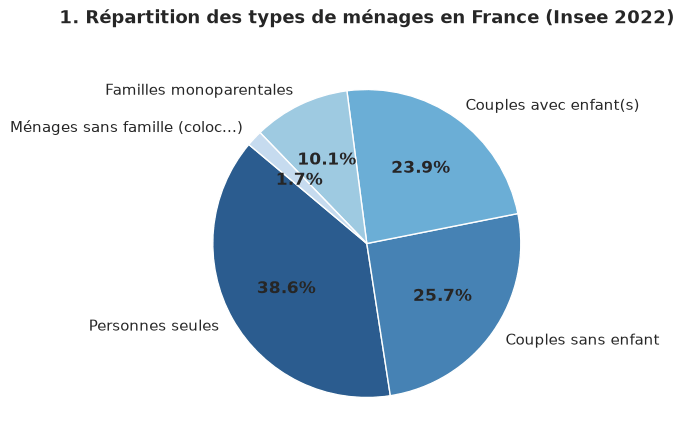

In [99]:
menages_types = {
    'Personnes seules': menages['C22_MENPSEUL'].sum(),
    'Couples sans enfant': menages['C22_MENCOUPSENF'].sum(),
    'Couples avec enfant(s)': menages['C22_MENCOUPAENF'].sum(),
    'Familles monoparentales': menages['C22_MENFAMMONO'].sum(),
    'Ménages sans famille (coloc...)': menages['C22_MENSFAM'].sum()
}
s_men = pd.Series(menages_types)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#2b5c8f', '#4682b4', '#6baed6', '#9ecae1', '#c6dbef']
wedges, texts, autotexts = ax.pie(s_men, labels=s_men.index, autopct='%1.1f%%', startangle=140, colors=colors)
for autotext in autotexts:
    autotext.set_weight('bold')

plt.title('1. Répartition des types de ménages en France (Insee 2022)', fontsize=13, fontweight='bold', pad=20)
plt.show()

**Constat** : 38,6 % de personnes seules et 10,1 % de familles monoparentales.

**Apport pour le modèle** : Justifie l'utilisation des ratios de mono-occupants comme indicateurs de tension sur les petites typologies (T1/T2/T3).

#### Structure par âge des personnes seules

Series values (in M):
15-24 ans      1.109636
25-54 ans      4.158546
55-79 ans      4.854493
80 ans et +    1.746283
dtype: float64


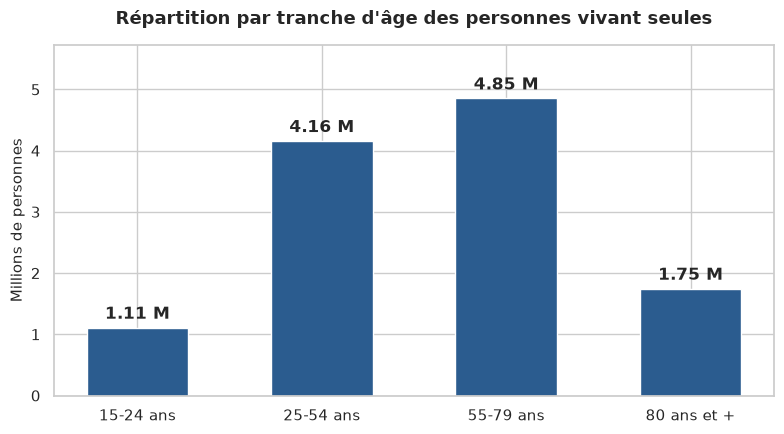

In [100]:
cols_age = {
    '15-24 ans': 'P22_POP1524_PSEUL',
    '25-54 ans': 'P22_POP2554_PSEUL',
    '55-79 ans': 'P22_POP5579_PSEUL',
    '80 ans et +': 'P22_POP80P_PSEUL'
}

values = {}
for label, col in cols_age.items():
    s = pd.to_numeric(menages[col].astype(str).str.replace(',', '.'), errors='coerce')
    values[label] = s.sum() / 1e6 

s_age = pd.Series(values)
print("Series values (in M):")
print(s_age)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")

bars = ax.bar(s_age.index, s_age.values, color='#2b5c8f', width=0.55)
ax.set_ylabel('Millions de personnes', fontsize=11)
ax.set_title('Répartition par tranche d\'âge des personnes vivant seules', fontsize=13, fontweight='bold', pad=15)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.08, f'{yval:.2f} M', ha='center', va='bottom', fontweight='bold')

ax.set_ylim(0, max(s_age.values) * 1.18)
plt.tight_layout()
plt.show();

**Constat** : Concentration majeure chez les 55-79 ans (4,85 M) et les 25-54 ans (4,16 M).

**Apport pour le modèle** : Permet de distinguer deux segments de demande : l'accession/locatif jeunes actifs d'un côté, et le besoin de logements adaptés au vieillissement de l'autre.

### Création des ratios

Les cinq ratios proposés (personnes seules, familles monoparentales, familles nombreuses, taille moyenne des ménages, couples sans enfant) sont calculés par commune dans le bloc 6 de `01_preparation`, en additionnant les effectifs des IRIS.

# 5. Parc de logement (recensement 2022)

**Contributeurs :** Théophyle CHEVET · **Date :** octobre 2026

Source : `base-ic-logement-2022.CSV` (Insee, base infracommunale à l'IRIS) et son dictionnaire des variables.

### 1. Situer la source et ouvrir les données

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | INSEE, recensement de la population. Jeu de données « Logement en 2022 – Base infracommunale (IRIS) ». | Page INSEE : insee.fr/fr/statistiques/8647012 |
| Finalité initiale | Statistique publique : décrire le parc de logements et les résidences principales (taille, époque de construction, statut d'occupation, emménagement, chauffage, voitures) à une échelle fine. Rien n'a été produit pour estimer des prix. | Aucun prix ni loyer : la cible du projet n'y figure pas. |
| Mode de collecte | Enquêtes annuelles du recensement : les petites communes sont recensées entièrement une fois tous les 5 ans, les communes de 10 000 habitants ou plus par sondage chaque année. Le millésime « 2022 » combine les enquêtes de 2020 à 2024. | Les effectifs sont des **estimations** (85 % des valeurs ont des décimales), donc peu fiables pour les petits IRIS. |
| Extraction / mise à jour | Publié le 16/10/2025, téléchargé sous forme de `base-ic-logement-2022_csv.zip` (données + dictionnaire `meta_…`). Une base par millésime, mise à jour chaque année. | Le millésime 2022 est le plus récent disponible. Les collectivités d'outre-mer sont dans un fichier séparé, non utilisé ici. |
| Documentation / licence | Dictionnaire des variables fourni (`meta_base-ic-logement-2022.CSV`) : les 101 colonnes y sont toutes décrites. Définitions du recensement sur insee.fr. Réutilisation libre avec mention « Source : Insee ». | Licence non précisée sur la page. Le code `LAB_IRIS` (label de qualité) n'est pas expliqué dans le dictionnaire. |
| Population / objets annoncés | Les IRIS des communes découpées (environ 2 000 habitants chacun) et les communes non découpées, traitées comme un seul IRIS. Fichier : **49 276 lignes**, dont 16 240 IRIS de communes découpées et 33 036 communes entières. | Maille mixte : quartier en ville, commune entière ailleurs. |
| Période / territoire, si pertinents | Recensement 2022 (enquêtes 2020-2024), géographie au 1er janvier 2024. France hors Mayotte : 34 960 communes, 100 départements, dont 971 à 974. | Une seule année. L'Alsace-Moselle est présente (2 149 IRIS) mais absente de DVF+. La géographie 2024 diffère de celle de LOVAC (2026) : quelques communes fusionnées sont à vérifier. |

In [101]:
import numpy as np
import pandas as pd

# ── 1. Chargement ────────────────────────────────────────────────────────────
# sep=";" : séparateur des fichiers INSEE
# dtype : les codes sont lus en texte pour garder les zéros du début ("01001") et la Corse ("2A004")
codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# Dictionnaire des variables fourni par l'INSEE avec les données
meta = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "meta_base-ic-logement-2022.CSV",
                   sep=";", dtype=str)

# ── 2. La lecture s'est-elle bien passée ? ───────────────────────────────────
# Si le séparateur était faux, on n'aurait qu'une seule colonne
print("Dimensions :", logement.shape)
display(logement.head(3))

# Types : les codes en texte, les effectifs en nombres décimaux
print(logement.dtypes.value_counts())

# Les codes ont-ils gardé leur longueur ? (IRIS = 9 caractères, commune = 5)
print("Longueur des codes IRIS :", logement["IRIS"].str.len().unique())
print("Longueur des codes commune :", logement["COM"].str.len().unique())

# Les accents du dictionnaire sont-ils bien lus ? (sinon : problème d'encodage)
print("Exemple de libellé :", meta["LIB_VAR"].iloc[5])

# ── 3. Toutes les colonnes sont-elles documentées dans le dictionnaire ? ─────
variables_doc = list(meta["COD_VAR"].unique())
non_documentees = []
for c in logement.columns:
    if c not in variables_doc:
        non_documentees.append(c)
print("Variables documentées :", len(variables_doc), "| Colonnes non documentées :", non_documentees)

# ── 4. Population / objets : une ligne = un IRIS ? ───────────────────────────
print("IRIS uniques :", logement["IRIS"].nunique(), "pour", len(logement), "lignes")
non_irisee = logement["IRIS"].str[-4:] == "0000"            # commune non découpée en IRIS
print("Communes non découpées (une seule ligne = la commune) :", non_irisee.sum())
print("IRIS dans des communes découpées :", (~non_irisee).sum())

# ── 5. Période : l'année figure dans le préfixe des noms de colonnes ─────────
print("Préfixes des colonnes :", logement.columns[4:].str[:3].unique())

# ── 6. Territoire ────────────────────────────────────────────────────────────
# Département : 2 caractères en métropole (01, 2A, 68), 3 en outre-mer (971...)
logement["dep"] = np.where(logement["COM"].str[:2] == "97",
                           logement["COM"].str[:3], logement["COM"].str[:2])
print("Communes :", logement["COM"].nunique(), "| Départements :", logement["dep"].nunique())
print("Outre-mer :", sorted(logement[logement["dep"].str[:2] == "97"]["dep"].unique()))
print("Mayotte (976) présente ?", "976" in list(logement["dep"].unique()))
print("IRIS en Alsace-Moselle (57, 67, 68) :", logement["dep"].isin(["57", "67", "68"]).sum())

# ── 7. Cohérence avec les chiffres publiés par l'INSEE (fichier if388) ───────
print("Total logements (millions) :", round(logement["P22_LOG"].sum() / 1e6, 2))

Dimensions : (49276, 101)


,IRIS,COM,TYP_IRIS,LAB_IRIS,P22_LOG,P22_RP,P22_RSECOCC,P22_LOGVAC,P22_MAISON,P22_APPART,P22_RP_1P,P22_RP_2P,P22_RP_3P,P22_RP_4P,P22_RP_5PP,P22_NBPI_RP,P22_RPMAISON,P22_NBPI_RPMAISON,P22_RPAPPART,P22_NBPI_RPAPPART,P22_RP_M30M2,P22_RP_3040M2,P22_RP_4060M2,P22_RP_6080M2,P22_RP_80100M2,P22_RP_100120M2,P22_RP_120M2P,P22_RP_ACHTOT,P22_RP_ACH1919,P22_RP_ACH1945,P22_RP_ACH1970,P22_RP_ACH1990,P22_RP_ACH2005,P22_RP_ACH2019,P22_RPMAISON_ACHTOT,P22_RPMAISON_ACH1919,P22_RPMAISON_ACH1945,P22_RPMAISON_ACH1970,P22_RPMAISON_ACH1990,P22_RPMAISON_ACH2005,P22_RPMAISON_ACH2019,P22_RPAPPART_ACHTOT,P22_RPAPPART_ACH1919,P22_RPAPPART_ACH1945,P22_RPAPPART_ACH1970,P22_RPAPPART_ACH1990,P22_RPAPPART_ACH2005,P22_RPAPPART_ACH2019,P22_MEN,P22_MEN_ANEM0002,P22_MEN_ANEM0204,P22_MEN_ANEM0509,P22_MEN_ANEM10P,P22_PMEN,P22_PMEN_ANEM0002,P22_PMEN_ANEM0204,P22_PMEN_ANEM0509,P22_PMEN_ANEM10P,P22_NBPI_RP_ANEM0002,P22_NBPI_RP_ANEM0204,P22_NBPI_RP_ANEM0509,P22_NBPI_RP_ANEM10P,P22_RP_PROP,P22_RP_LOC,P22_RP_LOCHLMV,P22_RP_GRAT,P22_NPER_RP,P22_NPER_RP_PROP,P22_NPER_RP_LOC,P22_NPER_RP_LOCHLMV,P22_NPER_RP_GRAT,P22_ANEM_RP,P22_ANEM_RP_PROP,P22_ANEM_RP_LOC,P22_ANEM_RP_LOCHLMV,P22_ANEM_RP_GRAT,P22_RP_CGAZV,P22_RP_CFIOUL,P22_RP_CELEC,P22_RP_CGAZB,P22_RP_CAUT,P22_RP_ELEC,P22_RP_EAUCH,P22_RP_BDWC,P22_RP_CHOS,P22_RP_CLIM,P22_RP_TTEGOU,P22_RP_GARL,P22_RP_VOIT1P,P22_RP_VOIT1,P22_RP_VOIT2P,P22_RP_HABFOR,P22_RP_CASE,P22_RP_MIBOIS,P22_RP_MIDUR,C22_RP_NORME,C22_RP_SOUSOCC_MOD,C22_RP_SOUSOCC_ACC,C22_RP_SOUSOCC_TACC,C22_RP_SUROCC_MOD,C22_RP_SUROCC_ACC
0,010010000,01001,Z,5,379.000000,354.000000,11.000000,14.000000,369.000000,9.000000,0.000000,8.000000,31.00000,95.000000,220.000000,1786.000000,345.000000,1762.000000,9.000000,24.000000,0.000000,2.000000,10.000000,26.000000,94.000000,93.000000,129.000000,339.000000,77.000000,22.000000,15.0000,100.000000,88.000000,37.000000,330.000000,77.000000,22.000000,14.000000,97.000000,85.000000,35.000000,9.000000,0.000000,0.0,1.000000,3.000000,3.000000,2.000000,354.000000,37.000000,60.000000,58.000000,199.000000,859.000000,93.000000,159.000000,170.000000,437.000000,183.000000,302.000000,280.000000,1021.000000,303.000000,49.000000,14.00000,2.000000,859.000000,747.00000,107.000000,24.00000,5.000000,6267.000000,5730.000000,528.000000,128.000000,9.000000,4.00000,77.000000,110.000000,29.000000,134.000000,NaN,NaN,NaN,NaN,NaN,NaN,307.000000,344.000000,114.000000,230.000000,NaN,NaN,NaN,NaN,9.817143,68.720000,137.440000,137.440000,0.000000,0.0
1,010020000,01002,Z,5,175.000000,121.000000,41.000000,13.000000,173.000000,2.000000,1.000000,2.000000,14.00000,29.000000,75.000000,616.000000,119.000000,609.000000,2.000000,7.000000,0.000000,2.000000,2.000000,14.000000,23.000000,30.000000,50.000000,119.000000,61.000000,6.000000,13.0000,9.000000,10.000000,20.000000,118.000000,61.000000,6.000000,12.000000,9.000000,10.000000,20.000000,1.000000,0.000000,0.0,1.000000,0.000000,0.000000,0.000000,121.000000,7.000000,18.000000,27.000000,69.000000,273.000000,11.000000,46.000000,62.000000,154.000000,31.000000,80.000000,142.000000,363.000000,106.000000,12.000000,0.00000,3.000000,273.000000,246.00000,24.000000,0.00000,3.000000,2055.000000,1968.000000,46.000000,0.000000,41.000000,0.00000,35.000000,21.000000,2.000000,63.000000,NaN,NaN,NaN,NaN,NaN,NaN,92.000000,115.000000,52.000000,63.000000,NaN,NaN,NaN,NaN,4.963636,9.927273,39.709091,64.527273,0.000000,0.0
2,010040101,01004,H,1,935.984809,835.047694,36.017461,64.919654,408.628548,489.281402,160.304543,26.613018,161.14862,297.405961,189.575552,2965.351823,372.907564,1738.087002,431.456965,1193.183757,163.711606,8.532039,66.576455,202.698987,257.583998,82.666434,53.278176,834.075807,32.709733,12.679833,196.0134,184.941655,177.562331,230.168855,371.935676,12.801642,12.679833,71.017354,109.354686,24.599607,141.482553,431.456965,19.908091,0.0,124.996045,63.093982,134.772545,88.686302,835.047694,169.954281,228.079681,110.055204,326.958528,1694.944143,224.631954,448.998981,310.226173,711.087035,390.124431,759.149455,437.250856,1378.827081,424.75

float64    97
str         4
Name: count, dtype: int64
Longueur des codes IRIS : [9]
Longueur des codes commune : [5]
Exemple de libellé : Rés secondaires et logts occasionnels en 2022 (princ)
Variables documentées : 101 | Colonnes non documentées : []
IRIS uniques : 49276 pour 49276 lignes
Communes non découpées (une seule ligne = la commune) : 33036
IRIS dans des communes découpées : 16240
Préfixes des colonnes : Index(['P22', 'C22'], dtype='str')
Communes : 34960 | Départements : 100
Outre-mer : ['971', '972', '973', '974']
Mayotte (976) présente ? False
IRIS en Alsace-Moselle (57, 67, 68) : 2149
Total logements (millions) : 37.53


**Constat :**

La base logement 2022 de l'INSEE (recensement, publiée le 16/10/2025) se lit correctement : 49 276 lignes et 101 colonnes, toutes décrites dans le dictionnaire, codes IRIS et commune complets, aucun doublon. Le total de 37,53 millions de logements correspond exactement au chiffre publié par l'INSEE pour 2022. Une ligne est un IRIS en ville, mais la commune entière pour les 33 036 petites communes non découpées. Les effectifs sont des estimations issues des enquêtes 2020-2024. La base ne contient aucun prix et couvre toute la France sauf Mayotte, y compris l'Alsace-Moselle.

**Impact projet :**

La base ne fournit pas la cible, seulement des variables explicatives sur les territoires (vacance, résidences secondaires, profil du parc). DVF+ n'ayant pas de code IRIS, la jointure se fera par le code commune puis par bassin de vie, et le détail par quartier sera perdu. Avec une seule année, ces variables distingueront les territoires entre eux mais n'expliqueront pas l'évolution des prix.

**Action envisagée :**

Toujours lire les codes en texte. Agréger les effectifs par commune puis par bassin de vie (somme des effectifs, puis calcul des taux), joindre avec `codgeo_bv2022` et DVF+ (`l_codinsee`), puis exclure l'Alsace-Moselle. Contrôler le nombre de communes sans correspondance à chaque jointure.

**Incertitudes / limites, si nécessaire :**

- Les petits IRIS ont des effectifs estimés peu fiables : un seuil minimum (50 logements) est nécessaire pour calculer des taux.
- Utiliser le millésime 2022 pour des ventes antérieures introduit une légère anticipation, jugée faible car le parc évolue lentement.
- La géographie (communes au 1er janvier 2024) diffère de celle de LOVAC (2026) : des communes fusionnées pourraient ne pas trouver de correspondance.
- La signification des codes `LAB_IRIS` (label de qualité) n'est pas documentée dans le dictionnaire.
- La licence n'est pas précisée sur la page de l'INSEE.

### 2. Comprendre la structure et une ligne

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 49 276 lignes × 101 colonnes : 4 identifiants en texte (`IRIS`, `COM`, `TYP_IRIS`, `LAB_IRIS`) et 97 effectifs numériques (`P22_…`, `C22_…`). |
| Contenu général, en une phrase | Pour chaque IRIS, le nombre estimé de logements selon leur catégorie (principales, secondaires, vacants), leur type (maison, appartement), leur taille, leur époque de construction, leur statut d'occupation et les caractéristiques des ménages qui les occupent. |
| Unité d’observation | **L'IRIS** : un quartier d'environ 2 000 habitants dans les villes découpées (16 240 lignes), ou **la commune entière** pour les petites communes non découpées (33 036 lignes, code IRIS terminé par `0000`). Paris, Lyon et Marseille sont décrites par **arrondissement** (75101… ; le code 75056 n'existe pas). |
| Identifiants / clés possibles | **`IRIS`** est une clé unique (49 276 valeurs pour 49 276 lignes). **`COM`** n'est pas unique : c'est la clé de regroupement vers la commune, puis le bassin de vie. |
| Une ou plusieurs lignes par objet ? Pourquoi ? | **Une ligne par IRIS.** En revanche, plusieurs lignes par commune pour les 1 924 communes découpées (jusqu'à 153 pour Toulouse, 146 pour Nice, 116 pour Strasbourg ; 26 et plus pour Colmar). C'est normal : il faut additionner les IRIS pour obtenir la commune. Aucune commune ne mélange une ligne « commune entière » et des IRIS. |
| Doublons exacts : nombre / proportion | **0** (0 %). |
| Répétitions métier : règle examinée / résultat | Règle : deux IRIS différents avec exactement les mêmes 97 chiffres. Résultat : 154 lignes, dont **152 IRIS sans aucun logement** (tous les effectifs à 0 : zones d'activité, parcs, IRIS « divers ») et 2 IRIS avec 1 seul logement vacant. Ce sont des **répétitions normales**, pas des doublons : ces lignes seront exclues car elles n'apportent aucune information sur le logement. |

In [102]:
import pandas as pd

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# ── 1. Dimensions, colonnes et quelques observations ─────────────────────────
print("Lignes :", logement.shape[0], "| Colonnes :", logement.shape[1])
print(list(logement.columns))                        # liste complète des colonnes

# 5 lignes tirées au hasard (random_state : même tirage à chaque exécution)
display(logement.sample(5, random_state=0).iloc[:, :10])

# ── 2. Ce que représente une ligne : exemple d'une commune découpée ──────────
# Colmar (68066) : plusieurs lignes, une par quartier (IRIS)
display(logement[logement["COM"] == "68066"].iloc[:, :8])

# ── 3. Clés possibles ────────────────────────────────────────────────────────
# IRIS : une valeur différente pour chaque ligne ?
print("IRIS uniques :", logement["IRIS"].nunique(), "/", len(logement))

# COM : combien de lignes par commune ?
lignes_par_commune = logement["COM"].value_counts()   # trié du plus grand au plus petit
print("Communes :", len(lignes_par_commune))
print("Communes avec une seule ligne :", (lignes_par_commune == 1).sum())
print("Communes avec plusieurs lignes :", (lignes_par_commune > 1).sum())
print(lignes_par_commune.head(5))                     # communes les plus découpées

# Une commune peut-elle avoir à la fois une ligne "commune entière" (0000) et des IRIS ?
logement["non_irisee"] = logement["IRIS"].str[-4:] == "0000"
melange = logement.groupby("COM")["non_irisee"].nunique()   # 2 = les deux cas dans la même commune
print("Communes mélangeant ligne entière et IRIS :", (melange > 1).sum())

# Paris : codé par arrondissement (75101 à 75120) ou par commune (75056) ?
print("Code 75056 (Paris commune) présent ?", (logement["COM"] == "75056").sum() > 0)
print("Arrondissements parisiens :", logement[logement["COM"].str[:3] == "751"]["COM"].nunique())

# ── 4. Doublons ──────────────────────────────────────────────────────────────
# Doublons exacts : lignes identiques sur toutes les colonnes
nb_doublons = logement.duplicated().sum()
print("Doublons exacts :", nb_doublons, "(", round(nb_doublons / len(logement) * 100, 2), "% )")

# Répétitions métier : deux IRIS différents avec exactement les mêmes chiffres ?
# On compare les 97 colonnes de chiffres, sans les identifiants (colonnes 0 à 3)
colonnes_chiffres = logement.columns[4:101]
repetes = logement[logement.duplicated(subset=colonnes_chiffres, keep=False)]   # keep=False : toutes les lignes concernées
print("Lignes aux chiffres identiques à une autre :", len(repetes))

# Que sont ces lignes ? On regarde combien n'ont aucun logement
print("dont IRIS avec 0 logement :", (repetes["P22_LOG"] == 0).sum())
display(repetes[repetes["P22_LOG"] > 0].iloc[:, :10])          # les autres cas

Lignes : 49276 | Colonnes : 101
['IRIS', 'COM', 'TYP_IRIS', 'LAB_IRIS', 'P22_LOG', 'P22_RP', 'P22_RSECOCC', 'P22_LOGVAC', 'P22_MAISON', 'P22_APPART', 'P22_RP_1P', 'P22_RP_2P', 'P22_RP_3P', 'P22_RP_4P', 'P22_RP_5PP', 'P22_NBPI_RP', 'P22_RPMAISON', 'P22_NBPI_RPMAISON', 'P22_RPAPPART', 'P22_NBPI_RPAPPART', 'P22_RP_M30M2', 'P22_RP_3040M2', 'P22_RP_4060M2', 'P22_RP_6080M2', 'P22_RP_80100M2', 'P22_RP_100120M2', 'P22_RP_120M2P', 'P22_RP_ACHTOT', 'P22_RP_ACH1919', 'P22_RP_ACH1945', 'P22_RP_ACH1970', 'P22_RP_ACH1990', 'P22_RP_ACH2005', 'P22_RP_ACH2019', 'P22_RPMAISON_ACHTOT', 'P22_RPMAISON_ACH1919', 'P22_RPMAISON_ACH1945', 'P22_RPMAISON_ACH1970', 'P22_RPMAISON_ACH1990', 'P22_RPMAISON_ACH2005', 'P22_RPMAISON_ACH2019', 'P22_RPAPPART_ACHTOT', 'P22_RPAPPART_ACH1919', 'P22_RPAPPART_ACH1945', 'P22_RPAPPART_ACH1970', 'P22_RPAPPART_ACH1990', 'P22_RPAPPART_ACH2005', 'P22_RPAPPART_ACH2019', 'P22_MEN', 'P22_MEN_ANEM0002', 'P22_MEN_ANEM0204', 'P22_MEN_ANEM0509', 'P22_MEN_ANEM10P', 'P22_PMEN', 'P22_PMEN_ANE

,IRIS,COM,TYP_IRIS,LAB_IRIS,P22_LOG,P22_RP,P22_RSECOCC,P22_LOGVAC,P22_MAISON,P22_APPART
7064,162220000,16222,Z,5,287.648622,175.498725,61.466770,50.683126,272.973785,9.387197
27042,576050000,57605,Z,5,130.820045,115.224807,3.119048,12.476190,118.390721,12.429324
21620,461050000,46105,Z,5,399.912982,355.524557,39.344286,5.044139,398.927652,0.985330
14721,315554302,31555,H,1,1519.499026,1337.475917,37.063595,144.959514,346.398348,1167.766896
1145,026910209,02691,H,1,1194.004381,990.422808,33.189174,170.392399,764.113433,341.467452


,IRIS,COM,TYP_IRIS,LAB_IRIS,P22_LOG,P22_RP,P22_RSECOCC,P22_LOGVAC
34155,680660101,68066,H,1,1474.008331,1247.810822,123.131943,103.065567
34156,680660102,68066,H,1,2076.010237,1533.149359,338.866530,203.994347
34157,680660103,68066,H,1,1579.008675,1299.293860,138.833497,140.881319
34158,680660104,68066,H,1,1459.006364,953.080129,257.113662,248.812572
34159,680660105,68066,H,1,1892.010252,1535.425654,99.880076,256.704522
34160,680660201,68066,H,1,1034.505973,894.655327,33.984074,105.866572
34161,680660202,68066,H,1,1298.007085,1061.133139,147.249345,89.624600
34162,680660301,68066,H,1,3774.024051,3602.180974,70.566592,101.276485
34163,680660401,68066,H,1,1712.010876,1628.844328,24.033655,59.132893
34164,680660402,68066,H,1,2137.512756,1910.424655,145.114230,81.973871


IRIS uniques : 49276 / 49276
Communes : 34960
Communes avec une seule ligne : 33036
Communes avec plusieurs lignes : 1924
COM
31555    153
06088    146
67482    116
59350    110
44109     97
Name: count, dtype: int64
Communes mélangeant ligne entière et IRIS : 0
Code 75056 (Paris commune) présent ? False
Arrondissements parisiens : 20
Doublons exacts : 0 ( 0.0 % )
Lignes aux chiffres identiques à une autre : 154
dont IRIS avec 0 logement : 152


,IRIS,COM,TYP_IRIS,LAB_IRIS,P22_LOG,P22_RP,P22_RSECOCC,P22_LOGVAC,P22_MAISON,P22_APPART
18159,381930104,38193,A,3,1.0,0.0,0.0,1.0,1.0,0.0
25579,551390000,55139,Z,5,1.0,0.0,0.0,1.0,1.0,0.0


**Constat :**

Une ligne correspond à un IRIS : le code `IRIS` est unique et il n'y a aucun doublon exact. L'unité n'est pas homogène : quartier d'environ 2 000 habitants dans les 1 924 communes découpées (jusqu'à 153 lignes pour Toulouse), commune entière pour les 33 036 autres. Paris, Lyon et Marseille sont décrites par arrondissement (75101…), sans ligne pour la commune (75056). Les 154 lignes aux chiffres identiques ne sont pas des doublons : ce sont 152 IRIS sans aucun logement (zones d'activité, IRIS « divers ») et 2 IRIS avec un seul logement.

**Impact projet :**

Les lignes ne sont pas directement comparables : un IRIS urbain et une commune rurale entière n'ont pas la même taille. Pour rapprocher cette base des autres sources, qui sont à la commune, il faudra additionner les IRIS de chaque commune. Le codage par arrondissement de Paris, Lyon et Marseille peut faire échouer ces rapprochements si l'autre source utilise le code de la commune entière (75056, 69123, 13055), alors que ces trois villes représentent une part importante des ventes.

**Action envisagée :**

Supprimer les 152 IRIS sans logement. Agréger les effectifs par commune avec un `groupby("COM").sum()`, puis recalculer les taux. Selon le codage des autres sources, regrouper les arrondissements dans leur commune (751xx → 75056, 6938x → 69123, 132xx → 13055). Vérifier après agrégation qu'il y a bien une ligne par commune.

**Incertitudes / limites, si nécessaire :**

- L'agrégation à la commune fait perdre les écarts entre quartiers d'une même ville (centre et périphérie de Toulouse, par exemple), alors qu'ils comptent beaucoup pour les prix.

### 3. Comprendre les variables

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| `IRIS` | Code IRIS : département + commune (ou arrondissement) + numéro d'IRIS | Qualitative nominale (identifiant) | Code à 9 caractères ; 49 276 valeurs | str : cohérent (lu en texte volontairement) |
| `COM` | Code commune, ou arrondissement pour Paris, Lyon, Marseille | Qualitative nominale (identifiant) | Code à 5 caractères ; 34 960 valeurs | str : cohérent |
| `TYP_IRIS` | Type d'IRIS : habitat (H), activité (A), divers (D), commune non découpée (Z) | Qualitative nominale | H / A / D / Z | str : cohérent |
| `LAB_IRIS` | Label de qualité de l'IRIS | Qualitative nominale (ordinale ?) | 1 / 2 / 3 / 4 / 5 / Z (5 = toutes les communes non découpées) | str : cohérent, mais **codes non expliqués** |
| `P22_LOG` | Nombre total de logements | Quantitative continue (effectif estimé) | Logements ; de 0 à 29 617 | float64 : cohérent (décimales dues au sondage) |
| `P22_RP`, `P22_RSECOCC`, `P22_LOGVAC` | Résidences principales, secondaires et occasionnelles, vacantes | Quantitative continue | Logements ; de 0 à 26 565 | float64 : cohérent ; leur somme = `P22_LOG` |
| `P22_MAISON`, `P22_APPART` | Maisons, appartements (tous logements) | Quantitative continue | Logements ; de 0 à 25 844 | float64 : cohérent |
| `P22_RP_1P` à `P22_RP_5PP` | Résidences principales de 1, 2, 3, 4, 5 pièces ou plus | Quantitative continue | Logements ; de 0 à 3 435 | float64 : cohérent ; somme = `P22_RP` |
| `P22_RP_M30M2` à `P22_RP_120M2P` | Résidences principales par tranche de surface (< 30 m² à ≥ 120 m²) | Quantitative continue | Logements ; de 0 à 3 614 | float64 : cohérent ; somme = `P22_RP` |
| `P22_RPMAISON`, `P22_RPAPPART` | Résidences principales de type maison, appartement | Quantitative continue | Logements | float64 : cohérent |
| `P22_NBPI_RP` (+ maison, appart, par ancienneté) | **Total** des pièces des résidences principales | Quantitative continue (somme) | Pièces ; de 0 à 19 326 | float64 : cohérent ; divisé par `P22_RP`, donne 4,0 pièces en moyenne |
| `P22_RP_ACHTOT` à `P22_RP_ACH2019` (+ maison, appart) | Résidences principales par époque d'achèvement (avant 1919 … 2006-2019) ; `ACHTOT` = achevées avant 2020 | Quantitative continue | Logements | float64 : cohérent ; `ACHTOT` = 98,3 % de `P22_RP` (sans les constructions récentes) |
| `P22_MEN`, `P22_MEN_ANEM…` | Ménages, par ancienneté d'emménagement (< 2 ans, 2-4, 5-9, 10 ans et plus) | Quantitative continue | Ménages | float64 : cohérent ; `P22_MEN` = `P22_RP` (1 ménage = 1 résidence principale) |
| `P22_PMEN`, `P22_PMEN_ANEM…` | Population des ménages, par ancienneté d'emménagement | Quantitative continue (somme) | Personnes ; de 0 à 15 674 | float64 : cohérent |
| `P22_NBPI_RP_ANEM…` | Total des pièces selon l'ancienneté d'emménagement | Quantitative continue (somme) | Pièces | float64 : cohérent |
| `P22_RP_PROP`, `_LOC`, `_LOCHLMV`, `_GRAT` | Résidences principales occupées par propriétaire, locataire (dont HLM loué vide), logé gratuitement | Quantitative continue | Logements | float64 : cohérent ; propriétaires + locataires + gratuits = `P22_RP` (HLM inclus dans les locataires) |
| `P22_NPER_RP…` | Nombre de personnes, selon le statut d'occupation | Quantitative continue (somme) | Personnes | float64 : cohérent |
| `P22_ANEM_RP…` | **Total** des années d'ancienneté d'emménagement, selon le statut | Quantitative continue (somme) | Années ; de 0 à 69 414 | float64 : cohérent ; divisé par `P22_RP`, donne 15,3 ans en moyenne |
| `P22_RP_CGAZV`, `_CFIOUL`, `_CELEC`, `_CGAZB`, `_CAUT` | Résidences principales par combustible de chauffage (gaz de ville, fioul, électricité, gaz en bouteille, autre) | Quantitative continue | Logements | float64 : cohérent ; **1,4 % manquants = outre-mer** (non renseigné) |
| `P22_RP_ELEC`, `_EAUCH`, `_BDWC`, `_CHOS`, `_CLIM`, `_TTEGOU`, `_HABFOR`, `_CASE`, `_MIBOIS`, `_MIDUR` | Équipements et type de bâti spécifiques aux départements d'outre-mer | Quantitative continue | Logements | float64 : cohérent ; **98,6 % manquants = métropole** (non concernée) |
| `P22_RP_GARL`, `_VOIT1P`, `_VOIT1`, `_VOIT2P` | Ménages avec au moins un parking, au moins une voiture, une voiture, deux ou plus | Quantitative continue | Ménages | float64 : cohérent |
| `C22_RP_NORME` à `C22_RP_SUROCC_ACC` | Résidences principales selon l'occupation (normale, sous-occupation, suroccupation), exploitation complémentaire | Quantitative continue | Logements | float64 : cohérent ; somme ≈ `P22_RP` (100,1 %) |

**Variables ambiguës / documentation manquante :** `LAB_IRIS` (label de qualité) a des codes 1 à 5 et Z non expliqués dans le dictionnaire. Les variables `NBPI`, `NPER`, `PMEN` et `ANEM_RP` sont des **totaux**, pas des moyennes : il faut les diviser par le nombre de résidences principales. `ACHTOT` ne signifie pas « total » mais « achevées avant 2020 ». `P22_RP_GARL` concerne les ménages malgré son nom en « RP ». Le préfixe `C22_` (exploitation complémentaire) suit une méthode légèrement différente de `P22_` (exploitation principale). Aucune variable constante, aucune valeur négative.

**Utilité provisoire pour le projet :** utiles une fois converties en **parts** : taux de vacance, part de résidences secondaires, part de maisons, part de propriétaires, part de HLM, part de logements anciens (avant 1946) ou récents, surface et nombre de pièces moyens, ancienneté moyenne d'emménagement et part d'emménagés récents (mobilité résidentielle), suroccupation. Peu utiles : les variables propres à l'outre-mer et le détail du chauffage. Les nombreuses déclinaisons (maison ou appartement × époque, ancienneté × pièces…) sont redondantes : en garder quelques-unes.

**Si prédiction : disponibilité au moment de prédire / risques de fuite à examiner :** aucune variable n'est calculée à partir des prix, donc pas de fuite directe. En revanche, le recensement 2022 (enquêtes 2020-2024) n'a été publié qu'en octobre 2025 : pour des ventes antérieures, ces informations n'étaient pas encore disponibles (légère anticipation). Les ménages emménagés depuis moins de 2 ans reflètent les déménagements, donc en partie les ventes, des mêmes années que les prix étudiés : ce n'est pas une fuite de la cible, mais une information contemporaine à surveiller.

In [103]:
import pandas as pd
from pandas.api.types import is_numeric_dtype

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# ── 1. Sens des variables : on le prend dans le dictionnaire INSEE ───────────
meta = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "meta_base-ic-logement-2022.CSV",
                   sep=";", dtype=str)
meta = meta.drop_duplicates("COD_VAR").set_index("COD_VAR")    # une ligne par variable


# ── 2. Nature statistique et unité : déduites du nom de la variable ─────────
def nature_unite(col):
    if col in ["IRIS", "COM"]:
        return "qualitative nominale (identifiant)", "code"
    if col in ["TYP_IRIS", "LAB_IRIS"]:
        return "qualitative nominale", "modalités"
    if "NBPI" in col:                       # somme des pièces de tous les logements
        return "quantitative continue (total)", "pièces"
    if "NPER" in col or "PMEN" in col:      # somme des personnes
        return "quantitative continue (total)", "personnes"
    if "ANEM_RP" in col:                    # somme des années d'ancienneté d'emménagement
        return "quantitative continue (total)", "années"
    if "_MEN" in col:
        return "quantitative continue (effectif estimé)", "ménages"
    return "quantitative continue (effectif estimé)", "logements"


# ── 3. Modalités ou plage de valeurs ────────────────────────────────────────
def modalites(col):
    s = logement[col].dropna()                             # on ignore les valeurs manquantes
    if is_numeric_dtype(logement[col]):
        return "de " + str(round(s.min(), 1)) + " à " + str(round(s.max(), 1))
    if s.nunique() <= 6:
        return str(sorted(s.unique()))                     # peu de modalités : on les liste
    return str(s.nunique()) + " valeurs"                   # sinon : on les compte


# ── 4. Type de stockage et cohérence avec la nature ─────────────────────────
def coherence(col, nature):
    dtype = str(logement[col].dtype)
    manquants = round(logement[col].isna().mean() * 100, 1)
    texte = dtype + " : cohérent"
    if nature.startswith("quantitative") and not is_numeric_dtype(logement[col]):
        texte = dtype + " : incohérent"                    # un nombre stocké en texte
    if manquants > 0:
        texte = texte + " (" + str(manquants) + " % manquants)"
    return texte


# ── 5. Assemblage du tableau (une ligne par variable) ───────────────────────
lignes = []
for col in logement.columns:
    nature, unite = nature_unite(col)
    lignes.append({"Variable": col,
                   "Signification": meta.loc[col, "LIB_VAR_LONG"],   # libellé long de l'INSEE
                   "Nature statistique": nature,
                   "Unité / modalités": unite + " ; " + modalites(col),
                   "Type de stockage et cohérence": coherence(col, nature)})
tableau = pd.DataFrame(lignes).set_index("Variable")
pd.set_option("display.max_colwidth", None)                # ne pas couper le texte
display(tableau)


# ── 6. Variables constantes, valeurs négatives, modalités de LAB_IRIS ───────
constantes = []
for col in logement.columns:
    if logement[col].nunique() <= 1:
        constantes.append(col)
print("Variables constantes :", constantes)
print("Valeurs négatives :", (logement.select_dtypes("number") < 0).sum().sum())
print(logement["LAB_IRIS"].value_counts())


# ── 7. Vérifier notre compréhension par des sommes ──────────────────────────
# Si on a bien compris, ces sous-catégories doivent redonner le total des résidences principales
rp = logement["P22_RP"].sum()
pieces = logement[["P22_RP_1P", "P22_RP_2P", "P22_RP_3P", "P22_RP_4P", "P22_RP_5PP"]].sum().sum()
statut = logement[["P22_RP_PROP", "P22_RP_LOC", "P22_RP_GRAT"]].sum().sum()
occupation = logement[["C22_RP_NORME", "C22_RP_SOUSOCC_MOD", "C22_RP_SOUSOCC_ACC",
                       "C22_RP_SOUSOCC_TACC", "C22_RP_SUROCC_MOD", "C22_RP_SUROCC_ACC"]].sum().sum()
print("Pièces (1 à 5+) / RP :", round(pieces / rp, 3))
print("Propriétaires + locataires + gratuits / RP :", round(statut / rp, 3))
print("Classes d'occupation C22 / RP :", round(occupation / rp, 3))
print("Ménages = résidences principales ? écarts :", (abs(logement["P22_MEN"] - logement["P22_RP"]) > 0.5).sum())
print("Construites avant 2020 (ACHTOT) / RP :", round(logement["P22_RP_ACHTOT"].sum() / rp, 3))

# Les variables "NBPI" et "ANEM" sont des totaux : divisées par RP, elles donnent une moyenne
print("Nombre moyen de pièces par résidence principale :", round(logement["P22_NBPI_RP"].sum() / rp, 1))
print("Ancienneté moyenne d'emménagement (années) :", round(logement["P22_ANEM_RP"].sum() / rp, 1))

,Signification,Nature statistique,Unité / modalités,Type de stockage et cohérence
Variable,,,,
IRIS,Code du département suivi du numéro de commune ou du numéro d'arrondissement municipal suivi du numéro d'IRIS,qualitative nominale (identifiant),code ; 49276 valeurs,str : cohérent
COM,Code du département suivi du numéro de commune ou du numéro d'arrondissement municipal pour Paris Lyon et Marseille,qualitative nominale (identifiant),code ; 34960 valeurs,str : cohérent
TYP_IRIS,"Type d'Iris : habitat (H), activité (A), divers (D), Autre (Z)",qualitative nominale,"modalités ; ['A', 'D', 'H', 'Z']",str : cohérent
LAB_IRIS,Label de qualité de l'Iris,qualitative nominale,"modalités ; ['1', '2', '3', '4', '5', 'Z']",str : cohérent
P22_LOG,Nombre de logements,quantitative continue (effectif estimé),logements ; de 0.0 à 29617.5,float64 : cohérent
...,...,...,...,...
C22_RP_SOUSOCC_MOD,Résidences principales en sous-occupation modérée,quantitative continue (effectif estimé),logements ; de 0.0 à 1874.1,float64 : cohérent
C22_RP_SOUSOCC_ACC,Résidences principales en sous-occupation accentuée,quantitative continue (effectif estimé),logements ; de 0.0 à 1235.9,float64 : cohérent
C22_RP_SOUSOCC_TACC,Résidences principales en sous-occupation très accentuée,quantitative continue (effectif estimé),logements ; de 0.0 à 1559.4,float64 : cohérent


Variables constantes : []
Valeurs négatives : 0
LAB_IRIS
5    33036
1    10319
4     2517
2     1641
3     1149
Z      614
Name: count, dtype: int64
Pièces (1 à 5+) / RP : 1.0
Propriétaires + locataires + gratuits / RP : 1.0
Classes d'occupation C22 / RP : 1.001
Ménages = résidences principales ? écarts : 0
Construites avant 2020 (ACHTOT) / RP : 0.983
Nombre moyen de pièces par résidence principale : 4.0
Ancienneté moyenne d'emménagement (années) : 15.3


**Constat :**

Les 101 variables sont toutes documentées : 4 codes stockés en texte et 97 effectifs numériques (float64), cohérents avec leur nature. Aucune variable n'est constante et aucune valeur n'est négative. Les sous-catégories redonnent bien les totaux (pièces, statut d'occupation et classes d'occupation = résidences principales ; ménages = résidences principales). Les valeurs manquantes sont structurelles : les variables propres à l'outre-mer sont vides en métropole (98,6 %), celles du chauffage en outre-mer (1,4 %). Certaines variables sont des totaux (pièces, personnes, années d'emménagement) et non des moyennes. Les effectifs dépendent de la taille de l'IRIS, de 0 à près de 30 000 logements.

**Impact projet :**

Les effectifs bruts ne sont pas comparables entre territoires : un grand IRIS a mécaniquement plus de logements vacants qu'un petit. Il faut les transformer en parts (taux de vacance, part de résidences secondaires, de maisons, de propriétaires, de HLM, de logements anciens) et en moyennes (pièces par logement, ancienneté d'emménagement), qui décrivent le profil des territoires. Les nombreuses déclinaisons d'une même information sont redondantes et risquent de gêner les modèles linéaires.

**Action envisagée :**

Calculer une dizaine d'indicateurs en parts ou en moyennes après agrégation à la commune, en divisant par le bon dénominateur (logements totaux ou résidences principales). Écarter les variables propres à l'outre-mer et le détail croisé (maison ou appartement × époque, ancienneté × pièces). Vérifier ensuite les corrélations entre indicateurs pour éliminer les doublons d'information.

**Incertitudes / limites, si nécessaire :**

- Les codes de `LAB_IRIS` ne sont pas expliqués dans le dictionnaire : la variable n'est pas exploitée tant qu'on n'a pas trouvé sa signification dans la documentation de l'INSEE.
- Les variables `C22_` suivent une exploitation complémentaire, avec un léger écart (0,1 %) par rapport aux variables `P22_`.
- Le recensement 2022 n'a été publié qu'en octobre 2025 : l'utiliser pour des ventes antérieures revient à exploiter une information qui n'était pas encore disponible.

### 4. Vérifier le périmètre réel

| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| Population / objets / groupes | Tous les logements (37,53 millions), répartis en IRIS d'habitat (H), d'activité (A), divers (D) et en communes non découpées (Z). | H : 15 010 lignes, 58,2 % des logements ; Z : 33 036 lignes, 40,7 % ; A : 829 lignes, 0,7 % ; D : 401 lignes, 0,3 %. 152 IRIS sans aucun logement. | Le nombre de lignes ne reflète pas le poids réel : les communes non découpées font 67 % des lignes mais seulement 41 % des logements. Une statistique calculée « par ligne » donnerait trop de poids au rural. |
| Temps, si pertinent | Une seule année : recensement 2022 (préfixes `P22_` et `C22_` uniquement). | Aucune colonne de date ; les enquêtes couvrent 2020-2024. | Aucune évolution observable. Pour les ventes avant 2022, l'information est postérieure (anticipation) ; pour 2023-2025, elle date de plusieurs années. |
| Géographie, si pertinente | France hors Mayotte : 100 départements (96 en métropole, 971 à 974), 34 960 communes. Paris, Lyon et Marseille sont découpées en 20, 9 et 16 arrondissements. | Total de 37,53 millions de logements, contre 37,52 millions publiés par l'INSEE pour 2022 (if388) : la couverture est complète. Outre-mer : 707 lignes, 0,96 million de logements. | Mayotte est absente (comme annoncé). L'Alsace-Moselle est présente : 2 149 IRIS, 1,52 million de logements (4,0 %), mais ces territoires ne pourront pas être reliés aux ventes DVF+. |
| Autre dimension : taille des départements | Effectifs très inégaux entre départements. | De 62 201 logements (Lozère) à 1 399 122 (Paris) ; médiane de 301 756. | Ces écarts reflètent la population réelle (le total correspond au chiffre INSEE) : ce n'est **pas** une sous-représentation. Mais les taux des petits départements reposent sur moins d'IRIS et sont plus fragiles. |

In [104]:
import numpy as np
import pandas as pd

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# Colonnes utiles pour décrire le périmètre
# Département : 2 caractères en métropole (01, 2A, 68), 3 en outre-mer (971...)
logement["dep"] = np.where(logement["COM"].str[:2] == "97",
                           logement["COM"].str[:3], logement["COM"].str[:2])
logement["non_irisee"] = logement["IRIS"].str[-4:] == "0000"   # commune non découpée
logement["outre_mer"] = logement["dep"].str[:2] == "97"

# ── 1. Objets et groupes présents ────────────────────────────────────────────
# Types d'IRIS : nombre de lignes ET nombre de logements dans chaque type
groupes = logement.groupby("TYP_IRIS").agg(nb_lignes=("IRIS", "count"),
                                           logements=("P22_LOG", "sum"))
groupes["logements"] = groupes["logements"].round(0)
groupes["% logements"] = (groupes["logements"] / groupes["logements"].sum() * 100).round(1)
display(groupes)

# Communes découpées (villes) ou non : part des lignes et part des logements
taille = logement.groupby("non_irisee").agg(nb_lignes=("IRIS", "count"),
                                            logements=("P22_LOG", "sum"))
taille["% logements"] = (taille["logements"] / taille["logements"].sum() * 100).round(1)
display(taille)

# Lignes sans aucun logement
print("IRIS sans logement :", (logement["P22_LOG"] == 0).sum())

# ── 2. Temps : une seule année dans le nom des colonnes ──────────────────────
# (colonnes 4 à 100 : les 97 effectifs, sans les colonnes ajoutées plus haut)
print("Préfixes d'année :", logement.columns[4:101].str[:3].unique())

# ── 3. Territoire ────────────────────────────────────────────────────────────
print("Départements :", logement["dep"].nunique(), "| Communes :", logement["COM"].nunique())
print("Mayotte (976) présente ?", "976" in list(logement["dep"].unique()))

# Arrondissements de Paris (751..), Lyon (6938.) et Marseille (132..)
arr_paris = logement[logement["COM"].str[:3] == "751"]["COM"].nunique()
arr_lyon = logement[logement["COM"].str[:4] == "6938"]["COM"].nunique()
arr_marseille = logement[logement["COM"].str[:3] == "132"]["COM"].nunique()
print("Arrondissements Paris / Lyon / Marseille :", arr_paris, arr_lyon, arr_marseille)

# Métropole / outre-mer : nombre de lignes et de logements
print(logement.groupby("outre_mer")["P22_LOG"].agg(["count", "sum"]))

# Alsace-Moselle (absente de DVF+)
am = logement[logement["dep"].isin(["57", "67", "68"])]
print("Alsace-Moselle :", len(am), "IRIS,", round(am["P22_LOG"].sum() / 1e6, 2), "million de logements,",
      round(am["P22_LOG"].sum() / logement["P22_LOG"].sum() * 100, 1), "% du total")

# ── 4. Comparer les effectifs entre départements ────────────────────────────
par_dep = logement.groupby("dep").agg(nb_lignes=("IRIS", "count"),
                                      logements=("P22_LOG", "sum"))
par_dep = par_dep.sort_values("logements")
print(par_dep.head(3))       # départements avec le moins de logements
print(par_dep.tail(3))       # départements avec le plus de logements
print(par_dep["logements"].describe().round(0))

# ── 5. Point de comparaison externe : total publié par l'INSEE ──────────────
# if388 (figure 2) : 24 023 milliers de logements en 1982, indice 156,2 en 2022
publie_2022 = 24023 * 156.2 / 100 / 1000          # en millions
print("Total du fichier :", round(logement["P22_LOG"].sum() / 1e6, 2), "millions")
print("Total publié par l'INSEE pour 2022 :", round(publie_2022, 2), "millions")

,nb_lignes,logements,% logements
TYP_IRIS,,,
A,829,270553.0,0.7
D,401,125883.0,0.3
H,15010,21856015.0,58.2
Z,33036,15275429.0,40.7


,nb_lignes,logements,% logements
non_irisee,,,
False,16240,2.225245e+07,59.3
True,33036,1.527543e+07,40.7


IRIS sans logement : 152
Préfixes d'année : Index(['P22', 'C22'], dtype='str')
Départements : 100 | Communes : 34960
Mayotte (976) présente ? False
Arrondissements Paris / Lyon / Marseille : 20 9 16
           count           sum
outre_mer                     
False      48569  3.656898e+07
True         707  9.588988e+05
Alsace-Moselle : 2149 IRIS, 1.52 million de logements, 4.0 % du total
     nb_lignes     logements
dep                         
48         158  62200.979516
90         123  73832.026585
23         262  89302.207320
     nb_lignes     logements
dep                         
13         840  1.078388e+06
59        1346  1.262771e+06
75         992  1.399122e+06
count        100.0
mean      375279.0
std       268803.0
min        62201.0
25%       168184.0
50%       301756.0
75%       498921.0
max      1399122.0
Name: logements, dtype: float64
Total du fichier : 37.53 millions
Total publié par l'INSEE pour 2022 : 37.52 millions


**Constat :**

La couverture est complète sur le périmètre annoncé : 37,53 millions de logements, contre 37,52 millions publiés par l'INSEE pour 2022. Elle porte sur 100 départements (dont 4 d'outre-mer) et 34 960 communes, sans Mayotte. Le nombre de lignes ne reflète pas le poids réel : les communes non découpées représentent 67 % des lignes mais 41 % des logements, et 152 IRIS ne contiennent aucun logement. Les départements vont de 62 201 logements (Lozère) à 1 399 122 (Paris), ce qui correspond à leur population réelle et non à une sous-représentation. L'Alsace-Moselle est présente (1,52 million de logements, 4 %). Il n'y a qu'une seule année (recensement 2022).

**Impact projet :**

Toute statistique calculée « par ligne » (moyenne des taux des IRIS, par exemple) donnerait trop de poids aux petites communes rurales : il faut raisonner en logements, en additionnant les effectifs avant de calculer les taux. L'Alsace-Moselle, sans ventes dans DVF+, ne servira pas pour la modélisation. Avec une seule année, la base décrit les différences entre territoires, pas leur évolution.

**Action envisagée :**

Supprimer les 152 IRIS sans logement. Calculer les taux à partir de sommes d'effectifs (par commune ou par département), jamais par moyenne de taux. Exclure l'Alsace-Moselle au moment de la jointure avec les ventes, et ne garder l'outre-mer que si DVF+ le couvre.

**Incertitudes / limites, si nécessaire :**

- Les taux des petits départements et des petites communes reposent sur peu de logements estimés, donc plus fragiles.
- Le millésime unique (enquêtes 2020-2024) ne correspond exactement à aucune année de vente : il anticipe les ventes antérieures et vieillit pour les ventes de 2024-2025.

### 5. Repérer et investiguer les problèmes de qualité

#### 5.1 Valeurs manquantes

| Variable | Nombre / proportion | Codes d’absence possibles | Sens / structure observée |
|---|---|---|---|
| 10 variables propres à l'outre-mer : `P22_RP_ELEC`, `_EAUCH`, `_BDWC`, `_CHOS`, `_CLIM`, `_TTEGOU`, `_HABFOR`, `_CASE`, `_MIBOIS`, `_MIDUR` | 48 569 chacune (98,6 %) | NaN uniquement | **Non applicable** : 100 % manquantes en métropole, 0 % en outre-mer. Le dictionnaire les décrit comme « variable spécifique aux départements d'outre-mer ». Absence attendue. |
| 5 variables de combustible de chauffage : `P22_RP_CGAZV`, `_CFIOUL`, `_CELEC`, `_CGAZB`, `_CAUT` | 707 chacune (1,4 %) | NaN uniquement | **Non applicable / non collecté** : 100 % manquantes en outre-mer, 0 % en métropole. Absence attendue (le chauffage n'est pas demandé dans les DOM). |
| Les 86 autres variables | 0 (0 %) | Aucun texte vide, aucune valeur négative. Un seul « 9999 » (`P22_NBPI_RP`, IRIS 956520000), plausible : 4,4 pièces par résidence principale. | Aucune absence. |
| Zéros dans les effectifs (`P22_LOGVAC` : 1,9 % ; `P22_RSECOCC` : 3,9 %) | 1,9 % à 3,9 % des IRIS | Le zéro pourrait masquer une absence | **Vrais zéros** : 78,7 % des IRIS sans logement vacant ont moins de 100 logements (médiane de 36 logements, contre 456 pour l'ensemble). Un zéro est normal dans un petit IRIS ; ce n'est pas un code d'absence. |

**Hypothèse de mécanisme, si investiguée :** Les absences ne sont pas des données perdues : elles sont **structurelles**, déterminées entièrement par le territoire (métropole ou outre-mer), une variable observée. La question se rapproche d'une absence « non applicable » plus que d'un vrai mécanisme MCAR / MAR / MNAR : la valeur n'existe pas, elle n'est pas inconnue. Aucune absence inexpliquée ne demande d'enquête supplémentaire.

**Éléments à l’appui et limites :** La séparation est parfaite (100 % / 0 %) et confirmée par les libellés du dictionnaire. Les zéros sont concentrés dans les petits IRIS, ce qui est cohérent avec de vrais effectifs nuls. Limite : un zéro estimé dans un petit IRIS reste incertain (estimation par sondage), sans pouvoir être distingué d'une

In [105]:
import numpy as np
import pandas as pd

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)
# Département et territoire (métropole / outre-mer), pour étudier la concentration des absences
logement["dep"] = np.where(logement["COM"].str[:2] == "97",
                           logement["COM"].str[:3], logement["COM"].str[:2])
logement["outre_mer"] = logement["dep"].str[:2] == "97"

# ── 1. Mesurer les absences par variable ─────────────────────────────────────
manquants = pd.DataFrame({"nombre": logement.isna().sum(),
                          "%": (logement.isna().mean() * 100).round(1)})
manquants = manquants[manquants["nombre"] > 0].sort_values("nombre", ascending=False)
display(manquants)

# ── Codes qui pourraient masquer une absence ─────────────────────────────────
# Textes vides dans les colonnes de codes
for col in ["IRIS", "COM", "TYP_IRIS", "LAB_IRIS"]:
    print(col, ": valeurs vides =", (logement[col].str.strip() == "").sum())

# Valeurs "sentinelles" (ex. 9999 ou -1) souvent utilisées pour dire "inconnu"
chiffres = logement.select_dtypes("number")
print("Valeurs négatives :", (chiffres < 0).sum().sum())
print("Valeurs égales à 9999, 99999 ou 999999 :", chiffres.isin([9999, 99999, 999999]).sum().sum())
# Quelle ligne ? Est-ce plausible ? (on compare au nombre de résidences principales)
suspect = logement[logement["P22_NBPI_RP"] == 9999]
display(suspect[["IRIS", "COM", "P22_LOG", "P22_RP", "P22_NBPI_RP"]])
print("Pièces par résidence principale :", round(9999 / suspect["P22_RP"].iloc[0], 1))

# Le zéro : vrai zéro ou absence déguisée ?
print("Part de zéros dans P22_LOGVAC :", round((logement["P22_LOGVAC"] == 0).mean() * 100, 1), "%")
print("Part de zéros dans P22_RSECOCC :", round((logement["P22_RSECOCC"] == 0).mean() * 100, 1), "%")
# Si ce sont de vrais zéros, ils doivent surtout concerner les petits IRIS
zero_vac = logement[logement["P22_LOGVAC"] == 0]
print("Logements médians des IRIS avec 0 vacant :", zero_vac["P22_LOG"].median())
print("Logements médians de tous les IRIS :", logement["P22_LOG"].median())
print("Part des IRIS à 0 vacant qui ont moins de 100 logements :", round((zero_vac["P22_LOG"] < 100).mean() * 100, 1), "%")

# ── 2 et 3. Sens des absences : concentration métropole / outre-mer ─────────
# Pour chaque variable incomplète : % de manquants en métropole et en outre-mer
concentration = []
for col in manquants.index:
    concentration.append({"variable": col,
                          "% manquants métropole": round(logement[logement["outre_mer"] == False][col].isna().mean() * 100, 1),
                          "% manquants outre-mer": round(logement[logement["outre_mer"] == True][col].isna().mean() * 100, 1)})
display(pd.DataFrame(concentration).set_index("variable"))

# Le dictionnaire le confirme-t-il ? (libellés des variables concernées)
meta = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "meta_base-ic-logement-2022.CSV", sep=";", dtype=str)
meta = meta.drop_duplicates("COD_VAR").set_index("COD_VAR")
for col in manquants.index:
    print(col, ":", meta.loc[col, "LIB_VAR_LONG"])

,nombre,%
P22_RP_EAUCH,48569,98.6
P22_RP_ELEC,48569,98.6
P22_RP_HABFOR,48569,98.6
P22_RP_TTEGOU,48569,98.6
P22_RP_CLIM,48569,98.6
P22_RP_CHOS,48569,98.6
P22_RP_BDWC,48569,98.6
P22_RP_MIBOIS,48569,98.6
P22_RP_CASE,48569,98.6
P22_RP_MIDUR,48569,98.6


IRIS : valeurs vides = 0
COM : valeurs vides = 0
TYP_IRIS : valeurs vides = 0
LAB_IRIS : valeurs vides = 0
Valeurs négatives : 0
Valeurs égales à 9999, 99999 ou 999999 : 1


,IRIS,COM,P22_LOG,P22_RP,P22_NBPI_RP
48546,956520000,95652,2345.0,2268.0,9999.0


Pièces par résidence principale : 4.4
Part de zéros dans P22_LOGVAC : 1.9 %
Part de zéros dans P22_RSECOCC : 3.9 %
Logements médians des IRIS avec 0 vacant : 36.1084337349397
Logements médians de tous les IRIS : 456.35268647771704
Part des IRIS à 0 vacant qui ont moins de 100 logements : 78.7 %


,% manquants métropole,% manquants outre-mer
variable,,
P22_RP_EAUCH,100.0,0.0
P22_RP_ELEC,100.0,0.0
P22_RP_HABFOR,100.0,0.0
P22_RP_TTEGOU,100.0,0.0
P22_RP_CLIM,100.0,0.0
P22_RP_CHOS,100.0,0.0
P22_RP_BDWC,100.0,0.0
P22_RP_MIBOIS,100.0,0.0
P22_RP_CASE,100.0,0.0


P22_RP_EAUCH : Nombre de résidences principales avec eau chaude dans le logement (variable spécifique aux Départements d'outre-mer)
P22_RP_ELEC : Nombre de résidences principales avec électricité dans le logement (variable spécifique aux Départements d'outre-mer)
P22_RP_HABFOR : Nombre de résidences principales habitations de fortune (variable spécifique aux Départements d'outre-mer)
P22_RP_TTEGOU : Nombre de résidences principales avec tout à l'égout (variable spécifique aux Départements d'outre-mer)
P22_RP_CLIM : Nombre de résidences principales avec pièce climatisée (variable spécifique aux Départements d'outre-mer)
P22_RP_CHOS : Nombre de résidences principales avec chauffe-eau solaire (variable spécifique aux Départements d'outre-mer)
P22_RP_BDWC : Nombre de résidences principales avec baignoire ou douche et WC à l'intérieur du logement (variable spécifique aux Départements d'outre-mer)
P22_RP_MIBOIS : Nombre de résidences principales maisons ou immeubles en bois (variable spécifi

#### 5.2 Formats, modalités et incohérences

| Variable(s) | Règle / point contrôlé | Nombre de cas | Exemple / explication possible |
|---|---|---|---|
| `IRIS`, `COM` | Longueur fixe (9 et 5 caractères) ; `COM` = 5 premiers caractères de `IRIS` | 0 violation | Format homogène, à condition de lire les codes en texte. |
| `COM` | Codes uniquement numériques | 404 codes non numériques | Tous en Corse (2A, 2B) : écriture normale, mais elle empêche de stocker les codes en nombres. |
| `LAB_IRIS` | Une seule écriture (texte) | Types mélangés si lu sans `dtype` | Chiffres 1 à 5 et lettre Z : pandas affiche un avertissement « mixed types » si on ne précise pas `dtype=str`. |
| `TYP_IRIS`, `IRIS` | Type Z ⇔ code IRIS terminé par 0000 | 0 violation | Correspondance parfaite. Le label `LAB_IRIS` = 5 correspond exactement aux 33 036 lignes Z. |
| Effectifs (`P22_…`) | Écriture des nombres | 3 % à 23 % d'entiers selon le type d'IRIS | Effectifs décimaux car estimés et pondérés (sondage du recensement) : ce n'est pas une erreur de format. |
| `P22_LOG`, `P22_RP`, `P22_RSECOCC`, `P22_LOGVAC` | Logements = principales + secondaires + vacants | 0 / 49 276 | Tolérance de 0,5 logement (décimales). |
| `P22_RP` et ses sous-catégories | RP = somme des pièces = somme des surfaces = propriétaires + locataires + gratuits | 0 / 0 / 0 | Les trois découpages couvrent bien toutes les résidences principales. |
| `P22_MEN`, `P22_MEN_ANEM…` | Ménages = RP ; ménages = somme des anciennetés d'emménagement | 0 / 0 | Un ménage par résidence principale, par définition. |
| `P22_RP_ACHTOT`, `P22_RP_ACH…` | `ACHTOT` = somme des époques ; `ACHTOT` ≤ RP | 0 / 0 | `ACHTOT` = achevées avant 2020 (98,3 % des RP), pas « total ». |
| `P22_RP_VOIT…` | Au moins une voiture = une + deux ou plus ; ménages avec voiture ≤ ménages | 0 / 0 | Cohérent. |
| `P22_RP_LOCHLMV`, `P22_RP_LOC` | HLM loués vides ≤ locataires | 0 | Les HLM sont une partie des locataires. |
| `P22_MAISON`, `P22_APPART`, `P22_LOG` | Maisons + appartements ≤ logements | 0 violation ; 1,04 % des logements ne sont ni l'un ni l'autre | Cas extrêmes : Quend (80), Conchil-le-Temple (62), Vias périphérie (34), des communes littorales où les résidences secondaires dominent. Probablement des habitations mobiles ou des campings (catégorie « autres »). |
| Moyennes (IRIS avec au moins 50 RP) | Pièces par logement, personnes par ménage, ancienneté plausibles | Pièces : 1,0 à 6,7 ; personnes : 1,0 à 5,8 ; ancienneté : 1,2 à 57,9 ans | Valeurs extrêmes expliquées : 1 pièce par logement à Aulnay-sous-Bois (IRIS d'activité « Nord 1 », probablement un foyer) ; 5,8 personnes par ménage en Guyane (97360, grands ménages). Pas d'erreur. |
| `P22_NBPI_RP` | Valeur 9999 (code « inconnu » possible) | 1 cas | Viarmes (95) : 4,4 pièces par RP, plausible. Vraie valeur. |

In [106]:
import pandas as pd

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)
L = logement                      # nom court pour alléger les formules
tol = 0.5                         # tolérance : les effectifs sont des estimations avec décimales

# ── 1. Formats des codes ─────────────────────────────────────────────────────
# IRIS : 9 caractères ; COM : 5 caractères ; chiffres sauf en Corse (2A / 2B)
print("IRIS de longueur ≠ 9 :", (L["IRIS"].str.len() != 9).sum())
print("COM de longueur ≠ 5 :", (L["COM"].str.len() != 5).sum())
print("COM non numériques :", (~L["COM"].str.isdigit()).sum(),
      "dont Corse (2A/2B) :", L["COM"].str[:2].isin(["2A", "2B"]).sum())
print("COM ≠ 5 premiers caractères de IRIS :", (L["IRIS"].str[:5] != L["COM"]).sum())

# Type d'IRIS et commune non découpée : Z doit correspondre exactement aux codes en 0000
non_irisee = L["IRIS"].str[-4:] == "0000"
print("Z sans code 0000 :", ((L["TYP_IRIS"] == "Z") & ~non_irisee).sum())
print("Code 0000 sans type Z :", (non_irisee & (L["TYP_IRIS"] != "Z")).sum())
print(pd.crosstab(L["LAB_IRIS"], L["TYP_IRIS"]))          # le label 5 correspond-il au type Z ?

# Écriture des nombres : part d'entiers selon le type d'IRIS
L["entier"] = L["P22_LOG"] % 1 == 0                        # True si pas de décimales
print((L.groupby("TYP_IRIS")["entier"].mean() * 100).round(1))


# ── 2 et 3. Règles de cohérence entre effectifs ──────────────────────────────
def violations(nom, condition):
    """Affiche le nombre de lignes qui ne respectent pas la règle et les renvoie."""
    print(nom, ":", condition.sum())
    return L[condition]

# Égalités : les sous-catégories doivent redonner le total
v1 = violations("LOG ≠ RP + RSEC + VAC",
                (L["P22_LOG"] - L["P22_RP"] - L["P22_RSECOCC"] - L["P22_LOGVAC"]).abs() > tol)
v2 = violations("RP ≠ somme des pièces (1 à 5+)",
                (L["P22_RP"] - L[["P22_RP_1P", "P22_RP_2P", "P22_RP_3P", "P22_RP_4P", "P22_RP_5PP"]].sum(axis=1)).abs() > tol)
v3 = violations("RP ≠ somme des tranches de surface",
                (L["P22_RP"] - L[["P22_RP_M30M2", "P22_RP_3040M2", "P22_RP_4060M2", "P22_RP_6080M2",
                                  "P22_RP_80100M2", "P22_RP_100120M2", "P22_RP_120M2P"]].sum(axis=1)).abs() > tol)
v4 = violations("RP ≠ propriétaires + locataires + gratuits",
                (L["P22_RP"] - L["P22_RP_PROP"] - L["P22_RP_LOC"] - L["P22_RP_GRAT"]).abs() > tol)
v5 = violations("Ménages ≠ RP", (L["P22_MEN"] - L["P22_RP"]).abs() > tol)
v6 = violations("Ménages ≠ somme des anciennetés d'emménagement",
                (L["P22_MEN"] - L[["P22_MEN_ANEM0002", "P22_MEN_ANEM0204",
                                   "P22_MEN_ANEM0509", "P22_MEN_ANEM10P"]].sum(axis=1)).abs() > tol)
v7 = violations("ACHTOT ≠ somme des époques",
                (L["P22_RP_ACHTOT"] - L[["P22_RP_ACH1919", "P22_RP_ACH1945", "P22_RP_ACH1970",
                                         "P22_RP_ACH1990", "P22_RP_ACH2005", "P22_RP_ACH2019"]].sum(axis=1)).abs() > tol)
v8 = violations("VOIT1P ≠ VOIT1 + VOIT2P",
                (L["P22_RP_VOIT1P"] - L["P22_RP_VOIT1"] - L["P22_RP_VOIT2P"]).abs() > tol)

# Inégalités : une partie ne peut pas dépasser le tout
v9 = violations("Maisons + appartements > LOG", L["P22_MAISON"] + L["P22_APPART"] > L["P22_LOG"] + tol)
v10 = violations("HLM > locataires", L["P22_RP_LOCHLMV"] > L["P22_RP_LOC"] + tol)
v11 = violations("ACHTOT > RP", L["P22_RP_ACHTOT"] > L["P22_RP"] + tol)
v12 = violations("Ménages avec voiture > ménages", L["P22_RP_VOIT1P"] > L["P22_MEN"] + tol)

# Logements ni maison ni appartement (foyers, habitations mobiles...)
autres = L["P22_LOG"] - L["P22_MAISON"] - L["P22_APPART"]
print("Part des logements ni maison ni appartement :", round(autres.sum() / L["P22_LOG"].sum() * 100, 2), "%")
display(L.loc[autres.sort_values().index[-3:], ["IRIS", "P22_LOG", "P22_MAISON", "P22_APPART", "P22_RSECOCC"]])

# ── Plausibilité des moyennes (IRIS avec au moins 50 résidences principales) ─
p = L[L["P22_RP"] >= 50]
pieces = p["P22_NBPI_RP"] / p["P22_RP"]               # pièces par logement
personnes = p["P22_NPER_RP"] / p["P22_RP"]            # personnes par ménage
anciennete = p["P22_ANEM_RP"] / p["P22_RP"]           # années depuis l'emménagement
print("Pièces par logement : de", round(pieces.min(), 1), "à", round(pieces.max(), 1))
print("Personnes par ménage : de", round(personnes.min(), 1), "à", round(personnes.max(), 1))
print("Ancienneté moyenne : de", round(anciennete.min(), 1), "à", round(anciennete.max(), 1), "ans")
# Inspecter les cas extrêmes avant de conclure à une erreur
display(p.loc[[personnes.idxmax(), pieces.idxmin()], ["IRIS", "TYP_IRIS", "P22_RP", "P22_NBPI_RP", "P22_NPER_RP"]])

IRIS de longueur ≠ 9 : 0
COM de longueur ≠ 5 : 0
COM non numériques : 404 dont Corse (2A/2B) : 404
COM ≠ 5 premiers caractères de IRIS : 0
Z sans code 0000 : 0
Code 0000 sans type Z : 0
TYP_IRIS    A    D      H      Z
LAB_IRIS                        
1          19   11  10289      0
2          20   23   1598      0
3         684  267    198      0
4          85   87   2345      0
5           0    0      0  33036
Z          21   13    580      0
TYP_IRIS
A    10.0
D    23.4
H     3.1
Z    21.0
Name: entier, dtype: float64
LOG ≠ RP + RSEC + VAC : 0
RP ≠ somme des pièces (1 à 5+) : 0
RP ≠ somme des tranches de surface : 0
RP ≠ propriétaires + locataires + gratuits : 0
Ménages ≠ RP : 0
Ménages ≠ somme des anciennetés d'emménagement : 0
ACHTOT ≠ somme des époques : 0
VOIT1P ≠ VOIT1 + VOIT2P : 0
Maisons + appartements > LOG : 0
HLM > locataires : 0
ACHTOT > RP : 0
Ménages avec voiture > ménages : 0
Part des logements ni maison ni appartement : 1.04 %


,IRIS,P22_LOG,P22_MAISON,P22_APPART,P22_RSECOCC
42188,806490000,3478.768647,2080.686146,554.918711,2786.454098
30496,622330000,1379.000000,471.000000,3.000000,910.000000
16691,343320101,4446.000000,2418.000000,833.000000,2452.000000


Pièces par logement : de 1.0 à 6.7
Personnes par ménage : de 1.0 à 5.8
Ancienneté moyenne : de 1.2 à 57.9 ans


,IRIS,TYP_IRIS,P22_RP,P22_NBPI_RP,P22_NPER_RP
48928,973600102,H,1193.830923,3728.968501,6923.169689
46895,930050201,A,170.999164,171.999159,392.998079


#### 5.3 Distributions et valeurs extrêmes

| Variable | Distribution / répartition | Particularité et effectif | Explication / vérification nécessaire |
|---|---|---|---|
| `P22_LOG` (taille des IRIS) | Très asymétrique : médiane 456, moyenne 762 ; 1 % des IRIS < 20 logements, 99 % < 3 366 ; maximum 29 617. | 152 IRIS sans logement ; 5 IRIS au-delà de 15 000 logements : Le Cap d'Agde, Le Barcarès, Leucate, Les Belleville, et l'IRIS « Sud » de 30133. | **Cas rares plausibles** : stations balnéaires et de ski (80 à 90 % de résidences secondaires). Pas des erreurs. Les IRIS à 0 logement sont une **autre population** (zones d'activité, IRIS divers), à exclure. |
| Taux de vacance | Médiane 7,4 %, moyenne 8,3 % ; 50 % des IRIS entre 5,0 et 10,6 % ; étirée vers la droite (99 % < 22,9 %, max 52,4 %). | 1 378 IRIS (2,9 %) au-dessus du seuil IQR (19 %) ; 264 au-delà de 25 %. | **Plausibles** : les plus élevés sont des zones industrielles (Lavéra, « Zone Industrielle » d'Aulnay), des quartiers en rénovation urbaine (Mas du Taureau à Vaulx-en-Velin) ou des centres anciens (« La Bastide », « Saint-Nazaire »). Au-delà de 25 %, surtout l'outre-mer (22 IRIS), la Creuse, la Côte-d'Or, l'Allier, l'Hérault. Les communes non découpées n'y sont pas sur-représentées (58 % contre 66 % de l'ensemble). |
| Part de résidences secondaires | Très concentrée près de 0 : médiane 4,7 %, mais 99e centile à 66,8 %. | 4 264 IRIS (9,1 %) au-dessus du seuil IQR (30 %) ; 1 462 au-delà de 50 %. | **Autre population** : territoires touristiques (Germ, Puy-Saint-Vincent > 94 %). Cas **à vérifier** : des zones d'activité (Z.A. Novaxis au Mans, Z.A. Erdre Active à Nantes) à plus de 94 %, probablement des résidences de services ou hôtelières, comptées en « logements occasionnels ». |
| Part de maisons | Concentrée en haut : médiane 90,5 %, 25 % des IRIS au-dessus de 97 %. | 2 207 IRIS à 100 % de maisons. | **Normal** : les communes rurales n'ont presque que des maisons. Distribution très différente entre villes et campagnes. |
| Part de HLM | Concentrée à 0 : médiane 2,6 %, 99e centile 83 %. | 15 953 IRIS (34 %) sans aucun HLM ; 5 058 (10,8 %) au-dessus du seuil IQR (25 %). | **Normal** : le logement social est concentré dans certains quartiers urbains. Le seuil IQR n'a pas de sens sur une distribution aussi concentrée à 0. |
| `TYP_IRIS` | Z : 33 036 ; H : 15 010 ; A : 829 ; D : 401. | Catégories rares : A et D (2,5 % des lignes, 1 % des logements). | **Autre population** : zones d'activité et espaces divers (parcs, ports), peu de logements et taux instables. |

In [107]:
import pandas as pd

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# Noms des IRIS (dans le fichier meta) pour inspecter les cas extrêmes
meta = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "meta_base-ic-logement-2022.CSV", sep=";", dtype=str)
noms = meta[meta["COD_VAR"] == "IRIS"][["COD_MOD", "LIB_MOD"]]
noms.columns = ["IRIS", "nom"]                       # mêmes noms de colonnes pour la jointure
logement = logement.merge(noms, on="IRIS", how="left")

# ── Taux calculés (IRIS d'au moins 50 logements et au moins 1 résidence principale) ─
l = logement[(logement["P22_LOG"] >= 50) & (logement["P22_RP"] > 0)].copy()
l["taux_vacance"] = l["P22_LOGVAC"] / l["P22_LOG"] * 100
l["part_rsec"] = l["P22_RSECOCC"] / l["P22_LOG"] * 100
l["part_maisons"] = l["P22_MAISON"] / l["P22_LOG"] * 100
l["part_hlm"] = l["P22_RP_LOCHLMV"] / l["P22_RP"] * 100

# ── 1. Distributions : quantiles des variables importantes ───────────────────
# On ajoute le 1er et le 99e centile pour voir les extrémités de la distribution
display(logement["P22_LOG"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1))
display(l[["taux_vacance", "part_rsec", "part_maisons", "part_hlm"]]
        .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1))

# ── 2. Valeurs éloignées : règle de l'écart interquartile (IQR) ──────────────
# Une valeur est "extrême" si elle dépasse Q3 + 1,5 × (Q3 - Q1)
for col in ["taux_vacance", "part_rsec", "part_hlm"]:
    q1 = l[col].quantile(0.25)
    q3 = l[col].quantile(0.75)
    seuil = q3 + 1.5 * (q3 - q1)
    nb = (l[col] > seuil).sum()
    print(col, ": seuil =", round(seuil, 1), "% |", nb, "IRIS au-dessus (", round(nb / len(l) * 100, 1), "% )")

# Concentrations aux bornes (0 % et 100 %)
print("IRIS à 0 % de HLM :", (l["part_hlm"] == 0).sum())
print("IRIS à 100 % de maisons :", (l["part_maisons"] >= 99.9).sum())
print("IRIS à plus de 50 % de résidences secondaires :", (l["part_rsec"] > 50).sum())

# Catégories rares
print(logement["TYP_IRIS"].value_counts())

# ── 3. Examiner les cas extrêmes (avec leur nom) ─────────────────────────────
colonnes = ["IRIS", "nom", "TYP_IRIS", "P22_LOG"]
print("Plus grands IRIS :")
display(logement.sort_values("P22_LOG").tail(5)[colonnes + ["P22_RSECOCC"]])
print("Taux de vacance les plus élevés :")
display(l.sort_values("taux_vacance").tail(5)[colonnes + ["taux_vacance"]].round(1))
print("Parts de résidences secondaires les plus élevées :")
display(l.sort_values("part_rsec").tail(5)[colonnes + ["part_rsec"]].round(1))

# ── 4. Vacance très élevée : petits IRIS isolés ou vrais territoires ? ───────
tres_vacant = l[l["taux_vacance"] > 25]
print("IRIS > 25 % de vacance :", len(tres_vacant))
print("dont communes non découpées (Z) :", round((tres_vacant["TYP_IRIS"] == "Z").mean() * 100, 1), "%")
print("Part de Z parmi tous les IRIS :", round((l["TYP_IRIS"] == "Z").mean() * 100, 1), "%")   # point de comparaison
print("Logements médians :", round(tres_vacant["P22_LOG"].median()), "contre", round(l["P22_LOG"].median()), "pour tous")
print("Départements les plus représentés :")
print(tres_vacant["COM"].str[:2].value_counts().head(5))

count    49276.0
mean       761.6
std        821.7
min          0.0
1%          20.2
25%        155.8
50%        456.4
75%       1189.5
99%       3366.3
max      29617.5
Name: P22_LOG, dtype: float64

,taux_vacance,part_rsec,part_maisons,part_hlm
count,46800.0,46800.0,46800.0,46800.0
mean,8.3,10.4,73.5,9.2
std,4.7,14.1,32.5,16.4
min,0.0,0.0,0.0,0.0
1%,0.4,0.0,0.0,0.0
25%,5.0,1.7,58.0,0.0
50%,7.4,4.7,90.5,2.6
75%,10.6,13.0,97.1,10.0
99%,22.9,66.8,100.0,83.0
max,52.4,98.5,100.0,100.0


taux_vacance : seuil = 19.0 % | 1378 IRIS au-dessus ( 2.9 % )
part_rsec : seuil = 30.1 % | 4264 IRIS au-dessus ( 9.1 % )
part_hlm : seuil = 25.1 % | 5058 IRIS au-dessus ( 10.8 % )
IRIS à 0 % de HLM : 15953
IRIS à 100 % de maisons : 2207
IRIS à plus de 50 % de résidences secondaires : 1462
TYP_IRIS
Z    33036
H    15010
A      829
D      401
Name: count, dtype: int64
Plus grands IRIS :


,IRIS,nom,TYP_IRIS,P22_LOG,P22_RSECOCC
37268,732570000,Les Belleville (commune non irisée),Z,15177.395161,13436.093353
13655,301330102,Sud,H,15770.543677,13174.318969
4492,112020000,Leucate (commune non irisée),Z,16581.101762,13911.019420
33066,660170000,Le Barcarès (commune non irisée),Z,16658.000000,12865.000000
16141,340030201,Le Cap d'Agde,H,29617.479665,26564.918431


Taux de vacance les plus élevés :


,IRIS,nom,TYP_IRIS,P22_LOG,taux_vacance
16181,340320104,Saint-Nazaire,H,1215.5,41.1
5070,123000101,La Bastide,H,1602.0,43.8
47258,930530117,Zone Industrielle,A,73.0,45.0
34945,692560403,Mas du Taureau Nord,H,70.0,48.4
5356,130560120,Lavéra,A,75.0,52.4


Parts de résidences secondaires les plus élevées :


,IRIS,nom,TYP_IRIS,P22_LOG,part_rsec
20622,440350109,Z.A. Erdre Active,A,147.1,94.5
2028,051100000,Puy-Saint-Vincent (commune non irisée),Z,2932.0,94.7
48943,974030103,Zone des Hauts de l'Entre Deux,D,70.3,95.4
32735,651990000,Germ (commune non irisée),Z,708.0,97.2
36808,721812701,Z.A. Novaxis,A,267.0,98.5


IRIS > 25 % de vacance : 264
dont communes non découpées (Z) : 57.6 %
Part de Z parmi tous les IRIS : 66.3 %
Logements médians : 324 contre 516 pour tous
Départements les plus représentés :
COM
97    22
23    15
21    14
03    13
34    12
Name: count, dtype: int64


**Constat :**

La qualité des données est très bonne. Les seules valeurs manquantes sont structurelles : 10 variables propres à l'outre-mer, vides en métropole (98,6 %), et 5 variables de chauffage, vides en outre-mer (1,4 %). Aucun code ne masque d'absence, et les zéros sont de vrais zéros, concentrés dans les petits IRIS. Aucune incohérence n'apparaît sur les 12 règles contrôlées : les sous-catégories redonnent toujours les totaux et aucune partie ne dépasse son tout. Les formats sont homogènes, avec trois particularités expliquées : codes corses (2A, 2B), effectifs décimaux (estimations pondérées) et 1 % de logements ni maison ni appartement. Les distributions sont très asymétriques (taille des IRIS de 0 à 29 617 logements, vacance de 0 à 52 %, résidences secondaires de 0 à 98 %), mais les valeurs extrêmes correspondent à des territoires réels : stations touristiques, zones industrielles, quartiers en rénovation, centres anciens. Aucune n'apparaît comme une erreur.

**Impact projet :**

Les variables utiles au projet sont complètes et cohérentes : on peut additionner les IRIS et calculer des taux sans correction ni imputation. Les valeurs extrêmes portent une information utile sur les marchés atypiques (pression touristique, déprise) et ne doivent pas être supprimées. En revanche, les taux des petits IRIS et des zones d'activité ou divers sont instables. Les codes mal lus (en nombres) feraient échouer les jointures.

**Action envisagée :**

Lire les codes en texte (`dtype=str`). Supprimer les 15 variables incomplètes (outre-mer et chauffage) et les 152 IRIS sans logement. Conserver les valeurs extrêmes plausibles et calculer les taux après agrégation à la commune, pour lisser les petits effectifs. Envisager un logarithme ou un découpage en classes pour les variables très asymétriques (résidences secondaires, HLM).

**Incertitudes / limites, si nécessaire :**

- Dans les petits IRIS, les valeurs estimées (dont les zéros) restent incertaines.
- Certaines explications sont des hypothèses non vérifiées dans la documentation : nature des logements « autres », zones d'activité à plus de 94 % de « résidences secondaires » (probablement des résidences de services).
- La règle IQR n'a pas de sens sur les variables concentrées à 0 : elle signale comme extrêmes des valeurs normales.

## Millésimes du recensement (2016 à 2023)

**Contributeurs :** Cécile · **Date :** 27/10/2026

La préparation (bloc 7) n'utilise que le recensement 2022. On vérifie si les millésimes 2016 à 2021 ont les mêmes variables, pour pouvoir comparer les bassins dans le temps, puis ce que contient le millésime 2023, publié dans un nouveau format.

Source : Insee, bases infracommunales (IRIS) « Logement », un fichier par millésime, chacun dans la géographie de son année de publication. Fichiers dans `data/raw/logement_millesimes/`.

### Millésimes 2016 à 2022 : mêmes variables ?

In [26]:
import re

dossier_log = DATA_RAW / "logement_millesimes"

def lire_logement(an):
    """Base IRIS Logement d'un millésime, codes en texte, année retirée des noms (P17_LOG -> P_LOG)."""
    if an == 2016:
        df = pd.read_excel(dossier_log / "base-ic-logement-2016" / "base-ic-logement-2016.xls",
                           sheet_name=0, header=5, dtype={"IRIS": str, "COM": str})
    else:
        df = pd.read_csv(dossier_log / f"base-ic-logement-{an}_csv" / f"base-ic-logement-{an}.CSV",
                         sep=";", dtype={"IRIS": str, "COM": str}, low_memory=False)
    df.columns = [re.sub(r"^([CP])\d{2}_", r"\1_", c) for c in df.columns]
    return df

logements = {an: lire_logement(an) for an in range(2016, 2023)}

# Effectifs utilisés par la préparation (bloc 7), sans l'année dans le nom
EFFECTIFS_LOG = ["P_LOG", "P_RP", "P_MEN", "P_LOGVAC", "P_RSECOCC", "P_MAISON", "P_APPART",
                 "P_RP_M30M2", "P_RP_3040M2", "P_RP_100120M2", "P_RP_120M2P", "P_NBPI_RP",
                 "P_RP_ACH1919", "P_RP_ACH1945", "P_RP_ACH2019", "P_RP_PROP", "P_RP_LOC", "P_RP_LOCHLMV",
                 "P_MEN_ANEM0002", "P_ANEM_RP", "P_NPER_RP", "P_RP_VOIT1P", "P_RP_VOIT2P", "P_RP_GARL",
                 "C_RP_SUROCC_MOD", "C_RP_SUROCC_ACC"]

# Structure de chaque millésime et effectifs du bloc 7 absents
lignes = []
for an, df in logements.items():
    absents = [c for c in EFFECTIFS_LOG if c not in df.columns]
    lignes.append({"millésime": an, "IRIS": len(df), "communes": df["COM"].nunique(),
                   "colonnes": df.shape[1], "effectifs du bloc 7 absents": ", ".join(absents) or "aucun"})
display(pd.DataFrame(lignes).set_index("millésime"))

# Liste complète des effectifs absents, et colonnes « période de construction » et « suroccupation » de chaque millésime
for an, df in logements.items():
    absents = [c for c in EFFECTIFS_LOG if c not in df.columns]
    proches = [c for c in df.columns if "ACH" in c or "SUROCC" in c]
    print(f"{an} | absents : {absents}\n       colonnes ACH / SUROCC : {proches}")

,IRIS,communes,colonnes,effectifs du bloc 7 absents
millésime,,,,
2016,49637,35382,102,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2017,49280,34995,97,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2018,49285,34993,97,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2019,49282,34990,97,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2020,49273,34980,96,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2021,49280,34970,96,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2022,49276,34960,101,aucun


2016 | absents : ['P_RP_ACH1919', 'P_RP_ACH1945', 'P_RP_ACH2019', 'C_RP_SUROCC_MOD', 'C_RP_SUROCC_ACC']
       colonnes ACH / SUROCC : ['P_RP_ACHTOT', 'P_RP_ACH19', 'P_RP_ACH45', 'P_RP_ACH70', 'P_RP_ACH90', 'P_RP_ACH05', 'P_RP_ACH13', 'P_RPMAISON_ACHTOT', 'P_RPMAISON_ACH19', 'P_RPMAISON_ACH45', 'P_RPMAISON_ACH70', 'P_RPMAISON_ACH90', 'P_RPMAISON_ACH05', 'P_RPMAISON_ACH13', 'P_RPAPPART_ACHTOT', 'P_RPAPPART_ACH19', 'P_RPAPPART_ACH45', 'P_RPAPPART_ACH70', 'P_RPAPPART_ACH90', 'P_RPAPPART_ACH05', 'P_RPAPPART_ACH13']
2017 | absents : ['P_RP_ACH1919', 'P_RP_ACH1945', 'P_RP_ACH2019', 'C_RP_SUROCC_MOD', 'C_RP_SUROCC_ACC']
       colonnes ACH / SUROCC : ['P_RP_ACHTOT', 'P_RP_ACH19', 'P_RP_ACH45', 'P_RP_ACH70', 'P_RP_ACH90', 'P_RP_ACH05', 'P_RP_ACH14', 'P_RPMAISON_ACHTOT', 'P_RPMAISON_ACH19', 'P_RPMAISON_ACH45', 'P_RPMAISON_ACH70', 'P_RPMAISON_ACH90', 'P_RPMAISON_ACH05', 'P_RPMAISON_ACH14', 'P_RPAPPART_ACHTOT', 'P_RPAPPART_ACH19', 'P_RPAPPART_ACH45', 'P_RPAPPART_ACH70', 'P_RPAPPART_ACH90', 'P_RPA

**Lecture**

- **Les millésimes 2016 à 2021 ont la même structure que 2022** : environ 49 300 IRIS, de 96 à 102 colonnes. Le nombre de communes baisse de 35 382 (2016) à 34 960 (2022) : ce sont les fusions de communes, que la table de liaison rattache à leur bassin.
- **21 des 26 effectifs utilisés par la préparation existent tels quels tous les ans.**
- **Période de construction : les tranches changent de nom.** Avant 2022, `ACH19` et `ACH45` correspondent à `ACH1919` et `ACH1945` : la part des logements construits avant 1946 est comparable.
- **La dernière tranche n'est pas comparable** : « de 2006 à N-3 » (`ACH13` en 2016, `ACH18` en 2021, `ACH2019` en 2022). Elle s'allonge à chaque millésime, sa part augmente donc mécaniquement.
- **La suroccupation n'existe qu'en 2022.**

**Impact projet** : pour suivre le parc dans le temps, 17 des 19 indicateurs de la préparation sont calculables de 2016 à 2022 ; la part de logements construits depuis 2006 et la part de logements suroccupés ne le sont pas.

### Millésime 2023 : une photo ou une évolution ?
Le millésime 2023 est publié dans le format du catalogue Melodi de l'Insee (comme la BPE en évolution). On regarde sa structure, et surtout les années qu'il contient.

In [25]:
fichier_2023 = dossier_log / "DS_RP_LOGEMENT_PRINC_IRIS_2023" / "DS_RP_LOGEMENT_PRINC_IRIS_2023_data.csv"
separateur = ";" if ";" in fichier_2023.open(encoding="utf-8").readline() else ","   # séparateur lu sur la 1re ligne
log23 = pd.read_csv(fichier_2023, sep=separateur, dtype=str)

print("Lignes :", len(log23), "| colonnes :", log23.shape[1])
display(log23.head())

# Pour chaque colonne : nombre de valeurs différentes, valeurs manquantes et premiers exemples
for col in log23.columns:
    valeurs = log23[col].dropna().unique()
    print(f"{col} : {len(valeurs)} valeurs différentes | manquantes : {log23[col].isna().sum()} | "
          f"exemples : {list(valeurs[:8])}")

Lignes : 5066022 | colonnes : 21


,GEO,GEO_OBJECT,OCS,L_STAY,TDW,NRG_SRC,CARS,RP_MEASURE,CARPARK,NOR,TSH,BUILD_END,FREQ,UFS,TRIRIS,LARGE_DISTRICT,TYP_IRIS,LAB_IRIS,OBS_STATUS,TIME_PERIOD,OBS_VALUE
0,01001,COM,DW_MAIN,_T,1,_T,_T,DWELLINGS,_T,_T,_T,_T,A,_T,ZZZZZZ,ZZZZZZ,Z,5,A,2023,346.6831
1,01001,COM,DW_SEC_DW_OCC,_T,1,_T,_T,DWELLINGS,_T,_T,_T,_T,A,_T,ZZZZZZ,ZZZZZZ,Z,5,A,2023,10.05291
2,01001,COM,DW_VAC,_T,1,_T,_T,DWELLINGS,_T,_T,_T,_T,A,_T,ZZZZZZ,ZZZZZZ,Z,5,A,2023,14.07407
3,01001,COM,_T,_T,1,_T,_T,DWELLINGS,_T,_T,_T,_T,A,_T,ZZZZZZ,ZZZZZZ,Z,5,A,2023,370.81008
4,01001,COM,DW_MAIN,_T,2,_T,_T,DWELLINGS,_T,_T,_T,_T,A,_T,ZZZZZZ,ZZZZZZ,Z,5,A,2023,9.11608


GEO : 49219 valeurs différentes | manquantes : 0 | exemples : ['01001', '01002', '01005', '01006', '01007', '01008', '01009', '01010']
GEO_OBJECT : 2 valeurs différentes | manquantes : 0 | exemples : ['COM', 'IRIS']
OCS : 4 valeurs différentes | manquantes : 0 | exemples : ['DW_MAIN', 'DW_SEC_DW_OCC', 'DW_VAC', '_T']
L_STAY : 5 valeurs différentes | manquantes : 0 | exemples : ['_T', 'Y_LT2', 'Y2T4', 'Y5T9', 'Y_GE10']
TDW : 4 valeurs différentes | manquantes : 0 | exemples : ['1', '2', '3T6', '_T']
NRG_SRC : 6 valeurs différentes | manquantes : 0 | exemples : ['_T', 'TOWN_GAS', 'OIL', 'ELC', 'BOT_GAS', 'OTH']
CARS : 5 valeurs différentes | manquantes : 0 | exemples : ['_T', 'C1', 'C0', 'C_GE2', 'C_GE1']
RP_MEASURE : 4 valeurs différentes | manquantes : 0 | exemples : ['DWELLINGS', 'DWELLINGS_ROOMS', 'DWELLINGS_POPSIZE', 'DWELLING_L_STAY']
CARPARK : 3 valeurs différentes | manquantes : 0 | exemples : ['_T', '1', '0']
NOR : 6 valeurs différentes | manquantes : 0 | exemples : ['_T', 'R1',

**Lecture**

- **Le millésime 2023 est une photo, pas une évolution** : il ne contient qu'une année (`TIME_PERIOD` = 2023), contrairement à la BPE en évolution.
- **Format long** : une ligne par territoire et par croisement de modalités (5 066 022 lignes). Chaque effectif de l'ancien format correspond à une combinaison de dimensions : catégorie de logement (`OCS`), type (`TDW`), statut d'occupation (`TSH`), période de construction (`BUILD_END`), nombre de pièces (`NOR`), surface (`UFS`), ancienneté d'emménagement (`L_STAY`), voitures (`CARS`), parking (`CARPARK`), chauffage (`NRG_SRC`).
- **Les communes sont fournies directement** (`GEO_OBJECT` = COM), à côté des IRIS, en géographie 2025.
- **La suroccupation n'apparaît pas** parmi les dimensions.

**Impact projet** : 2023 peut prolonger la série 2016-2022, à condition de recoder chaque indicateur à partir des dimensions. Le recensement N étant publié environ trois ans plus tard (2022 en 2025, 2023 en octobre 2026), seule une valeur décalée d'au moins trois ans serait disponible au moment de prédire.

# 6. Délinquance enregistrée

**Contributeurs :** Cécile NAUDET · **Date :** 17/10/2026

Base auditée : `dataset_delinquance_communale.parquet`, base communale du SSMSI (données 2016 à 2025, géographie communale au 1er janvier 2026).

### Chargement

In [108]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

delinq = pd.read_parquet(DATA_RAW / "dataset_delinquance_communale.parquet")

pd.set_option("display.max_columns", None)
print(delinq.shape)

(5238000, 13)


## A. Identité

### 1. Source et origine

**Constat :**

La base est produite par le **SSMSI** (Service statistique ministériel de la sécurité intérieure), le service statistique du ministère de l'Intérieur. Elle repose sur les **procédures enregistrées par la police et la gendarmerie** avant leur transmission à la justice : plaintes, signalements, flagrants délits, ou faits constatés par les services eux-mêmes. Elle mesure donc la délinquance **enregistrée**, et non toute la délinquance. Son niveau dépend du dépôt de plainte, très variable selon l'atteinte : d'après les enquêtes de victimation (2011-2018), 74 % des victimes de cambriolage portent plainte, contre 12 % des victimes de violences sexuelles.

Les faits sont comptés dans la **commune où ils ont été commis**, avec deux exceptions :
- les escroqueries sont comptées au domicile de la victime, car une grande partie a lieu sur internet ;
- les infractions sur les stupéfiants comptent des personnes mises en cause, à la date où l'affaire est élucidée. Elles reflètent donc en partie l'activité des services.

La base communale donne **15 indicateurs**, chacun en **nombre** et en **taux pour 1 000 habitants** (pour 1 000 logements dans le cas des cambriolages). L'unité de compte dépend de l'indicateur : victime, infraction, véhicule ou personne mise en cause.

**Secret statistique :** une commune n'est diffusée que si plus de 5 faits ont été enregistrés pendant 3 années successives (colonne `est_diffuse` = « diff »). Sinon (« ndiff »), le nombre et le taux sont vides. À la place, la base donne la moyenne des communes non diffusées du même département (`complement_info_nombre`, `complement_info_taux`). Cette règle protège les personnes concernées et évite d'interpréter des chiffres trop petits pour être fiables.

Les données couvrent **2016 à 2025** : il n'existe pas de données communales pour 2014 et 2015. Elles sont fournies dans la **géographie communale du 1er janvier 2026**. Les chiffres d'une année sont arrêtés en avril de l'année suivante.

### 2. Dimensions, unité d'observations

**Objectif :** connaître le volume (effectifs, mémoire, temps de calcul), savoir ce que représente une ligne.

In [109]:
print(delinq.shape)
delinq.info(memory_usage="deep")
display(delinq.head(15))

# Une ligne = une commune × une année × un indicateur ?
# Si la grille est complète, le nombre de lignes est le produit des trois
n_com = delinq["CODGEO_2026"].nunique()
n_an = delinq["annee"].nunique()
n_ind = delinq["indicateur"].nunique()
print(f"{n_com} communes × {n_an} années × {n_ind} indicateurs = {n_com * n_an * n_ind:,} | lignes : {len(delinq):,}")

(5238000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 5238000 entries, 0 to 5237999
Data columns (total 13 columns):
 #   Column                  Dtype   
---  ------                  -----   
 0   CODGEO_2026             str     
 1   annee                   int32   
 2   indicateur              category
 3   unite_de_compte         category
 4   nombre                  float64 
 5   taux_pour_mille         float64 
 6   est_diffuse             str     
 7   insee_pop               int32   
 8   insee_pop_millesime     int32   
 9   insee_log               int32   
 10  insee_log_millesime     int32   
 11  complement_info_nombre  float64 
 12  complement_info_taux    float64 
dtypes: category(2), float64(4), int32(5), str(2)
memory usage: 396.9 MB


,CODGEO_2026,annee,indicateur,unite_de_compte,nombre,taux_pour_mille,est_diffuse,insee_pop,insee_pop_millesime,insee_log,insee_log_millesime,complement_info_nombre,complement_info_taux
0,01001,2016,Violences physiques intrafamiliales,Victime,0.0,0.0,diff,767,2016,348,2016,NaN,NaN
1,01001,2016,Violences physiques hors cadre familial,Victime,NaN,NaN,ndiff,767,2016,348,2016,1.362069,0.959839
2,01001,2016,Violences sexuelles,Victime,0.0,0.0,diff,767,2016,348,2016,NaN,NaN
3,01001,2016,Vols avec armes,Infraction,0.0,0.0,diff,767,2016,348,2016,NaN,NaN
4,01001,2016,Vols violents sans arme,Infraction,0.0,0.0,diff,767,2016,348,2016,NaN,NaN
5,01001,2016,Vols sans violence contre des personnes,Victime entendue,NaN,NaN,ndiff,767,2016,348,2016,2.027397,2.217436
6,01001,2016,Cambriolages de logement,Infraction,NaN,NaN,ndiff,767,2016,348,2016,2.774545,6.696478
7,01001,2016,Vols de véhicule,Véhicule,NaN,NaN,ndiff,767,2016,348,2016,1.978102,1.655149
8,01001,2016,Vols dans les véhicules,Véhicule,0.0,0.0,diff,767,2016,348,2016,NaN,NaN
9,01001,2016,Vols d'accessoires sur véhicules,Véhicule,NaN,NaN,ndiff,767,2016,348,2016,1.790514,1.287312


34920 communes × 10 années × 15 indicateurs = 5,238,000 | lignes : 5,238,000


### 3. Temporalité

In [110]:
# Bornes temporelles observées
print("Première année :", delinq["annee"].min())
print("Dernière année :", delinq["annee"].max())

# Répartition des lignes par année
print("\nLignes par année :")
print(delinq["annee"].value_counts().sort_index())

Première année : 2016
Dernière année : 2025

Lignes par année :
annee
2016    523800
2017    523800
2018    523800
2019    523800
2020    523800
2021    523800
2022    523800
2023    523800
2024    523800
2025    523800
Name: count, dtype: int64


**Constat :**

La base compte **5 238 000 lignes et 13 colonnes** (397 Mo en mémoire). **Une ligne = une commune × une année × un indicateur.** La grille est complète : 34 920 codes géographiques × 10 années × 15 indicateurs, sans ligne manquante ni ligne en trop. Les 34 920 codes comprennent les communes de 2026 et les arrondissements de Paris, Lyon et Marseille.

Elle couvre **10 années, de 2016 à 2025**, avec 523 800 lignes par an (34 920 codes × 15 indicateurs).

Le masquage par secret statistique se fait **indicateur par indicateur** : une même commune peut être diffusée pour certains indicateurs et masquée pour d'autres.

**Impact projet :** les années 2014 et 2015 de DVF+ n'ont pas de délinquance. Avec une variable calculée sur l'année précédente, la délinquance ne peut décrire les prix qu'à partir de 2017.

**Action envisagée :** passer la base en format large (une ligne par commune × année, une colonne par indicateur retenu) au moment du preprocessing.

## B. Variables

### 4. Dictionnaire des variables

| Variable | Signification | Type pandas | Type statistique |
|---|---|---|---|
| **Identification** | | | |
| `CODGEO_2026` | Code Insee de la commune en géographie 2026 (ou de l'arrondissement pour Paris, Lyon, Marseille) | `str` | Identifiant |
| `annee` | Année d'enregistrement des faits | `int32` | Temporelle discrète |
| `indicateur` | Type de crime ou délit (15 modalités, voir ci-dessous) | `category` | Qualitative nominale |
| `unite_de_compte` | Ce qui est compté : victime, victime entendue, infraction, véhicule, mis en cause | `category` | Qualitative nominale |
| **Mesure** | | | |
| `nombre` | Nombre de faits enregistrés dans l'unité de compte | `float64` | Quantitative discrète |
| `taux_pour_mille` | Nombre pour 1 000 habitants (pour 1 000 logements pour les cambriolages) | `float64` | Quantitative continue |
| **Secret statistique** | | | |
| `est_diffuse` | « diff » si la valeur est publiée, « ndiff » si elle est masquée | `str` | Qualitative binaire |
| `complement_info_nombre` | Nombre moyen des communes masquées du même département, même année et même indicateur | `float64` | Quantitative continue |
| `complement_info_taux` | Taux moyen des communes masquées du même département | `float64` | Quantitative continue |
| **Population de référence** | | | |
| `insee_pop` | Population municipale (recensement) | `int32` | Quantitative discrète |
| `insee_pop_millesime` | Année du recensement utilisé pour la population | `int32` | Temporelle discrète |
| `insee_log` | Nombre de logements (recensement) | `int32` | Quantitative discrète |
| `insee_log_millesime` | Année du recensement utilisé pour les logements | `int32` | Temporelle discrète |

`nombre` est un comptage, mais il est stocké en `float64` car un entier ne peut pas contenir de valeur vide (communes masquées).

**Les 15 indicateurs**

| Indicateur | Unité de compte |
|---|---|
| Violences physiques intrafamiliales | Victime |
| Violences physiques hors cadre familial | Victime |
| Violences sexuelles | Victime |
| Vols avec armes | Infraction |
| Vols violents sans arme | Infraction |
| Vols sans violence contre des personnes | Victime entendue |
| Cambriolages de logement | Infraction |
| Vols de véhicule | Véhicule |
| Vols dans les véhicules | Véhicule |
| Vols d'accessoires sur véhicules | Véhicule |
| Destructions et dégradations volontaires | Infraction |
| Usage de stupéfiants | Mis en cause |
| Usage de stupéfiants (AFD) | Mis en cause |
| Trafic de stupéfiants | Mis en cause |
| Escroqueries et fraudes aux moyens de paiement | Victime |

Les indicateurs n'ont pas tous la même unité de compte : on ne peut pas les additionner entre eux. « Usage de stupéfiants (AFD) » est une **partie** de l'usage de stupéfiants (les usages sanctionnés par une amende forfaitaire), et non un indicateur en plus.

In [111]:
# 1. Identifiant et variables temporelles
df_ident = delinq[["CODGEO_2026", "annee", "insee_pop_millesime", "insee_log_millesime"]]

# 2. Variables qualitatives
df_quali = delinq[["indicateur", "unite_de_compte", "est_diffuse"]]

# 3. Variables quantitatives discrètes (dénombrements)
df_num_discrete = delinq[["nombre", "insee_pop", "insee_log"]]

# 4. Variables quantitatives continues
df_num_quanti = delinq[["taux_pour_mille", "complement_info_nombre", "complement_info_taux"]]

print("Identifiant et temporelles :", df_ident.shape)
print("Qualitatives               :", df_quali.shape)
print("Quantitatives discrètes    :", df_num_discrete.shape)
print("Quantitatives continues    :", df_num_quanti.shape)

Identifiant et temporelles : (5238000, 4)
Qualitatives               : (5238000, 3)
Quantitatives discrètes    : (5238000, 3)
Quantitatives continues    : (5238000, 3)


indicateur
Violences physiques intrafamiliales               349200
Violences physiques hors cadre familial           349200
Violences sexuelles                               349200
Vols avec armes                                   349200
Vols violents sans arme                           349200
Vols sans violence contre des personnes           349200
Cambriolages de logement                          349200
Vols de véhicule                                  349200
Vols dans les véhicules                           349200
Vols d'accessoires sur véhicules                  349200
Destructions et dégradations volontaires          349200
Usage de stupéfiants                              349200
Usage de stupéfiants (AFD)                        349200
Trafic de stupéfiants                             349200
Escroqueries et fraudes aux moyens de paiement    349200
Homicides                                              0
Tentatives d'homicide                                  0
Usage de stupéfiants

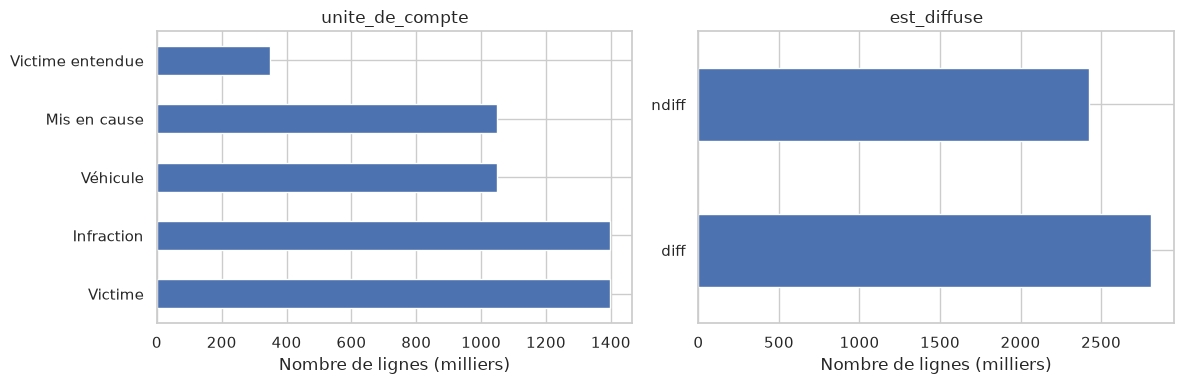

In [112]:
# Modalités et effectifs de chaque variable qualitative
for col in df_quali.columns:
    print(df_quali[col].value_counts(), "\n")

# Graphiques des deux variables qualitatives informatives
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["unite_de_compte", "est_diffuse"]):
    effectifs = df_quali[col].value_counts()
    (effectifs[effectifs > 0] / 1000).plot.barh(ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Nombre de lignes (milliers)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

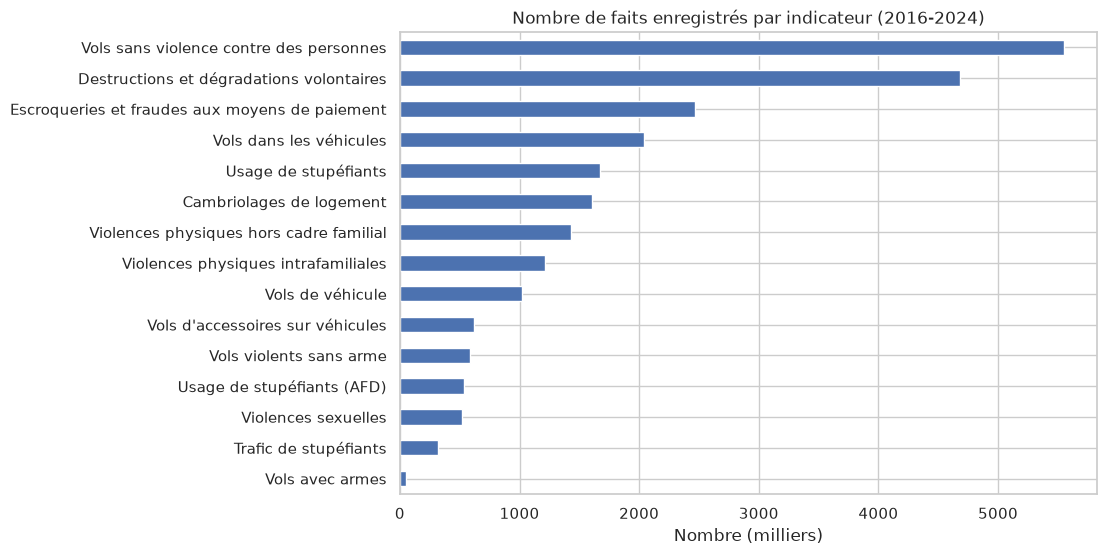

In [113]:
# Paris, Lyon, Marseille : on retire les arrondissements pour ne pas compter ces villes deux fois
sans_arr = delinq[~delinq["CODGEO_2026"].str.match(r"^(751|6938|132)")]

# 2025 est l'année de test : on la laisse de côté
sans_arr = sans_arr[sans_arr["annee"] <= 2024]

# Total des faits par indicateur, en milliers, du plus petit au plus grand
total = sans_arr.groupby("indicateur", observed=True)["nombre"].sum().sort_values() / 1000

total.plot.barh(figsize=(9, 6))
plt.title("Nombre de faits enregistrés par indicateur (2016-2024)")
plt.xlabel("Nombre (milliers)")
plt.ylabel("")
plt.show()

**Constat :**

*Variables qualitatives.*
- **`indicateur`** : 15 indicateurs, de 349 200 lignes chacun (34 920 codes × 10 années), ce qui confirme que la grille est complète. La liste des modalités de la colonne en annonce 18 : les trois autres (homicides, tentatives d'homicide, usage de stupéfiants hors AFD) ne sont publiés qu'au niveau départemental et n'ont aucune ligne dans la base communale.
- **`unite_de_compte`** : 5 unités (victime, victime entendue, infraction, véhicule, mis en cause). Les indicateurs ne se comptent pas dans la même unité : on ne peut pas les additionner entre eux.
- **`est_diffuse`** : près de la moitié des lignes sont masquées par le secret statistique (environ 2,4 millions sur 5,2 millions). Ce point est étudié dans la partie Qualité.

*Nombre de faits par indicateur (2016-2024, sans les arrondissements pour ne pas compter deux fois Paris, Lyon et Marseille).*
Deux indicateurs dominent : les vols sans violence contre des personnes (environ 5,5 millions de faits) et les destructions et dégradations volontaires (environ 4,7 millions). Les cambriolages de logement, l'indicateur le plus directement lié au logement, comptent environ 1,6 million de faits. Les vols avec armes sont très rares (quelques dizaines de milliers en neuf ans) : au niveau d'une commune ou d'un bassin de vie, ils seront presque toujours nuls ou masqués. Ces totaux sont un peu sous-estimés, car les communes masquées ne sont pas comptées.

*Variables non étudiées en détail.*
La seule information utile pour le projet est le croisement entre l'indicateur et sa mesure (nombre ou taux). Les autres variables servent à la calculer ou à l'interpréter, et ne sont donc pas décrites ici :
- `insee_pop` et `insee_log` sont la population et les logements utilisés pour calculer le taux. Leur valeur est la même pour les 15 indicateurs d'une commune ;
- `complement_info_nombre` et `complement_info_taux` ne sont remplis que pour les lignes masquées : ils sont étudiés avec les valeurs manquantes ;
- les millésimes indiquent l'année du recensement utilisé : ils serviront au recalcul des taux au bassin de vie.

**Impact projet :** tous les indicateurs ne sont pas exploitables. Les plus rares, comme les vols avec armes, seront trop souvent nuls ou masqués à l'échelle d'un bassin de vie.

**Action envisagée :** choisir les indicateurs à retenir après l'étude des valeurs manquantes, en tenant compte de leur fréquence et de leur lien avec le logement.

## C. Qualité

### 5. Doublons exacts

**Objectif :** repérer les lignes copiées, qui gonflent les effectifs.

In [114]:
# 1. Doublons exacts et doublons sur la clé commune × année × indicateur
print("Doublons exacts :", delinq.duplicated().sum())
print("Doublons sur la clé :", delinq.duplicated(subset=["CODGEO_2026", "annee", "indicateur"]).sum())

# 2. Paris, Lyon, Marseille : ville entière contre somme des arrondissements
plm = {
    "Paris":     ("75056", "751"),   # code de la ville, début des codes d'arrondissement
    "Lyon":      ("69123", "6938"),
    "Marseille": ("13055", "132"),
}
d = delinq[(delinq["annee"] == 2024) & (delinq["indicateur"] == "Cambriolages de logement")]
for ville, (code, prefixe) in plm.items():
    entiere = d[d["CODGEO_2026"] == code]
    arrond = d[d["CODGEO_2026"].str.startswith(prefixe)]
    print(f"{ville} 2024 | ville : {entiere['nombre'].sum():,.0f} cambriolages, {entiere['insee_pop'].sum():,.0f} hab. | "
          f"{len(arrond)} arrondissements : {arrond['nombre'].sum():,.0f} cambriolages, {arrond['insee_pop'].sum():,.0f} hab.")

Doublons exacts : 0
Doublons sur la clé : 0
Paris 2024 | ville : 9,235 cambriolages, 2,103,778 hab. | 20 arrondissements : 9,235 cambriolages, 2,103,778 hab.
Lyon 2024 | ville : 2,502 cambriolages, 519,127 hab. | 9 arrondissements : 2,502 cambriolages, 519,127 hab.
Marseille 2024 | ville : 4,471 cambriolages, 886,040 hab. | 16 arrondissements : 4,471 cambriolages, 886,040 hab.


**Constat :**

Aucun doublon exact et aucun doublon sur la clé commune × année × indicateur.

En revanche, Paris, Lyon et Marseille sont présentes à deux niveaux : la ville entière (75056, 69123, 13055) et ses arrondissements (20, 9 et 16). En 2024, pour les cambriolages de logement, le nombre de faits et la population de la ville sont exactement égaux à la somme de ses arrondissements : 9 235 cambriolages et 2 103 778 habitants pour Paris, 2 502 et 519 127 pour Lyon, 4 471 et 886 040 pour Marseille. Les deux niveaux décrivent donc les mêmes faits : ce sont des doublons métier.

**Impact projet :** additionner les deux niveaux compterait deux fois la délinquance de ces trois villes et fausserait tout total ou tout taux calculé au bassin de vie.

**Action envisagée :** ne jamais additionner la ville entière et ses arrondissements. Les deux niveaux sont conservés pour l'instant : le niveau retenu dépendra de la décision de l'équipe sur la maille des grandes villes (découpage par arrondissement ou non).

### 6. Valeurs manquantes

**Objectif :** mesurer l'ampleur des manquants par variable.

In [115]:
manquants = (delinq.isna().mean() * 100).round(2)
display(manquants[manquants > 0].sort_values(ascending=False))

complement_info_taux      53.69
complement_info_nombre    53.69
taux_pour_mille           46.33
nombre                    46.31
dtype: float64

In [116]:
# Lignes avec un nombre mais sans taux
ecart = delinq[delinq["nombre"].notna() & delinq["taux_pour_mille"].isna()]
print("Lignes concernées :", len(ecart))
display(ecart[["CODGEO_2026", "indicateur", "nombre", "insee_pop", "insee_log"]]
        .drop_duplicates("CODGEO_2026").head(10))

Lignes concernées : 849


,CODGEO_2026,indicateur,nombre,insee_pop,insee_log
300195,55039,Violences physiques intrafamiliales,0.0,0,0
300360,55050,Violences physiques intrafamiliales,0.0,0,0
301485,55139,Violences physiques intrafamiliales,0.0,0,1
302130,55189,Violences physiques intrafamiliales,0.0,0,0
302685,55239,Violences physiques intrafamiliales,0.0,0,0
303570,55307,Violences physiques intrafamiliales,0.0,0,0


In [117]:
# Le nombre est-il vide exactement quand la ligne est masquée ?
display(pd.crosstab(delinq["est_diffuse"], delinq["nombre"].isna().rename("nombre vide")))

# Le complément est-il rempli exactement quand la ligne est masquée ?
display(pd.crosstab(delinq["est_diffuse"], delinq["complement_info_nombre"].isna().rename("complément vide")))

nombre vide,False,True
est_diffuse,,
diff,2812128,0
ndiff,0,2425872


complément vide,False,True
est_diffuse,,
diff,0,2812128
ndiff,2425872,0


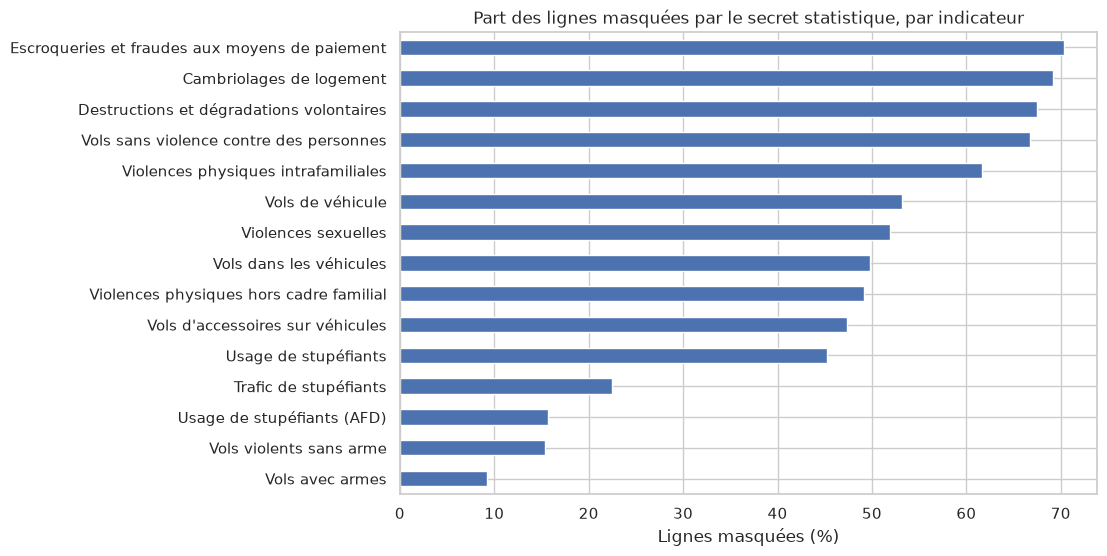

In [118]:
# Pour chaque indicateur, part des lignes diffusées et masquées (en %)
part = pd.crosstab(delinq["indicateur"], delinq["est_diffuse"], normalize="index") * 100

part["ndiff"].sort_values().plot.barh(figsize=(9, 6))
plt.title("Part des lignes masquées par le secret statistique, par indicateur")
plt.xlabel("Lignes masquées (%)")
plt.ylabel("")
plt.show()

**Constat :**

Seules quatre variables ont des valeurs manquantes :
- `nombre` (46,31 %) et `taux_pour_mille` (46,33 %) ;
- `complement_info_nombre` et `complement_info_taux` (53,69 %).

Les manquants s'expliquent entièrement par le secret statistique. Les 2 425 872 lignes masquées (`ndiff`) ont toutes un nombre vide et un complément rempli ; les 2 812 128 lignes diffusées ont toutes un nombre rempli et un complément vide. Le petit écart entre `nombre` et `taux_pour_mille` vient de six communes de la Meuse sans habitant (villages détruits pendant la bataille de Verdun) : le taux ne peut pas y être calculé.

La part de lignes masquées varie beaucoup selon l'indicateur : de 9 % pour les vols avec armes à 70 % pour les escroqueries, et 69 % pour les cambriolages de logement. Ce sont les indicateurs les plus fréquents qui sont le plus masqués. La règle de diffusion l'explique : une commune est publiée si elle a plus de 5 faits sur trois années successives, ou aucun fait pendant trois ans. Le masquage touche donc les communes qui ont quelques faits, sans en avoir assez. Pour un indicateur rare, la plupart des communes n'ont aucun fait : le zéro est publié.

Les manquants dépendent du nombre de faits lui-même, c'est-à-dire de la valeur qui manque : ils ne sont pas aléatoires.

**Impact projet :** une valeur masquée n'est pas une absence d'information : elle signifie « quelques faits ». La remplacer par 0 ou supprimer ces lignes fausserait les totaux par bassin de vie.

**Action envisagée :** au moment du preprocessing, utiliser le complément départemental (`complement_info_nombre`) pour tenir compte des faits des communes masquées dans les totaux par bassin de vie.

### 7 Distributions et valeurs extrêmes

**Objectif :** repérer les taux anormalement élevés et comprendre d'où ils viennent.

In [119]:
# Centiles du taux par indicateur (2024, communes diffusées, sans les arrondissements)
d24 = delinq[(delinq["annee"] == 2024)
             & ~delinq["CODGEO_2026"].str.match(r"^(751|6938|132)")
             & (delinq["est_diffuse"] == "diff")]
centiles = (d24.groupby("indicateur", observed=True)["taux_pour_mille"]
               .describe(percentiles=[0.50, 0.90, 0.99]).round(2))
centiles["max / p99"] = (centiles["max"] / centiles["99%"]).round(1)

display(centiles[["count", "50%", "90%", "99%", "max", "max / p99"]].sort_values("max / p99"))

,count,50%,90%,99%,max,max / p99
indicateur,,,,,,
Escroqueries et fraudes aux moyens de paiement,10344.0,4.86,7.83,10.91,32.61,3.0
Violences physiques intrafamiliales,12166.0,0.00,4.73,8.55,29.05,3.4
Cambriolages de logement,10715.0,0.00,9.40,19.15,67.87,3.5
Destructions et dégradations volontaires,11126.0,4.78,10.56,18.14,92.23,5.1
Violences sexuelles,14502.0,0.00,1.73,4.44,27.67,6.2
Vols de véhicule,15998.0,0.00,1.80,4.92,37.77,7.7
Violences physiques hors cadre familial,16975.0,0.00,2.93,7.84,74.07,9.4
Vols violents sans arme,29629.0,0.00,0.00,0.83,13.46,16.2
Vols sans violence contre des personnes,11297.0,0.00,7.93,24.62,1006.36,40.9


In [120]:
# Les 5 communes aux taux les plus élevés, pour deux indicateurs
cols = ["CODGEO_2026", "nombre", "taux_pour_mille", "insee_pop"]
for ind in ["Trafic de stupéfiants", "Vols sans violence contre des personnes"]:
    print(ind)
    display(d24[d24["indicateur"] == ind].nlargest(5, "taux_pour_mille")[cols])

Trafic de stupéfiants


,CODGEO_2026,nombre,taux_pour_mille,insee_pop
4711663,95527,510.0,190.725505,2674
4484878,54242,8.0,28.268551,283
4578283,66024,147.0,26.790596,5487
4704163,90062,7.0,24.822695,282
4713358,97307,779.0,21.335451,36512


Vols sans violence contre des personnes


,CODGEO_2026,nombre,taux_pour_mille,insee_pop
4711655,95527,2691.0,1006.357517,2674
4458980,50353,12.0,521.739130,23
4646960,77518,30.0,123.966942,242
4402970,38191,154.0,123.794212,1244
4623560,73257,433.0,123.785020,3498


**Constat :**

L'analyse porte sur 2024, dernière année hors test, pour avoir une ligne par commune. Les arrondissements sont retirés pour ne pas compter deux fois Paris, Lyon et Marseille. Seules les communes diffusées sont prises en compte. Les distributions sont décrites par un tableau de centiles plutôt que par des boîtes à moustaches : avec autant de zéros, les boîtes sont écrasées sur 0 et illisibles.

*Une majorité de zéros.* Pour 13 indicateurs sur 15, le taux médian vaut 0 : plus de la moitié des communes diffusées n'ont enregistré aucun fait en 2024. Seuls les escroqueries (médiane 4,9 pour 1 000) et les destructions et dégradations (4,8) ont une médiane non nulle. Pour quatre indicateurs (vols violents sans arme, usage de stupéfiants AFD, trafic de stupéfiants, vols avec armes), même le 90e centile vaut 0. Les vols avec armes sont nuls jusqu'au 99e centile.

*Des valeurs extrêmes très élevées.* Le rapport entre le maximum et le 99e centile va de 3 (escroqueries) à 160 (trafic de stupéfiants). Ce rapport est toutefois peu parlant pour les indicateurs presque toujours nuls : quand le 99e centile est proche de 0, le rapport devient très grand, voire infini pour les vols avec armes.

Les taux les plus élevés concernent des communes peu peuplées où passent beaucoup de personnes qui n'y habitent pas : Roissy-en-France (aéroport Charles-de-Gaulle, 2 674 habitants), avec 1 006 vols sans violence et 191 mis en cause pour trafic de stupéfiants pour 1 000 habitants, ou le Mont-Saint-Michel (23 habitants, 522 vols pour 1 000). Ce ne sont pas des erreurs, mais ces taux ne mesurent pas le risque pour les habitants.

**Impact projet :** le taux communal est instable dans les petites communes et trompeur dans les lieux très fréquentés. Il ne peut pas être utilisé tel quel. Les indicateurs presque toujours nuls (vols avec armes, vols violents sans arme, trafic de stupéfiants) apporteront peu d'information.

**Action envisagée :** recalculer les taux au bassin de vie, en additionnant les nombres de faits et les populations des communes. Les communes y pèsent selon leur taille, ce qui limite l'effet des valeurs extrêmes. Retenir en priorité les indicateurs fréquents et liés au cadre de vie.

#### Test des bassins de vie

In [121]:
# Table de correspondance : un bassin de vie par code commune 2026
liaison = pd.read_parquet(DATA_OUT / "liaison_commune_bv2022.parquet")
# La table de liaison contient une ligne pour chaque code 2026 : on la lit sur CODGEO_INI
liaison_2026 = liaison[["CODGEO_INI", "BV2022"]].rename(columns={"CODGEO_INI": "CODGEO_2026"})

bv = d24.merge(liaison_2026, on="CODGEO_2026", how="left", validate="many_to_one")

# Commune masquée : on remplace le nombre vide par la moyenne départementale des communes masquées
bv["nombre_estime"] = bv["nombre"].fillna(bv["complement_info_nombre"])

# Le taux des cambriolages se calcule pour 1 000 logements, les autres pour 1 000 habitants
bv["denominateur"] = np.where(bv["indicateur"] == "Cambriolages de logement",
                              bv["insee_log"], bv["insee_pop"])

# Somme des faits et des habitants (ou logements) par bassin, puis taux
taux_bv = bv.groupby(["BV2022", "indicateur"], observed=True)[["nombre_estime", "denominateur"]].sum()
taux_bv["taux_pour_mille"] = taux_bv["nombre_estime"] / taux_bv["denominateur"] * 1000

# Même tableau de centiles qu'au niveau communal
centiles_bv = (taux_bv.groupby("indicateur", observed=True)["taux_pour_mille"]
                      .describe(percentiles=[0.50, 0.90, 0.99]).round(2))
centiles_bv["max / p99"] = (centiles_bv["max"] / centiles_bv["99%"]).round(1)
display(centiles_bv[["count", "50%", "90%", "99%", "max", "max / p99"]].sort_values("max / p99"))

,count,50%,90%,99%,max,max / p99
indicateur,,,,,,
Destructions et dégradations volontaires,1695.0,7.28,11.23,16.09,19.37,1.2
Violences sexuelles,1609.0,1.57,2.96,4.79,7.17,1.5
Cambriolages de logement,1614.0,4.15,8.58,14.10,21.29,1.5
Violences physiques hors cadre familial,1652.0,2.37,4.75,7.60,12.93,1.7
Vols de véhicule,1601.0,0.74,2.86,5.15,9.29,1.8
Violences physiques intrafamiliales,1658.0,3.36,5.56,8.41,17.49,2.1
Escroqueries et fraudes aux moyens de paiement,1689.0,5.46,7.45,9.78,29.51,3.0
Vols dans les véhicules,1643.0,1.18,4.49,10.39,38.64,3.7
Vols sans violence contre des personnes,1686.0,4.83,9.35,20.04,93.80,4.7


*Test au bassin de vie.* Les taux ont été recalculés pour les 1 707 bassins de vie, en additionnant les faits et les habitants (ou les logements pour les cambriolages) des communes de chaque bassin. Pour les communes masquées, le nombre a été remplacé par la moyenne départementale des communes masquées (`complement_info_nombre`). Au bassin de vie, aucun indicateur n'a plus de médiane nulle, et le rapport entre le maximum et le 99e centile tombe à 1,4 à 10,7, contre 3 à 160 au niveau communal. Les cambriolages deviennent l'indicateur le plus régulier (maximum 17,6 pour 1 000 logements, contre 67,9 par commune). Les indicateurs sur les stupéfiants gardent des valeurs élevées dans quelques bassins : ils dépendent surtout de l'activité des services de police.

**Action envisagée :** travailler sur des taux recalculés au bassin de vie, en tenant compte des communes masquées par le complément départemental. Retenir en priorité les indicateurs fréquents et stables, comme les cambriolages et les destructions et dégradations.

## Synthèse du premier niveau d'audit — Délinquance enregistrée

#### Constat

La base de délinquance du SSMSI est une source pertinente pour décrire l'insécurité dans les communes. Elle est administrative : elle compte les crimes et délits enregistrés par la police et la gendarmerie, et non toute la délinquance. Son niveau dépend du dépôt de plainte, plus fréquent pour les cambriolages (74 %) que pour les violences sexuelles (12 %).

La base compte **5 238 000 lignes (une commune × une année × un indicateur) et 13 variables**. La grille est complète : 34 920 codes géographiques (communes de 2026 et arrondissements de Paris, Lyon et Marseille), 10 années de 2016 à 2025 et 15 indicateurs. Il n'existe pas de données communales pour 2014 et 2015.

L'examen de la base montre une qualité satisfaisante :
- aucun doublon exact ni sur la clé commune × année × indicateur ;
- Paris, Lyon et Marseille sont présentes à deux niveaux, la ville entière et ses arrondissements, qui décrivent exactement les mêmes faits : ce sont des doublons métier ;
- les valeurs manquantes s'expliquent entièrement par le **secret statistique**. 46 % des lignes sont masquées (de 9 % à 70 % selon l'indicateur), et la base fournit pour elles la moyenne départementale des communes masquées. Le taux manque aussi pour six villages détruits de la Meuse, sans habitant.

Au niveau communal, les taux sont difficiles à utiliser. Pour 13 indicateurs sur 15, la majorité des communes n'enregistre aucun fait. Quelques communes peu peuplées mais très fréquentées ont des taux extrêmes, comme Roissy-en-France (aéroport) ou le Mont-Saint-Michel. Au bassin de vie, les taux deviennent stables : plus aucune médiane nulle, et des valeurs extrêmes beaucoup moins isolées.

#### Conséquences pour le projet

- **Maille :** recalculer les taux au bassin de vie, en additionnant les faits et les habitants (ou les logements pour les cambriolages), et non en faisant la moyenne des taux communaux.
- **Communes masquées :** les remplacer par le complément départemental plutôt que par 0 ou par une suppression.
- **Paris, Lyon, Marseille :** ne jamais additionner la ville entière et ses arrondissements. Le niveau retenu dépendra de la décision sur la maille des grandes villes.
- **Période :** la délinquance ne peut décrire les prix qu'à partir de 2017 si l'on utilise l'année précédente. Les chiffres d'une année ne sont arrêtés qu'en avril de l'année suivante, ce qui compte pour éviter d'utiliser une information pas encore connue.
- **Indicateurs :** retenir en priorité les indicateurs fréquents, stables au bassin de vie et liés au cadre de vie, comme les cambriolages de logement et les destructions et dégradations. Les indicateurs sur les stupéfiants mesurent surtout l'activité des services, et les escroqueries sont comptées au domicile de la victime : ils décrivent mal le quartier.

# 7. LOVAC

**Contributeurs :** Théophyle CHEVET · **Date :** octobre 2026

Source : `lovac-open-data-2020-a-2026.xlsx` (Cerema), feuille communale « COM open data ».

In [122]:
import numpy as np
import pandas as pd

chemin_lovac = DATA_RAW / "lovac-open-data-2020-a-2026.xlsx"

# ── Chargement : feuille communale, tout en texte (les "s" empêchent la lecture en nombres) ──
lovac_brut = pd.read_excel(chemin_lovac, sheet_name="COM open data", dtype=str)
print("Dimensions :", lovac_brut.shape)
print(list(lovac_brut.columns))
display(lovac_brut.head(3))

# Les autres feuilles : métadonnées et totaux nationaux, régionaux, départementaux
print(pd.ExcelFile(chemin_lovac).sheet_names)

# ── Structure : une ligne = une commune ? ────────────────────────────────────
print("Codes commune uniques :", lovac_brut["CODGEO_26"].nunique(), "/", len(lovac_brut))
print("Longueur des codes :", lovac_brut["CODGEO_26"].str.len().unique())
print("Doublons exacts :", lovac_brut.duplicated().sum())

# Colonnes de chiffres : celles qui commencent par pp_ (parc privé) ou ff_ (fichiers fonciers)
colonnes_chiffres = []
for col in lovac_brut.columns:
    if col.startswith("pp_") or col.startswith("ff_"):
        colonnes_chiffres.append(col)
print(len(colonnes_chiffres), "colonnes de chiffres")

# ── Secret statistique : part de "s" par colonne ─────────────────────────────
secret = pd.DataFrame({"nb_s": (lovac_brut[colonnes_chiffres] == "s").sum(),
                       "% s": ((lovac_brut[colonnes_chiffres] == "s").mean() * 100).round(1)})
display(secret)

# Y a-t-il d'autres textes que "s" dans les colonnes de chiffres ?
for col in colonnes_chiffres:
    valeurs = lovac_brut[col].dropna()
    autres = valeurs[(valeurs != "s") & (~valeurs.str.isdigit())]
    if len(autres) > 0:
        print(col, ": valeurs inattendues", autres.unique()[:5])

# Valeurs manquantes "vraies" (cases vides)
manquants = lovac_brut.isna().sum()
print(manquants[manquants > 0])

# ── Territoire ───────────────────────────────────────────────────────────────
print("Départements :", lovac_brut["DEP"].nunique())
print("Mayotte (976) présente ?", (lovac_brut["DEP"] == "976").sum() > 0)
print("Communes d'Alsace-Moselle :", lovac_brut["DEP"].isin(["57", "67", "68"]).sum())
plm = (lovac_brut["CODGEO_26"].str[:3].isin(["751", "132"])) | (lovac_brut["CODGEO_26"].str[:4] == "6938")
print("Arrondissements Paris / Lyon / Marseille :", plm.sum(),
      "| codes 75056/69123/13055 :", lovac_brut["CODGEO_26"].isin(["75056", "69123", "13055"]).sum())

# ── Totaux nationaux par millésime (feuille FR) ──────────────────────────────
fr = pd.read_excel(chemin_lovac, sheet_name="FR")
display(fr)

# ── Cohérence et distribution (exemple du millésime 2023) ────────────────────
vac = pd.to_numeric(lovac_brut["pp_vacant_23"].replace("s", np.nan))
vac2 = pd.to_numeric(lovac_brut["pp_vacant_plus_2ans_23"].replace("s", np.nan))
parc = pd.to_numeric(lovac_brut["ff_pp_total_23"].replace("s", np.nan))
print("Vacants 2 ans > vacants :", (vac2 > vac).sum(), "| vacants > parc :", (vac > parc).sum())

taux = vac / parc * 100
print(taux.quantile([0.01, 0.25, 0.5, 0.75, 0.99]).round(1))
# Les taux les plus élevés : quelles communes ?
extremes = lovac_brut.assign(taux=taux).sort_values("taux").dropna(subset=["taux"]).tail(5)
display(extremes[["CODGEO_26", "LIBGEO_26", "DEP", "pp_vacant_23", "ff_pp_total_23", "taux"]])

Dimensions : (34912, 28)
['CODGEO_26', 'LIBGEO_26', 'pp_vacant_26', 'pp_vacant_plus_2ans_26', 'ff_pp_total_25', 'pp_vacant_25', 'pp_vacant_plus_2ans_25', 'ff_pp_total_24', 'pp_vacant_24', 'pp_vacant_plus_2ans_24', 'ff_pp_total_23', 'pp_vacant_23', 'pp_vacant_plus_2ans_23', 'ff_pp_total_22', 'pp_vacant_22', 'pp_vacant_plus_2ans_22', 'ff_pp_total_21', 'pp_vacant_21', 'pp_vacant_plus_2ans_21', 'ff_pp_total_20', 'pp_vacant_20', 'pp_vacant_plus_2ans_20', 'EPCI_26', 'LIB_EPCI_26', 'DEP', 'LIB_DEP', 'REG', 'LIB_REG']


,CODGEO_26,LIBGEO_26,pp_vacant_26,pp_vacant_plus_2ans_26,ff_pp_total_25,pp_vacant_25,pp_vacant_plus_2ans_25,ff_pp_total_24,pp_vacant_24,pp_vacant_plus_2ans_24,ff_pp_total_23,pp_vacant_23,pp_vacant_plus_2ans_23,ff_pp_total_22,pp_vacant_22,pp_vacant_plus_2ans_22,ff_pp_total_21,pp_vacant_21,pp_vacant_plus_2ans_21,ff_pp_total_20,pp_vacant_20,pp_vacant_plus_2ans_20,EPCI_26,LIB_EPCI_26,DEP,LIB_DEP,REG,LIB_REG
0,01001,L'Abergement-Clémenciat,16,s,361,s,s,358,15,s,355,15,s,353,27,s,340,16,s,339,20,s,200069193,Communauté de communes de la Dombes,01,Ain,84,Auvergne-Rhône-Alpes
1,01002,L'Abergement-de-Varey,16,s,180,s,s,180,11,s,180,s,s,181,s,s,181,s,s,181,13,s,240100883,Communauté de communes de la Plaine de l'Ain,01,Ain,84,Auvergne-Rhône-Alpes
2,01004,Ambérieu-en-Bugey,587,210,6005,374,207,5949,628,200,5918,626,188,5922,605,182,5843,678,190,5776,679,163,240100883,Communauté de communes de la Plaine de l'Ain,01,Ain,84,Auvergne-Rhône-Alpes


['Métadonnées', 'FR', 'REG', 'DEP', 'COM open data']
Codes commune uniques : 34912 / 34912
Longueur des codes : [5]
Doublons exacts : 0
20 colonnes de chiffres


,nb_s,% s
pp_vacant_26,6882,19.7
pp_vacant_plus_2ans_26,17767,50.9
ff_pp_total_25,18321,52.5
pp_vacant_25,9395,26.9
pp_vacant_plus_2ans_25,22135,63.4
ff_pp_total_24,18401,52.7
pp_vacant_24,6866,19.7
pp_vacant_plus_2ans_24,26927,77.1
ff_pp_total_23,18485,52.9
pp_vacant_23,7202,20.6


EPCI_26        1
LIB_EPCI_26    1
dtype: int64
Départements : 101
Mayotte (976) présente ? True
Communes d'Alsace-Moselle : 1605
Arrondissements Paris / Lyon / Marseille : 45 | codes 75056/69123/13055 : 0


,FR,Millésime,ff_pp_total,pp_vacant,pp_vacant_plus_2ans
0,France,2026,NaN,3160235,1179845
1,NaN,2025,33194351.0,2380076,1348470
2,NaN,2024,33022585.0,3687140,1154436
3,NaN,2023,32804764.0,3741093,1130129
4,NaN,2022,32562875.0,3559162,1139834
5,NaN,2021,32255155.0,3654082,1167654
6,NaN,2020,32033601.0,3639254,1114443


Vacants 2 ans > vacants : 0 | vacants > parc : 0
0.01     3.5
0.25     7.3
0.50    10.0
0.75    13.4
0.99    25.8
dtype: float64


,CODGEO_26,LIBGEO_26,DEP,pp_vacant_23,ff_pp_total_23,taux
25551,65199,Germ,65,409,674,60.682493
34869,97361,Awala-Yalimapo,973,281,295,95.254237
34868,97360,Apatou,973,989,1027,96.299903
34866,97357,Grand-Santi,973,1044,1065,98.028169
34870,97362,Papaichton,973,487,495,98.383838


### 1. Situer la source et ouvrir les données

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | Cerema (équipe DataFoncier), pour le ministère du Logement (DGALN), à partir des fichiers fiscaux de la DGFiP (fichier 1767 bis Com) et des Fichiers fonciers. | Onglet « Métadonnées » du fichier |
| Finalité initiale | Repérer les logements privés vacants pour le plan national « Zéro logement vacant » (outil des collectivités). Rien n'a été produit pour estimer des prix. | Aucun prix : pas de cible |
| Mode de collecte | Administratif : un logement privé est « vacant » s'il n'est déclaré occupé par personne au 1er janvier (taxe d'habitation, puis déclarations GMBI depuis 2023). Données exhaustives, pas un sondage. | Vacance « fiscale » : elle peut compter des logements en réalité occupés (déclarations manquantes, retards de mise à jour) |
| Extraction / mise à jour | Version open data publiée en juin 2026, millésimes 2020 à 2026, mise à jour annuelle. | Rupture de série depuis 2023 (fin de la taxe d'habitation, dispositif GMBI), signalée dans la note de version |
| Documentation / licence | Onglet « Métadonnées » : définitions, sources, requêtes, taux de secret, liens Cerema (doc-datafoncier.cerema.fr). Version « secrétisée » pour l'open data. | Licence à vérifier sur data.gouv.fr. Une incohérence de date dans la documentation (millésime 2023 annoncé au 01/01/2023, comme 2024) |
| Population / objets annoncés | Logements du parc **privé** (maisons et appartements à usage d'habitation, hors bailleurs sociaux), agrégés par commune. | Le parc social n'est pas couvert |
| Période / territoire | Situations au 1er janvier 2019 à 2025 (millésime N = situation au 1er janvier N-1). France entière, Mayotte comprise, géographie communale au 1er janvier 2026. | Géographie 2026 différente de celle du recensement (2024) |

**Constat :** LOVAC est une source administrative exhaustive sur les logements privés vacants, par commune et par année (7 millésimes), produite par le Cerema à partir des fichiers fiscaux. Elle ne contient aucun prix.

**Impact projet :** c'est une variable explicative annuelle : elle permet de respecter la règle « informations de l'année précédant la vente », ce que le recensement (un seul millésime) ne permet pas.

**Action envisagée :** charger la feuille communale en texte, traiter le secret statistique et la rupture de série avant tout usage.

**Incertitudes / limites :** vacance « fiscale », plus élevée que la vacance observée par le recensement ; rupture de série depuis 2023 ; documentation incohérente sur la date du millésime 2023.

### 2. Comprendre la structure et une ligne

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 34 912 lignes × 28 colonnes (feuille « COM open data ») ; 4 autres feuilles : métadonnées, totaux France, régions, départements. |
| Contenu général, en une phrase | Pour chaque commune et chaque millésime de 2020 à 2026 : nombre de logements privés vacants, vacants depuis plus de 2 ans, et parc privé total. |
| Unité d’observation | La commune (géographie 2026). Paris, Lyon et Marseille par arrondissement (45 codes, aucun 75056, 69123 ou 13055), comme DVF+ et le recensement. |
| Identifiants / clés possibles | `CODGEO_26` : unique (34 912 / 34 912), 5 caractères. `EPCI_26` (intercommunalité) : clé de regroupement. |
| Une ou plusieurs lignes par objet ? Pourquoi ? | Une ligne par commune, mais **les années sont en colonnes** (format « large ») : 3 variables × 7 millésimes. Il faudra passer au format « long » (une ligne par commune et par année) pour joindre avec les ventes. |
| Doublons exacts : nombre / proportion | 0 (0 %). |
| Répétitions métier : règle examinée / résultat | Code commune répété : aucun. |

**Constat :** une ligne par commune, code unique, aucun doublon ; les millésimes sont stockés en colonnes (format large).

**Impact projet :** ce format ne permet pas de joindre avec les ventes par année.

**Action envisagée :** passer au format long (34 912 communes × 7 millésimes = 244 384 lignes).

**Incertitudes / limites :** aucune.

### 3. Comprendre les variables

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| `CODGEO_26` | Code commune INSEE (géographie 2026) | Qualitative nominale (identifiant) | 5 caractères ; 34 912 valeurs | Texte : cohérent si lu en `str` |
| `LIBGEO_26` | Nom de la commune | Qualitative nominale | Texte | Texte : cohérent |
| `pp_vacant_XX` (XX = 20 à 26) | Logements privés vacants au 1er janvier de l'année XX-1 | Quantitative discrète (effectif exact) | Logements | **Texte : incohérent** (« s » pour le secret) → conversion nécessaire |
| `pp_vacant_plus_2ans_XX` | Logements privés vacants depuis plus de 2 ans | Quantitative discrète | Logements | Texte : incohérent (même raison) |
| `ff_pp_total_XX` (XX = 20 à 25) | Parc privé total (dénominateur des taux) | Quantitative discrète | Logements | Texte : incohérent ; **absent pour 2026** |
| `EPCI_26`, `LIB_EPCI_26` | Code et nom de l'intercommunalité | Qualitative nominale | 9 caractères | Texte : cohérent ; 1 manquant (Saint-Martin, 97127) |
| `DEP`, `LIB_DEP`, `REG`, `LIB_REG` | Département et région | Qualitative nominale | Codes | Texte : cohérent |

**Variables ambiguës / documentation manquante :** décalage entre le nom et la date (millésime 2026 = situation au 1er janvier 2025) ; la documentation annonce le 01/01/2023 pour les millésimes 2023 et 2024, sans doute une coquille pour 2023 ; pas de parc total en 2026.

**Utilité provisoire pour le projet :** taux de vacance du parc privé, taux de vacance de plus de 2 ans et évolution annuelle, comme indicateurs de tension et de déprise du marché.

**Si prédiction : disponibilité au moment de prédire / risques de fuite :** le millésime N est publié vers le milieu de l'année N. Pour une vente de l'année N, utiliser le millésime N au plus tard (situation au 1er janvier N-1) ; un millésime plus récent serait une fuite d'information.

**Constat :** 20 colonnes de chiffres stockées en texte à cause du code « s » ; noms de colonnes décalés d'un an par rapport à la date réelle ; parc total absent en 2026.

**Impact projet :** une mauvaise correspondance entre millésime et année de vente créerait une fuite de données ; sans parc total, pas de taux pour 2026.

**Action envisagée :** convertir « s » en valeur manquante puis en nombre ; créer une colonne « année de situation » et une colonne « année de vente associée ».

**Incertitudes / limites :** coquille probable dans la documentation pour le millésime 2023.

### 4. Vérifier le périmètre réel

| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| Population / objets | Logements privés uniquement | Environ 33 millions de logements privés (feuille FR, 2025), contre 38,6 millions de logements en tout (INSEE) | Parc social absent : la vacance des HLM n'est pas comptée |
| Temps | 7 millésimes (situations au 1er janvier 2019 à 2025) | 3,64 millions de vacants en 2019, 3,74 en 2022, **2,38 en 2024**, 3,16 en 2025 | Rupture de série : la chute de 2024 vient du changement de collecte, pas du marché |
| Géographie | France entière, 101 départements dont **Mayotte** ; 34 912 communes | 34 886 communes en commun avec le recensement 2022 ; 26 seulement dans LOVAC (Mayotte, nouvelles communes), 74 seulement dans le recensement (communes fusionnées depuis 2024) | Alsace-Moselle (1 605 communes) et Mayotte présentes mais absentes de DVF+ et DVF |
| Autre : taille des communes | Le secret touche surtout les petites communes | Parc caché : 85 % des communes de moins de 100 logements, 0 % au-delà de 10 000 | Les communes sous secret ne représentent que 9 % des logements |

**Constat :** la couverture est nationale (Mayotte comprise) mais limitée au parc privé, avec une rupture de série nette en 2024 et une géographie 2026 décalée de celle du recensement (100 communes sans correspondance).

**Impact projet :** les évolutions autour de 2023-2024 ne reflètent pas le marché ; les petites communes sont mal couvertes.

**Action envisagée :** signaler les millésimes après rupture ; exclure Alsace-Moselle et Mayotte à la jointure ; compter les communes sans correspondance lors de chaque jointure.

**Incertitudes / limites :** l'ampleur exacte de la rupture par commune est inconnue.

### 5. Repérer et investiguer les problèmes de qualité

#### 5.1 Valeurs manquantes

| Variable | Nombre / proportion | Codes d’absence possibles | Sens / structure observée |
|---|---|---|---|
| `pp_vacant_XX` | 19,7 % à 26,9 % selon le millésime | « s » (secret statistique) | Effectif caché pour protéger les petites communes ; aucune case vide |
| `pp_vacant_plus_2ans_XX` | 50,9 % à **77,1 %** (millésime 2024) | « s » | Effectifs plus petits, donc plus souvent cachés |
| `ff_pp_total_XX` | 52,5 % à 53,3 % ; **100 % en 2026** (colonne absente) | « s » | Le parc total est caché pour la moitié des communes |
| `EPCI_26` | 1 (Saint-Martin) | Case vide | Collectivité d'outre-mer sans EPCI |

**Hypothèse de mécanisme :** absence **non aléatoire** (MNAR par construction) : le secret s'applique quand les effectifs sont petits, donc il dépend de la valeur cachée elle-même. Il est fortement lié à la taille de la commune (V de Cramér = 0,61, graphique 2 de l'EDA).

**Éléments à l'appui et limites :** 85 % de secret sous 100 logements, 0 % au-delà de 10 000 ; les communes au parc connu regroupent 90,6 % des logements. Les règles exactes du secret fiscal ne sont pas détaillées dans le fichier.

#### 5.2 Formats, modalités et incohérences

| Variable(s) | Règle / point contrôlé | Nombre de cas | Exemple / explication possible |
|---|---|---|---|
| Colonnes `pp_` et `ff_` | Uniquement des chiffres ou « s » | 0 autre valeur | Format homogène, mais stocké en texte |
| `pp_vacant_plus_2ans` ≤ `pp_vacant` | Les vacants depuis plus de 2 ans font partie des vacants | 0 violation | Cohérent |
| `pp_vacant` ≤ `ff_pp_total` | Les vacants font partie du parc | 0 violation | Cohérent |
| Codes Paris, Lyon, Marseille | Codage par arrondissement | 45 arrondissements, 0 code commune entière | Même codage que DVF+ et le recensement |
| Nom des colonnes / date | Millésime N = situation au 1er janvier N-1 | Toutes les colonnes | Source de confusion : à recoder |

#### 5.3 Distributions et valeurs extrêmes

| Variable | Distribution / répartition | Particularité et effectif | Explication / vérification nécessaire |
|---|---|---|---|
| Taux de vacance du parc privé (millésime 2023) | Médiane 10,0 % ; 50 % des communes entre 7,3 % et 13,4 % ; 99e centile 25,8 % | 105 communes à 0 vacant ; maximum 98,4 % | Valeurs plus élevées que le recensement (médiane 7,5 %) : vacance fiscale |
| Taux extrêmes | Au-delà de 90 % | Communes de Guyane (Papaïchton, Grand-Santi, Apatou, Awala-Yalimapo) | **Erreur probable ou autre population** : habitat peu déclaré fiscalement, pas une vraie vacance |
| | Autour de 60 % | Germ (65), station de ski | **Mauvais classement probable** : des résidences secondaires non déclarées comptées comme vacantes |
| Part de la vacance longue parmi les vacants | Médiane 41 % | — | Environ 4 logements vacants sur 10 le sont depuis plus de 2 ans |

**Constat :** pas d'incohérence entre les effectifs, mais un secret statistique massif et non aléatoire (53 % des communes pour le parc total, jusqu'à 77 % pour la vacance longue), concentré sur les petites communes. Les taux extrêmes (Guyane, stations de ski) relèvent d'artefacts fiscaux plutôt que d'une vraie vacance.

**Impact projet :** sans traitement, le taux de vacance serait manquant pour plus de la moitié des communes, presque toutes rurales : un biais de couverture.

**Action envisagée :** convertir « s » en valeur manquante ; compléter les taux cachés par le taux de l'intercommunalité (EPCI), en signalant ces valeurs ; signaler l'outre-mer et les communes touristiques comme moins fiables.

**Incertitudes / limites :** l'imputation par l'EPCI suppose que les petites communes ressemblent à leurs voisines, alors que le taux de l'EPCI est calculé surtout sur les plus grandes communes.

# 8. Équipements et sources complémentaires

**Contributeurs :** Christian · **Date :** octobre 2026

Analyses descriptives de trois sources : l'évolution nationale des taux de crédit, la part des ménages d'une personne dans les communes du Haut-Rhin et les types d'équipements de la BPE 2025 dans le Haut-Rhin.

**Les calculs de ces analyses sont faits par des scripts externes (`graphique_01_taux_credit.py`, `graphique_02_menages_seuls_par_commune.py`, `graphique_03_bpe25_types_equipements.py`) qui ne sont pas dans le dépôt : seuls les textes sont repris ici, sans code ni résultats chiffrés.**

### 1. Évolution mensuelle des taux de crédit immobilier

**Question métier.** Comment le contexte national de financement immobilier a-t-il évolué au fil de la série disponible ?

**Source et périmètre.** Export Webstat de la Banque de France, série `MIR1.M.FR.B.A22.A.R.A.2254U6.EUR.N` : taux annuel des crédits nouveaux à l'habitat des particuliers, en pourcentage, observé en fin de mois. La série est nationale et mensuelle.

**Méthode et contrôles.** Le script dédié lit les métadonnées et les observations, convertit explicitement les décimales, contrôle les dates et valeurs, les doublons, les mois manquants et l'ordre de la série. Il calcule minimum, maximum, moyenne, médiane, variations en points de pourcentage et nombre de hausses, baisses et mois stables. Aucun mois n'est interpolé.

**Interprétation et limites.** Les bornes, le centre de la série et le décompte des mouvements décrivent le contexte national observé ; ils ne signifient pas que le taux a évolué continûment dans un seul sens. Cette série ne mesure pas les conditions offertes à un emprunteur donné, les prix ou la demande locale. Elle ne permet pas d'établir de causalité avec les prix immobiliers.

### 2. Part des ménages d'une personne par commune du Haut-Rhin

**Question métier.** Comment varie, entre communes, la part des ménages composés d'une seule personne ?

**Source et périmètre.** Base INSEE Couples, familles et ménages 2022 et son dictionnaire. L'analyse retient les lignes communales du département 68 ; les lignes au niveau IRIS ne sont pas mélangées au périmètre communal.

**Méthode et contrôles.** L'indicateur est `C22_MENPSEUL / C22_MEN × 100`. Le script vérifie les définitions du dictionnaire, les codes géographiques et l'identification des communes (`IRIS = COM + 0000`), l'unicité, les valeurs numériques finies, les dénominateurs positifs et la cohérence des effectifs. Les statistiques et les valeurs atypiques de Tukey sont calculées selon la méthode inclusive déjà retenue dans le script.

**Interprétation et limites.** La médiane et l'intervalle interquartile décrivent la distribution entre communes ; la moyenne est une moyenne **non pondérée** des proportions communales et ne correspond pas à la proportion globale du département. L'indicateur porte sur les ménages, pas sur les personnes. Les écarts observés n'en expliquent pas les causes et le millésime 2022 ne décrit pas une évolution temporelle.

### 3. Types d'équipements enregistrés dans la BPE 2025

**Question métier.** Quels types sont les plus fréquents parmi les enregistrements de la Base permanente des équipements dans le Haut-Rhin ?

**Source et périmètre.** `BPE25.csv`, millésime 2025, filtre `DEP = '68'`, avec les trois nomenclatures officielles locales. Les effectifs portent sur les lignes BPE filtrées.

**Méthode et contrôles.** Le script dédié vérifie les nomenclatures, filtre et compte les lignes en flux, contrôle les codes observés et confronte les totaux aux contrôles de référence du script. Le classement présente les dix premiers types et un agrégat exact des autres catégories ; aucune jointure avec les deux autres sources n'est faite. Le fichier de plus de 1 Go n'est pas chargé intégralement en mémoire.

**Interprétation et limites.** Le classement décrit la composition des enregistrements BPE du périmètre, et non l'accessibilité, la qualité ou l'adéquation des services aux besoins locaux. Une ligne n'est pas nécessairement un équipement physique unique ; aucune déduplication n'est appliquée. « Autres types » masque le détail des catégories après le dixième rang, et l'absence d'une modalité dans les lignes ne prouve pas l'absence réelle du service.

### Synthèse générale

Les trois analyses apportent des repères descriptifs distincts : contexte national du crédit, dispersion communale d'un indicateur de ménages en 2022 et composition des enregistrements BPE 2025 dans le Haut-Rhin. Les unités, les territoires et les périodes diffèrent ; ces sources ne sont ni jointes ni interprétées comme des explications causales du marché immobilier.

Les résultats ne peuvent être présentés comme validés qu'après exécution du notebook dans un environnement contenant Matplotlib et les dépendances des scripts, puis comparaison des sorties avec les comptes rendus de référence.

## Audit rapide : BPE en évolution (2015, 2020, 2025)

**Contributeurs :** Cécile · **Date :** 25/10/2026

Jeu de données Insee DS_BPE_EVOLUTION (catalogue Melodi) : nombre d'équipements par type, par territoire et par année, sur trois années espacées de 5 ans, comparables dans le temps. On vérifie son contenu, ses mailles géographiques (le bassin de vie est-il disponible ?) et ses années.

In [ ]:
# BPE en évolution (source bpe_evolution du téléchargement), lue en texte
fichier = DATA_RAW / "DS_BPE_EVOLUTION_2025_data.csv"
separateur = ";" if ";" in fichier.open(encoding="utf-8").readline() else ","   # séparateur lu sur la 1re ligne
bpe_evol = pd.read_csv(fichier, sep=separateur, dtype=str)

In [4]:
# Structure, mailles géographiques, années, types d'équipements
print("Lignes :", len(bpe_evol), "| colonnes :", bpe_evol.shape[1])
display(bpe_evol.head())

# Pour chaque colonne : nombre de valeurs différentes, valeurs manquantes et premiers exemples
for col in bpe_evol.columns:
    valeurs = bpe_evol[col].dropna().unique()
    print(f"{col} : {len(valeurs)} valeurs différentes | manquantes : {bpe_evol[col].isna().sum()} | "
          f"exemples : {list(valeurs[:8])}")

# Mailles géographiques disponibles et nombre de territoires pour chacune
print(bpe_evol.groupby("GEO_OBJECT")["GEO"].nunique().sort_values(ascending=False))

Lignes : 1922859 | colonnes : 9


,GEO,GEO_OBJECT,FACILITY_TYPE,BPE_MEASURE,UNIT_MULT,UNIT_MEASURE,OBS_STATUS,TIME_PERIOD,OBS_VALUE
0,FM,FRANCE,F127,FACILITIES,0,NR,O,2015,NaN
1,FM,FRANCE,D252,FACILITIES,0,NR,O,2015,NaN
2,FM,FRANCE,F130,FACILITIES,0,NR,O,2015,NaN
3,FM,FRANCE,D108,FACILITIES,0,NR,O,2015,NaN
4,F,FRANCE,D253,FACILITIES,0,NR,O,2015,NaN


GEO : 6521 valeurs différentes | manquantes : 0 | exemples : ['FM', 'F', '13056', '14366', '14371', '14431', '13103', '13104']
GEO_OBJECT : 9 valeurs différentes | manquantes : 0 | exemples : ['FRANCE', 'BV2022', 'UU2020', 'AAV2020', 'DEP', 'REG', 'ARR', 'EPCI']
FACILITY_TYPE : 152 valeurs différentes | manquantes : 0 | exemples : ['F127', 'D252', 'F130', 'D108', 'D253', 'A126', 'B307', 'B310']
BPE_MEASURE : 1 valeurs différentes | manquantes : 0 | exemples : ['FACILITIES']
UNIT_MULT : 1 valeurs différentes | manquantes : 0 | exemples : ['0']
UNIT_MEASURE : 1 valeurs différentes | manquantes : 0 | exemples : ['NR']
OBS_STATUS : 2 valeurs différentes | manquantes : 0 | exemples : ['O', 'A']
TIME_PERIOD : 3 valeurs différentes | manquantes : 0 | exemples : ['2015', '2020', '2025']
OBS_VALUE : 4029 valeurs différentes | manquantes : 158836 | exemples : ['17', '5', '22', '13', '4', '2', '11', '1']
GEO_OBJECT
UU2020     2473
BV2022     1707
EPCI       1253
AAV2020     699
ARR         333
ZE

In [5]:
# BPE en évolution au bassin de vie : bassins couverts, valeurs manquantes, types renseignés par année
bv_equip = bpe_evol[bpe_evol["GEO_OBJECT"] == "BV2022"].copy()
bv_equip["OBS_VALUE"] = pd.to_numeric(bv_equip["OBS_VALUE"])
print("Lignes au bassin de vie :", len(bv_equip), "| bassins :", bv_equip["GEO"].nunique())

# Les valeurs manquantes correspondent-elles au statut « O » ?
display(pd.crosstab(bv_equip["OBS_STATUS"], bv_equip["OBS_VALUE"].isna().rename("valeur manquante")))

# Nombre de types d'équipements renseignés chaque année, et sur combien d'années chaque type est renseigné
renseigne = bv_equip.dropna(subset=["OBS_VALUE"])
display(renseigne.groupby("TIME_PERIOD")["FACILITY_TYPE"].nunique().rename("types renseignés"))
print("Nombre de types selon le nombre d'années renseignées :")
display(renseigne.groupby("FACILITY_TYPE")["TIME_PERIOD"].nunique().value_counts().rename("nombre de types"))

# Correspondance avec les bassins de la table de liaison
bassins_liaison = set(pd.read_parquet(DATA_OUT / "liaison_commune_bv2022.parquet")["BV2022"].dropna())
bassins_bpe = set(bv_equip["GEO"])
print("Bassins de la liaison absents de la BPE :", len(bassins_liaison - bassins_bpe),
      "| bassins de la BPE absents de la liaison :", len(bassins_bpe - bassins_liaison))

Lignes au bassin de vie : 480339 | bassins : 1707


valeur manquante,False,True
OBS_STATUS,,
A,442095,0
O,0,38244


TIME_PERIOD
2015    109
2020    151
2025    152
Name: types renseignés, dtype: int64

Nombre de types selon le nombre d'années renseignées :


TIME_PERIOD
3    108
2     44
Name: nombre de types, dtype: int64

Bassins de la liaison absents de la BPE : 0 | bassins de la BPE absents de la liaison : 0


**Lecture de l'audit**

- **Maille** : le fichier contient directement le bassin de vie (zonage BV2022), le même que notre table de liaison : 1 707 bassins, avec une correspondance parfaite dans les deux sens (aucun bassin manquant d'un côté ou de l'autre). Aucun passage par les communes n'est nécessaire.
- **Années** : 2015, 2020 et 2025, au 1er janvier, comparables dans le temps selon l'Insee.
- **Types d'équipements** : 152 au total ; 108 sont renseignés les trois années, 44 seulement deux années (surtout 2020 et 2025 : 109 types en 2015, 151 en 2020, 152 en 2025).
- **Valeurs manquantes** : elles correspondent toutes au statut « O » (valeur non diffusée) et toutes les valeurs présentes au statut « A » (valeur normale). Ce sont des types d'équipements non retenus pour une année donnée, pas des erreurs.
- **Colonnes inutiles** : BPE_MEASURE, UNIT_MULT et UNIT_MEASURE n'ont qu'une seule valeur.

**Impact projet** : cette source donne des comptages officiels d'équipements au bassin de vie, comparables entre 2015, 2020 et 2025, ce que ne garantit pas la comparaison de deux millésimes ordinaires de la BPE. Elle permet aussi de mesurer directement l'hypothèse de stabilité des équipements, en comparant 2015 et 2020 sur les 108 types renseignés les deux années.

In [6]:
# Au bassin de vie : combien de bassins n'ont aucune poste ou aucune boulangerie ?
CODES = {"bureau de poste": "A206", "boulangerie": "B207"}

for nom, code in CODES.items():
    eq = bv_equip[(bv_equip["FACILITY_TYPE"] == code)].dropna(subset=["OBS_VALUE"])
    sans = eq[eq["OBS_VALUE"] == 0].groupby("TIME_PERIOD")["GEO"].nunique()
    total = eq.groupby("TIME_PERIOD")["GEO"].nunique()
    print(f"{nom} ({code}) : bassins sans aucun équipement par année :",
          {annee: f"{sans.get(annee, 0)} sur {total[annee]}" for annee in total.index})

bureau de poste (A206) : bassins sans aucun équipement par année : {'2015': '0 sur 1706', '2020': '6 sur 1706', '2025': '41 sur 1706'}
boulangerie (B207) : bassins sans aucun équipement par année : {'2015': '1 sur 1707', '2020': '0 sur 1707', '2025': '1 sur 1707'}


**Bassins de vie sans bureau de poste ou sans boulangerie**

| Équipement | 2015 | 2020 | 2025 |
|---|---|---|---|
| Bureau de poste (A206) | 0 bassin sur 1 706 | 6 | 41 |
| Boulangerie-pâtisserie (B207) | 1 bassin sur 1 707 | 0 | 1 |

- **À la maille du bassin de vie, la présence ou l'absence de ces équipements ne distingue presque aucun territoire** : en 2020, seuls 6 bassins n'ont pas de bureau de poste et aucun n'est sans boulangerie. Les indicateurs de présence calculés à la commune perdent leur intérêt une fois agrégés au bassin ; il faudrait utiliser le nombre d'équipements, rapporté à la population.
- **Les bureaux de poste ne sont pas stables dans le temps** : le nombre de bassins qui n'en ont plus aucun passe de 0 en 2015 à 41 en 2025. L'hypothèse « les équipements restent en place » ne tient donc pas pour tous les équipements. Hypothèse : une partie de ces bureaux a pu être transformée en agence postale communale ou en relais poste, qui sont des types d'équipements distincts dans la BPE.

### Concordance avec la BPE 2025 communale
Pour de futures sous-unités de bassin (ville-centre, reste du bassin), il faudra des nombres par commune, absents de la BPE en évolution. On vérifie que la BPE 2025 communale (une ligne par équipement) donne les mêmes nombres au bassin de vie.

In [7]:
bpe25 = pd.read_parquet(DATA_RAW / "BPE25.parquet")
print(bpe25.shape)

# Nombre d'équipements par bassin et par type dans BPE25, comparé à la BPE en évolution (2025)
compte_bv = bpe25.groupby(["BV2022", "TYPEQU"]).size().rename("nb_bpe25").reset_index()
evol_2025 = bv_equip[bv_equip["TIME_PERIOD"] == "2025"][["GEO", "FACILITY_TYPE", "OBS_VALUE"]]
compar = evol_2025.merge(compte_bv, left_on=["GEO", "FACILITY_TYPE"],
                         right_on=["BV2022", "TYPEQU"], how="left")
compar["nb_bpe25"] = compar["nb_bpe25"].fillna(0)   # type absent du bassin dans BPE25 = 0 équipement

print("Lignes comparées :", len(compar))
print("Valeurs identiques :", (compar["OBS_VALUE"] == compar["nb_bpe25"]).mean().round(3))

(2921770, 95)
Lignes comparées : 160113
Valeurs identiques : 0.99


### Types d'équipements par domaine
La première lettre du code d'équipement donne le domaine de la BPE. On compte, pour chaque domaine, le nombre de types, ceux renseignés les trois années, et le nombre total d'équipements (bassins de métropole).

In [11]:
DOMAINES = {"A": "Services aux particuliers", "B": "Commerces", "C": "Enseignement",
            "D": "Santé et action sociale", "E": "Transports et déplacements",
            "F": "Sports, loisirs et culture", "G": "Tourisme"}

# Bassins de métropole seulement (outre-mer hors périmètre de DVF+)
metro = bv_equip[~bv_equip["GEO"].str.startswith("97")].copy()
metro["domaine"] = metro["FACILITY_TYPE"].str[0].map(DOMAINES)

# Nombre de types par domaine, et types renseignés les trois années
annees_renseignees = metro.dropna(subset=["OBS_VALUE"]).groupby("FACILITY_TYPE")["TIME_PERIOD"].nunique()
types = metro[["FACILITY_TYPE", "domaine"]].drop_duplicates()
types["trois_annees"] = types["FACILITY_TYPE"].map(annees_renseignees) == 3

tableau = types.groupby("domaine").agg(types=("FACILITY_TYPE", "size"),
                                       types_3_annees=("trois_annees", "sum"))

# Nombre total d'équipements par domaine et par année
total = metro.pivot_table(index="domaine", columns="TIME_PERIOD", values="OBS_VALUE", aggfunc="sum")
display(tableau.join(total))

,types,types_3_annees,2015,2020,2025
domaine,,,,,
Commerces,34,34,369405.0,365178.0,360632.0
Enseignement,3,3,1247.0,1206.0,1203.0
Santé et action sociale,56,23,46661.0,347549.0,387697.0
Services aux particuliers,31,29,927490.0,1072436.0,1292456.0
"Sports, loisirs et culture",21,13,89502.0,187783.0,189113.0
Tourisme,4,3,31373.0,41830.0,43153.0
Transports et déplacements,3,3,47723.0,75157.0,97436.0


**Lecture :**
- **Commerces** : les 34 types sont renseignés les trois années ; le nombre d'équipements est stable (369 000 en 2015, 361 000 en 2025).
- **Santé et action sociale** : 33 types sur 56 manquent en 2015. Le total de 2015 (47 000) n'est donc pas comparable à celui de 2020 (348 000) : la hausse vient surtout des types ajoutés, pas d'une vraie évolution.
- **Sports, loisirs et culture** : même problème, 8 types sur 21 manquent en 2015.
- **Services aux particuliers** : 29 types sur 31 renseignés les trois années, et pourtant une forte hausse (+39 % entre 2015 et 2025). Hypothèse : une partie vient de la création de micro-entreprises (artisans, services à domicile), à vérifier type par type.
- **Transports et déplacements** : 3 types seulement, nombre doublé entre 2015 et 2025. Hypothèse : hausse des taxis et VTC, à vérifier.
- **Enseignement** : 3 types seulement, environ 1 200 équipements. L'Insee a exclu les équipements de l'Éducation nationale de ce fichier : le domaine est presque vide.

**Impact projet :** additionner les équipements par domaine mélange des types aux évolutions très différentes, et toute comparaison avec 2015 doit se limiter aux 108 types renseignés les trois années.

## Audit de la BPE 2025 par commune

**Contributeurs :** Cécile · **Date :** octobre 2026

Fichier `BPE25.parquet` (source `bpe`) : une ligne par équipement, avec sa commune. Il sert à compter les équipements par commune, puis par sous-bassin, dans le feature engineering.

### Structure du fichier

In [ ]:
bpe = pd.read_parquet(DATA_RAW / "BPE25.parquet")

print(bpe.shape)
print(bpe.dtypes)
display(bpe.head())

# Colonnes de texte : nombre de valeurs différentes et exemples (pour repérer la commune et le type d'équipement)
for col in bpe.columns:
    if bpe[col].dtype == object:
        print(col, ":", bpe[col].nunique(), "valeurs, ex.", bpe[col].dropna().unique()[:5].tolist())

### Colonnes, commune et type d'équipement

In [ ]:
# Liste complète des 95 colonnes
print(bpe.columns.tolist())

# Colonnes candidates pour la commune, le type et le domaine d'équipement
for col in ["DEPCOM", "DEP", "TYPEQU", "DOM", "SDOM", "BV2022"]:
    if col in bpe.columns:
        print(col, ":", bpe[col].nunique(), "valeurs, ex.", bpe[col].dropna().unique()[:8].tolist())

# Paris, Lyon, Marseille : arrondissements ou ville entière ?
if "DEPCOM" in bpe.columns:
    plm = bpe["DEPCOM"].str.match(r"^(751|6938|132)")
    print("Codes de Paris, Lyon, Marseille :", sorted(bpe.loc[plm, "DEPCOM"].unique())[:10])
    print("Villes entières présentes :", bpe["DEPCOM"].isin(["75056", "69123", "13055"]).sum(), "lignes")

### Quels types d'équipement compter ? Comparaison avec la BPE en évolution

In [ ]:
DOMAINES = {"A": "services", "B": "commerces", "D": "sante",
            "E": "transports", "F": "sports", "G": "tourisme"}   # C (enseignement) exclu

# BPE 2025 : métropole, 6 domaines
bpe25 = bpe[~bpe["DEP"].str.startswith("97") & bpe["DOM"].isin(DOMAINES)]

# BPE en évolution, 2025, au bassin de vie, métropole
evo = pd.read_csv(DATA_RAW / "DS_BPE_EVOLUTION_2025_data.csv", sep=None, engine="python", dtype=str)
evo = evo[(evo["GEO_OBJECT"] == "BV2022") & (evo["TIME_PERIOD"] == "2025")
          & ~evo["GEO"].str.startswith("97") & evo["FACILITY_TYPE"].str[0].isin(DOMAINES)].copy()
evo["OBS_VALUE"] = pd.to_numeric(evo["OBS_VALUE"])

# Types communs aux deux fichiers
types25, types_evo = set(bpe25["TYPEQU"]), set(evo["FACILITY_TYPE"])
print("Types BPE 2025 :", len(types25), "| BPE en évolution :", len(types_evo),
      "| communs :", len(types25 & types_evo))
print("Types seulement dans la BPE 2025 :", sorted(types25 - types_evo))
print("Équipements de ces types :", bpe25["TYPEQU"].isin(types25 - types_evo).sum(), "sur", len(bpe25))

# Concordance au bassin de vie : nombre d'équipements par bassin dans les deux fichiers
total_evo = evo.groupby("GEO")["OBS_VALUE"].sum()
for nom, b in [("option 1 (tous les types)", bpe25),
               ("option 2 (types communs)", bpe25[bpe25["TYPEQU"].isin(types_evo)])]:
    total25 = b.groupby("BV2022").size()
    ecart = (total25 / total_evo).dropna()
    print(nom, ": rapport BPE 2025 / évolution par bassin, médiane =", round(ecart.median(), 3),
          "| bassins à moins de 1 % d'écart :", round(((ecart - 1).abs() < 0.01).mean() * 100, 1), "%")

**Constat :** la BPE 2025 compte 209 types d'équipement dans les 6 domaines retenus, la BPE en évolution 149, dont 147 en commun. Les 62 types propres à la BPE 2025 représentent 14 % des équipements (385 808 sur 2 752 078). Avec tous les types, le nombre d'équipements par bassin dépasse de 17 % celui de la BPE en évolution (médiane du rapport : 1,174) et aucun bassin n'est à moins de 1 % d'écart. Avec les seuls types communs, la médiane du rapport est de 0,998 et 97,4 % des bassins sont à moins de 1 % d'écart.

**Décision :** on ne compte que les types communs aux deux fichiers. Les nombres d'équipements restent comparables à ceux de l'EDA complémentaire, dont les constats (liens avec le prix, stabilité entre millésimes) restent valables.

# 9. Taux des crédits immobiliers

**Contributeurs :** Gabrielle RICHERT · **Date :** 13/10/2026

Source : `Taux d'intérêt annuel des crédits immobiliers.csv` (Banque de France, Webstat).

### 1. Situer la source et ouvrir les données

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine |Banque de France FR2 | aucun fichier de métadonnées associé|
| Finalité initiale | | |
| Mode de collecte | aucune information| |
| Extraction / mise à jour |aucune information | |
| Documentation / licence | aucune information| |
| Population / objets annoncés |France | |
| Période / territoire, si pertinents |de décembre 98 jusqu'à août 2026| |

In [123]:
# 6 lignes de métadonnées en tête de fichier, pas de ligne d'en-tête
taux = pd.read_csv(DATA_RAW / "Taux d'intérêt annuel des crédits immobiliers.csv",
                   sep=";", skiprows=6, header=None, names=["date", "taux"])

# Taux en nombre (virgule décimale) et date en vraie date, pour le graphique
taux["taux"] = pd.to_numeric(taux["taux"].str.replace(",", ".", regex=False))
taux["date"] = pd.to_datetime(taux["date"])

In [124]:
taux.head()

,date,taux
0,2026-08-31,3.21
1,2026-07-31,3.18
2,2026-06-30,3.17
3,2026-05-31,3.11
4,2026-04-30,3.12


In [125]:
# La colonne date est du texte ("2020-01") : on la convertit en vraie date
date = pd.to_datetime(taux["date"])

# Date de la plus ancienne et de la plus récente annonce
print("Du", date.min(), "au", date.max())

# Nombre d'annonces par année, triées dans l'ordre chronologique
print(date.dt.year.value_counts().sort_index())

Du 1998-12-31 00:00:00 au 2026-08-31 00:00:00
date
1998     1
1999    12
2000    12
2001    12
2002    12
2003    12
2004    12
2005    12
2006    12
2007    12
2008    12
2009    12
2010    12
2011    12
2012    12
2013    12
2014    12
2015    12
2016    12
2017    12
2018    12
2019    12
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
2026     8
Name: count, dtype: int64


### 2. Comprendre la structure et une ligne

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 333 lignes × 2 colonnes |
| Contenu général, en une phrase | taux des crédits immobiliers par mois de décembre 98 à août 2026|
| Unité d’observation | un taux en % mensuel|
| Identifiants / clés possibles | pas d'identifiant/références par date |
| Une ou plusieurs lignes par objet ? Pourquoi ? | non applicable, il n'y a qu'un taux par mois même si le taux peut être identique pendant plusieurs mois |
| Doublons exacts : nombre / proportion | 0 (0 %)|
| Répétitions métier : règle examinée / résultat | non applicable |

In [126]:
print(taux.shape) 
taux.info() 

# On regarde s'il y a des doublons exacts dans le dataset sans prendre en compte l'Index
taux.duplicated().sum() 

(333, 2)
<class 'pandas.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    333 non-null    datetime64[us]
 1   taux    333 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 5.3 KB


np.int64(0)

**Constat :**

Le jeu `taux` contient un taux de crédit immobilier moyen par mois en %.

**Impact projet :**

Utilisation de l'évolution des taux au cours du temps pour voir leur impact sur le prix de vente/achat des biens.

**Action envisagée :**

Attention à la colonne `date`, au départ la date n'était que mensuelle (exemble janvier 2026) mais avec la fonction to_datetime elle passe en JJ/MM/AAA.

**Incertitudes / limites, si nécessaire :**

Fichier très simple, uniquement en supplément et pas en analyse seule.

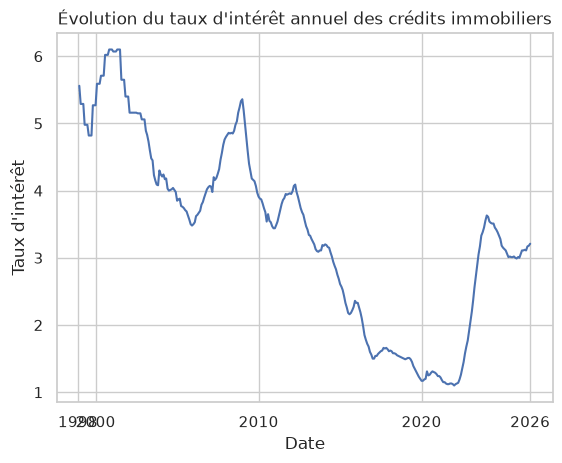

In [127]:
import datetime
annees_graphe=[datetime.date(1998,12,1), datetime.date(2000,1,1), datetime.date(2010,1,1), datetime.date(2020,1,1), datetime.date(2026,8,31)]
libelles=['1998','2000', '2010', '2020', '2026']

plt.plot(taux["date"], taux["taux"])
plt.xlabel("Date")
plt.xticks(annees_graphe, libelles)
plt.ylabel("Taux d'intérêt")
plt.locator_params(axis='y', nbins=10)
plt.title("Évolution du taux d'intérêt annuel des crédits immobiliers")
plt.show()

# 10. Annonces de vente (Haut-Rhin)

**Contributeurs :** Théophyle CHEVET · **Date :** octobre 2026

### 1. Situer la source et ouvrir les données

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine |Klopstock_dviz | aucun fichier de métadonnées associé|
| Finalité initiale | | |
| Mode de collecte | aucune information| |
| Extraction / mise à jour |aucune information | |
| Documentation / licence | aucune information| |
| Population / objets annoncés |annonces immobilières, ventes, département 68 | |
| Période / territoire, si pertinents |département 68  du 2019-02-01 au 2023-04-01 | |

In [129]:
import pandas as pd
import numpy as np

ventes = pd.read_csv(DATA_RAW / "ech_annonces_ventes_68.csv", sep=";", encoding="utf-8-sig", index_col='idannonce')
ventes.head()
# Nombre d'annonces par département 
print(ventes["DEP"].value_counts())

# Nombre de communes différentes du Haut-Rhin présentes dans le fichier
# (on ne garde que les lignes du 68, puis on compte les codes communes distincts)
print("Communes du 68 :", ventes[ventes["DEP"] == 68]["INSEE_COM"].nunique(), "sur 366")


# La colonne date est du texte ("2020-01") : on la convertit en vraie date
dates = pd.to_datetime(ventes["date"])

# Date de la plus ancienne et de la plus récente annonce
print("Du", dates.min(), "au", dates.max())

# Nombre d'annonces par année, triées dans l'ordre chronologique
print(dates.dt.year.value_counts().sort_index())

DEP
68    27737
Name: count, dtype: int64
Communes du 68 : 366 sur 366
Du 2019-02-01 00:00:00 au 2023-04-01 00:00:00
date
2019     722
2020    6610
2021    7041
2022    9399
2023    3965
Name: count, dtype: int64


### 2. Comprendre la structure et une ligne

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 27 737 lignes × 58 colonnes (59 en comptant idannonce, placé en index)|
| Contenu général, en une phrase | Annonces de biens immobiliers à vendre dans le Haut-Rhin (68), publiées par des professionnels entre février 2019 et avril 2023 : caractéristiques du bien, prix affiché, localisation et indicateurs du marché locatif local|
| Unité d’observation | Une annonce de vente, et non un bien ni une vente réalisée|
| Identifiants / clés possibles | idannonce unique et jamais vide, donc clé primaire valide |
| Une ou plusieurs lignes par objet ? Pourquoi ? |Une ligne par annonce. En revanche, un même bien peut apparaître sur plusieurs lignes : publié par plusieurs agences, ou remis en ligne avec un nouveau prix |
| Doublons exacts : nombre / proportion | 0 (0 %) : aucune annonce identique sous deux identifiants différents|
| Répétitions métier : règle examinée / résultat | Règle : même type, même surface, même nombre de pièces, mêmes coordonnées GPS. 544 annonces en trop. Soit 2% du dataset: ce sont surtout des remises en ligne ou des baisses de prix. Avec le même prix en plus : seulement 61 annonces en trop (0,2 %).|

In [130]:
print(ventes.shape)  # idannonce est dans les index donc ne compte pas dans le nomhre de colonnes
display(ventes.head())
ventes.info() 


# La clé semble être idannonce et on vérifie si elle est bien unique et jamais vide
print("idannonce unique :", ventes.index.is_unique)
print("idannonce vide   :", ventes.index.isna().sum())

# On regarde s'il y a des doublons exacts dans le dataset sans prendre en compte l'Index
ventes.duplicated().sum() 


# Règle : même type de bien, même surface, même nombre de pièces, mêmes coordonnées GPS.

cle_bien = ["typedebien", "surface", "nb_pieces",
            "mapCoordonneesLatitude", "mapCoordonneesLongitude"]

# Annonces qui répètent un bien déjà présent
nb_repet = ventes.duplicated(subset=cle_bien).sum()
print("Répétitions :", nb_repet)
print("Proportion (%) :", round(nb_repet / len(ventes) * 100, 1))

# Règle plus stricte : mêmes caractéristiques et meme prix
nb_strict = ventes.duplicated(subset=cle_bien + ["prix_bien"]).sum()
print("Même bien et même prix :", nb_strict)
print("Proportion (%) :", round(nb_strict / len(ventes) * 100, 1))

(27737, 58)


,type_annonceur,typedebien,typedetransaction,etage,surface,surface_terrain,nb_pieces,prix_bien,prix_maison,prix_terrain,mensualiteFinance,balcon,eau,bain,dpeL,dpeC,mapCoordonneesLatitude,mapCoordonneesLongitude,annonce_exclusive,nb_etages,parking,places_parking,cave,exposition,ges_class,annee_construction,nb_toilettes,nb_terraces,videophone,porte_digicode,surface_balcon,ascenseur,nb_logements_copro,charges_copro,chauffage_energie,chauffage_systeme,chauffage_mode,categorie_annonceur,logement_neuf,duree_int,typedebien_lite,date,INSEE_COM,IRIS,CODE_IRIS,TYP_IRIS_x,TYP_IRIS_y,GRD_QUART,UU2010,REG,DEP,loyer_m2_median_n6,nb_log_n6,taux_rendement_n6,loyer_m2_median_n7,nb_log_n7,taux_rendement_n7,prix_m2_vente
idannonce,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
hektor-robischung-2862,pr,a,v,0,64,NaN,3,128400,NaN,NaN,0,1,0,1,C,118.0,47.55424,7.34766,Non,1.0,NaN,NaN,False,0,C,2010.0,1.0,NaN,NaN,NaN,NaN,False,21.0,NaN,Gaz,NaN,Individuel,a,n,NaN,a,2023-04,68325,0,683250000,Z,Z,6832500,68113,44,68,NaN,NaN,NaN,NaN,NaN,NaN,2006.25
apimo-82452515,pr,m,v,0,85,4950.0,4,189000,NaN,NaN,0,0,0,0,0,NaN,48.17073,7.10498,0,NaN,NaN,NaN,NaN,Sud,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Électrique,Radiateur,Individuel,a,n,NaN,m,2023-04,68044,0,680440000,Z,Z,6804400,68000,44,68,NaN,NaN,NaN,NaN,NaN,NaN,2223.53
immo-facile-52471952,pr,m,v,0,187,3182.0,9,282900,NaN,NaN,0,0,0,0,E,251.0,48.16989,7.13037,Oui,NaN,NaN,NaN,NaN,0,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,a,n,NaN,m,2023-04,68044,0,680440000,Z,Z,6804400,68000,44,68,NaN,NaN,NaN,NaN,NaN,NaN,1512.83
immo-facile-52477215,pr,a,v,0,76,NaN,4,79000,NaN,NaN,0,0,1,0,G,379.0,48.17061,7.11870,Oui,1.0,NaN,NaN,True,0,G,NaN,1.0,1.0,NaN,NaN,NaN,False,2.0,180.0,Fioul,Radiateur,Collectif,a,n,8.0,a,2023-04,68044,0,680440000,Z,Z,6804400,68000,44,68,7.93,3.0,0.092,7.93,3.0,0.092,1039.47
ag681088-383601401,pr,m,v,0,90,3071.0,5,317000,NaN,NaN,0,0,0,1,NS,NaN,47.88536,7.19668,Non,NaN,NaN,2.0,True,0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,a,n,NaN,m,2023-04,68159,0,681590000,Z,Z,6815900,68000,44,68,9.77,2.0,0.033,9.77,2.0,0.033,3522.22


<class 'pandas.DataFrame'>
Index: 27737 entries, hektor-robischung-2862 to 139483195
Data columns (total 58 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   type_annonceur           27737 non-null  str    
 1   typedebien               27737 non-null  str    
 2   typedetransaction        27737 non-null  str    
 3   etage                    27737 non-null  int64  
 4   surface                  27737 non-null  int64  
 5   surface_terrain          11444 non-null  float64
 6   nb_pieces                27737 non-null  int64  
 7   prix_bien                27737 non-null  int64  
 8   prix_maison              437 non-null    float64
 9   prix_terrain             437 non-null    float64
 10  mensualiteFinance        27737 non-null  int64  
 11  balcon                   27737 non-null  int64  
 12  eau                      27737 non-null  int64  
 13  bain                     27737 non-null  int64  
 14  dpeL         

**Constat :**

Le jeu `ventes` compte 27 737 annonces et 58 colonnes (hors `idannonce`, placé en index). Une ligne correspond à une annonce de vente. `idannonce` est unique et jamais vide : c'est une clé primaire valide. Il n'y a aucun doublon exact. En revanche, 544 annonces (2,0 %) décrivent un bien déjà présent (même type, surface, nombre de pièces et coordonnées GPS). Seules 61 d'entre elles (0,2 %) ont aussi le même prix : les autres sont surtout des remises en ligne avec un prix modifié, souvent à la baisse.

**Impact projet :**

Un même bien présent plusieurs fois pèse davantage dans les statistiques. Surtout, il peut se retrouver à la fois dans le jeu d'entraînement et dans le jeu de test : le modèle aurait alors déjà « vu » un prix très proche de celui à prédire, et ses performances seraient surestimées.

**Action envisagée :**

Garder `idannonce` comme index. Supprimer les 61 répétitions au même prix, et ne conserver qu'une annonce par bien répété (la plus récente, dont le prix est le plus à jour). Une alternative est de garder toutes les annonces, mais de séparer entraînement et test par bien plutôt que par annonce.

**Incertitudes / limites, si nécessaire :**

Les coordonnées GPS semblent approximatives (jusqu'à 179 annonces au même point). Deux biens différents mais identiques sur ces critères, par exemple deux appartements semblables d'un même programme neuf, peuvent donc être comptés à tort comme une répétition. À l'inverse, un même bien saisi avec une surface légèrement différente selon l'agence ne sera pas détecté.

### 3. Comprendre les variables

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| type_annonceur | Type d'annonceur (pr = professionnel) | qualitative nominale | pr | object : cohérent, mais constante |
| typedebien | Type de bien (a, m, an, mn, l) | qualitative nominale | a / m / an / mn / l | object : cohérent |
| typedetransaction | Type de transaction (v = vente) | qualitative nominale | v / vp / pi | object : cohérent |
| etage | Étage du logement | quantitative discrète | étage ; de -1 à 999 | int64 : cohérent, mais 999 = valeur sentinelle à passer en NaN |
| surface | Surface habitable | quantitative continue | m² ; de 2 à 980 | int64 : cohérent |
| surface_terrain | Surface du terrain | quantitative continue | m² ; de 1 à 431 600 | float64 : cohérent |
| nb_pieces | Nombre de pièces | quantitative discrète | pièces ; de 1 à 43 | int64 : cohérent |
| prix_bien | Prix affiché (cible) | quantitative continue | € ; de 1 076 à 3 380 000 | int64 : cohérent |
| prix_maison | Prix de la maison (offre terrain + maison) | quantitative continue | € ; de 86 000 à 514 999 | float64 : cohérent |
| prix_terrain | Prix du terrain (offre terrain + maison) | quantitative continue | € ; de 1 à 320 000 | float64 : cohérent |
| mensualiteFinance | Mensualité de crédit indicative | quantitative continue | €/mois ; de 0 à 7 715 | int64 : cohérent, mais 0 = non renseigné |
| balcon | Nombre de balcons | quantitative discrète | balcons ; de 0 à 8 | int64 : cohérent |
| eau | Nombre de salles d'eau | quantitative discrète | pièces ; de 0 à 10 | int64 : cohérent |
| bain | Nombre de salles de bain | quantitative discrète | pièces ; de 0 à 12 | int64 : cohérent |
| dpeL | Étiquette énergie du DPE | qualitative ordinale | A à G ; 10 modalités (+ 0, NS, VI) | object : à convertir en catégorie ordonnée ; « 0 » = NA caché |
| dpeC | Consommation d'énergie du DPE | quantitative continue | kWh/m²/an ; de 0 à 988 | float64 : cohérent |
| mapCoordonneesLatitude | Latitude | quantitative continue | degrés ; de 47.43 à 48.3 | float64 : cohérent |
| mapCoordonneesLongitude | Longitude | quantitative continue | degrés ; de 6.86 à 7.62 | float64 : cohérent |
| annonce_exclusive | Mandat exclusif | qualitative binaire | Non / 0 / Oui | object : à convertir en booléen ; « 0 » = NA caché |
| nb_etages | Nombre d'étages du bâtiment | quantitative discrète | étages ; de 0 à 36 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| parking | Présence d'un parking | qualitative binaire | True / False | object : à convertir en booléen (0 / 1) |
| places_parking | Nombre de places de parking | quantitative discrète | places ; de 0 à 35 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| cave | Présence d'une cave | qualitative binaire | False / True | object : à convertir en booléen (0 / 1) |
| exposition | Orientation du logement | qualitative nominale | 35 modalités | object : cohérent, mais « 0 » = NA caché et casse non homogène |
| ges_class | Classe d'émission de GES du DPE | qualitative ordinale | A à G ; 9 modalités (+ NS, VI) | object : à convertir en catégorie ordonnée |
| annee_construction | Année de construction | temporelle | année ; de 971 à 2025 | float64 : cohérent (float à cause des NaN), mais valeurs < 1700 aberrantes |
| nb_toilettes | Nombre de WC | quantitative discrète | WC ; de 0 à 15 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| nb_terraces | Nombre de terrasses | quantitative discrète | terrasses ; de 0 à 14 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| videophone | Présence d'un vidéophone | qualitative binaire | True / False | object : à convertir en booléen (0 / 1) |
| porte_digicode | Présence d'un digicode | qualitative binaire | False / True | object : à convertir en booléen (0 / 1) |
| surface_balcon | Surface du balcon | quantitative continue | m² ; de 1 à 801 | float64 : cohérent |
| ascenseur | Présence d'un ascenseur | qualitative binaire | False / True | object : à convertir en booléen (0 / 1) |
| nb_logements_copro | Nombre de lots de la copropriété | quantitative discrète | lots ; de 0 à 3 442 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| charges_copro | Charges annuelles de copropriété | quantitative continue | €/an ; de 0 à 2 577 352 | float64 : cohérent |
| chauffage_energie | Énergie de chauffage | qualitative nominale | 10 modalités | object : cohérent mais plusieurs valeurs dans un même champ (« Gaz, Bois ») |
| chauffage_systeme | Système de chauffage | qualitative nominale | 13 modalités | object : cohérent mais plusieurs valeurs dans un même champ |
| chauffage_mode | Mode de chauffage | qualitative nominale | Individuel / Collectif / Central + combinaisons | object : cohérent, plusieurs valeurs dans un même champ |
| categorie_annonceur | Catégorie d'annonceur (codes non documentés) | qualitative nominale | a / network / cm / m / ca / b | object : cohérent |
| logement_neuf | Logement neuf (o / n) | qualitative binaire | n / o | object : à convertir en booléen (0 / 1) |
| duree_int | Durée de mise en ligne (hypothèse) | quantitative discrète | jours ? ; de -1125 à 793 | float64 : type cohérent, mais valeurs négatives impossibles |
| typedebien_lite | Type de bien simplifié (a, m, l) | qualitative nominale | a / m / l | object : cohérent |
| date | Mois de publication | temporelle | AAAA-MM ; 51 modalités | object : incohérent, date stockée en texte → pd.to_datetime |
| INSEE_COM | Code commune INSEE | qualitative nominale | code ; 366 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| IRIS | Numéro d'IRIS dans la commune | qualitative nominale | code ; 56 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| CODE_IRIS | Code IRIS complet | qualitative nominale | code ; 495 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| TYP_IRIS_x | Type d'IRIS (H, Z, D) | qualitative nominale | Z / H / D | object : cohérent |
| TYP_IRIS_y | Type d'IRIS (doublon de jointure) | qualitative nominale | Z / H | object : cohérent, mais doublon de TYP_IRIS_x |
| GRD_QUART | Code grand quartier INSEE | qualitative nominale | code ; 366 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| UU2010 | Code unité urbaine 2010 | qualitative nominale | code ; 39 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| REG | Code région | qualitative nominale | code ; 44 | int64 : incohérent, code stocké en nombre ; constante |
| DEP | Code département | qualitative nominale | code ; 68 | int64 : incohérent, code stocké en nombre ; constante |
| loyer_m2_median_n6 | Loyer médian local, niveau n6 | quantitative continue | €/m²/mois ; de 3.08 à 23.73 | float64 : cohérent |
| nb_log_n6 | Nb d'annonces pour la médiane n6 | quantitative discrète | annonces ; de 1 à 212 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| taux_rendement_n6 | Rendement locatif brut, niveau n6 | quantitative continue | ratio ; de 0 à 10.5 | float64 : cohérent |
| loyer_m2_median_n7 | Loyer médian local, niveau n7 | quantitative continue | €/m²/mois ; de 4.78 à 23.73 | float64 : cohérent |
| nb_log_n7 | Nb d'annonces pour la médiane n7 | quantitative discrète | annonces ; de 1 à 960 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| taux_rendement_n7 | Rendement locatif brut, niveau n7 | quantitative continue | ratio ; de 0 à 10.77 | float64 : cohérent |
| prix_m2_vente | Prix au m² (prix / surface) | quantitative continue | €/m² ; de 15.59 à 79 500 | float64 : cohérent |

In [131]:
from pandas.api.types import is_numeric_dtype
# Liste qui va recevoir une ligne de résumé par colonne
resume = []

# On parcourt toutes les colonnes du DataFrame, une par une
for col in ventes.columns:

    # Si la colonne contient des nombres : on note le min et le max
    if is_numeric_dtype(ventes[col]):
        valeurs = "min = " + str(ventes[col].min()) + ", max = " + str(ventes[col].max())

    # Sinon, si elle a 6 modalités ou moins : on les liste (sans les valeurs manquantes)
    elif ventes[col].nunique() <= 6:
        valeurs = str(list(ventes[col].dropna().unique()))

    # Sinon : on note seulement le nombre de modalités
    else:
        valeurs = str(ventes[col].nunique()) + " modalités"

    # On ajoute la ligne de résumé à la liste
    resume.append({"variable": col, "type": str(ventes[col].dtype), "valeurs": valeurs})

# On transforme la liste en DataFrame, avec le nom de la variable comme index
resume = pd.DataFrame(resume).set_index("variable")
display(resume)

,type,valeurs
variable,,
type_annonceur,str,['pr']
typedebien,str,"['a', 'm', 'an', 'mn', 'l']"
typedetransaction,str,"['v', 'vp', 'pi']"
etage,int64,"min = -1, max = 999"
surface,int64,"min = 2, max = 980"
surface_terrain,float64,"min = 1.0, max = 431600.0"
nb_pieces,int64,"min = 1, max = 43"
prix_bien,int64,"min = 1076, max = 3380000"
prix_maison,float64,"min = 86000.0, max = 514999.0"


**Constat :**

Sur les 58 colonnes, plusieurs n'apportent pas d'information utile : 3 sont constantes (`type_annonceur`, `REG`, `DEP`), 3 presque vides (`parking`, `videophone`, `surface_balcon`) et 3 redondantes (`typedebien_lite`, `TYP_IRIS_y`, `GRD_QUART`). Plusieurs types de stockage sont incohérents : 7 codes géographiques stockés en nombres, la date stockée en texte, et 7 variables oui / non codées de trois façons différentes. Des NA sont cachés derrière « 0 » (`dpeL`, `exposition`, `annonce_exclusive`, `mensualiteFinance`) et 999 (`etage`). Surtout, plusieurs variables sont **calculées à partir du prix** : `prix_m2_vente`, `taux_rendement_n6/n7`, `prix_maison` + `prix_terrain` et `mensualiteFinance`.

**Impact projet :**

Les variables dérivées du prix créent une **fuite de données** : un modèle qui les utiliserait obtiendrait d'excellents scores sans rien apprendre de réel, et serait inutilisable pour un nouveau bien dont on ne connaît pas encore le prix. Par ailleurs, sans correction, le modèle traiterait les codes communes comme des quantités et les « 0 » comme de vraies modalités.

**Action envisagée :**

Exclure des variables explicatives les colonnes dérivées du prix, ainsi que `duree_int`, connue seulement après la mise en ligne. Supprimer les colonnes constantes, presque vides et redondantes. Convertir les codes en catégories et la date en type date, transformer les NA cachés en NaN, recoder les oui / non en 0 / 1 et encoder le DPE dans l'ordre A → G.

**Incertitudes / limites, si nécessaire :**

Sans documentation, le sens de plusieurs variables reste une hypothèse : codes `vp` et `pi`, `categorie_annonceur`, niveaux géographiques `n6` / `n7`, unité de `duree_int`. Les loyers médians locaux (`loyer_m2_median_n6/n7`) ne sont utilisables que si l'on peut les recalculer pour un nouveau bien, ce qui reste à vérifier.

### 4. Vérifier le périmètre réel

| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| Population / objets / groupes | Annonces de vente : maisons et appartements, anciens et neufs | Maisons 13 938 (50,3 %), appartements 13 798 (49,7 %), 1 « autre » ; neuf 13,0 %, ancien 84,3 %, inconnu 2,7 % | Équilibre maisons / appartements. Le neuf est une petite sous-population : peu d'exemples pour le modèle |
| Temps, si pertinent | Février 2019 → avril 2023, 51 mois, aucun mois manquant | 2019 : 722 · 2020 : 6 610 · 2021 : 7 041 · 2022 : 9 399 · 2023 (4 mois) : 3 965 | 2019 très peu fourni  (18 à 150 annonces par mois) et composé à 81 % d'appartements, contre ~50 % ensuite. Pic de 1 383 annonces en janvier 2020 . Creux d'avril 2020 (105) : premier confinement |
| Géographie, si pertinente | Haut-Rhin (68) uniquement | 1 seul département ; 366 communes présentes, soit toutes les communes du département ; 20,4 % des annonces en commune rurale | Modèle non généralisable hors Haut-Rhin. 29 communes ont 5 annonces ou moins : estimations locales fragiles |
| Autre dimension | Annonceurs | 100 % professionnels (`pr`) ; 76 % catégorie `a` | Aucune vente entre particuliers : le périmètre réel est « le marché des agences », pas tout le marché |

In [132]:
# Nombre d'annonces pour chaque type de bien (a, m, an, mn, l)
print(ventes["typedebien"].value_counts())

# Nombre d'annonces neuves (o), anciennes (n) et non renseignées (NaN)
# dropna=False : on compte aussi les valeurs manquantes
print(ventes["logement_neuf"].value_counts(dropna=False))

# Temps : quelle période, et combien d'annonces par an et par mois ? 

# La colonne date est du texte : on la convertit en vraie date
dates = pd.to_datetime(ventes["date"])

# Date la plus ancienne et date la plus récente du jeu
print("Première date :", dates.min())
print("Dernière date :", dates.max())

# .dt.year extrait l'année de chaque date ; on compte les annonces par année
# sort_index() trie les années dans l'ordre chronologique
print(dates.dt.year.value_counts().sort_index())

# .dt.to_period("M") garde l'année et le mois ; on compte les annonces par mois
# Utile pour repérer les mois vides (trous) ou anormalement chargés (pics)
print(dates.dt.to_period("M").value_counts().sort_index())

# Tableau croisé année × type de bien
# normalize="index" : chaque ligne (année) est exprimée en proportions qui font 1
# On vérifie si la part maisons / appartements change d'une année à l'autre
print(pd.crosstab(dates.dt.year, ventes["typedebien_lite"], normalize="index").round(2))


# Liste des départements présents (ici un seul : 68)
print("Départements :", ventes["DEP"].unique())

# Nombre de communes différentes dans le jeu
print("Nombre de communes :", ventes["INSEE_COM"].nunique())

# Les 5 communes qui ont le plus d'annonces, en proportion du total
# normalize=True : donne des proportions au lieu de comptes
print(ventes["INSEE_COM"].value_counts(normalize=True).head(5).round(3))

# Nombre de communes qui ont 5 annonces ou moins
# value_counts() compte les annonces par commune, "<= 5" donne True/False,
# et sum() compte les True
print("Communes avec 5 annonces ou moins :", (ventes["INSEE_COM"].value_counts() <= 5).sum())


# Type d'annonceur : professionnel (pr) ou particulier (pa)
print(ventes["type_annonceur"].value_counts())

# Catégorie d'annonceur (codes non documentés : a, cm, m, ca, network, b)
print(ventes["categorie_annonceur"].value_counts())

typedebien
m     13288
a     13158
mn      650
an      640
l         1
Name: count, dtype: int64
logement_neuf
n      23391
o       3607
NaN      739
Name: count, dtype: int64
Première date : 2019-02-01 00:00:00
Dernière date : 2023-04-01 00:00:00
date
2019     722
2020    6610
2021    7041
2022    9399
2023    3965
Name: count, dtype: int64
date
2019-02      99
2019-03      18
2019-04      69
2019-05      74
2019-06      39
2019-07      22
2019-08      59
2019-09     150
2019-10      39
2019-11      86
2019-12      67
2020-01    1383
2020-02     605
2020-03     389
2020-04     105
2020-05     406
2020-06     599
2020-07     979
2020-08     325
2020-09     453
2020-10     467
2020-11     358
2020-12     541
2021-01     544
2021-02     544
2021-03     468
2021-04     727
2021-05     453
2021-06     651
2021-07     388
2021-08     516
2021-09     582
2021-10     896
2021-11     597
2021-12     675
2022-01     661
2022-02     823
2022-03     694
2022-04     705
2022-05     792
2022-06    

**Constat :**

Le jeu couvre les annonces de vente du **seul Haut-Rhin** (366 communes, soit toutes celles du département), de février 2019 à avril 2023, sans mois manquant. Maisons (50 %) et appartements (50 %) sont équilibrés ; le neuf représente 13 % des annonces. Trois déséquilibres ressortent : l'année 2019 est très peu fournie (722 annonces, dont 81 % d'appartements contre environ 50 % ensuite), 2023 ne couvre que 4 mois, et toutes les annonces viennent de **professionnels** (aucune vente entre particuliers). Mulhouse et Colmar sont représentées à peu près selon leur population ; Saint-Louis est presque deux fois sur-représentée.

**Impact projet :**

Le modèle ne vaudra que pour le Haut-Rhin et pour les biens vendus par des agences : il ne pourra pas être généralisé à d'autres territoires. Le changement de composition des biens selon l'année (beaucoup plus d'appartements en 2019, davantage de maisons en 2023) peut fausser l'analyse de l'évolution des prix : une hausse apparente peut venir du mélange de biens, et non du marché. Enfin, 29 communes ont 5 annonces ou moins, ce qui rend les estimations locales fragiles.

**Action envisagée :**

Analyser l'évolution des prix séparément pour les maisons et les appartements. Ne pas interpréter les tendances de 2019, et signaler que 2023 est partielle. Pour les communes peu représentées, regrouper à un niveau plus large (unité urbaine, urbain / rural). Préciser clairement le périmètre dans les conclusions : prix affichés par des agences, Haut-Rhin, 2019-2023.

**Incertitudes / limites, si nécessaire :**

La méthode d'échantillonnage du fichier est inconnue : on ne sait pas si les déséquilibres (2019, Saint-Louis) reflètent le marché réel ou la façon dont les annonces ont été collectées.

### 5. Repérer et investiguer les problèmes de qualité

#### 5.1 Valeurs manquantes

| Variable | Nombre / proportion | Codes d'absence possibles | Sens / structure observée |
|---|---|---|---|
| parking, videophone | 27 710 (99,9 %) / 27 602 (99,5 %) | NaN | Champs quasi jamais remplis : information non collectée par la source. Inexploitables |
| prix_maison, prix_terrain | 27 300 (98,4 %) chacun | NaN ; prix_terrain = 1 € (41 lignes) | Non applicable : ne concernent que les offres « terrain + maison » neuves (mn). Le 1 € est une valeur de remplissage |
| surface_balcon, nb_terraces | 97,6 % / 85,2 % | NaN | Probablement « pas de balcon / terrasse » plutôt qu'inconnu, mais non vérifiable |
| exposition | 0 NaN, mais 21 392 « 0 » (77,1 %) | « 0 » | NA caché : le « 0 » signifie « non renseigné » |
| charges_copro, nb_logements_copro | 75,9 % / 72,7 % | NaN ; 0 (220 et 78 lignes) | Non applicable pour les maisons (98-99 % de NaN) ; pour les appartements, ~50 % de NaN = inconnu. Les deux colonnes sont souvent vides ensemble |
| ascenseur | 68,5 % | NaN | Non applicable pour les maisons (100 % de NaN) ; 37 % inconnu pour les appartements |
| annee_construction | 65,9 % | NaN ; années < 1700 (59 lignes) | Inconnu. 100 % vide en 2019, 91 % vide pour le neuf, très variable selon l'annonceur |
| surface_terrain | 58,7 % | NaN | Non applicable pour les appartements (97 % de NaN) ; 21 % inconnu pour les maisons |
| chauffage_energie / mode / systeme | 54,7 % / 50,9 % / 72,5 % | NaN | Inconnu ; les trois colonnes sont souvent vides ensemble (11 326 lignes) : bloc « chauffage » non saisi |
| cave | 52,2 % | NaN | Ambigu : « pas de cave » ou « non précisé » ? Le taux varie de 12 % à 100 % selon l'annonceur |
| nb_etages, nb_toilettes | 46,4 % / 44,3 % | NaN | Inconnu, répartition proche entre maisons et appartements |
| dpeC | 38,2 % | NaN ; 0 (92 lignes) | Lié à l'étiquette : manque presque toujours quand dpeL = 0, NS ou VI. Vide à 99,5 % pour le neuf |
| dpeL | 0 NaN, mais 4 766 « 0 » (17,2 %) ; 4 059 NS / VI (14,6 %) | « 0 », « NS », « VI » | NA caché (« 0 ») et cas non applicables (NS = non soumis, VI = diagnostic vierge). « 0 » : 78 % en 2019, ~12 % ensuite |
| annonce_exclusive | 0 NaN, mais 4 717 « 0 » (17,0 %) | « 0 » | NA caché |
| loyer_m2_median_n6, nb_log_n6, taux_rendement_n6 | 10 252 (37,0 %) | NaN | Toujours vides ensemble : calcul impossible faute d'annonces de location. 66 % de NaN en commune rurale contre 30 % en ville |
| loyer_m2_median_n7 (et n7) | 8 087 (29,2 %) | NaN | Même logique, zone plus large donc moins de NaN |
| ges_class | 28,9 % | NaN ; « NS », « VI » | Inconnu ou non applicable |
| duree_int | 1 541 (5,6 %) | NaN ; valeurs négatives (-757…) | Concentré en 2023 (35 % de NaN) : annonces encore en ligne lors de l'extraction ? |
| logement_neuf | 739 (2,7 %) | NaN | Concentré sur les maisons neuves `mn` (91 % de NaN) : déductible de typedebien |
| mensualiteFinance | 0 NaN, mais 27 318 zéros (98,5 %) | 0 | NA caché : 0 = mensualité non affichée |
| etage | 0 NaN, mais 20 lignes à 999 | 999 | Valeur sentinelle = inconnu |

**Hypothèse de mécanisme, si investiguée :**

Pour une grande partie des variables, l'absence n'est pas aléatoire mais **structurelle** (non applicable) : surface_terrain pour les appartements, ascenseur et copropriété pour les maisons, prix_maison / prix_terrain hors offres « terrain + maison ».

Pour les absences inexpliquées (annee_construction, dpeC, chauffage, cave), l'hypothèse la plus plausible est un mécanisme **MAR** : l'absence dépend surtout de variables observées, en premier lieu **le type d'annonceur** (selon son logiciel, il remplit ou non ces champs), **la période** de collecte et le **caractère neuf** du bien.

Pour `dpeC`, un mécanisme **MNAR** ne peut pas être exclu : un vendeur pourrait omettre la consommation d'un logement très énergivore.

**Éléments à l'appui et limites :**

- Les catégories d'annonceurs `cm` et `b` ont 100 % de NaN sur annee_construction et dpeC, contre 40 % et 19 % pour la catégorie `m`. `cm` publie à 98 % des maisons (dont 21 % neuves), `b` et `ca` à 62 % des appartements neufs : ce seraient des constructeurs et des promoteurs, qui ne remplissent pas les champs propres à l'ancien.
- En 2019, annee_construction et cave sont vides à 100 % et dpeL vaut « 0 » à 78 % : la collecte de 2019 ne reprenait pas ces champs.
- dpeC est vide à 99,5 % pour le neuf, cohérent avec un DPE pas encore réalisé pour un bien sur plan.
- Les biens sans dpeC ont un prix au m² médian plus élevé (3 000 € contre 2 344 €). L'absence est donc liée au prix : supprimer ces lignes biaiserait l'échantillon vers les biens moins chers.

Limites : ces associations sont compatibles avec MAR, mais ne le prouvent pas. Les valeurs manquantes étant par définition inconnues, aucun test ne peut exclure le MNAR. Les codes d'annonceurs n'étant pas documentés, l'interprétation « constructeur / promoteur » reste une hypothèse.

In [133]:
# Nombre de NaN par colonne, puis proportion en %
nb_na = ventes.isna().sum()
pct_na = (ventes.isna().mean() * 100).round(1)

# On regroupe les deux dans un tableau, on ne garde que les colonnes avec des NaN,
# et on trie de la plus touchée à la moins touchée
manquants = pd.DataFrame({"nb_NaN": nb_na, "pct_NaN": pct_na})
manquants = manquants[manquants["nb_NaN"] > 0].sort_values("pct_NaN", ascending=False)
display(manquants)



# Dans les colonnes texte : combien de cases contiennent "0" au lieu d'une vraie valeur ?
colonnes_texte = ventes.select_dtypes(exclude="number").columns
nb_zeros_texte = (ventes[colonnes_texte] == "0").sum()
print(nb_zeros_texte[nb_zeros_texte > 0])

# Dans les colonnes numériques : valeurs impossibles ou de remplissage
print("etage = 999 :", (ventes["etage"] == 999).sum())
print("prix_terrain = 1 € :", (ventes["prix_terrain"] == 1).sum())
print("mensualiteFinance = 0 :", (ventes["mensualiteFinance"] == 0).sum())
print("dpeC = 0 :", (ventes["dpeC"] == 0).sum())

# Modalités qui signifient « pas d'information » sans être des NaN
print("dpeL = NS ou VI :", ventes["dpeL"].isin(["NS", "VI"]).sum())



# Pour chaque type de bien (a = appartement, m = maison), % de NaN dans quelques colonnes
# Si une colonne est presque toujours vide pour les maisons, c'est « non applicable »
colonnes = ["surface_terrain", "ascenseur", "nb_logements_copro", "charges_copro",
            "nb_etages", "annee_construction", "dpeC", "cave"]
print((ventes.groupby("typedebien_lite")[colonnes].apply(lambda g: g.isna().mean()) * 100).round(1).T)




# On regarde si les valeurs manquantes sont concentrées dans un groupe : 
annee = pd.to_datetime(ventes["date"]).dt.year

# Par année
print((ventes["annee_construction"].isna().groupby(annee).mean() * 100).round(1))
print(((ventes["dpeL"] == "0").groupby(annee).mean() * 100).round(1))

# Par catégorie d'annonceur
print((ventes.groupby("categorie_annonceur")[["annee_construction", "dpeC", "cave"]]
       .apply(lambda g: g.isna().mean()) * 100).round(1))

# Neuf / ancien
print((ventes["dpeC"].isna().groupby(ventes["logement_neuf"]).mean() * 100).round(1))

# Loyer médian local : selon que la commune est rurale (UU2010 = 68000) ou urbaine
rurale = ventes["UU2010"] == 68000
print((ventes["loyer_m2_median_n6"].isna().groupby(rurale).mean() * 100).round(1))

# Lien avec le DPE : dpeC manque-t-il quand l'étiquette est inconnue ?
print(pd.crosstab(ventes["dpeL"], ventes["dpeC"].isna()))


# Les biens avec une valeur manquantes ont-ils un prix différent ?
# Si oui, supprimer ces lignes ou imputer naïvement biaiserait l'analyse du prix

print(ventes.groupby(ventes["annee_construction"].isna())["prix_m2_vente"].median())
print(ventes.groupby(ventes["dpeC"].isna())["prix_m2_vente"].median())

,nb_NaN,pct_NaN
parking,27710,99.9
videophone,27602,99.5
prix_maison,27300,98.4
prix_terrain,27300,98.4
surface_balcon,27079,97.6
nb_terraces,23638,85.2
porte_digicode,23473,84.6
charges_copro,21060,75.9
nb_logements_copro,20172,72.7
chauffage_systeme,20110,72.5


dpeL                  4766
annonce_exclusive     4717
exposition           21392
dtype: int64
etage = 999 : 20
prix_terrain = 1 € : 41
mensualiteFinance = 0 : 27318
dpeC = 0 : 92
dpeL = NS ou VI : 4059
typedebien_lite        a      l      m
surface_terrain     97.2  100.0   20.6
ascenseur           36.6  100.0  100.0
nb_logements_copro  47.0  100.0   98.2
charges_copro       52.8  100.0   98.8
nb_etages           35.0  100.0   57.7
annee_construction  68.0  100.0   63.8
dpeC                36.9  100.0   39.4
cave                46.4  100.0   58.0
date
2019    100.0
2020     64.6
2021     61.2
2022     66.7
2023     68.5
Name: annee_construction, dtype: float64
date
2019    77.7
2020    24.6
2021    11.2
2022    13.8
2023    12.5
Name: dpeL, dtype: float64
                     annee_construction   dpeC   cave
categorie_annonceur                                  
a                                  62.0   28.7   48.3
b                                 100.0  100.0   97.4
ca                

#### 5.2 Formats, modalités et incohérences

| Variable(s) | Règle / point contrôlé | Nombre de cas | Exemple / explication possible |
|---|---|---|---|
| exposition | Une même orientation doit s'écrire d'une seule façon | 35 modalités, 30 après mise en minuscules | « Sud-Ouest », « sud-ouest », « SUD OUEST », « sud ouest », « sud,ouest » : saisie libre, sans liste fermée. À normaliser |
| chauffage_energie / systeme / mode | Une seule valeur par case | 42 / 64 / 152 cases multi-valeurs | « Fioul, Bois » et « Bois, Fioul » comptés comme deux modalités ; faute « Climatisation révérsible ». Biens à chauffage mixte : à éclater en colonnes oui / non |
| annonce_exclusive, logement_neuf, cave… | Codage homogène des variables oui / non | 3 codages différents | « Oui / Non / 0 », « o / n », « True / False » : sources ou étapes de préparation différentes. À uniformiser en 0 / 1 |
| date | Format AAAA-MM | 0 violation | Format homogène, mais stocké en texte |
| prix_m2_vente | = prix_bien / surface | 0 violation | Variable calculée, cohérente |
| prix_maison + prix_terrain | = prix_bien pour les offres terrain + maison | 1 sur 437 | Écart isolé, probablement un arrondi ou une saisie |
| typedebien / typedebien_lite | Même type de bien | 0 violation | Colonnes redondantes |
| typedebien / logement_neuf | `an` et `mn` = neuf ; `a` et `m` = ancien | 2 324 maisons `m` et 586 appartements `a` marqués neufs | Le code de type ne distingue pas toujours le neuf ; ou neuf récent revendu. `logement_neuf` semble plus fiable |
| etage (maisons) | Une maison est à l'étage 0, sans ascenseur | 0 violation | Règle respectée |
| etage / nb_etages (appartements) | Étage ≤ nombre d'étages de l'immeuble | 70 sur 8 947 | Conventions différentes (rez-de-chaussée compté ou non) ou erreur de saisie |
| surface_terrain (appartements) | Pas de terrain pour un appartement | 383 | Plausible : jardin privatif en rez-de-chaussée, ou surface de la parcelle de la copropriété |
| balcon / surface_balcon | Pas de surface si 0 balcon | 141 | Le balcon est compté dans une autre colonne (terrasse) ou balcon = 0 signifie « non renseigné » |
| annee_construction / date | Un logement ancien n'est pas construit après l'annonce | 0 (ancien) ; 324 (neuf) | Cohérent : les biens neufs sont vendus sur plan, avant leur achèvement |
| duree_int | Durée ≥ 0 | 5 159 valeurs négatives | Erreur de calcul (dates inversées ?), dont 1 323 lignes à -757 jours en janvier 2020 |
| TYP_IRIS_x / TYP_IRIS_y | Les deux versions sont identiques | 17 | `D` d'un côté, `H` de l'autre : deux millésimes du référentiel INSEE lors d'une jointure |
| dpeL / dpeC | L'étiquette ne peut pas être meilleure que la classe de consommation | 209 sur 17 059 | Erreur de saisie, ou ancien barème du DPE (avant juillet 2021). À l'inverse, 4 409 étiquettes « moins bonnes » sont plausibles : depuis 2021, la lettre retient la pire des deux notes énergie / GES |

In [134]:
import numpy as np

# Formats et écritures hétérogènes

# Exposition : même orientation écrite de plusieurs façons ?
ventes["exposition"].unique()
print("Modalités brutes :", ventes["exposition"].nunique())
print("Après mise en minuscules :", ventes["exposition"].str.lower().nunique())
print(ventes["exposition"].unique())        # on regarde les écritures à la main

# Chauffage : plusieurs valeurs dans une même case (séparées par une virgule) ?
print("chauffage_energie multi-valeurs :", ventes["chauffage_energie"].str.contains(",").sum())
print("chauffage_systeme multi-valeurs :", ventes["chauffage_systeme"].str.contains(",").sum())
print("chauffage_mode multi-valeurs :", ventes["chauffage_mode"].str.contains(",").sum())
print(ventes["chauffage_energie"].unique())  # repérer "Fioul, Bois" et "Bois, Fioul"

# Date : toutes au format AAAA-MM ?
print(ventes["date"].unique())
print("Dates au bon format :", ventes["date"].str.match(r"^\d{4}-\d{2}$").mean())

# Variables oui / non : codées de manières différentes selon les colonnes
print(ventes["annonce_exclusive"].unique())  # Oui / Non / 0
print(ventes["logement_neuf"].unique())      # o / n
print(ventes["cave"].unique())               # True / False


# Règles de cohérence et nombre de violations 
appart = ventes["typedebien_lite"] == "a"
maison = ventes["typedebien_lite"] == "m"

# Règle : prix_m2_vente = prix_bien / surface
print("Prix au m² incohérent :",
      ((ventes["prix_m2_vente"] - ventes["prix_bien"] / ventes["surface"]).abs() > 0.01).sum())

# Règle : pour une offre terrain + maison, prix_maison + prix_terrain = prix_bien
offre = ventes["prix_maison"].notna()
ecart = (ventes["prix_maison"] + ventes["prix_terrain"] - ventes["prix_bien"]).abs()
print("Somme maison + terrain différente du prix :", (offre & (ecart > 1)).sum(), "sur", offre.sum())

# Règle : typedebien et typedebien_lite doivent concorder (première lettre)
print("typedebien ≠ typedebien_lite :", (ventes["typedebien"].str[0] != ventes["typedebien_lite"]).sum())

# Règle : les codes "neuf" (an, mn) et la colonne logement_neuf doivent concorder
print(pd.crosstab(ventes["typedebien"], ventes["logement_neuf"]))

# Règle : une maison est au rez-de-chaussée (étage 0) et n'a pas d'ascenseur
print("Maison avec étage ≠ 0 :", (maison & (ventes["etage"] != 0)).sum())
print("Maison avec ascenseur :", (maison & (ventes["ascenseur"] == True)).sum())

# Règle : un appartement ne peut pas être plus haut que le nombre d'étages de l'immeuble
print("Appartement : étage > nb_etages :",
      (appart & (ventes["etage"] > ventes["nb_etages"]) & (ventes["etage"] != 999)).sum())

# Règle : un appartement n'a normalement pas de terrain privatif
print("Appartement avec surface de terrain :", (appart & ventes["surface_terrain"].notna()).sum())

# Règle : pas de surface de balcon si le nombre de balcons vaut 0
print("0 balcon mais surface de balcon :",
      ((ventes["balcon"] == 0) & (ventes["surface_balcon"] > 0)).sum())

# Règle : un logement ancien n'est pas construit après la date de l'annonce
annee_annonce = pd.to_datetime(ventes["date"]).dt.year
apres = ventes["annee_construction"] > annee_annonce
print("Ancien construit après l'annonce :", (apres & (ventes["logement_neuf"] == "n")).sum())
print("Neuf construit après l'annonce :", (apres & (ventes["logement_neuf"] == "o")).sum())

# Règle : une durée de mise en ligne ne peut pas être négative
print("duree_int négative :", (ventes["duree_int"] < 0).sum())

# Règle : les deux colonnes TYP_IRIS devraient être identiques
print("TYP_IRIS_x ≠ TYP_IRIS_y :", (ventes["TYP_IRIS_x"] != ventes["TYP_IRIS_y"]).sum())

# Règle : l'étiquette DPE doit correspondre à la consommation (barème depuis juillet 2021)
# pd.cut range chaque consommation dans sa classe théorique
classe_calculee = pd.cut(ventes["dpeC"],
                         bins=[-1, 69, 109, 179, 249, 329, 419, np.inf],
                         labels=["A", "B", "C", "D", "E", "F", "G"]).astype(str)
lettre_connue = ventes["dpeL"].isin(["A", "B", "C", "D", "E", "F", "G"]) & ventes["dpeC"].notna()
# Lettre MEILLEURE que la consommation : impossible (A < B < … par ordre alphabétique)
print("Étiquette meilleure que la consommation :", (lettre_connue & (ventes["dpeL"] < classe_calculee)).sum())
# Lettre MOINS BONNE : possible, car la lettre dépend aussi des émissions de GES
print("Étiquette moins bonne que la consommation :", (lettre_connue & (ventes["dpeL"] > classe_calculee)).sum())

Modalités brutes : 35
Après mise en minuscules : 30
<ArrowStringArray>
[                   '0',                  'Sud',                'Ouest',
           'Nord-Ouest',              'Sud-Est',           'traversant',
            'Sud-Ouest',            'Est-Ouest', 'Traversant-Est-Ouest',
             'Nord-Sud',                  'Est',                 'Nord',
            'sud-ouest',              'sud-est',             'Nord-Est',
         'Nord Sud Est', 'nord-ouest / sud-est',  'traversant nord-sud',
 'nord-est / sud-ouest',              'sud,est',            'sud,ouest',
           'nord,ouest',   'Nord Sud Est Ouest',                 '360°',
             'nord,est',            'sud ouest',                  'SUD',
        'Sud-Est-Ouest',           'Nord-ouest',              'sud est',
       'Nord Sud Ouest',            'SUD OUEST',       'Nord Est Ouest',
            'EST/OUEST',           'nord ouest']
Length: 35, dtype: str
chauffage_energie multi-valeurs : 42
chauffage_systeme

#### 5.3 Distributions et valeurs extrêmes

| Variable | Distribution / répartition | Particularité et effectif | Explication / vérification nécessaire |
|---|---|---|---|
| prix_bien | Asymétrique : moyenne 277 343 €, nettement au-dessus de la médiane 242 000 €. 50 % des biens entre 159 000 et 347 000 € | 6 prix < 20 000 € (minimum 1 076 €) ; 1 160 valeurs éloignées selon l'IQR, surtout au-dessus | **Erreur probable** pour les prix très bas : un appartement de 69 m² à 1 076 € (faute de saisie, montant de frais ou de loyer ?). **Cas rares plausibles** en haut : grandes maisons de 400 à 500 m² à 2,5–3,4 M€.  |
| prix_m2_vente | Moyenne 2 625 €/m², médiane 2 581 €/m². 50 % des biens entre 1 870 et 3 268 €/m² | 67 biens < 500 €/m², 20 biens > 8 000 €/m² (maximum 79 500 €/m²) | Les valeurs > 8 000 €/m² viennent presque toutes d'une **surface erronée** (2, 5 ou 8 m² pour une maison) : erreur de saisie de la surface, pas du prix |
| surface | Asymétrique : moyenne 108 m², médiane 95 m². 50 % des biens entre 71 et 130 m² | 7 biens < 9 m² ; maximum 980 m² | Moins de 9 m² : **erreur** (seuil légal d'un logement décent). Grandes surfaces : **plausibles** (grandes maisons, corps de ferme), à croiser avec le prix |
| nb_pieces | Moyenne 4,5, médiane 4. 50 % des biens entre 3 et 5 pièces | 1 bien à 43 pièces pour 2 m² ; plusieurs maisons de 20 pièces | 43 pièces pour 2 m² : **erreur évidente**. 20 pièces pour 547 m² : **plausible** (immeuble ou grande bâtisse) |
| surface_terrain | Très asymétrique : moyenne 1 017 m², près du double de la médiane 589 m² | 14 terrains > 5 ha (maximum 43 ha) | **Autre population** probable : propriétés avec terres agricoles ou forêts. Plausible mais à isoler |
| annee_construction | Médiane 1978, 50 % des biens construits entre 1950 et 2007 | 59 biens avant 1700, dont 3 avant 1400 (971, 1095, 1300) | Les années 1500–1600 sont **plausibles** en Alsace (centres historiques, dont 10 biens à Colmar). Les 3 valeurs avant 1400 sont **à vérifier**, probablement des erreurs |
| etage | Majorité des biens au rez-de-chaussée (0) ; toutes les maisons sont à 0 | 20 appartements à l'étage 999 | **Code sentinelle** (inconnu), pas un vrai étage |
| typedetransaction | 98,7 % de `v` | `vp` : 351 annonces ; `pi` : 17 annonces | **Autres populations** : `vp` regroupe des biens plus grands et plus chers (médiane 435 000 €, 148 m²), `pi` des petits biens peu chers (80 000 €, 45 m²). Signification à vérifier |
| typedebien | Maisons 48 %, appartements 47 %, neuf 5 % | `l` : 1 seule annonce | **Catégorie rare** : à supprimer ou à regrouper |

In [135]:
# Décrire les distributions des variables importantes
variables = ["prix_bien", "prix_m2_vente", "surface", "nb_pieces", "surface_terrain"]

# count, moyenne, écart-type, min, quartiles, max
# Si la moyenne est nettement au-dessus de la médiane (50%), la distribution
# a une longue queue vers les grandes valeurs
display(ventes[variables].describe().round(0))

# Répartition des catégories importantes, en %
print((ventes["typedebien"].value_counts(normalize=True) * 100).round(1))
print((ventes["typedetransaction"].value_counts(normalize=True) * 100).round(1))


# Repérer les valeurs éloignées : règle de l'écart interquartile (IQR)
# Une valeur est « éloignée » si elle sort de [Q1 - 1,5 × IQR ; Q3 + 1,5 × IQR]
for col in variables:
    q1 = ventes[col].quantile(0.25)
    q3 = ventes[col].quantile(0.75)
    iqr = q3 - q1
    nb = ((ventes[col] < q1 - 1.5 * iqr) | (ventes[col] > q3 + 1.5 * iqr)).sum()
    print(col, ": valeurs éloignées =", nb)


# Examiner les cas extrêmes et leur contexte 
colonnes = ["typedebien", "typedetransaction", "surface", "nb_pieces", "prix_bien", "prix_m2_vente"]

# On affiche les lignes qui vérifient une condition
display(ventes[ventes["prix_bien"] < 20000][colonnes])         # prix très bas
display(ventes[ventes["prix_bien"] > 2000000][colonnes])       # prix très hauts
display(ventes[ventes["prix_m2_vente"] > 8000][colonnes])      # prix au m² très hauts
display(ventes[ventes["surface"] < 9][colonnes])               # surfaces minuscules


# Compter les cas selon des critères métier fixés à l'avance 
print("Surface < 9 m² (seuil légal d'un logement) :", (ventes["surface"] < 9).sum())
print("Prix < 20 000 € :", (ventes["prix_bien"] < 20000).sum())
print("Prix au m² < 500 € :", (ventes["prix_m2_vente"] < 500).sum())
print("Prix au m² > 8 000 € :", (ventes["prix_m2_vente"] > 8000).sum())
print("Étage = 999 :", (ventes["etage"] == 999).sum())
print("Année de construction < 1400 :", (ventes["annee_construction"] < 1400).sum())

# Les extrêmes viennent-ils d'une autre population ? On compare les médianes par groupe
print(ventes.groupby("typedetransaction")[["prix_bien", "surface", "prix_m2_vente"]].median())

,prix_bien,prix_m2_vente,surface,nb_pieces,surface_terrain
count,27737.0,27737.0,27737.0,27737.0,11444.0
mean,277343.0,2625.0,108.0,5.0,1017.0
std,186135.0,1195.0,61.0,2.0,6694.0
min,1076.0,16.0,2.0,1.0,1.0
25%,159000.0,1870.0,71.0,3.0,378.0
50%,242000.0,2581.0,95.0,4.0,589.0
75%,347000.0,3268.0,130.0,5.0,875.0
max,3380000.0,79500.0,980.0,43.0,431600.0


typedebien
m     47.9
a     47.4
mn     2.3
an     2.3
l      0.0
Name: proportion, dtype: float64
typedetransaction
v     98.7
vp     1.3
pi     0.1
Name: proportion, dtype: float64
prix_bien : valeurs éloignées = 1160
prix_m2_vente : valeurs éloignées = 289
surface : valeurs éloignées = 1321
nb_pieces : valeurs éloignées = 960
surface_terrain : valeurs éloignées = 953


,typedebien,typedetransaction,surface,nb_pieces,prix_bien,prix_m2_vente
idannonce,,,,,,
ag681104-319391271,a,v,30,2,13000,433.33
apimo-5803622,a,v,69,2,1076,15.59
orpi-1-054039E1TBZW,a,v,21,1,17000,809.52
guy-hoquet-immo-facile-2692344,a,v,69,3,14900,215.94
guy-hoquet-immo-facile-2546363,a,v,73,3,18000,246.58
147242981,a,v,15,1,15000,1000.00


,typedebien,typedetransaction,surface,nb_pieces,prix_bien,prix_m2_vente
idannonce,,,,,,
ag250493-380998651,m,v,360,7,2392000,6644.44
adapt-immo-75008122684,m,v,400,10,2730000,6825.00
ag681391-375978205,m,v,467,11,3380000,7237.69
immo-facile-49464997,m,vp,600,15,2353000,3921.67
ag681391-372166195,m,v,467,11,3380000,7237.69
hektor-adiflo-1671,m,vp,500,10,3161000,6322.00
immo-facile-49827144,m,vp,256,8,2200000,8593.75
rodacom-4941146,m,v,345,8,2150000,6231.88
hektor-agence-efco-immo-1666,m,vp,256,8,2200000,8593.75


,typedebien,typedetransaction,surface,nb_pieces,prix_bien,prix_m2_vente
idannonce,,,,,,
mgc-379653425-CWE-230321-155600,m,v,8,5,214000,26750.00
immo-facile-50677420,a,v,61,3,1873050,30705.74
adapt-immo-75008116913,m,v,180,5,1575000,8750.00
ag681391-354260533,m,v,120,5,1066000,8883.33
ag681358-352522039,m,v,117,5,957900,8187.18
immo-facile-49827144,m,vp,256,8,2200000,8593.75
gedeon-24739060,a,v,17,3,235000,13823.53
ag670426-342305226,a,v,6,2,134500,22416.67
iad-france-1142537,m,v,105,3,850000,8095.24


,typedebien,typedetransaction,surface,nb_pieces,prix_bien,prix_m2_vente
idannonce,,,,,,
mgc-379653425-CWE-230321-155600,m,v,8,5,214000,26750.00
guy-hoquet-immo-facile-6279975,a,v,8,1,29000,3625.00
guy-hoquet-immo-facile-6204777,a,v,8,1,29000,3625.00
ag670426-342305226,a,v,6,2,134500,22416.67
mgc-220870264-pp-191014-150427,m,v,5,5,276935,55387.00
151800393,mn,v,8,4,216670,27083.75
146173003,an,v,2,43,159000,79500.00


Surface < 9 m² (seuil légal d'un logement) : 7
Prix < 20 000 € : 6
Prix au m² < 500 € : 67
Prix au m² > 8 000 € : 20
Étage = 999 : 20
Année de construction < 1400 : 3
                   prix_bien  surface  prix_m2_vente
typedetransaction                                   
pi                   80000.0     45.0        1768.97
v                   240000.0     95.0        2573.33
vp                  435000.0    148.0        3075.00


**Constat :**

Les variables de prix et de surface sont asymétriques : la moyenne dépasse nettement la médiane (prix : 277 343 € contre 242 000 € ; surface_terrain : 1 017 m² contre 589 m²). Quelques biens très grands ou très chers tirent la distribution vers le haut. Parmi les valeurs extrêmes, il faut distinguer trois cas :
- des **erreurs probables**, peu nombreuses : 7 surfaces sous 9 m², 6 prix sous 20 000 €, 1 bien de 43 pièces pour 2 m², 20 étages codés 999, 3 années de construction avant 1400 ;
- des **cas rares mais plausibles** : grandes maisons de 400 à 500 m² vendues 2,5 à 3,4 M€, bâtiments du XVIe siècle dans les centres historiques ;
- d'**autres populations** : propriétés avec plusieurs hectares de terrain, transactions `vp` et `pi` aux caractéristiques très différentes des ventes classiques.

Les prix au m² aberrants (jusqu'à 79 500 €/m²) viennent presque toujours d'une surface mal saisie, et non d'un prix erroné.

**Impact projet :**

Les quelques erreurs suffisent à fausser les moyennes et les corrélations. Un modèle de régression y serait sensible : un seul bien à 79 500 €/m² pèse lourd dans l'erreur quadratique. L'asymétrie du prix pénalise aussi les modèles linéaires, qui supposent des erreurs à peu près symétriques. À l'inverse, supprimer les biens chers mais réels rendrait le modèle incapable d'estimer le haut de gamme.

**Action envisagée :**

À l'étape de pre-processing, appliquer les critères métier fixés ici :
- supprimer les erreurs évidentes : surface < 9 m², prix < 20 000 €, prix au m² hors de [500 ; 8 000] €/m² après vérification au cas par cas ;
- passer 999 en NaN pour `etage`, et les années < 1400 en NaN pour `annee_construction` ;
- conserver les grands biens plausibles et modéliser le **logarithme du prix** pour réduire l'asymétrie ;
- isoler ou exclure les transactions `vp` et `pi` ainsi que la catégorie `l`, pour se concentrer sur les ventes classiques de maisons et d'appartements.

**Incertitudes / limites, si nécessaire :**

Les seuils retenus (500 et 8 000 €/m², 20 000 €) sont des choix raisonnés, mais en partie arbitraires : un garage ou un bien en viager pourrait légitimement être sous 20 000 €. Faute de documentation, impossible de savoir si `vp` et `pi` correspondent à de la vente de prestige, du viager ou de l'investissement. Enfin, la règle de l'IQR signale 1 160 prix « éloignés », mais sur une distribution aussi asymétrique elle repère surtout des biens chers et normaux : elle a servi à cibler les vérifications, pas à décider des suppressions.

## Conclusion : pertinence des données ventes et location pour le projet

- **Un seul territoire** : le Haut-Rhin. Le projet vise à comparer « différents territoires » : en l'état, le modèle ne sera pas généralisable au-delà du département.
- **Des prix affichés, pas des prix réels** : ce sont des annonces d'agences, avant négociation. Le modèle prédira un prix de marché affiché, pas le prix réellement payé.
- **Une période courte et inégale** (2019-2023, avec 2019 faible et 2023 partielle) : trop courte pour bien modéliser l'**évolution** des prix, qui est un objectif central du projet.
- **Aucun texte ni image** : les fichiers ne contiennent ni description d'annonce ni photo. Le second axe du projet (extraction d'informations, chatbot) ne pourra pas s'appuyer sur ces données.
- **Une qualité inégale** : variables d'équipement et d'énergie très lacunaires, NA cachés, quelques erreurs, et des variables dérivées du prix à exclure pour éviter les fuites de données.

# 11. Annonces de location (Haut-Rhin)

**Contributeurs :** Théophyle CHEVET · **Date :** octobre 2026

### 1. Situer la source et ouvrir les données

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | Fichier `ech_annonces_locations_68.csv` publié dans le dépôt GitHub public `klopstock-dviz/immo_vis` | Dépôt : github.com/klopstock-dviz/immo_vis.  le dépôt n'a ni description ni README |
| Finalité initiale |  |
| Mode de collecte |  | |
| Extraction / mise à jour | Aucune données|  |
| Documentation / licence | Aucune documentation des colonnes ni licence indiquée sur la page du dépôt | |
| Population / objets annoncés | Un **échantillon** (`ech_` dans le nom du fichier) d'annonces de location de logements | Le préfixe `ech_` suggère un sous-ensemble, et non l'exhaustivité des annonces. Méthode d'échantillonnage inconnue |
| Période / territoire, si pertinents | Haut-Rhin (68), d'après le nom du fichier ; d'avril 2019 à avril 2023 d'après la colonne `date` | |

In [136]:
import pandas as pd
import numpy as np

location = pd.read_csv(DATA_RAW / "ech_annonces_locations_68.csv", sep=";", encoding="utf-8-sig",index_col="idannonce")
location.head()


# Nombre d'annonces par département 
print(location["DEP"].value_counts())

# Nombre de communes différentes du Haut-Rhin présentes dans le fichier
# (on ne garde que les lignes du 68, puis on compte les codes communes distincts)
print("Communes du 68 :", location[location["DEP"] == 68]["INSEE_COM"].nunique(), "sur 366")


# La colonne date est du texte ("2020-01") : on la convertit en vraie date
dates = pd.to_datetime(location["date"])

# Date de la plus ancienne et de la plus récente annonce
print("Du", dates.min(), "au", dates.max())

# Nombre d'annonces par année, triées dans l'ordre chronologique
print(dates.dt.year.value_counts().sort_index())

DEP
68    11675
69       13
75       11
86        1
6         1
14        1
Name: count, dtype: int64
Communes du 68 : 291 sur 366
Du 2019-04-01 00:00:00 au 2023-04-01 00:00:00
date
2019     373
2020    3733
2021    2855
2022    3533
2023    1208
Name: count, dtype: int64


**Impact projet :**

L'absence de documentation oblige à **déduire le sens de nombreuses variables** à partir des données elles-mêmes (codes de type de bien, de transaction, d'annonceur ; signification de `duree_int`). Chaque interprétation devient une hypothèse à justifier, et une erreur de lecture pourrait conduire à un mauvais nettoyage ou à une mauvaise variable explicative.

**Incertitudes / limites, si nécessaire :**

Le fichier se limite au Haut-Rhin ce qui n'est pas représentatif du territoire et qui ne semble pas adapté pour généraliser une tendance

### 2. Comprendre la structure et une ligne

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 11 702 lignes × 51 colonnes (52 en comptant `idannonce`, placé en index) |
| Contenu général, en une phrase | Annonces de logements à louer, essentiellement dans le Haut-Rhin, publiées entre avril 2019 et avril 2023 : caractéristiques du bien, loyer affiché et localisation |
| Unité d'observation | Une **annonce** de location, et non un bail signé ni un logement |
| Identifiants / clés possibles | `idannonce` : unique et jamais vide, donc clé primaire valide |
| Une ou plusieurs lignes par objet ? Pourquoi ? | Une ligne par annonce, mais un même logement peut apparaître plusieurs fois : il est remis en location à chaque changement de locataire, ou publié par plusieurs agences |
| Doublons exacts : nombre / proportion | 0 (0 %) |
| Répétitions métier : règle examinée / résultat | Règle : même type, surface, nombre de pièces et coordonnées GPS. 846 annonces en trop (7,2 %) ce sont surtout des remises en location à des dates différentes. Même bien et même loyer : 129 annonces (1,1 %) |

In [137]:
# ── 1. Dimensions, colonnes et quelques observations ───────────────────────
print(location.shape)            # (lignes, colonnes) ; idannonce est l'index
display(location.head())
location.info()

# ── 2. Une ligne en entier, transposée pour tout voir ──────────────────────
display(location.sample(1, random_state=0).T)

# ── 3. Clé possible : idannonce est-il unique et toujours rempli ? ─────────
print("idannonce unique :", location.index.is_unique)
print("idannonce vide :", location.index.isna().sum())

# ── 4. Doublons exacts : lignes identiques sur toutes les colonnes ─────────
print("Doublons exacts :", location.duplicated().sum())

# Répétitions métier : même bien = même type, surface, pièces et coordonnées GPS
cle_bien = ["typedebien", "surface", "nb_pieces",
            "mapCoordonneesLatitude", "mapCoordonneesLongitude"]
nb_repet = location.duplicated(subset=cle_bien).sum()
print("Répétitions :", nb_repet)
print("Proportion (%) :", round(nb_repet / len(location) * 100, 1))

# Même bien ET même loyer
nb_strict = location.duplicated(subset=cle_bien + ["prix_bien"]).sum()
print("Même bien et même loyer :", nb_strict)
print("Proportion (%) :", round(nb_strict / len(location) * 100, 1))

(11702, 51)


,type_annonceur,typedebien,typedetransaction,etage,surface,surface_terrain,nb_pieces,prix_bien,prix_maison,prix_terrain,mensualiteFinance,balcon,eau,bain,dpeL,dpeC,mapCoordonneesLatitude,mapCoordonneesLongitude,annonce_exclusive,nb_etages,parking,places_parking,cave,exposition,ges_class,annee_construction,nb_toilettes,nb_terraces,videophone,porte_digicode,surface_balcon,ascenseur,nb_logements_copro,charges_copro,chauffage_energie,chauffage_systeme,chauffage_mode,categorie_annonceur,logement_neuf,duree_int,typedebien_lite,date,INSEE_COM,IRIS,CODE_IRIS,TYP_IRIS_x,TYP_IRIS_y,GRD_QUART,UU2010,REG,DEP
idannonce,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
immo-facile-52417007,pr,m,l,0,116,NaN,5,1250,NaN,NaN,0,0,0,1,D,226.0,47.88299,7.19650,0,1.0,NaN,NaN,True,0,B,1987.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Électrique,Radiateur,Individuel,a,n,15.0,m,2023-04,68159,0,681590000,Z,Z,6815900,68000,44,68
ag672097-382986683,pr,a,l,3,44,NaN,3,600,NaN,NaN,0,0,1,0,D,220.0,47.75081,7.32245,0,3.0,NaN,NaN,NaN,0,B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Électrique,NaN,Individuel,a,n,NaN,a,2023-04,68224,1201,682241201,H,H,6822401,68701,44,68
ag672097-383464082,pr,a,l,1,53,NaN,2,498,NaN,NaN,0,1,1,0,E,272.0,47.75094,7.32239,0,NaN,NaN,NaN,NaN,0,E,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Gaz,NaN,Individuel,a,n,NaN,a,2023-04,68224,1201,682241201,H,H,6822401,68701,44,68
ag680864-383044166,pr,a,l,0,41,NaN,2,460,NaN,NaN,0,0,1,1,VI,NaN,47.75204,7.32135,0,4.0,NaN,NaN,False,0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,False,NaN,NaN,Gaz,Radiateur,Collectif,a,n,NaN,a,2023-04,68224,1201,682241201,H,H,6822401,68701,44,68
ag672097-380998252,pr,a,l,2,74,NaN,4,695,NaN,NaN,0,0,0,1,D,206.0,47.75075,7.32253,0,3.0,NaN,NaN,NaN,0,D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Gaz,NaN,Individuel,a,n,20.0,a,2023-04,68224,1201,682241201,H,H,6822401,68701,44,68


<class 'pandas.DataFrame'>
Index: 11702 entries, immo-facile-52417007 to 115190141
Data columns (total 51 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   type_annonceur           11702 non-null  str    
 1   typedebien               11702 non-null  str    
 2   typedetransaction        11702 non-null  str    
 3   etage                    11702 non-null  int64  
 4   surface                  11702 non-null  int64  
 5   surface_terrain          507 non-null    float64
 6   nb_pieces                11702 non-null  int64  
 7   prix_bien                11702 non-null  int64  
 8   prix_maison              0 non-null      float64
 9   prix_terrain             0 non-null      float64
 10  mensualiteFinance        11702 non-null  int64  
 11  balcon                   11702 non-null  int64  
 12  eau                      11702 non-null  int64  
 13  bain                     11702 non-null  int64  
 14  dpeL           

idannonce,orpi-1-054037E1GCBP
type_annonceur,pr
typedebien,a
typedetransaction,l
etage,1
surface,28
surface_terrain,NaN
nb_pieces,1
prix_bien,550
prix_maison,NaN
prix_terrain,NaN


idannonce unique : True
idannonce vide : 0
Doublons exacts : 0
Répétitions : 846
Proportion (%) : 7.2
Même bien et même loyer : 129
Proportion (%) : 1.1


**Constat :**
La proportion de doublons est plus de trois fois plus élevée qu’en vente (2,0 %), ce qui est logique : un logement se reloue plus souvent qu’il ne se revend. Ces répétitions sont donc en grande partie normales. Comme pour la vente, les coordonnées GPS approximatives peuvent faire passer deux logements semblables d’une même résidence pour un seul bien.

**Impact projet :**

Les remises en location à des dates différentes sont de vraies observations : elles montrent comment le loyer d'un même logement évolue dans le temps, et il serait dommage de les supprimer. Elles posent toutefois deux problèmes :
- **Pour la modélisation** : si un même logement se retrouve à la fois dans le jeu d'entraînement et dans le jeu de test, le modèle aura déjà « vu » un loyer très proche de celui à prédire. Ses performances seront surestimées.
- **Pour les statistiques descriptives** : un logement remis en location plusieurs fois pèse davantage dans les moyennes et les loyers médians. 

**Action envisagée :**

- Supprimer les 129 répétitions au même loyer, en ne gardant que l'annonce la plus récente.

### 3. Comprendre les variables

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| type_annonceur | Type d'annonceur (pr = professionnel, pa = particulier) | qualitative nominale | pr / pa | object : cohérent |
| typedebien | Type de bien (a, m, l) | qualitative nominale | a / m / l | object : cohérent |
| typedetransaction | Type de transaction (l = location, lt = location temporaire ?) | qualitative nominale | l / lt | object : cohérent |
| etage | Étage du logement | quantitative discrète | étage ; de -2 à 999 | int64 : cohérent, mais 999 = valeur sentinelle |
| surface | Surface habitable | quantitative continue | m² ; de 7 à 450 | int64 : cohérent |
| surface_terrain | Surface du terrain | quantitative continue | m² ; de 1.71 à 10 198 | float64 : cohérent |
| nb_pieces | Nombre de pièces | quantitative discrète | pièces ; de 1 à 13 | int64 : cohérent |
| prix_bien | Loyer mensuel affiché (cible) | quantitative continue | €/mois ; de 1 à 3 287 | int64 : cohérent |
| prix_maison | Prix de la maison (sans objet en location) | quantitative continue | € ; 100 % vide | float64 : colonne vide |
| prix_terrain | Prix du terrain (sans objet en location) | quantitative continue | € ; 100 % vide | float64 : colonne vide |
| mensualiteFinance | Mensualité de crédit (sans objet en location) | quantitative continue | €/mois ; toujours 0 | int64 : cohérent, mais constante |
| balcon | Nombre de balcons | quantitative discrète | balcons ; de 0 à 12 | int64 : cohérent |
| eau | Nombre de salles d'eau | quantitative discrète | pièces ; de 0 à 3 | int64 : cohérent |
| bain | Nombre de salles de bain | quantitative discrète | pièces ; de 0 à 127 | int64 : cohérent |
| dpeL | Étiquette énergie du DPE | qualitative ordinale | A à G ; 10 modalités (+ 0, NS, VI) | object : à convertir en catégorie ordonnée ; « 0 » = NA caché |
| dpeC | Consommation d'énergie du DPE | quantitative continue | kWh/m²/an ; de 0 à 939 | float64 : cohérent |
| mapCoordonneesLatitude | Latitude | quantitative continue | degrés ; de 43.7 à 49.36 | float64 : cohérent |
| mapCoordonneesLongitude | Longitude | quantitative continue | degrés ; de 0.08 à 7.59 | float64 : cohérent |
| annonce_exclusive | Mandat exclusif | qualitative binaire | 0 / Non / Oui | object : à convertir en booléen ; « 0 » = NA caché |
| nb_etages | Nombre d'étages du bâtiment | quantitative discrète | étages ; de 0 à 169 | float64 : cohérent (float à cause des NaN) |
| parking | Présence d'un parking | qualitative binaire | 100 % vide | float64 : colonne vide |
| places_parking | Nombre de places de parking | quantitative discrète | places ; de 0 à 216 | float64 : cohérent (float à cause des NaN) |
| cave | Présence d'une cave | qualitative binaire | True / False | object : à convertir en booléen (0 / 1) |
| exposition | Orientation du logement | qualitative nominale | 25 modalités | object : cohérent, mais « 0 » = NA caché et casse non homogène |
| ges_class | Classe d'émission de GES du DPE | qualitative ordinale | A à G ; 9 modalités (+ NS, VI) | object : à convertir en catégorie ordonnée |
| annee_construction | Année de construction | temporelle | année ; de 1001 à 2023 | float64 : cohérent (float à cause des NaN) |
| nb_toilettes | Nombre de WC | quantitative discrète | WC ; de 0 à 14 | float64 : cohérent (float à cause des NaN) |
| nb_terraces | Nombre de terrasses | quantitative discrète | terrasses ; de 0 à 3 | float64 : cohérent (float à cause des NaN) |
| videophone | Présence d'un vidéophone | qualitative binaire | True / False | object : à convertir en booléen (0 / 1) |
| porte_digicode | Présence d'un digicode | qualitative binaire | False / True | object : à convertir en booléen (0 / 1) |
| surface_balcon | Surface du balcon | quantitative continue | m² ; de 1 à 31 | float64 : cohérent |
| ascenseur | Présence d'un ascenseur | qualitative binaire | False / True | object : à convertir en booléen (0 / 1) |
| nb_logements_copro | Nombre de lots de la copropriété | quantitative discrète | lots ; de 0 à 131 | float64 : cohérent (float à cause des NaN) |
| charges_copro | Charges annuelles de copropriété | quantitative continue | €/an ; 100 % vide | float64 : colonne vide |
| chauffage_energie | Énergie de chauffage | qualitative nominale | Gaz / Électrique / Fioul / Bois / Électrique, Bois | object : type cohérent, mais champ multi-valeurs |
| chauffage_systeme | Système de chauffage | qualitative nominale | 9 modalités | object : type cohérent, mais champ multi-valeurs |
| chauffage_mode | Mode de chauffage | qualitative nominale | Individuel / Collectif / Central + combinaisons | object : type cohérent, mais champ multi-valeurs |
| categorie_annonceur | Catégorie d'annonceur (codes non documentés) | qualitative nominale | a / m / ca | object : cohérent |
| logement_neuf | Logement neuf (o / n) | qualitative binaire | n / o | object : à convertir en booléen ; quasi constante (1 seul « o ») |
| duree_int | Durée de mise en ligne (hypothèse) | quantitative discrète | jours ? ; de -1125 à 504 | float64 : type cohérent, mais valeurs négatives impossibles |
| typedebien_lite | Type de bien simplifié (a, m, l) | qualitative nominale | a / m / l | object : cohérent |
| date | Mois de publication | temporelle | AAAA-MM ; 49 modalités | object : incohérent, date stockée en texte → pd.to_datetime |
| INSEE_COM | Code commune INSEE | qualitative nominale | code ; 307 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| IRIS | Numéro d'IRIS dans la commune | qualitative nominale | code ; 65 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| CODE_IRIS | Code IRIS complet | qualitative nominale | code ; 441 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| TYP_IRIS_x | Type d'IRIS (H, Z, A) | qualitative nominale | H / Z / A | object : cohérent |
| TYP_IRIS_y | Type d'IRIS (doublon de jointure) | qualitative nominale | H / Z / A | object : cohérent, mais doublon de TYP_IRIS_x |
| GRD_QUART | Code grand quartier INSEE | qualitative nominale | code ; 307 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| UU2010 | Code unité urbaine 2010 | qualitative nominale | code ; 44 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| REG | Code région | qualitative nominale | code ; 6 modalités (44 = Grand Est) | int64 : incohérent, code stocké en nombre → catégorie |
| DEP | Code département | qualitative nominale | code ; 6 modalités (68, 69, 75, 86, 6, 14) | int64 : incohérent, code stocké en nombre → catégorie |

In [138]:
from pandas.api.types import is_numeric_dtype

# Liste qui va recevoir une ligne de résumé par colonne
resume = []

# On parcourt toutes les colonnes du DataFrame, une par une
for col in location.columns:

    # Si la colonne est entièrement vide : on le signale
    if location[col].isna().all():
        valeurs = "100 % vide"

    # Si la colonne contient des nombres : on note le min et le max
    elif is_numeric_dtype(location[col]):
        valeurs = "min = " + str(location[col].min()) + ", max = " + str(location[col].max())

    # Sinon, si elle a 6 modalités ou moins : on les liste (sans les valeurs manquantes)
    elif location[col].nunique() <= 6:
        valeurs = str(list(location[col].dropna().unique()))

    # Sinon : on note seulement le nombre de modalités
    else:
        valeurs = str(location[col].nunique()) + " modalités"

    # Pourcentage de valeurs manquantes, arrondi à 1 décimale
    pct_na = round(location[col].isna().mean() * 100, 1)

    # On ajoute la ligne de résumé à la liste
    resume.append({"variable": col,
                   "type": str(location[col].dtype),
                   "valeurs": valeurs,
                   "% NaN": pct_na})

# On transforme la liste en DataFrame, avec le nom de la variable comme index
resume = pd.DataFrame(resume).set_index("variable")
display(resume)

,type,valeurs,% NaN
variable,,,
type_annonceur,str,"['pr', 'pa']",0.0
typedebien,str,"['m', 'a', 'l']",0.0
typedetransaction,str,"['l', 'lt']",0.0
etage,int64,"min = -2, max = 999",0.0
surface,int64,"min = 7, max = 450",0.0
surface_terrain,float64,"min = 1.71, max = 10198.0",95.7
nb_pieces,int64,"min = 1, max = 13",0.0
prix_bien,int64,"min = 1, max = 3287",0.0
prix_maison,float64,100 % vide,100.0


**Constat :**

Sur les 51 colonnes, 9 n'apportent rien en location : 4 sont vides (`prix_maison`, `prix_terrain`, `charges_copro`, `parking`), 2 sont constantes ou presque (`mensualiteFinance`, `logement_neuf`) et 3 sont redondantes (`typedebien_lite`, `TYP_IRIS_y`, `GRD_QUART`). Plusieurs types de stockage sont incohérents : codes géographiques en nombres, date en texte, variables oui / non codées de trois façons différentes. Des NA sont cachés derrière « 0 » (`dpeL`, `exposition`, `annonce_exclusive`) et 999 (`etage`)

**Impact projet :**

Sans correction, le modèle traiterait les codes communes comme des quantités et les « 0 » comme de vraies modalités.

**Action envisagée :**

Supprimer les 9 colonnes inutiles ; convertir les codes en catégories et la date en type date ; transformer les NA cachés en NaN ; recoder les oui / non en 0 / 1 ; encoder le DPE dans l'ordre A → G ; exclure `duree_int`

**Incertitudes / limites, si nécessaire :**

Sans documentation, le sens de `lt`, de `categorie_annonceur` et de `duree_int` reste une hypothèse.

### 4. Vérifier le périmètre réel

| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| Population / objets / groupes | Annonces de location, très majoritairement d'appartements anciens | Appartements 10 677 (91,2 %), maisons 1 021 (8,7 %), « autre » 4 ; location `l` 99,8 %, `lt` 27 ; 1 seul logement neuf | Les maisons sont peu nombreuses : un modèle de loyer sera surtout fiable pour les appartements. Le neuf est absent |
| Temps, si pertinent | Avril 2019 → avril 2023, 49 mois | 2019 : 373 · 2020 : 3 733 · 2021 : 2 855 · 2022 : 3 533 · 2023 (4 mois) : 1 208 | Commence 2 mois après `ventes` (février et mars 2019 absents). 2019 très peu fourni (1 seule annonce en mai 2019). Pic de 571 annonces en janvier 2020, creux en avril 2020 (62 annonces, premier confinement) |
| Géographie, si pertinente | Haut-Rhin, plus quelques annonces ailleurs | 11 675 annonces dans le 68 ; 27 hors département (Rhône 13, Paris 11, Vienne, Alpes-Maritimes, Calvados 1 chacun) ; 307 communes sur 366 ; 7,0 % en commune rurale | Les **27 annonces hors 68 sont exactement les 27 `lt`**, toutes de fin 2019 à début 2020 : un lot étranger au périmètre, à exclure. Les communes rurales sont deux fois moins représentées qu'en vente (7 % contre 20 %) |
| Autre dimension | Annonceurs | 99,1 % de professionnels, 107 particuliers (0,9 %) | Les locations entre particuliers, nombreuses en réalité, sont presque absentes |

In [139]:
# Quels types de biens et de transactions ? 
print(location["typedebien"].value_counts())
print(location["typedetransaction"].value_counts())
print(location["logement_neuf"].value_counts(dropna=False))

# Quelle période, combien d'annonces par an et par mois ? 
dates = pd.to_datetime(location["date"])
print("Première date :", dates.min())
print("Dernière date :", dates.max())
print(dates.dt.year.value_counts().sort_index())
print(dates.dt.to_period("M").value_counts().sort_index())

# Part maisons / appartements selon l'année (chaque ligne fait 1 avec le normalize)
print(pd.crosstab(dates.dt.year, location["typedebien_lite"], normalize="index").round(2))

# Sur quels territoires ?
print(location["DEP"].value_counts())
print("Nombre de communes :", location["INSEE_COM"].nunique())
print(location["INSEE_COM"].value_counts(normalize=True).head(5).round(3))
print("Communes avec 5 annonces ou moins :", (location["INSEE_COM"].value_counts() <= 5).sum())
print("Part des annonces en commune rurale :", round((location["UU2010"] == 68000).mean(), 3))

# Les annonces hors Haut-Rhin : quel type de transaction, quelle date ?
hors_68 = location["DEP"] != 68
print(pd.crosstab(hors_68, location["typedetransaction"]))
print(location[hors_68]["date"].value_counts())

# Autre dimension : qui publie ? 
print(location["type_annonceur"].value_counts())
print(location["categorie_annonceur"].value_counts())

typedebien
a    10677
m     1021
l        4
Name: count, dtype: int64
typedetransaction
l     11675
lt       27
Name: count, dtype: int64
logement_neuf
n      11339
NaN      362
o          1
Name: count, dtype: int64
Première date : 2019-04-01 00:00:00
Dernière date : 2023-04-01 00:00:00
date
2019     373
2020    3733
2021    2855
2022    3533
2023    1208
Name: count, dtype: int64
date
2019-04     25
2019-05      1
2019-06     50
2019-07     36
2019-08     36
2019-09     71
2019-10     35
2019-11     67
2019-12     52
2020-01    571
2020-02    357
2020-03    184
2020-04     62
2020-05    239
2020-06    373
2020-07    479
2020-08    287
2020-09    291
2020-10    363
2020-11    216
2020-12    311
2021-01    279
2021-02    217
2021-03    183
2021-04    225
2021-05    237
2021-06    245
2021-07    205
2021-08    246
2021-09    225
2021-10    324
2021-11    259
2021-12    210
2022-01    271
2022-02    276
2022-03    250
2022-04    361
2022-05    203
2022-06    250
2022-07    409
2022-08   

**Constat :**

Le périmètre réel s'écarte du périmètre annoncé sur trois points. 27 annonces sont hors Haut-Rhin (Paris, Lyon…) : ce sont exactement les 27 transactions `lt`, publiées fin 2019 - début 2020. La période va d'avril 2019 à avril 2023, avec une année 2019 très peu fournie (373 annonces) et 2023 limitée à 4 mois. Enfin, le jeu est très concentré : 91 % d'appartements, 99 % d'annonces de professionnels, et les villes (Mulhouse, Colmar, Saint-Louis) pèsent bien plus que leur part de la population, contre seulement 7 % d'annonces en commune rurale.

**Impact projet :**

Un modèle de loyer sera surtout fiable pour les appartements urbains loués par des agences. Il sera fragile pour les maisons, les communes rurales et les locations entre particuliers. Les comparaisons dans le temps sont limitées par la faiblesse de 2019 et le caractère partiel de 2023.

**Action envisagée :**

Exclure les 27 annonces hors Haut-Rhin (filtre `DEP == 68`). Analyser maisons et appartements séparément, ou ajouter le type de bien comme variable. Ne pas interpréter les tendances sur 2019, et préciser les limites du périmètre dans les conclusions.

**Incertitudes / limites, si nécessaire :**

La sur-représentation des villes peut simplement refléter la concentration réelle du parc locatif en ville : la comparer à la part de logements loués par commune (donnée INSEE) permettrait de conclure. La méthode d'échantillonnage du fichier étant inconnue, on ne sait pas si ces déséquilibres viennent du marché ou de la collecte.

### 5. Repérer et investiguer les problèmes de qualité

#### 5.1 Valeurs manquantes

| Variable | Nombre / proportion | Codes d'absence possibles | Sens / structure observée |
|---|---|---|---|
| prix_maison, prix_terrain, charges_copro, parking | 11 702 (100 %) | NaN | Colonnes entièrement vides : sans objet en location (prix) ou jamais collectées (charges, parking) |
| mensualiteFinance | 0 NaN, mais 100 % de 0 | 0 | Constante sans objet en location |
| nb_logements_copro | 99,9 % | NaN | Quasi jamais renseignée |
| surface_balcon, videophone | 98,4 % / 95,6 % | NaN | Quasi jamais renseignées |
| surface_terrain | 95,7 % | NaN | Non applicable pour les appartements (99 % de NaN) ; inconnu pour 57 % des maisons |
| annonce_exclusive | 0 NaN, mais 11 276 « 0 » (96,4 %) | « 0 » | NA caché. Renseignée uniquement pour 426 annonces de 2020 (362 « Non », 64 « Oui ») |
| exposition | 0 NaN, mais 10 708 « 0 » (91,5 %) | « 0 » | NA caché, plus fréquent qu'en vente (77 %) |
| nb_terraces, porte_digicode | 86,6 % / 83,1 % | NaN | Probablement « absent » plutôt qu'inconnu, non vérifiable |
| annee_construction | 80,6 % | NaN | Inconnu. 100 % vide en 2019 et pour les particuliers |
| places_parking | 65,1 % | NaN ; 0 (461 lignes) | Ambigu : pas de parking ou non précisé |
| nb_toilettes, cave | 59,1 % / 57,3 % | NaN | Inconnu ; 100 % vide en 2019 ; cave 100 % vide pour les particuliers |
| chauffage_energie / systeme / mode | 51,8 % / 69,1 % / 35,8 % | NaN | Inconnu ; souvent vides ensemble (3 489 lignes) ; 100 % vide en 2019 |
| ascenseur | 43,7 % | NaN | Non applicable pour les maisons (100 %) ; 38 % inconnu pour les appartements |
| nb_etages | 43,3 % | NaN | Inconnu |
| dpeC | 24,5 % | NaN ; 0 (244 lignes) | Manque presque toujours quand dpeL = 0, NS ou VI. Contrairement aux autres variables, renseigné à 100 % en 2019 |
| ges_class | 19,5 % | NaN ; « NS », « VI » | Inconnu ou non applicable ; 100 % vide en 2019 |
| dpeL | 0 NaN, mais 1 139 « 0 » (9,7 %) ; 1 666 NS / VI | « 0 », « NS », « VI » | NA caché : 45 % de « 0 » en 2019, 4 % en 2023 |
| logement_neuf | 362 (3,1 %) | NaN | Concentrés dans le lot de 2020 où annonce_exclusive est remplie |
| duree_int | 257 (2,2 %) | NaN ; valeurs négatives | Concentrés en 2023 (21 % de NaN) : annonces encore en ligne lors de l'extraction ? |
| etage | 0 NaN, mais 7 lignes à 999 | 999 | |

In [140]:
# Mesurer les NaN par variable 
manquants = pd.DataFrame({"nb_NaN": location.isna().sum(),
                          "pct_NaN": (location.isna().mean() * 100).round(1)})
manquants = manquants[manquants["nb_NaN"] > 0].sort_values("pct_NaN", ascending=False)
display(manquants)

# Codes qui masquent des absences 
colonnes_texte = location.select_dtypes(exclude="number").columns
nb_zeros_texte = (location[colonnes_texte] == "0").sum()
print(nb_zeros_texte[nb_zeros_texte > 0])                    # "0" au lieu d'une vraie valeur
print("etage = 999 :", (location["etage"] == 999).sum())
print("dpeC = 0 :", (location["dpeC"] == 0).sum())
print("dpeL = NS ou VI :", location["dpeL"].isin(["NS", "VI"]).sum())
print("mensualiteFinance, valeurs :", location["mensualiteFinance"].unique())

# Non applicable ou inconnu ? % de NaN par type de bien 
colonnes = ["surface_terrain", "ascenseur", "nb_etages", "annee_construction",
            "dpeC", "cave", "places_parking", "nb_toilettes"]
print((location.groupby("typedebien_lite")[colonnes].apply(lambda g: g.isna().mean()) * 100).round(1).T)

# Concentration par année et par type d'annonceur 
annee = pd.to_datetime(location["date"]).dt.year
colonnes = ["annee_construction", "dpeC", "ges_class", "cave", "ascenseur"]
print((location.groupby(annee)[colonnes].apply(lambda g: g.isna().mean()) * 100).round(1))
print((location.groupby("type_annonceur")[["dpeC", "annee_construction", "cave"]]
       .apply(lambda g: g.isna().mean()) * 100).round(1))

# annonce_exclusive : en quelles années est-elle remplie ?
print(pd.crosstab(location["annonce_exclusive"], annee))

# dpeC manque-t-il quand l'étiquette est inconnue ?
print(pd.crosstab(location["dpeL"], location["dpeC"].isna()))

# Les annonces avec une absence ont-elles un loyer différent ? 
print(location.groupby(location["annee_construction"].isna())["prix_bien"].median())
print(location.groupby(location["dpeC"].isna())["prix_bien"].median())

,nb_NaN,pct_NaN
prix_maison,11702,100.0
prix_terrain,11702,100.0
parking,11702,100.0
charges_copro,11702,100.0
nb_logements_copro,11693,99.9
surface_balcon,11509,98.4
surface_terrain,11195,95.7
videophone,11192,95.6
nb_terraces,10137,86.6
porte_digicode,9724,83.1


dpeL                  1139
annonce_exclusive    11276
exposition           10708
dtype: int64
etage = 999 : 7
dpeC = 0 : 244
dpeL = NS ou VI : 1666
mensualiteFinance, valeurs : [0]
typedebien_lite        a      l      m
surface_terrain     99.4  100.0   56.9
ascenseur           38.3  100.0  100.0
nb_etages           41.6  100.0   61.0
annee_construction  81.4  100.0   71.7
dpeC                24.9   25.0   20.5
cave                58.5  100.0   44.8
places_parking      66.9  100.0   46.7
nb_toilettes        60.3  100.0   46.2
      annee_construction  dpeC  ges_class   cave  ascenseur
date                                                       
2019               100.0   0.0      100.0  100.0      100.0
2020                83.8  27.6       20.1   60.6       41.8
2021                76.6  28.0       16.0   54.7       39.7
2022                79.4  22.4       15.2   53.1       43.3
2023                77.2  20.4       13.4   52.2       42.8
                dpeC  annee_construction   cave


#### 5.2 Formats, modalités et incohérences

| Variable(s) | Règle / point contrôlé | Nombre de cas | Exemple / explication possible |
|---|---|---|---|
| exposition | Une même orientation s'écrit d'une seule façon | 25 modalités, 20 après mise en minuscules | « Sud-Ouest », « sud-ouest », « SUD OUEST », « sud,ouest » : saisie libre, à normaliser |
| chauffage_energie / systeme / mode | Une seule valeur par case | 1 / 6 / 59 cases multi-valeurs | « Collectif, Individuel » : à éclater en colonnes oui / non |
| annonce_exclusive, logement_neuf, cave… | Codage homogène des variables oui / non | 3 codages différents | « Oui / Non / 0 », « o / n », « True / False ». À uniformiser en 0 / 1 |
| date | Format AAAA-MM | 0 violation | Format homogène, mais stocké en texte |
| typedebien / typedebien_lite | Même type de bien | 0 violation | Colonnes redondantes |
| etage, ascenseur (maisons) | Une maison est à l'étage 0, sans ascenseur | 0 violation | Règle respectée |
| etage / nb_etages (appartements) | Étage ≤ nombre d'étages de l'immeuble | 88 sur 6 230 | Conventions de comptage différentes ou erreur de saisie |
| surface_terrain (appartements) | Pas de terrain pour un appartement | 67 | Plausible : jardin privatif en rez-de-chaussée |
| balcon / surface_balcon | Pas de surface si 0 balcon | 18 | Balcon compté ailleurs, ou 0 = non renseigné |
| duree_int | Durée ≥ 0 | 3 010 valeurs négatives | Erreur de calcul ; dont 513 lignes à -757 jours, toutes en janvier 2020 (même anomalie que dans `ventes`) |
| TYP_IRIS_x / TYP_IRIS_y | Les deux versions sont identiques | 5 | `H` d'un côté, `A` de l'autre : deux millésimes du référentiel INSEE |
| DEP / INSEE_COM | Le département correspond au code commune | 0 violation | Les annonces hors 68 sont bien localisées, pas mal codées |
| DEP / typedetransaction | Périmètre : Haut-Rhin uniquement | 27 annonces hors 68, qui sont exactement les 27 `lt` | Lot étranger au périmètre (Paris, Lyon…), extrait fin 2019 - début 2020 |

| mensualiteFinance, logement_neuf | Variables utiles en location | constante (0) / 1 seul « o » | Champs hérités du format « vente », sans information en location |

In [141]:
# Masques réutilisés plus bas : True pour les appartements, True pour les maisons
appart = location["typedebien_lite"] == "a"
maison = location["typedebien_lite"] == "m"

# Formats et écritures hétérogènes 
# Nombre de façons différentes d'écrire l'exposition
print("Exposition, modalités brutes :", location["exposition"].nunique())

# Même calcul après passage en minuscules : si le nombre baisse, une même orientation
# est écrite avec des majuscules différentes ("Sud" / "sud")
print("Après mise en minuscules :", location["exposition"].str.lower().nunique())

# Nombre de cases contenant plusieurs valeurs séparées par une virgule ("Gaz, Bois")
print("chauffage_energie multi-valeurs :", location["chauffage_energie"].str.contains(",").sum())
print("chauffage_systeme multi-valeurs :", location["chauffage_systeme"].str.contains(",").sum())
print("chauffage_mode multi-valeurs :", location["chauffage_mode"].str.contains(",").sum())

# Proportion de dates au format "AAAA-MM" (4 chiffres, un tiret, 2 chiffres) ; 1.0 = 100 %
print("Dates au format AAAA-MM :", location["date"].str.match(r"^\d{4}-\d{2}$").mean())

#  Règles de cohérence 
# Principe : on écrit la condition qui viole la règle, puis .sum() compte les lignes concernées

# La première lettre de typedebien (.str[0]) doit être égale à typedebien_lite
print("typedebien ≠ typedebien_lite :", (location["typedebien"].str[0] != location["typedebien_lite"]).sum())

# Une maison doit être à l'étage 0 (& = « et » : les deux conditions à la fois)
print("Maison avec étage ≠ 0 :", (maison & (location["etage"] != 0)).sum())

# Une maison n'a pas d'ascenseur
print("Maison avec ascenseur :", (maison & (location["ascenseur"] == True)).sum())

# Un appartement ne peut pas être plus haut que son immeuble (on exclut 999 = étage inconnu)
print("Appartement : étage > nb_etages :",
      (appart & (location["etage"] > location["nb_etages"]) & (location["etage"] != 999)).sum())

# Un appartement n'a normalement pas de terrain (.notna() = valeur renseignée)
print("Appartement avec surface de terrain :", (appart & location["surface_terrain"].notna()).sum())

# Pas de surface de balcon quand le nombre de balcons vaut 0
print("0 balcon mais surface de balcon :",
      ((location["balcon"] == 0) & (location["surface_balcon"] > 0)).sum())

# Une durée de mise en ligne ne peut pas être négative
print("duree_int négative :", (location["duree_int"] < 0).sum())

# Les deux colonnes TYP_IRIS (issues d'une jointure) devraient être identiques
print("TYP_IRIS_x ≠ TYP_IRIS_y :", (location["TYP_IRIS_x"] != location["TYP_IRIS_y"]).sum())

# Le département doit correspondre au code commune (les 2 premiers chiffres)
# // 1000 supprime les 3 derniers chiffres : 68224 // 1000 = 68
print("DEP incohérent avec INSEE_COM :", (location["INSEE_COM"] // 1000 != location["DEP"]).sum())

# Les annonces hors 68 et les transactions lt : est-ce le même groupe ?
# Tableau croisé : dans le 68 (True) ou non (False) × type de transaction (l / lt)
print(pd.crosstab(location["DEP"] == 68, location["typedetransaction"]))

Exposition, modalités brutes : 25
Après mise en minuscules : 20
chauffage_energie multi-valeurs : 1
chauffage_systeme multi-valeurs : 6
chauffage_mode multi-valeurs : 59
Dates au format AAAA-MM : 1.0
typedebien ≠ typedebien_lite : 0
Maison avec étage ≠ 0 : 0
Maison avec ascenseur : 0
Appartement : étage > nb_etages : 88
Appartement avec surface de terrain : 67
0 balcon mais surface de balcon : 18
duree_int négative : 3010
TYP_IRIS_x ≠ TYP_IRIS_y : 5
DEP incohérent avec INSEE_COM : 0
typedetransaction      l  lt
DEP                         
False                  0  27
True               11675   0


#### 5.3 Distributions et valeurs extrêmes

| Variable | Distribution / répartition | Particularité et effectif | Explication / vérification nécessaire |
|---|---|---|---|
| prix_bien (loyer) | Moyenne 715 €, médiane 660 €. 50 % des loyers entre 531 et 820 € | 3 loyers < 150 € (1 €, 100 €, 130 €) ; maximum 3 287 € ; 571 valeurs éloignées selon l'IQR | **Erreurs** pour 1 € et 100 € (93 m²). Le loyer de 130 € est dans les Alpes-Maritimes, hors périmètre. **Cas plausibles** en haut : grandes maisons de 175 à 386 m² à 2 500–3 250 €. Deux studios Nexity à 3 287 € (31 et 52 m²) : **autre population** possible (résidence avec services) |
| loyer au m² (calculé) | Moyenne 11,9 €/m², médiane 11,2 €/m². 50 % entre 9,6 et 13,2 €/m² | 57 annonces > 30 €/m² (maximum 106) ; 8 < 4 €/m² | Les loyers > 30 €/m² sont surtout des studios de 9 à 16 m² : **plausible**, les petites surfaces sont toujours plus chères au m². Les annonces hors 68 ont une médiane de 34,7 €/m² contre 11,2 : **autre population** |
| surface | Moyenne 65 m², médiane 62 m². 50 % entre 45 et 79 m² | 1 surface < 9 m² (7 m²) ; 7 surfaces < 10 m² ; maximum 450 m² | 7 m² : **erreur** (seuil légal de 9 m²). 9 m² : chambres ou studios à la limite légale, **plausibles** |
| nb_pieces | Moyenne 2,8, médiane 3. 50 % entre 2 et 3 pièces | Maximum 13 ; 1 089 valeurs « éloignées » selon l'IQR | L'IQR est trop étroit sur une variable discrète aussi concentrée : il signale tous les 1 pièce et les 5 pièces et plus. **Plausible** |
| typedebien | Appartements 91,2 %, maisons 8,7 % | « l » : 4 annonces | **Catégorie rare** : à supprimer ou à regrouper |
| bain | Médiane 1 | 1 maison de 78 m² avec 127 salles de bain | **Erreur évidente** de saisie |
| places_parking | Médiane 1 | 88 annonces avec 207 ou 208 places, toutes de la même agence | **Erreur de sens** : nombre de places de la résidence, et non du logement |
| nb_etages | Médiane 3 | 3 annonces à 52, 65 et 169 étages | **Erreur** : aucun immeuble du Haut-Rhin n'approche cette hauteur |
| annee_construction | Médiane 1985 | 1 bien construit en 1001 | **Erreur probable** |
| typedetransaction | 99,8 % de `l` | 27 annonces `lt`, toutes hors Haut-Rhin | **Autre population**, hors périmètre : à exclure |

In [142]:
# Le loyer au m² n'existe pas dans le fichier : on le calcule
location["loyer_m2"] = location["prix_bien"] / location["surface"]

# Distributions des variables importantes 
variables = ["prix_bien", "loyer_m2", "surface", "nb_pieces"]
display(location[variables].describe().round(1))

print((location["typedebien"].value_counts(normalize=True) * 100).round(1))
print(location.groupby("typedebien_lite")[["prix_bien", "loyer_m2"]].median())

#Valeurs éloignées selon la règle de l'IQR 
for col in variables:
    q1 = location[col].quantile(0.25)
    q3 = location[col].quantile(0.75)
    iqr = q3 - q1
    nb = ((location[col] < q1 - 1.5 * iqr) | (location[col] > q3 + 1.5 * iqr)).sum()
    print(col, ": valeurs éloignées =", nb)

# Examiner les cas extrêmes 
colonnes = ["typedebien", "typedetransaction", "surface", "nb_pieces", "prix_bien", "DEP", "date"]
display(location[location["prix_bien"] < 150][colonnes])       # loyers très bas
display(location[location["prix_bien"] > 2500][colonnes])      # loyers très hauts
display(location[location["surface"] < 10][colonnes])          # très petites surfaces
display(location[location["bain"] > 10][colonnes + ["bain"]])
display(location[location["nb_etages"] > 40][["nb_etages", "etage", "typedebien"]])
display(location[location["places_parking"] > 20][["places_parking", "surface", "prix_bien"]])

# Critères métier fixés à l'avance
print("Loyer < 150 € :", (location["prix_bien"] < 150).sum())
print("Surface < 9 m² :", (location["surface"] < 9).sum())
print("Loyer au m² > 30 € :", (location["loyer_m2"] > 30).sum())
print("Loyer au m² < 4 € :", (location["loyer_m2"] < 4).sum())
print("Année de construction < 1400 :", (location["annee_construction"] < 1400).sum())

# Les annonces hors 68 forment-elles une autre population ?
print(location.groupby(location["DEP"] == 68)["loyer_m2"].median())

,prix_bien,loyer_m2,surface,nb_pieces
count,11702.0,11702.0,11702.0,11702.0
mean,714.5,11.9,65.2,2.8
std,286.9,4.0,30.8,1.2
min,1.0,0.0,7.0,1.0
25%,531.0,9.6,45.0,2.0
50%,660.0,11.2,62.0,3.0
75%,820.0,13.2,79.0,3.0
max,3287.0,106.0,450.0,13.0


typedebien
a    91.2
m     8.7
l     0.0
Name: proportion, dtype: float64
                 prix_bien   loyer_m2
typedebien_lite                      
a                    640.0  11.307692
l                    910.0   8.478710
m                   1100.0  10.309278
prix_bien : valeurs éloignées = 571
loyer_m2 : valeurs éloignées = 574
surface : valeurs éloignées = 409
nb_pieces : valeurs éloignées = 1089


,typedebien,typedetransaction,surface,nb_pieces,prix_bien,DEP,date
idannonce,,,,,,,
ag680967-354353026,a,l,93,1,100,68,2022-08
123616641,a,lt,60,3,130,6,2019-12
143131405,a,lt,47,3,1,14,2019-12


,typedebien,typedetransaction,surface,nb_pieces,prix_bien,DEP,date
idannonce,,,,,,,
rodacom-5161833,m,l,254,6,2620,68,2022-11
gedeon-25349763,m,l,175,7,2585,68,2022-08
gedeon-24797599,m,l,240,9,2600,68,2022-05
nexity-FL0733519,a,l,52,3,3287,68,2022-04
nexity-FL0733516,a,l,31,2,3287,68,2022-04
hektor-1_lerosenberg-1804,m,l,386,9,3250,68,2022-01
hektor-PREVOT21-39,m,l,201,7,2562,68,2021-12
ag900057-322102347,m,l,220,7,2562,68,2021-11
guy-hoquet-immo-facile-5644985,m,l,201,7,2562,68,2021-11


,typedebien,typedetransaction,surface,nb_pieces,prix_bien,DEP,date
idannonce,,,,,,,
guy-hoquet-immo-facile-6283659,a,l,9,1,360,68,2023-03
ag680864-369818266,a,l,9,1,200,68,2022-12
laforet-immo-facile-21009081,a,l,9,1,435,68,2022-01
guy-hoquet-immo-facile-5585633,a,l,7,1,295,68,2021-08
guy-hoquet-immo-facile-5517677,a,l,9,1,410,68,2021-06
ag681035-279231356,a,l,9,1,280,68,2020-12
130600225,a,lt,9,1,380,69,2019-12


,typedebien,typedetransaction,surface,nb_pieces,prix_bien,DEP,date,bain
idannonce,,,,,,,,
ag681104-367681150,m,l,78,4,850,68,2022-12,127


,nb_etages,etage,typedebien
idannonce,,,
nexity-451271,65.0,3,a
nexity-430792,52.0,2,a
nexity-419749,169.0,0,a


,places_parking,surface,prix_bien
idannonce,,,
ag680864-381061204,207.0,84,995
ag680864-381873973,208.0,64,650
ag680864-383506307,207.0,120,1130
ag680864-380096527,208.0,35,540
ag680864-377465170,208.0,88,690
...,...,...,...
ag680864-240960292,207.0,137,1130
ag680864-238582750,207.0,99,790
ag680864-232378027,208.0,29,450


Loyer < 150 € : 3
Surface < 9 m² : 1
Loyer au m² > 30 € : 57
Loyer au m² < 4 € : 8
Année de construction < 1400 : 1
DEP
False    34.736842
True     11.230769
Name: loyer_m2, dtype: float64


**Constat :**

- **Valeurs manquantes** : nombreuses mais en grande partie structurelles (colonnes sans objet en location, ascenseur pour les maisons, terrain pour les appartements). Les autres absences dépendent surtout de la période et de la source : en 2019, la plupart des champs d'équipement sont vides à 100 %, et `annonce_exclusive` n'est renseignée que dans un lot de 426 annonces de 2020. S'y ajoutent des NA cachés : « 0 » dans `exposition` (91 %), `annonce_exclusive` (96 %) et `dpeL` (10 %), et 999 dans `etage`.
- **Incohérences** : écritures hétérogènes (`exposition`, chauffage multi-valeurs) 88 appartements situés plus haut que leur immeuble.
- **Valeurs extrêmes** : quelques erreurs évidentes (loyer de 1 €, 127 salles de bain, immeuble de 169 étages, 88 annonces avec 207 ou 208 places de parking, qui correspondent sans doute à la résidence entière). Les loyers au m² élevés des petits studios sont en revanche plausibles.

**Impact projet :**

Les variables clés (loyer, surface, pièces, localisation) sont complètes et globalement fiables. Les variables d'équipement et d'énergie sont trop lacunaires pour être utilisées telles quelles. Les erreurs ponctuelles sont rares, mais elles suffisent à fausser les moyennes et un modèle de régression.

**Action envisagée :**

Convertir les NA cachés en NaN ; imputer les cas non applicables par une valeur logique (pas d'ascenseur pour une maison) ; créer un indicateur « valeur manquante » plutôt que supprimer des lignes ; normaliser `exposition` et éclater les colonnes de chauffage ; supprimer ou corriger les valeurs impossibles selon les critères fixés à l'étape 5.3 (loyer < 150 €, surface < 9 m²…).

**Incertitudes / limites, si nécessaire :**

Le mécanisme des absences (MAR vraisemblable, lié à la source de collecte) reste une hypothèse : le MNAR ne peut pas être exclu. Les seuils retenus pour les valeurs extrêmes sont en partie arbitraires.

## Conclusion : pertinence des données ventes et location pour le projet

- **Un seul territoire** : le Haut-Rhin. Le projet vise à comparer « différents territoires » : en l'état, le modèle ne sera pas généralisable au-delà du département.
- **Des prix affichés, pas des prix réels** : ce sont des annonces d'agences, avant négociation. Le modèle prédira un prix de marché affiché, pas le prix réellement payé.
- **Une période courte et inégale** (2019-2023, avec 2019 faible et 2023 partielle) : trop courte pour bien modéliser l'**évolution** des prix, qui est un objectif central du projet.
- **Aucun texte ni image** : les fichiers ne contiennent ni description d'annonce ni photo. Le second axe du projet (extraction d'informations, chatbot) ne pourra pas s'appuyer sur ces données.
- **Une qualité inégale** : variables d'équipement et d'énergie très lacunaires, NA cachés, quelques erreurs, et des variables dérivées du prix à exclure pour éviter les fuites de données.

# 12. Emploi salarié privé (Urssaf)

**Contributeurs :** Gabrielle RICHERT · **Date :** 04/11/2026

Source : `etablissements_effectifs_commune.parquet`, « Nombre d'établissements employeurs et effectifs salariés du secteur privé, par commune x APE (au 31/12 depuis 2006) », Urssaf, diffusé sur open.urssaf.fr et data.gouv.fr.

**Pourquoi cette source :** l'hypothèse H3c (tour 1 de la modélisation) teste si l'évolution de l'emploi en N-1 améliore la prévision du prix N. Il faut pour cela une valeur d'emploi **par territoire et par année**, ce que n'offrent ni le recensement (une seule photo, 2022) ni Filosofi. Le feature engineering (section « Emploi salarié privé ») en fait une table sous-bassin × année ; ce notebook se limite à l'audit de la source brute.

### Chargement

In [4]:
chemin_emploi = DATA_RAW / "etablissements_effectifs_commune.parquet"
emploi_brut = pd.read_parquet(chemin_emploi)

# Trois familles de colonnes : descriptives, nombre d'établissements par année, effectifs par année
col_etab = [c for c in emploi_brut.columns if c.startswith("Nombre d'établissements")]
col_eff = [c for c in emploi_brut.columns if c.startswith("Effectifs salariés")]
col_desc = [c for c in emploi_brut.columns if c not in col_etab + col_eff]
annees = sorted(int(c[-4:]) for c in col_eff)

print("Dimensions :", emploi_brut.shape)
print(len(col_desc), "colonnes descriptives |", len(col_etab), "colonnes d'établissements |",
      len(col_eff), "colonnes d'effectifs | années", annees[0], "à", annees[-1])
print(col_desc)

Dimensions : (1227408, 59)
19 colonnes descriptives | 20 colonnes d'établissements | 20 colonnes d'effectifs | années 2006 à 2025
['Région', 'Ancienne région', 'Département', "Zone d'emploi", 'EPCI', 'Nom commune', 'Commune', "Grand secteur d'activité", 'Secteur NA17', 'Secteur NA38', 'Secteur NA88', 'APE', 'Code région', 'Code ancienne région', 'Code département', "Code zone d'emploi", 'Code EPCI', 'Code commune', 'Code APE']


### 1. Situer la source et ouvrir les données

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | Urssaf (ex-Acoss), à partir des déclarations sociales des employeurs (DSN). | Page du jeu sur data.gouv.fr ; méthodologie sur open.urssaf.fr |
| Finalité initiale | Suivre l'emploi salarié et les établissements employeurs du secteur privé. Rien n'a été produit pour estimer des prix. | Aucun prix : pas de cible |
| Mode de collecte | Administratif et exhaustif : chaque employeur du régime général déclare ses salariés. Pas un sondage. | Effectif mesuré **en fin d'année** (contrats en cours au 31/12) |
| Extraction / mise à jour | Mise à jour annuelle, environ 150 jours après la fin de l'année : le 31/12/N est publié vers la fin mai de N+1. | Le fichier contient le 31/12/2025, donc publié en 2026 |
| Documentation / licence | Méthodologie de l'Urssaf ; licence ODbL. | Depuis la publication de juin 2023, les **apprentis** sont inclus dans les effectifs (ils étaient exclus avant) |
| Population / objets annoncés | Établissements employeurs du **secteur privé, régime général** et leurs salariés. | Ni la fonction publique, ni l'agriculture (régime agricole, MSA) |
| Période / territoire | 31/12/2006 à 31/12/2025 ; France métropolitaine et DOM, par commune et par activité (APE). | Mayotte absente (voir section 4) |

**Constat :** source administrative exhaustive sur l'emploi salarié privé, par commune, par activité et par année, sur 20 ans. Elle ne contient aucun prix.

**Impact projet :** c'est une variable explicative **annuelle** : elle respecte la règle « information connue en N-1 » et couvre à la fois le tour 1 (prix 2020-2025, emploi 2018-2024) et la période longue du tour 2 (prix dès 2017).

**Action envisagée :** passer du format commune × activité au format sous-bassin × année (feature engineering), en traitant le calendrier de publication et le secret statistique.

**Incertitudes / limites :** secteur privé seulement ; l'effectif du 31/12/N-1 n'est publié qu'au printemps de l'année N (décalage à discuter, voir synthèse) ; changement de champ (apprentis) à vérifier en section 5.3.

### 2. Comprendre la structure et une ligne

In [5]:
# ── 1. Dimensions, types ─────────────────────────────────────────────────────
emploi_brut.info(verbose=False)

# ── 2. Une ligne en entier, transposée pour tout voir ────────────────────────
display(emploi_brut.sample(1, random_state=0).T)

# ── 3. Doublons exacts et doublons sur la clé commune x activité ─────────────
print("Doublons exacts :", emploi_brut.duplicated().sum())
print("Doublons commune x APE :", emploi_brut.duplicated(["Code commune", "Code APE"]).sum())
print("Codes commune :", emploi_brut["Code commune"].nunique(),
      "| communes réelles (zéro initial remis) :", emploi_brut["Code commune"].astype(str).str.zfill(5).nunique(),
      "| codes APE :", emploi_brut["Code APE"].nunique())
print("Doublons commune x APE après correction du code :",
      emploi_brut.assign(c=emploi_brut["Code commune"].astype(str).str.zfill(5)).duplicated(["c", "Code APE"]).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1227408 entries, 0 to 1227407
Columns: 59 entries, Région to Effectifs salariés 2025
dtypes: float64(40), int64(3), string(16)
memory usage: 954.5 MB


,305228
Région,Île-de-France
Ancienne région,Île-de-France
Département,Seine-Saint-Denis
Zone d'emploi,Paris
EPCI,Métropole du Grand Paris
Nom commune,Le Raincy
Commune,93062 Le Raincy
Grand secteur d'activité,GS2 Construction
Secteur NA17,FZ Construction
Secteur NA38,FZ Construction


Doublons exacts : 0
Doublons commune x APE : 0
Codes commune : 34270 | communes réelles (zéro initial remis) : 33696 | codes APE : 689
Doublons commune x APE après correction du code : 0


| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 1 227 408 lignes × 59 colonnes : 19 descriptives, 20 colonnes « Nombre d'établissements AAAA » et 20 colonnes « Effectifs salariés AAAA » (2006 à 2025). |
| Contenu général, en une phrase | Pour chaque commune (33 696) et chaque activité (APE) : le nombre d'établissements employeurs et le nombre de salariés au 31/12 de chaque année de 2006 à 2025. |
| Unité d'observation | Une **cellule commune × activité** (code APE, 689 activités). Paris, Lyon et Marseille par arrondissement. |
| Identifiants / clés possibles | `Code commune` (zéro initial remis) + `Code APE` : unique (0 doublon, avant comme après correction du code). |
| Une ou plusieurs lignes par objet ? Pourquoi ? | Plusieurs lignes par commune (une par activité présente au moins une année) ; **les années sont en colonnes** (format large). |
| Doublons exacts : nombre / proportion | 0 (0 %). |
| Répétitions métier : règle examinée / résultat | Commune × APE répétée : aucune. |

**Constat :** une ligne par commune × activité, clé unique, aucun doublon ; 20 millésimes stockés en colonnes.

**Impact projet :** pour le modèle, seule compte la somme des salariés par territoire et par année : le détail par activité sert seulement à calculer une évolution fiable (feature engineering).

**Action envisagée :** passer au format long (une ligne par cellule et par année), puis additionner par sous-bassin.

**Incertitudes / limites :** une même cellule apparaît sur toutes les années, y compris celles où l'activité n'existait pas dans la commune (voir 5.1).

### 3. Comprendre les variables

In [6]:
from pandas.api.types import is_numeric_dtype

# Une ligne de résumé par colonne : les descriptives, puis une année de chiffres pour l'exemple
resume = []
for col in col_desc + ["Nombre d'établissements 2024", "Effectifs salariés 2024"]:
    if is_numeric_dtype(emploi_brut[col]):
        valeurs = "min = " + str(emploi_brut[col].min()) + ", max = " + str(emploi_brut[col].max())
    elif emploi_brut[col].nunique() <= 8:
        valeurs = str(list(emploi_brut[col].dropna().unique()))
    else:
        valeurs = str(emploi_brut[col].nunique()) + " modalités"
    resume.append({"variable": col, "type": str(emploi_brut[col].dtype), "valeurs": valeurs,
                   "% NaN": round(emploi_brut[col].isna().mean() * 100, 1)})
display(pd.DataFrame(resume).set_index("variable"))

,type,valeurs,% NaN
variable,,,
Région,string,17 modalités,0.0
Ancienne région,string,26 modalités,0.0
Département,string,100 modalités,0.0
Zone d'emploi,string,304 modalités,0.0
EPCI,string,1247 modalités,0.0
Nom commune,string,31586 modalités,0.0
Commune,string,33696 modalités,0.0
Grand secteur d'activité,string,"['GS3 Commerce', 'GS4 Hôtellerie-restauration'...",0.0
Secteur NA17,string,17 modalités,0.0


| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| `Code commune` | Code Insee de la commune (arrondissement pour Paris, Lyon, Marseille) | Qualitative nominale (identifiant) | 34 270 codes pour 33 696 communes | Texte, mais **zéro initial perdu** pour une partie des lignes des départements 01 à 09 (`8081` au lieu de `08081`) : 574 communes apparaissent sous les deux écritures, selon l'activité → à corriger |
| `Code APE` / `APE` | Activité principale de l'établissement (NAF rév. 2, 732 postes) | Qualitative nominale | 689 codes présents | Texte : cohérent |
| `Grand secteur d'activité`, `Secteur NA17/NA38/NA88` | Regroupements de l'APE | Qualitative nominale | 7 grands secteurs + 1 « non classé » | Texte : cohérent |
| `Code département`, `Code région`, `Code zone d'emploi`, `Code EPCI` | Territoires d'appartenance de la commune | Qualitative nominale | 100 départements ; 305 zones d'emploi | Codes région et zone d'emploi lus comme nombres ; département sans zéro initial (`8`) |
| `Nombre d'établissements AAAA` | Établissements employeurs actifs au 31/12 | Quantitative discrète | Établissements | Nombre : cohérent |
| `Effectifs salariés AAAA` | Salariés au 31/12 (contrats en cours), apprentis compris | Quantitative discrète | Salariés | Nombre : cohérent (entiers, aucun négatif) |

**Variables ambiguës / documentation manquante :** l'effectif compte des **postes** au lieu de travail, pas des habitants : un sous-bassin où se trouve un grand employeur a beaucoup d'emplois même si ses salariés habitent ailleurs. Les intérimaires sont comptés dans l'agence d'intérim, pas là où ils travaillent.

**Utilité provisoire pour le projet :** niveau d'emploi rapporté au parc de logements, et évolution sur un an, par sous-bassin.

**Si prédiction : disponibilité au moment de prédire / risques de fuite :** l'effectif au 31/12/N-1 est publié fin mai de N. Pour un prix de l'année N, il faut au plus l'effectif du 31/12/N-1 (convention de l'équipe), et jamais celui du 31/12/N (fuite). Version prudente : 31/12/N-2.

**Constat :** des chiffres propres (entiers, aucun négatif) mais un code commune abîmé pour les départements 01 à 09.

**Impact projet :** sans correction, 6 % des lignes ne trouveraient pas leur sous-bassin, et 574 communes seraient coupées en deux.

**Action envisagée :** remettre le zéro initial (`zfill(5)`) avant toute jointure ; ne garder que le code commune, le code APE et les chiffres.

**Incertitudes / limites :** lieu de travail ≠ lieu de résidence ; intérim compté à l'agence.

### 4. Vérifier le périmètre réel

In [7]:
emploi = emploi_brut.copy()
emploi["code_commune"] = emploi["Code commune"].astype(str).str.zfill(5)
print("Longueur des codes avant correction :", emploi_brut["Code commune"].astype(str).str.len().value_counts().to_dict())

# ── Géographie ───────────────────────────────────────────────────────────────
departements = emploi["code_commune"].str[:2].where(~emploi["code_commune"].str.startswith("97"),
                                                     emploi["code_commune"].str[:3])
print("Départements :", departements.nunique(), "| outre-mer :", sorted(departements[departements.str.startswith("97")].unique()))
print("Corse (2A, 2B) :", departements.isin(["2A", "2B"]).sum(), "lignes")
print("Paris, Lyon, Marseille en commune entière :",
      emploi.loc[emploi["code_commune"].isin(["75056", "69123", "13055"]), ["code_commune", "APE"]].values.tolist())
print("Arrondissements :", emploi.loc[emploi["code_commune"].str.match(r"^(751\d\d|6938\d|132\d\d)$"), "code_commune"].nunique())

# ── Communes avec au moins un établissement, par année ───────────────────────
actives = pd.Series({a: emploi.loc[emploi[f"Nombre d'établissements {a}"] > 0, "code_commune"].nunique() for a in annees})
print("\nCommunes avec au moins un établissement :", actives.loc[[2006, 2015, 2020, 2024, 2025]].to_dict())

# ── Temps : total national par année ─────────────────────────────────────────
national = pd.DataFrame({"salariés (millions)": [emploi[f"Effectifs salariés {a}"].sum() / 1e6 for a in annees],
                         "établissements (milliers)": [emploi[f"Nombre d'établissements {a}"].sum() / 1e3 for a in annees]},
                        index=annees)
national["évolution des salariés (%)"] = national["salariés (millions)"].pct_change() * 100
display(national.round(2))

Longueur des codes avant correction : {5: 1153594, 4: 73814}
Départements : 100 | outre-mer : ['971', '972', '973', '974']
Corse (2A, 2B) : 9393 lignes
Paris, Lyon, Marseille en commune entière : [['13055', '4772A Commerce de détail de la chaussure'], ['75056', '9499Z Autres organisations fonctionnant par adhésion volontaire']]
Arrondissements : 45

Communes avec au moins un établissement : {2006: 30561, 2015: 30380, 2020: 30292, 2024: 30598, 2025: 30611}


,salariés (millions),établissements (milliers),évolution des salariés (%)
2006,17.78,1726.24,NaN
2007,18.08,1754.00,1.70
2008,17.95,1774.87,-0.70
2009,17.55,1775.28,-2.24
2010,17.68,1786.80,0.75
2011,17.82,1793.75,0.77
2012,17.73,1791.56,-0.48
2013,17.66,1789.91,-0.39
2014,17.62,1787.42,-0.24
2015,17.70,1789.19,0.45


| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| Population / objets | Salariés du secteur privé, régime général | 20,0 millions de salariés et 1,90 million d'établissements au 31/12/2024 | Ni fonction publique ni agriculture : l'emploi total d'un territoire est sous-estimé, surtout dans les villes préfectures (public) et le rural (agriculture) |
| Temps | 20 millésimes, 31/12/2006 à 31/12/2025 | De 17,8 millions (2006) à 20,0 millions (2024) | Toutes les années utiles au projet sont là : prix 2017 à 2025 → emploi 2015 à 2024 |
| Géographie | 100 départements : 96 de métropole (dont 2A et 2B) et 4 DOM (971 à 974) | 33 696 communes dans le fichier ; 30 598 avec au moins un établissement en 2024 | **Mayotte absente** (déjà hors de DVF+) ; les communes sans aucun employeur privé n'apparaissent pas (0 salarié) |
| Paris, Lyon, Marseille | Par arrondissement | 45 arrondissements ; 2 lignes isolées au code de la ville (75056, 13055) | Même codage que DVF+ et LOVAC : correction de la table de liaison (RENDU 1) |

**Constat :** la couverture nationale est complète hors Mayotte, sur 20 ans, mais limitée au secteur privé ; une commune absente du fichier est une commune sans employeur privé, pas une donnée perdue.

**Impact projet :** toutes les lignes de la table de modélisation peuvent recevoir une valeur d'emploi (0 si aucun employeur).

**Action envisagée :** à la jointure, compter les communes de la table de liaison absentes du fichier et vérifier qu'il s'agit bien de petites communes ; compter les effectifs non rattachés à un sous-bassin.

**Incertitudes / limites :** la géographie communale du fichier (millésime du code officiel géographique) n'est pas indiquée ; les fusions de communes sont rattrapées par `CODGEO_INI` de la table de liaison.

### 5. Repérer et investiguer les problèmes de qualité

#### 5.1 Valeurs manquantes
Environ 42 % des cases d'effectifs sont vides chaque année. Deux situations très différentes peuvent se cacher derrière une case vide : la cellule n'avait **aucun établissement** cette année-là (l'activité n'existait pas, ou plus, dans la commune), ou elle en avait mais l'effectif est **caché par le secret statistique**. On les sépare avec le nombre d'établissements de la même année.

In [8]:
lignes = []
for a in annees:
    eff, etab = emploi[f"Effectifs salariés {a}"], emploi[f"Nombre d'établissements {a}"]
    lignes.append({"année": a,
                   "cases vides (%)": eff.isna().mean() * 100,
                   "dont sans établissement": (eff.isna() & ~(etab > 0)).sum(),
                   "dont secret (établissement mais effectif vide)": (eff.isna() & (etab > 0)).sum(),
                   "établissements sous secret": etab[eff.isna() & (etab > 0)].sum(),
                   "cases vides identiques effectifs et établissements (%)": (eff.isna() == etab.isna()).mean() * 100})
manquants = pd.DataFrame(lignes).set_index("année")
display(manquants.round(2))

secret_2024 = emploi[emploi["Effectifs salariés 2024"].isna() & (emploi["Nombre d'établissements 2024"] > 0)]
print("Secret 2024 : nombre d'établissements par cellule :", secret_2024["Nombre d'établissements 2024"].value_counts().to_dict())
display(secret_2024[["code_commune", "Nom commune", "APE"]].head(5))

,cases vides (%),dont sans établissement,dont secret (établissement mais effectif vide),établissements sous secret,cases vides identiques effectifs et établissements (%)
année,,,,,
2006,45.82,562391,3,3.0,100.00
2007,45.06,553059,1,1.0,100.00
2008,44.47,545770,4,4.0,100.00
2009,44.44,545497,1,1.0,100.00
2010,44.29,543624,3,3.0,100.00
2011,44.22,542799,0,0.0,100.00
2012,44.26,543298,0,0.0,100.00
2013,44.37,544638,0,0.0,100.00
2014,44.46,545668,0,0.0,100.00


Secret 2024 : nombre d'établissements par cellule : {1.0: 69}


,code_commune,Nom commune,APE
9774,06026,Cabris,8559A Formation continue d'adultes
52584,15038,Champs-sur-Tarentaine-Marchal,1071C Boulangerie et boulangerie-pâtisserie
74927,26061,Bren,5630Z Débits de boissons
89089,29260,Saint-Renan,9104Z Gestion des jardins botaniques et zoolog...
90223,2A209,Peri,4333Z Travaux de revêtement des sols et des murs


| Variable | Nombre / proportion | Codes d'absence possibles | Sens / structure observée |
|---|---|---|---|
| `Effectifs salariés AAAA` | 42 % à 46 % de cases vides selon l'année | Case vide | **Presque toujours une absence d'activité** : la case des établissements est vide elle aussi. La cellule existe parce que l'activité a été présente une autre année |
| `Effectifs salariés AAAA` (secret) | 0 à 5 cellules par an jusqu'en 2017, puis 44 à 149 (au plus 0,01 %) | Case vide alors qu'il y a un établissement | **Secret statistique** : toujours une cellule à un seul établissement |
| `Nombre d'établissements AAAA` | Mêmes cases vides que les effectifs | Case vide | Absence d'activité |

**Hypothèse de mécanisme :** l'absence n'est pas une donnée manquante mais un **zéro** : aucun établissement, donc aucun salarié. Le secret, lui, est non aléatoire (MNAR par construction : il cache les cellules à un seul établissement), mais il est marginal.

**Éléments à l'appui et limites :** les cases vides des effectifs et des établissements coïncident dans 99,99 % à 100 % des cas selon l'année ; en 2024, les 69 cellules sous secret ont toutes exactement 1 établissement.

**Constat :** les cases vides sont des zéros, pas des valeurs manquantes ; le vrai secret est négligeable (au plus 149 cellules par an sur 1,2 million).

**Impact projet :** les traiter comme des valeurs manquantes serait une erreur grave. Pour calculer une évolution « à champ constant », on retirerait toutes les cellules absentes une des deux années, c'est-à-dire **toutes les ouvertures et fermetures d'établissements**, qui sont justement une part réelle de l'évolution de l'emploi.

**Action envisagée :** case vide sans établissement → 0 salarié ; case vide avec établissement → secret (valeur manquante), exclue de l'évolution les deux années ; part des cellules sous secret gardée comme variable de contrôle qualité (`part_emploi_secret`).

**Incertitudes / limites :** l'effectif caché est petit (un seul établissement), l'erreur sur un total de sous-bassin est négligeable.

#### 5.2 Formats, modalités et incohérences

In [9]:
controles = []
for a in (2019, 2023, 2024):
    eff, etab = emploi[f"Effectifs salariés {a}"], emploi[f"Nombre d'établissements {a}"]
    controles.append({"année": a,
                      "salariés > 0 sans établissement": ((eff > 0) & ~(etab > 0)).sum(),
                      "établissement avec 0 salarié": ((etab > 0) & (eff == 0)).sum(),
                      "valeurs négatives": int((eff < 0).sum() + (etab < 0).sum()),
                      "effectifs non entiers": int((eff.dropna() % 1 != 0).sum())})
display(pd.DataFrame(controles).set_index("année"))

print("Lignes « non classé » :", emploi.loc[emploi["Grand secteur d'activité"].str.startswith("nca"), ["code_commune", "APE"]].values.tolist())
print("Codes département à 1 caractère :", sorted(c for c in emploi_brut["Code département"].astype(str).unique() if len(c) == 1))

,salariés > 0 sans établissement,établissement avec 0 salarié,valeurs négatives,effectifs non entiers
année,,,,
2019,0,12627,0,0
2023,0,7252,0,0
2024,0,6536,0,0


Lignes « non classé » : [['66017', '0000Z Inconnu']]
Codes département à 1 caractère : ['1', '2', '3', '4', '5', '6', '7', '8', '9']


| Variable(s) | Règle / point contrôlé | Nombre de cas | Exemple / explication possible |
|---|---|---|---|
| `Code commune` | 5 caractères | 73 814 lignes à 4 caractères (6 %) ; 574 communes écrites des deux façons | Zéro initial perdu (départements 01 à 09) : `8081` pour `08081` ; aucun doublon commune × APE une fois corrigé |
| `Code département` | 2 ou 3 caractères | Départements 1 à 9 sans zéro | Même cause |
| Salariés et établissements | Des salariés sans établissement | 0 | Cohérent |
| Établissements et salariés | Un établissement avec 0 salarié | 6 536 cellules en 2024, 12 627 en 2019 | Normal selon l'Urssaf : salaires versés dans l'année mais plus de contrat au 31/12 |
| Effectifs | Entiers, positifs | 0 non entier, 0 négatif | Cohérent |
| `Grand secteur d'activité` | 7 grands secteurs | 1 ligne « nca » (APE 0000Z, Saint-Estève 66017), vide | Sans effet |

**Constat :** pas d'incohérence entre établissements et salariés ; le seul défaut de format est le zéro initial perdu des codes.

**Impact projet :** corriger le code avant la jointure suffit.

**Action envisagée :** `zfill(5)` sur le code commune ; ignorer les colonnes descriptives inutiles (régions, EPCI, secteurs).

**Incertitudes / limites :** aucune.

#### 5.3 Distributions et valeurs extrêmes
Trois questions : (1) la série nationale présente-t-elle une rupture, en particulier avec l'inclusion des apprentis ? (2) l'emploi est-il très concentré dans quelques communes ? (3) l'évolution d'une année sur l'autre est-elle fiable dans les petites communes ?

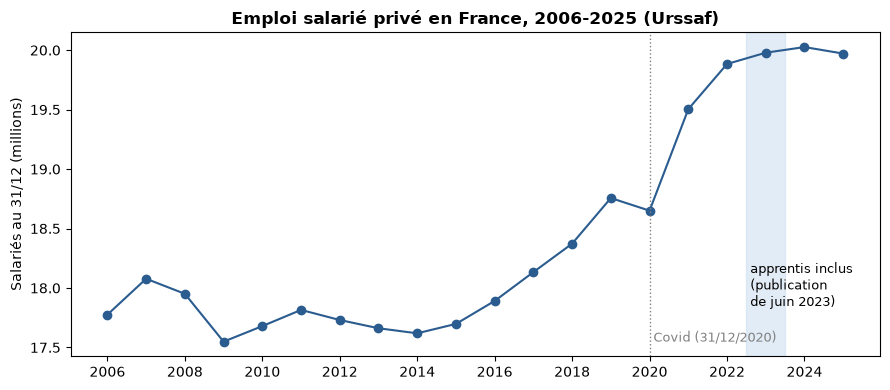

count     33696.0
mean        594.0
std        4346.0
min           0.0
10%           1.0
25%           4.0
50%          22.0
75%         138.0
90%         756.0
99%        9967.0
max      249806.0
Name: Effectifs salariés 2024, dtype: float64
1 % des communes regroupent 50.3% des salariés


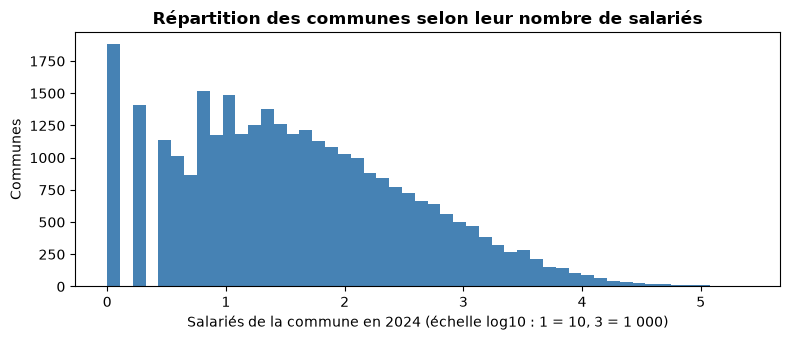

Grand secteur d'activité
GS1 Industrie                                 15.9
GS2 Construction                               8.0
GS3 Commerce                                  16.9
GS4 Hôtellerie-restauration                    6.5
GS5 Autres services marchands hors intérim    37.1
GS6 Intérim                                    2.6
GS7 Services non marchands                    13.1
nca _non classé ailleurs_                      0.0
Name: part des salariés 2024 (%), dtype: float64

,count,mean,std,min,5%,50%,95%,max
taille,,,,,,,,
1-10,9546.0,6.8,78.9,-100.0,-100.0,0.0,100.0,2633.3
11-50,8185.0,-0.3,21.3,-100.0,-30.8,0.0,30.8,300.0
51-200,5692.0,-0.2,12.2,-100.0,-15.4,0.0,15.1,291.4
201-1 000,4338.0,0.2,7.0,-61.0,-9.1,0.0,9.4,103.4
1 001-10 000,2436.0,0.3,4.6,-33.1,-5.7,0.1,6.9,52.9
> 10 000,335.0,0.1,2.4,-9.4,-4.0,0.2,3.9,9.7


In [10]:
# ── 1. Série nationale : rupture ? ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(national.index, national["salariés (millions)"], marker="o", color="#2b5c8f")
ax.axvline(2020, color="grey", ls=":", lw=1)
ax.text(2020.1, national["salariés (millions)"].min(), "Covid (31/12/2020)", color="grey", fontsize=9)
ax.axvspan(2022.5, 2023.5, color="#c6dbef", alpha=0.5)
ax.text(2022.6, national["salariés (millions)"].min() + 0.3, "apprentis inclus\n(publication\nde juin 2023)", fontsize=9)
ax.set_xticks(range(annees[0], annees[-1] + 1, 2))
ax.set_ylabel("Salariés au 31/12 (millions)")
ax.set_title("Emploi salarié privé en France, 2006-2025 (Urssaf)", fontweight="bold")
plt.tight_layout(); plt.show()

# ── 2. Concentration : salariés par commune en 2024 ──────────────────────────
par_commune = emploi.groupby("code_commune")["Effectifs salariés 2024"].sum()
print(par_commune.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(0))
top = par_commune.sort_values(ascending=False)
print(f"1 % des communes regroupent {top.head(len(top) // 100).sum() / top.sum():.1%} des salariés")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(par_commune[par_commune > 0]), bins=50, color="#4682b4")
ax.set_xlabel("Salariés de la commune en 2024 (échelle log10 : 1 = 10, 3 = 1 000)")
ax.set_ylabel("Communes")
ax.set_title("Répartition des communes selon leur nombre de salariés", fontweight="bold")
plt.tight_layout(); plt.show()

# Part de chaque grand secteur (l'intérim est compté à l'agence, pas au lieu de mission)
secteurs = emploi.groupby("Grand secteur d'activité")["Effectifs salariés 2024"].sum()
display((secteurs / secteurs.sum() * 100).round(1).rename("part des salariés 2024 (%)"))

# ── 3. Évolution 2023 -> 2024 selon la taille de la commune ──────────────────
a = emploi.groupby("code_commune")[["Effectifs salariés 2023", "Effectifs salariés 2024"]].sum()
a = a[a["Effectifs salariés 2023"] > 0]
a["évolution (%)"] = (a["Effectifs salariés 2024"] / a["Effectifs salariés 2023"] - 1) * 100
a["taille"] = pd.cut(a["Effectifs salariés 2023"], [0, 10, 50, 200, 1000, 10_000, np.inf],
                     labels=["1-10", "11-50", "51-200", "201-1 000", "1 001-10 000", "> 10 000"])
display(a.groupby("taille", observed=True)["évolution (%)"].describe(percentiles=[0.05, 0.5, 0.95]).round(1))

**Constat :**
- **Pas de rupture visible autour de 2023** : +0,5 % au 31/12/2023, +0,2 % en 2024, dans la continuité des années précédentes. Le fichier, publié en 2026, semble avoir été recalculé apprentis compris sur toute la période (à confirmer dans la méthodologie de l'Urssaf). Les deux mouvements marquants sont réels : le Covid (−0,6 % au 31/12/2020) et le rebond de 2021 (+4,6 %), porté aussi par l'essor de l'apprentissage.
- **Très forte concentration** : la commune médiane compte 22 salariés privés (1 sur 10 en compte au plus 1), mais 1 % des communes regroupent la moitié des salariés. Le niveau d'emploi est donc très asymétrique, d'où son passage en log pour la régression (règle de l'audit : asymétrie > 1) et sa division par le parc de logements.
- **Évolutions très bruitées dans les petites communes** : entre 2023 et 2024, 90 % des communes de 1 à 10 salariés varient entre −100 % et +100 % ; une ouverture ou une fermeture suffit. L'écart se resserre avec la taille : entre −6 % et +7 % de 1 001 à 10 000 salariés, entre −4 % et +4 % au-delà.
- L'intérim pèse 2,6 % des salariés, compté au lieu de l'agence.

**Impact projet :** l'évolution n'a de sens qu'agrégée ; le sous-bassin (au moins 20 ventes, donc une certaine taille) lisse ce bruit. Le Covid touche l'emploi au 31/12/2020, utilisé pour les prix 2021 : à lire avec prudence.

**Action envisagée :** agréger au sous-bassin avant de calculer l'évolution ; rapporter le niveau au parc de logements ; garder l'année 2020 comme limite déclarée.

**Incertitudes / limites :** la série ne permet pas de séparer l'effet des apprentis du reste de l'emploi.

## Synthèse du premier niveau d'audit — Emploi salarié privé (Urssaf)

#### Constat

Le fichier de l'Urssaf est une source administrative exhaustive de l'emploi salarié **privé** : 1 227 408 cellules commune × activité, 20 millésimes au 31/12 (2006 à 2025), 33 696 communes de métropole et des DOM hors Mayotte, et 20,0 millions de salariés au 31/12/2024. Aucun doublon, des chiffres entiers et positifs, aucune incohérence entre établissements et salariés.

Trois points demandent un traitement :
- **les cases vides sont des zéros** : environ 42 % des cases sont vides parce que l'activité n'existait pas dans la commune cette année-là. Le vrai secret statistique ne touche qu'au plus 149 cellules par an, chacune à un seul établissement ;
- **le code commune a perdu son zéro initial** pour une partie des lignes des départements 01 à 09 (6 % des lignes ; 574 communes écrites des deux façons) ;
- **l'évolution est très bruitée dans les petites communes** : elle n'a de sens qu'agrégée au sous-bassin.

La série nationale ne montre pas de rupture liée à l'inclusion des apprentis ; le Covid (31/12/2020) et le rebond de 2021 sont des mouvements réels.

#### Conséquences pour le projet

- L'emploi est la première variable de la table qui **change chaque année dans chaque territoire** : c'est l'objet de l'hypothèse H3c.
- Toutes les années utiles sont disponibles, pour le tour 1 comme pour la période longue du tour 2.
- Limites à déclarer : secteur privé seulement (ni public ni agriculture) ; emplois comptés au lieu de travail, pas de résidence ; intérim compté à l'agence ; une même valeur pour appartements et maisons ; calendrier de publication (31/12/N-1 connu en mai de N).

#### Décisions pour la suite

- Code commune remis sur 5 caractères ; case vide sans établissement = 0 salarié ; case vide avec établissement = secret, exclue de l'évolution.
- Agrégation au sous-bassin par la table de liaison, puis trois variables : `emploi_par_logement`, `evol_emploi_n2_n1` (à champ constant) et `part_emploi_secret` (contrôle qualité, à ajouter à `HORS_MASQUE` dans `commun.py`).
- Calendrier : effectif du 31/12/N-1 pour les prix de N (convention de l'équipe), variante prudente au 31/12/N-2 testée dans H3c.
- L'emploi entre dans la table par le feature engineering, comme les autres sources : section « Emploi salarié privé (Urssaf) » de `feature_engineering.py` et `feature_engineering.ipynb`, export `fe_cible_emploi_sbv.parquet`.